# **Laboratorio 9 - Series de Tiempo**

- Brian Martínez — 23542
- Adriana Palacios — 23044

---

## **Datos**

In [1]:
from pathlib import Path
import urllib.request
import zipfile

import pandas as pd

raw_data_directory = Path("data/raw")
raw_data_directory.mkdir(parents=True, exist_ok=True)
zip_file_path = raw_data_directory / "electricity.zip"
dataset_file_path = raw_data_directory / "LD2011_2014.txt"

dataset_url = (
    "https://archive.ics.uci.edu/static/public/321/"
    "electricityloaddiagrams20112014.zip"
)

if not dataset_file_path.exists():
    if not zip_file_path.exists():
        urllib.request.urlretrieve(dataset_url, zip_file_path)
    with zipfile.ZipFile(zip_file_path) as dataset_archive:
        dataset_archive.extract("LD2011_2014.txt", path=raw_data_directory)

electricity_data = pd.read_csv(
    dataset_file_path,
    sep=";",
    decimal=",",
    index_col=0,
    parse_dates=True,
)

electricity_data.shape

(140256, 370)

In [2]:
electricity_data.head()

,MT_001,MT_002,MT_003,MT_004,MT_005,MT_006,MT_007,MT_008,MT_009,MT_010,...,MT_361,MT_362,MT_363,MT_364,MT_365,MT_366,MT_367,MT_368,MT_369,MT_370
2011-01-01 00:15:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2011-01-01 00:30:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2011-01-01 00:45:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2011-01-01 01:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2011-01-01 01:15:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## **Exploración y preparación de la serie**

**¿Cuántos clientes quedan después del filtro del periodo 2012–2014? ¿Cuántas observaciones horarias tiene cada serie y cuántas tiene el panel completo?**

Bajo el marco temporal completo se tienen 140,256 datos, pero al limitarlo a 2012–2014 se trabajará con 105,216.

In [3]:
print(f"La cantidad de observaciones en el dataset completo es: {len(electricity_data)}")

electricity_data_2012_2014 = electricity_data.loc["2012":"2014"].copy()

print(f"De 2012 a 2014 se tienen {len(electricity_data_2012_2014)} observaciones")

La cantidad de observaciones en el dataset completo es: 140256
De 2012 a 2014 se tienen 105216 observaciones


**¿Cómo tratarán los dos días de cambio de horario de cada año?**

Para el cambio de horario de marzo, se reemplazarán los cuatro registros en cero de cada cliente por el promedio de sus tres mediciones reales anteriores, que corresponden a los últimos 45 minutos. Este promedio se calculará una sola vez por cliente y se utilizará para completar los cuatro registros, de tal forma que los valores imputados no se incluyan en el cálculo de los siguientes. Con esto se busca evitar que el modelo interprete esos ceros como una caída real del consumo, dejando documentado que los valores utilizados son estimaciones.

**Grafiquen el perfil promedio por hora del día y por día de la semana, y marquen los feriados de Portugal. ¿Cómo cambia el consumo en Navidad y Año Nuevo?**

- **Por hora del día:** Como es de esperarse, los puntos más bajos se encuentran durante la madrugada, lo que coincide con las horas en las que las personas suelen estar durmiendo. Luego, el consumo aumenta considerablemente conforme comienzan las actividades del día, se mantiene alto durante la tarde y vuelve a disminuir por la noche, cuando las personas suelen irse a dormir.

- **Por día de la semana:** Visualmente, la altura de las barras es prácticamente idéntica, por lo que el consumo promedio se mantiene bastante similar durante la semana. Únicamente el viernes y el sábado presentan valores ligeramente más altos.

- **Comportamiento en los feriados:** Los otros feriados presentan un consumo más alto que Navidad y Año Nuevo. Una posible explicación es que durante estas celebraciones las personas compartan más entre sí y utilicen menos pantallas u otros dispositivos, aunque los datos no permiten confirmar esta causa ni distinguir las actividades de los clientes.

- **Comparación de los promedios:** El último gráfico resume esta diferencia, ya que Navidad y Año Nuevo se encuentran considerablemente por debajo de los días normales y de los otros feriados en cuanto al consumo promedio.

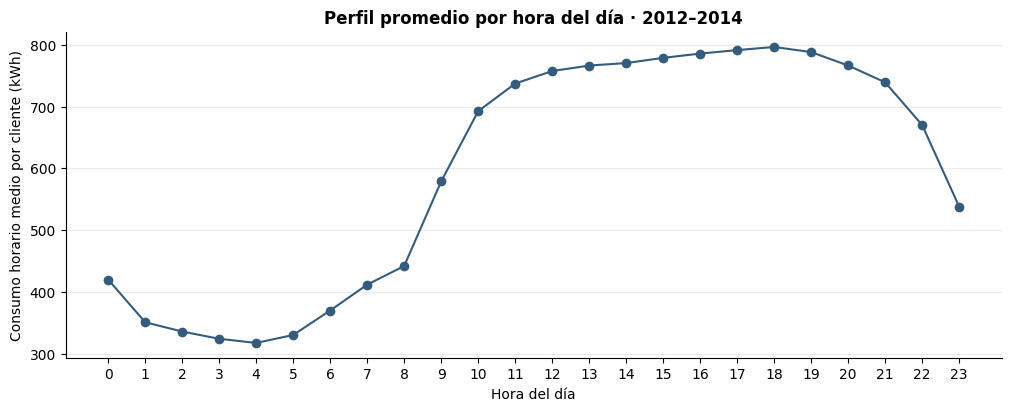

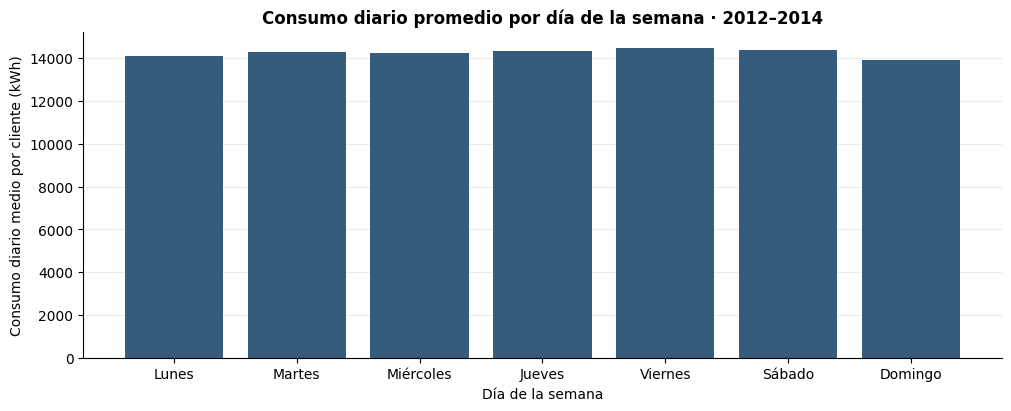

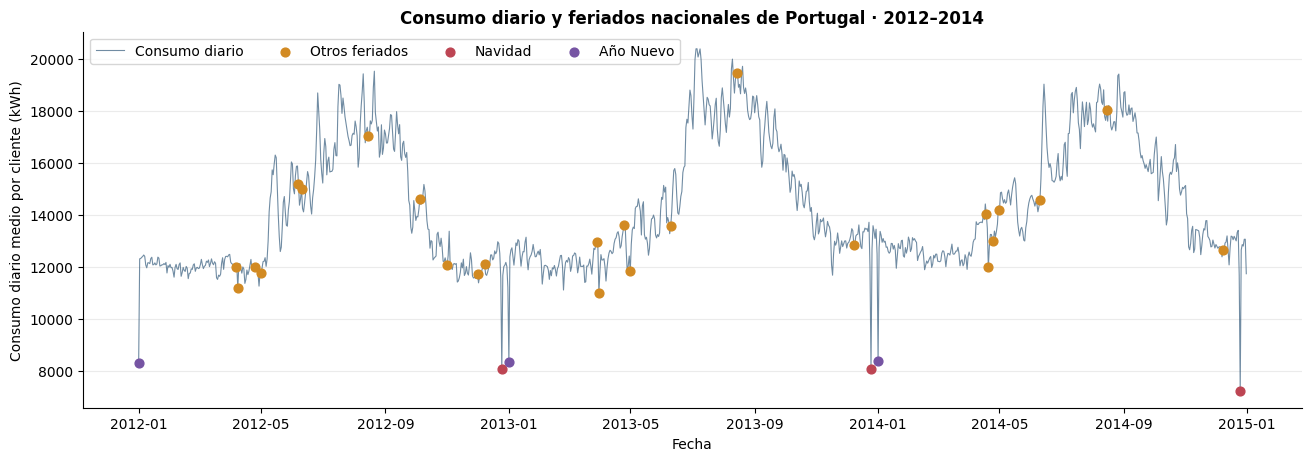

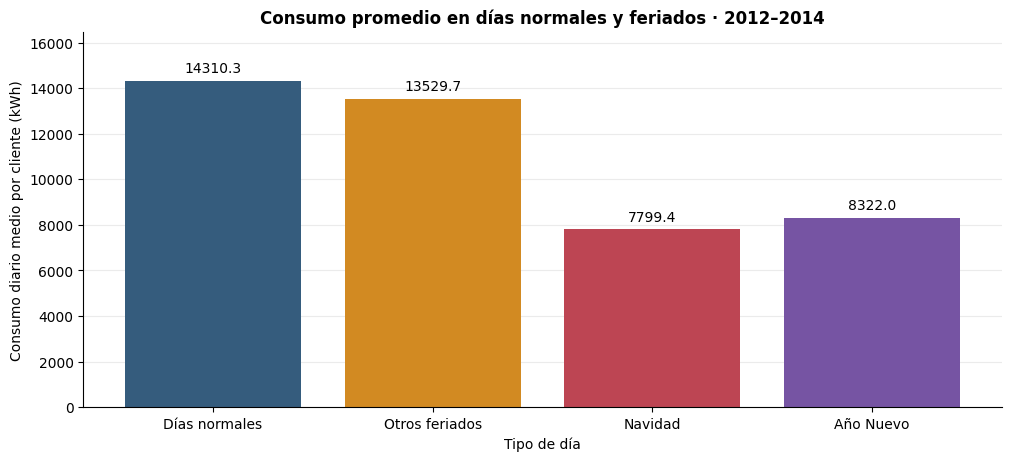

,Consumo diario medio por cliente (kWh),Cantidad de días,Diferencia respecto a días normales (%)
day_type,,,
Días normales,14310.28,1065,0.00
Otros feriados,13529.75,25,-5.45
Navidad,7799.37,3,-45.50
Año Nuevo,8321.96,3,-41.85


In [4]:
import holidays
import matplotlib.pyplot as plt
from IPython.display import display

portugal_holidays = holidays.country_holidays(
    "PT", years=[2012, 2013, 2014], categories=holidays.PUBLIC
)

average_power_by_timestamp = electricity_data_2012_2014.mean(axis=1)
average_hourly_consumption = (
    average_power_by_timestamp.resample("h").sum(min_count=4) * 0.25
)
average_consumption_by_hour = average_hourly_consumption.groupby(
    average_hourly_consumption.index.hour
).mean()

daily_consumption = average_hourly_consumption.resample("D").sum(
    min_count=24
).to_frame("average_consumption_kwh")
daily_consumption["is_holiday"] = [
    calendar_date in portugal_holidays
    for calendar_date in daily_consumption.index.date
]
daily_consumption["day_type"] = "Días normales"
daily_consumption.loc[daily_consumption["is_holiday"], "day_type"] = "Otros feriados"
daily_consumption.loc[
    (daily_consumption.index.month == 12) & (daily_consumption.index.day == 25),
    "day_type",
] = "Navidad"
daily_consumption.loc[
    (daily_consumption.index.month == 1) & (daily_consumption.index.day == 1),
    "day_type",
] = "Año Nuevo"

average_consumption_by_weekday = daily_consumption.groupby(
    daily_consumption.index.dayofweek
)["average_consumption_kwh"].mean().reindex(range(7))
weekday_names = ["Lunes", "Martes", "Miércoles", "Jueves", "Viernes", "Sábado", "Domingo"]
day_types = ["Días normales", "Otros feriados", "Navidad", "Año Nuevo"]
day_type_colors = ["#355C7D", "#D28A22", "#BD4553", "#7654A3"]

holiday_comparison = daily_consumption.groupby("day_type").agg(
    average_daily_consumption_kwh=("average_consumption_kwh", "mean"),
    number_of_days=("average_consumption_kwh", "count"),
).reindex(day_types)
holiday_comparison["difference_vs_normal_pct"] = (
    holiday_comparison["average_daily_consumption_kwh"]
    / holiday_comparison.loc["Días normales", "average_daily_consumption_kwh"]
    - 1
) * 100

with plt.rc_context({"axes.titleweight": "bold", "axes.spines.top": False, "axes.spines.right": False}):
    hourly_figure, hourly_axis = plt.subplots(figsize=(10, 4), layout="constrained")
    hourly_axis.plot(
        average_consumption_by_hour.index,
        average_consumption_by_hour.values,
        marker="o",
        color=day_type_colors[0],
    )
    hourly_axis.set(
        title="Perfil promedio por hora del día · 2012–2014",
        xlabel="Hora del día",
        ylabel="Consumo horario medio por cliente (kWh)",
        xticks=range(24),
    )
    hourly_axis.grid(axis="y", alpha=0.25)
    plt.show()

    weekday_figure, weekday_axis = plt.subplots(figsize=(10, 4), layout="constrained")
    weekday_axis.bar(
        weekday_names, average_consumption_by_weekday.values, color=day_type_colors[0]
    )
    weekday_axis.set(
        title="Consumo diario promedio por día de la semana · 2012–2014",
        xlabel="Día de la semana",
        ylabel="Consumo diario medio por cliente (kWh)",
    )
    weekday_axis.grid(axis="y", alpha=0.25)
    weekday_axis.set_axisbelow(True)
    plt.show()

    calendar_figure, calendar_axis = plt.subplots(figsize=(13, 4.5), layout="constrained")
    calendar_axis.plot(
        daily_consumption.index,
        daily_consumption["average_consumption_kwh"],
        color=day_type_colors[0],
        linewidth=0.8,
        alpha=0.7,
        label="Consumo diario",
    )
    for holiday_type, holiday_color in zip(day_types[1:], day_type_colors[1:]):
        selected_days = daily_consumption.loc[daily_consumption["day_type"] == holiday_type]
        calendar_axis.scatter(
            selected_days.index,
            selected_days["average_consumption_kwh"],
            color=holiday_color,
            label=holiday_type,
            s=40,
            zorder=3,
        )
    calendar_axis.set(
        title="Consumo diario y feriados nacionales de Portugal · 2012–2014",
        xlabel="Fecha",
        ylabel="Consumo diario medio por cliente (kWh)",
    )
    calendar_axis.legend(loc="upper left", ncols=4)
    calendar_axis.grid(axis="y", alpha=0.25)
    plt.show()

    comparison_figure, comparison_axis = plt.subplots(figsize=(10, 4.5), layout="constrained")
    comparison_bars = comparison_axis.bar(
        day_types,
        holiday_comparison["average_daily_consumption_kwh"],
        color=day_type_colors,
    )
    comparison_axis.bar_label(comparison_bars, fmt="%.1f", padding=4)
    comparison_axis.set(
        title="Consumo promedio en días normales y feriados · 2012–2014",
        xlabel="Tipo de día",
        ylabel="Consumo diario medio por cliente (kWh)",
    )
    comparison_axis.set_ylim(
        0, holiday_comparison["average_daily_consumption_kwh"].max() * 1.15
    )
    comparison_axis.grid(axis="y", alpha=0.25)
    comparison_axis.set_axisbelow(True)
    plt.show()

display(
    holiday_comparison.rename(
        columns={
            "average_daily_consumption_kwh": "Consumo diario medio por cliente (kWh)",
            "number_of_days": "Cantidad de días",
            "difference_vs_normal_pct": "Diferencia respecto a días normales (%)",
        }
    ).round(2)
)


**¿Qué tan distintas son las escalas entre clientes (mínimo, mediana y máximo del consumo promedio)? Propongan y justifiquen una normalización: global, por serie (z-score con estadísticos de entrenamiento) o por ventana.**

Las escalas de consumo entre los clientes son bastante distintas, ya que el consumo horario promedio mínimo es de 1.090 kWh, la mediana es de 122.225 kWh y el máximo es de 50,132.281 kWh. Esto muestra que algunos clientes consumen considerablemente más que otros.

Por esto, se utilizará una normalización Min–Max por cliente, para llevar sus datos de entrenamiento al rango de 0 a 1 y evitar que los clientes de mayor consumo dominen el aprendizaje únicamente por su escala. El mínimo y el máximo se calcularán a partir de las observaciones de cada cliente dentro de la partición de entrenamiento, y se utilizarán esos mismos parámetros para transformar validación y prueba, sin recalcularlos con datos futuros. Finalmente, las predicciones se devolverán a su escala original para evaluar los errores en kWh.

,Consumo horario promedio por cliente (kWh)
Mínimo,1.090
Mediana,122.225
Máximo,50132.281


Clientes analizados: 370
Cliente con menor promedio: MT_133
Cliente con mayor promedio: MT_362
Clientes con promedio cero: 0


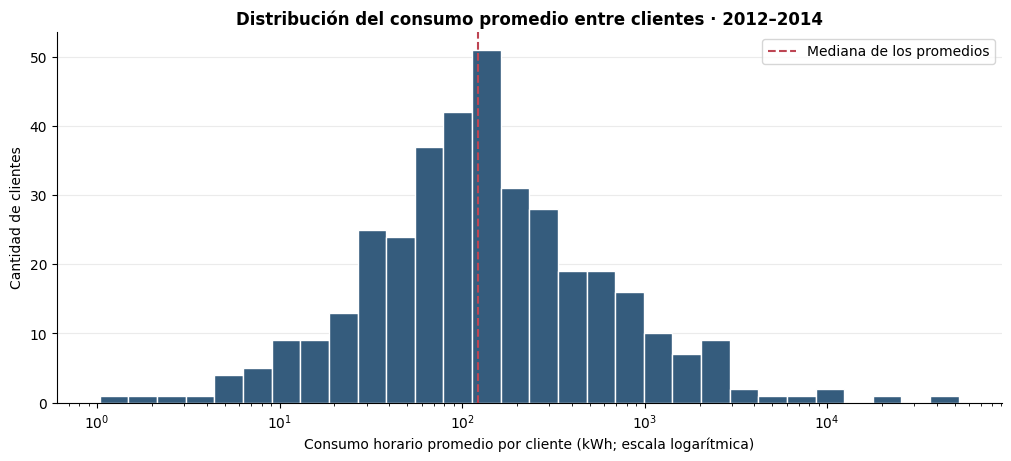

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

average_hourly_consumption_by_client = (
    electricity_data_2012_2014.resample("h").sum(min_count=4) * 0.25
).mean()

client_consumption_statistics = average_hourly_consumption_by_client.agg(
    ["min", "median", "max"]
).rename(
    index={"min": "Mínimo", "median": "Mediana", "max": "Máximo"}
).to_frame("Consumo horario promedio por cliente (kWh)")

display(client_consumption_statistics.round(3))
print(f"Clientes analizados: {len(average_hourly_consumption_by_client)}")
print(f"Cliente con menor promedio: {average_hourly_consumption_by_client.idxmin()}")
print(f"Cliente con mayor promedio: {average_hourly_consumption_by_client.idxmax()}")
print(f"Clientes con promedio cero: {average_hourly_consumption_by_client.eq(0).sum()}")

positive_client_averages = average_hourly_consumption_by_client.loc[
    average_hourly_consumption_by_client > 0
]
consumption_bins = np.geomspace(
    positive_client_averages.min() * 0.95,
    positive_client_averages.max() * 1.05,
    31,
)

client_distribution_figure, client_distribution_axis = plt.subplots(
    figsize=(10, 4.5), layout="constrained"
)
client_distribution_axis.hist(
    positive_client_averages,
    bins=consumption_bins,
    color="#355C7D",
    edgecolor="white",
)
client_distribution_axis.axvline(
    average_hourly_consumption_by_client.median(),
    color="#BD4553",
    linestyle="--",
    label="Mediana de los promedios",
)
client_distribution_axis.set_xscale("log")
client_distribution_axis.set_title(
    "Distribución del consumo promedio entre clientes · 2012–2014",
    fontweight="bold",
)
client_distribution_axis.set(
    xlabel="Consumo horario promedio por cliente (kWh; escala logarítmica)",
    ylabel="Cantidad de clientes",
)
client_distribution_axis.spines[["top", "right"]].set_visible(False)
client_distribution_axis.grid(axis="y", alpha=0.25)
client_distribution_axis.set_axisbelow(True)
client_distribution_axis.legend()
plt.show()


**Construyan las covariables de calendario conocidas a futuro (hora, día de la semana, mes, feriado) y expliquen cómo las codifican (one-hot, embeddings o seno/coseno).**

Se utilizará una codificación con seno y coseno para representar las variables cíclicas, de tal forma que el final de cada ciclo quede cerca de su inicio, como ocurre con las posiciones de un reloj.

- **Hora del día:** Se generarán dos variables con un periodo de 24 horas, para conservar la cercanía entre las 23:00 y las 00:00.
- **Día de la semana:** Se generarán dos variables con un periodo de siete días, para conservar la continuidad entre domingo y lunes.
- **Mes:** Se generarán dos variables con un periodo de doce meses, para conservar la continuidad entre diciembre y enero.
- **Feriado:** Se utilizará un indicador binario, con 1 si la fecha corresponde a un feriado nacional de Portugal y 0 en caso contrario, tomando en cuenta el calendario vigente en cada año.

Estas siete variables se pueden calcular tanto para las fechas históricas como para las horas que se desean pronosticar, ya que dependen del calendario y no del consumo futuro de los clientes.

In [1]:
import holidays
import numpy as np
import pandas as pd


def build_calendar_covariates(calendar_timestamps: pd.DatetimeIndex) -> pd.DataFrame:
    calendar_covariates = pd.DataFrame(index=calendar_timestamps)
    calendar_cycles = {
        "hour": (calendar_timestamps.hour, 24),
        "weekday": (calendar_timestamps.dayofweek, 7),
        "month": (calendar_timestamps.month - 1, 12),
    }

    for variable_name, (calendar_values, cycle_length) in calendar_cycles.items():
        calendar_angles = 2 * np.pi * calendar_values / cycle_length
        calendar_covariates[f"{variable_name}_sin"] = np.sin(calendar_angles)
        calendar_covariates[f"{variable_name}_cos"] = np.cos(calendar_angles)

    portugal_holidays = holidays.country_holidays(
        "PT",
        years=calendar_timestamps.year.unique().tolist(),
        categories=holidays.PUBLIC,
    )
    calendar_covariates["is_holiday"] = [
        int(calendar_date in portugal_holidays)
        for calendar_date in calendar_timestamps.date
    ]

    return calendar_covariates.rename_axis("timestamp")


calendar_timestamps = pd.date_range(
    start="2012-01-01 00:00",
    end="2014-12-31 23:00",
    freq="h",
)
calendar_covariates = build_calendar_covariates(calendar_timestamps)

print(
    f"Covariables de calendario: {len(calendar_covariates)} filas "
    f"y {len(calendar_covariates.columns)} columnas"
)
calendar_covariates.head()


Covariables de calendario: 26304 filas y 7 columnas


,hour_sin,hour_cos,weekday_sin,weekday_cos,month_sin,month_cos,is_holiday
timestamp,,,,,,,
2012-01-01 00:00:00,0.000000,1.000000,-0.781831,0.62349,0.0,1.0,1
2012-01-01 01:00:00,0.258819,0.965926,-0.781831,0.62349,0.0,1.0,1
2012-01-01 02:00:00,0.500000,0.866025,-0.781831,0.62349,0.0,1.0,1
2012-01-01 03:00:00,0.707107,0.707107,-0.781831,0.62349,0.0,1.0,1
2012-01-01 04:00:00,0.866025,0.500000,-0.781831,0.62349,0.0,1.0,1


### **Auditoría de fugas**

Se busca garantizar que cada entrada del modelo pueda calcularse con la información disponible en el momento de emitir el pronóstico. Para esto, se tomarán en cuenta las siguientes fugas:

- **Split aleatorio de ventanas:** Se dividirán los datos de forma cronológica y se verificará que todos los objetivos de cada ventana pertenezcan a su partición, para evitar que los consumos utilizados como respuestas en prueba también se hayan utilizado como respuestas de entrenamiento. Las ventanas podrán compartir historia como entrada cuando esa información ya esté disponible al emitir el pronóstico.

- **Escalar con toda la serie:** El mínimo y el máximo de cada cliente se calcularán únicamente con sus datos de entrenamiento. Estos mismos parámetros se utilizarán para transformar validación y prueba, sin recalcularlos con información futura.

- **Early stopping con la prueba:** Se utilizará únicamente el desempeño en validación para decidir cuándo detener el entrenamiento y qué versión del modelo conservar. La partición de prueba se reservará para la evaluación final.

- **Covariables mal alineadas:** Se verificará que las covariables correspondan a las fechas de cada paso de la ventana y que no incluyan mediciones de consumo posteriores al momento del pronóstico. Las variables de calendario futuras sí se pueden utilizar porque se conocen de antemano, a diferencia de los consumos reales futuros.

Estas reglas se comprobarán con código durante la construcción del pipeline y, en el caso del early stopping, durante el entrenamiento.

### **Preprocesamiento**

Se prepararán las series horarias siguiendo las decisiones discutidas:

1. **Periodo y cobertura:** Se conservarán los registros de 2012–2014 y se verificará que las fechas estén ordenadas, no se repitan y mantengan una frecuencia de 15 minutos. Como el archivo no incluye la fecha de alta de cada cliente, se utilizará como aproximación de cobertura la existencia de consumo positivo antes o durante el primer día de 2012, junto con registros completos y finitos durante el periodo. Este criterio admite a los clientes cuya primera medición positiva aparece el 1 de enero a las 00:15, sin descartarlos únicamente por el cero de las 00:00. Los clientes que no cumplan ambos criterios se descartarán; tener ceros en otros momentos no será motivo para eliminarlos. Entre los clientes elegibles se seleccionará un subconjunto aleatorio de 100, sin reemplazo y con semilla 123, para reducir el costo computacional. Se conservará el orden original de sus columnas y se utilizarán exactamente los mismos clientes en entrenamiento, validación, prueba y todos los modelos.

2. **Cambio de horario de marzo:** Para cada cliente, se reemplazarán únicamente los ceros del bloque de 01:00 a 01:45 por el promedio de sus tres mediciones anteriores, equivalentes a 45 minutos. El promedio se calculará antes del bloque y se mantendrá fijo para las imputaciones. Se conservarán los valores distintos de cero y se registrará cuáles posiciones se imputaron.

3. **Cambio de horario de octubre:** Se mantendrán los valores originales, teniendo en cuenta que el bloque afectado reúne el consumo de dos horas reales.

4. **Agregación horaria:** Se agruparán los registros por hora del reloj: por ejemplo, 00:00, 00:15, 00:30 y 00:45 formarán la hora etiquetada como 00:00. Se sumarán las cuatro mediciones en kW y se multiplicará por 0.25 horas para obtener la energía en kWh.

5. **Particiones cronológicas:** Entrenamiento comprenderá del 1 de enero de 2012 al 30 de junio de 2014; validación, del 1 de julio al 30 de septiembre de 2014; y prueba, del 1 de octubre al 31 de diciembre de 2014. Se utilizará el mismo panel de clientes en las tres particiones.

6. **Normalización por cliente:** Se calculará Min–Max únicamente con entrenamiento y se utilizarán esos mismos parámetros para transformar las tres particiones, que quedarán en `electricity_train`, `electricity_val` y `electricity_test`. Se conservarán sus versiones en kWh con el sufijo `_original` y el escalador para poder devolver las predicciones a su escala original. Validación y prueba podrían quedar fuera de 0–1 si superan el rango observado en entrenamiento; esos valores no se recortarán.

7. **Covariables de calendario:** Se construirán las variables acordadas para las fechas exactas de cada partición, en `calendar_train`, `calendar_val` y `calendar_test`. Se comprobará que sus índices coincidan con los consumos correspondientes.

La construcción del Dataset de ventanas y sus conteos se realizará después de esta preparación.

In [3]:
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.preprocessing import MinMaxScaler

period_start = pd.Timestamp("2012-01-01 00:00")
period_end = pd.Timestamp("2014-12-31 23:45")
expected_quarter_hour_index = pd.date_range(period_start, period_end, freq="15min")

assert electricity_data.index.is_unique, "Existen fechas duplicadas en los datos originales."
assert electricity_data.index.is_monotonic_increasing, "Las fechas originales no están ordenadas."

period_electricity_data = electricity_data.loc[period_start:period_end]
assert period_electricity_data.index.equals(expected_quarter_hour_index), (
    "El periodo no contiene todos los registros esperados cada 15 minutos."
)

coverage_evidence_end = period_start + pd.Timedelta(days=1) - pd.Timedelta(minutes=15)
clients_active_at_start = electricity_data.loc[:coverage_evidence_end].gt(0).any(axis=0)
clients_with_complete_records = (
    period_electricity_data.notna().all(axis=0)
    & np.isfinite(period_electricity_data).all(axis=0)
)
client_coverage = pd.DataFrame({
    "active_at_period_start": clients_active_at_start,
    "complete_period_records": clients_with_complete_records,
})
client_coverage["included"] = (
    client_coverage["active_at_period_start"]
    & client_coverage["complete_period_records"]
)
eligible_clients = client_coverage.index[client_coverage["included"]]
client_sample_size = 100
client_selection_seed = 123
assert len(eligible_clients) >= client_sample_size, "No hay suficientes clientes elegibles."

client_random_generator = np.random.default_rng(client_selection_seed)
sampled_clients = client_random_generator.choice(
    eligible_clients.to_numpy(), size=client_sample_size, replace=False
)
selected_clients = eligible_clients[eligible_clients.isin(sampled_clients)]
client_coverage["selected"] = client_coverage.index.isin(selected_clients)
assert len(selected_clients) == client_sample_size and selected_clients.is_unique

electricity_quarter_hourly = period_electricity_data.loc[:, selected_clients].copy()
march_imputation_masks = {}
march_imputation_records = []

for calendar_year in range(period_start.year, period_end.year + 1):
    # El adelanto del reloj ocurre el último domingo de marzo.
    last_march_day = pd.Timestamp(year=calendar_year, month=3, day=31)
    march_transition_day = last_march_day - pd.Timedelta(
        days=(last_march_day.dayofweek + 1) % 7
    )
    transition_start = march_transition_day + pd.Timedelta(hours=1)
    transition_timestamps = pd.date_range(transition_start, periods=4, freq="15min")
    preceding_measurements = electricity_quarter_hourly.loc[
        electricity_quarter_hourly.index < transition_start
    ].tail(3)
    assert len(preceding_measurements) == 3

    preceding_client_averages = preceding_measurements.mean(axis=0)
    transition_measurements = electricity_quarter_hourly.loc[transition_timestamps]
    transition_zero_mask = transition_measurements.eq(0)
    march_imputation_masks[calendar_year] = transition_zero_mask.copy()
    electricity_quarter_hourly.loc[transition_timestamps] = transition_measurements.mask(
        transition_zero_mask, preceding_client_averages, axis="columns"
    )
    march_imputation_records.append({
        "Fecha": march_transition_day.date(),
        "Registros imputados": int(transition_zero_mask.to_numpy().sum()),
    })

march_imputation_report = pd.DataFrame(march_imputation_records)

electricity_hourly = (
    electricity_quarter_hourly.resample("h", closed="left", label="left")
    .sum(min_count=4)
    .mul(0.25)
    .rename_axis("timestamp")
)
expected_hourly_index = pd.date_range(
    "2012-01-01 00:00", "2014-12-31 23:00", freq="h"
)
assert electricity_hourly.index.equals(expected_hourly_index)
assert np.isfinite(electricity_hourly.to_numpy()).all()

electricity_train_original = electricity_hourly.loc["2012-01-01":"2014-06-30"].copy()
electricity_val_original = electricity_hourly.loc["2014-07-01":"2014-09-30"].copy()
electricity_test_original = electricity_hourly.loc["2014-10-01":"2014-12-31"].copy()

assert electricity_train_original.index.max() < electricity_val_original.index.min()
assert electricity_val_original.index.max() < electricity_test_original.index.min()
assert (
    len(electricity_train_original)
    + len(electricity_val_original)
    + len(electricity_test_original)
    == len(electricity_hourly)
)
assert electricity_train_original.columns.equals(electricity_val_original.columns)
assert electricity_train_original.columns.equals(electricity_test_original.columns)

electricity_scaler = MinMaxScaler(clip=False)
electricity_scaler.fit(electricity_train_original)


def scale_electricity_partition(electricity_partition, fitted_scaler):
    return pd.DataFrame(
        fitted_scaler.transform(electricity_partition),
        index=electricity_partition.index,
        columns=electricity_partition.columns,
    )


electricity_train = scale_electricity_partition(electricity_train_original, electricity_scaler)
electricity_val = scale_electricity_partition(electricity_val_original, electricity_scaler)
electricity_test = scale_electricity_partition(electricity_test_original, electricity_scaler)

np.testing.assert_allclose(
    electricity_scaler.data_min_, electricity_train_original.min(axis=0).to_numpy()
)
np.testing.assert_allclose(
    electricity_scaler.data_max_, electricity_train_original.max(axis=0).to_numpy()
)
assert electricity_scaler.n_samples_seen_ == len(electricity_train_original)
assert electricity_train.to_numpy().min() >= -1e-9
assert electricity_train.to_numpy().max() <= 1 + 1e-9

calendar_train = build_calendar_covariates(electricity_train.index)
calendar_val = build_calendar_covariates(electricity_val.index)
calendar_test = build_calendar_covariates(electricity_test.index)

assert calendar_train.index.equals(electricity_train.index)
assert calendar_val.index.equals(electricity_val.index)
assert calendar_test.index.equals(electricity_test.index)

partition_summary = pd.DataFrame([
    {
        "Partición": partition_name,
        "Inicio": electricity_partition.index.min(),
        "Fin": electricity_partition.index.max(),
        "Horas por cliente": len(electricity_partition),
        "Clientes": len(electricity_partition.columns),
        "Observaciones del panel": electricity_partition.size,
    }
    for partition_name, electricity_partition in (
        ("electricity_train", electricity_train),
        ("electricity_val", electricity_val),
        ("electricity_test", electricity_test),
    )
]).set_index("Partición")

print(f"Clientes originales: {len(electricity_data.columns)}")
print(f"Clientes elegibles tras el filtro de cobertura: {len(eligible_clients)}")
print(f"Clientes seleccionados: {len(selected_clients)} (semilla {client_selection_seed})")
print(f"Clientes descartados por cobertura: {len(electricity_data.columns) - len(eligible_clients)}")
print(f"Clientes elegibles fuera del subconjunto: {len(eligible_clients) - len(selected_clients)}")
print(f"Observaciones horarias por cliente en 2012–2014: {len(electricity_hourly)}")
print(f"Observaciones horarias del panel completo: {electricity_hourly.size}")
display(partition_summary)
display(march_imputation_report)


Clientes originales: 370
Clientes elegibles tras el filtro de cobertura: 320
Clientes seleccionados: 100 (semilla 123)
Clientes descartados por cobertura: 50
Clientes elegibles fuera del subconjunto: 220
Observaciones horarias por cliente en 2012–2014: 26304
Observaciones horarias del panel completo: 2630400


,Inicio,Fin,Horas por cliente,Clientes,Observaciones del panel
Partición,,,,,
electricity_train,2012-01-01,2014-06-30 23:00:00,21888,100,2188800
electricity_val,2014-07-01,2014-09-30 23:00:00,2208,100,220800
electricity_test,2014-10-01,2014-12-31 23:00:00,2208,100,220800


,Fecha,Registros imputados
0,2012-03-25,272
1,2013-03-31,272
2,2014-03-30,280


### **Ventanas deslizantes**

Se utilizará un Dataset de PyTorch que genere las ventanas por lotes, sin almacenar todas sus combinaciones en memoria.

- **Entrada:** Cada ventana contiene 168 horas del consumo de un cliente y sus siete covariables de calendario.
- **Objetivo:** Se utilizan los 24 consumos inmediatamente posteriores a la ventana.
- **Particiones:** Todos los objetivos de cada ventana pertenecen a su partición. Validación y prueba pueden utilizar historia anterior ya disponible, pero sus objetivos no se utilizan para entrenar.
- **Conteo:** Se reportan las ventanas de los 100 clientes con un desplazamiento de una hora. El backtest sigue utilizando sus 92 orígenes diarios.

In [4]:
import numpy as np
import pandas as pd
import torch
from torch.utils.data import DataLoader, Dataset


class PanelWindowDataset(Dataset):
    def __init__(self, consumption, calendar, target_start, target_end,
                 window_length=168, horizon_length=24, stride=1):
        assert consumption.index.equals(calendar.index)
        assert consumption.index.is_unique and consumption.index.is_monotonic_increasing
        assert consumption.index.equals(pd.date_range(
            consumption.index.min(), consumption.index.max(), freq="h"
        ))
        assert window_length > 0 and horizon_length > 0 and stride > 0
        self.timestamps = consumption.index
        self.client_columns = consumption.columns.copy()
        self.client_count = len(self.client_columns)
        self.window_length = window_length
        self.horizon_length = horizon_length
        first_target = max(window_length, int(self.timestamps.searchsorted(target_start)))
        final_target = int(self.timestamps.searchsorted(target_end, side="right")) - horizon_length
        if final_target < first_target:
            raise ValueError("No hay suficientes observaciones para construir las ventanas.")
        self.target_positions = torch.arange(first_target, final_target + 1, stride)
        self.history_offsets = torch.arange(-window_length, 0)
        self.target_offsets = torch.arange(horizon_length)
        self.consumption_values = torch.from_numpy(consumption.to_numpy(dtype=np.float32))
        self.calendar_values = torch.from_numpy(calendar.to_numpy(dtype=np.float32))

    def __len__(self):
        return len(self.target_positions) * self.client_count

    def __getitem__(self, example_index):
        inputs, targets = self.__getitems__([example_index])
        return inputs[0], targets[0]

    def __getitems__(self, example_indices):
        batch_indices = torch.as_tensor(example_indices, dtype=torch.long)
        client_positions = batch_indices.remainder(self.client_count)
        target_positions = self.target_positions[batch_indices // self.client_count]
        history_positions = target_positions[:, None] + self.history_offsets
        future_positions = target_positions[:, None] + self.target_offsets
        consumption_windows = self.consumption_values[
            history_positions, client_positions[:, None]
        ].unsqueeze(-1)
        calendar_windows = self.calendar_values[history_positions]
        inputs = torch.cat([consumption_windows, calendar_windows], dim=-1)
        targets = self.consumption_values[future_positions, client_positions[:, None]]
        return inputs, targets


def keep_window_batch(window_batch):
    return window_batch


panel_consumption = pd.concat([electricity_train, electricity_val, electricity_test])
panel_calendar = pd.concat([calendar_train, calendar_val, calendar_test])
electricity_window_datasets = {
    partition_name: PanelWindowDataset(
        panel_consumption, panel_calendar,
        target_start=partition.index.min(), target_end=partition.index.max(),
        window_length=168, horizon_length=24, stride=1,
    )
    for partition_name, partition in (
        ("Entrenamiento", electricity_train),
        ("Validación", electricity_val),
        ("Prueba", electricity_test),
    )
}
window_counts = pd.Series({
    partition_name: len(window_dataset)
    for partition_name, window_dataset in electricity_window_datasets.items()
}, name="Ventanas con stride de 1 hora")
display(window_counts.to_frame())
print("Cada ventana contiene 168 horas con 8 variables y tiene un objetivo de 24 consumos.")


,Ventanas con stride de 1 hora
Entrenamiento,2169700
Validación,218500
Prueba,218500


Cada ventana contiene 168 horas con 8 variables y tiene un objetivo de 24 consumos.


## **Investigación: herramientas para forecasting en PyTorch**

Para esta investigación y la comprensión de los conceptos, se utilizó GPT 6.1 Sol como apoyo para realizar búsquedas, discutir las ideas y revisar las explicaciones presentadas.

**nn.LSTM y nn.GRU: propósito, parámetros y forma de sus salidas.**

LSTM (Long Short-Term Memory) y GRU (Gated Recurrent Unit) son redes recurrentes que recorren una secuencia y actualizan una representación interna con la información que van leyendo. Básicamente, mantienen un resumen numérico de lo que han visto para poder utilizarlo en los siguientes pasos. LSTM mantiene un estado de celda, que funciona como memoria, y un estado oculto, que representa la información que se expone en cada paso. GRU mantiene un solo estado oculto y utiliza sus compuertas para controlar cómo combina la información anterior con la nueva.

Los parámetros principales son:

- **`input_size`:** Cantidad de variables que recibe por hora. En nuestro caso serían 8 si utilizamos el consumo de un cliente y las siete covariables de calendario.
- **`hidden_size`:** Tamaño de la representación interna. Por ejemplo, un valor de 64 significa que el resumen utiliza 64 números, no que el modelo vea 64 horas hacia atrás.
- **`num_layers`:** Cantidad de capas recurrentes apiladas. Las capas siguientes trabajan con las representaciones producidas por la anterior.
- **`batch_first`:** Define cómo se organizan la entrada y la salida principal. Con `True` se utiliza el orden `(batch, L, features)` y con `False`, `(L, batch, features)`. Esto no cambia el orden de los estados finales.
- **`dropout`:** Durante el entrenamiento pone en cero parte de las activaciones entre capas para reducir el sobreajuste. En estas clases no se aplica después de la última capa, por lo que este parámetro no tiene efecto cuando se utiliza una sola capa.

Con el batch primero, una dirección y sin proyecciones, las salidas se interpretan así:

- **`output`:** Contiene el estado oculto de la última capa para cada hora de entrada, con forma `(batch, L, hidden_size)`.
- **`h_n`:** Contiene el estado oculto final de cada capa, con forma `(num_layers, batch, hidden_size)`.
- **`c_n`:** Contiene el estado de celda final de cada capa, con la misma forma anterior, y únicamente existe en LSTM.

Por ejemplo, con 4 ventanas de 168 horas, una capa y una representación de 64 números, la salida principal tendría forma `(4, 168, 64)` y los estados finales `(1, 4, 64)`. Estas salidas todavía son representaciones internas, por lo que se agrega una salida de pronóstico para obtener los 24 consumos futuros.

**nn.Conv1d: dilatación, padding causal y campo receptivo de una TCN.**

`nn.Conv1d` aplica kernels que recorren la serie para aprender patrones temporales. La entrada se organiza como `(batch, channels, L)`, por lo que se reorganizan las dimensiones cuando los datos vienen con las variables al final.

- **`in_channels`:** Cantidad de canales o variables de entrada.
- **`out_channels`:** Cantidad de canales que produce la convolución, permitiendo aprender distintas representaciones de la serie.
- **`kernel_size`:** Cantidad de posiciones que combina el kernel en cada desplazamiento.
- **`dilation`:** Separación entre las posiciones que utiliza el kernel. Por ejemplo, un kernel de tamaño 3 con dilatación 2 toma tres posiciones que, en conjunto, abarcan cinco posiciones de la serie.
- **Padding causal:** Agrega ceros únicamente al inicio para poder aplicar el kernel desde el primer dato y conservar la longitud con un desplazamiento de un paso. Por ejemplo, con tamaño 3 y dilatación 1 se agregan dos ceros, de tal forma que el primer dato real quede en la última posición del kernel. Los datos originales se conservan y cada salida utiliza únicamente su presente y su pasado.
- **Campo receptivo:** Es el alcance temporal máximo que puede influir en una salida. Depende del tamaño de los kernels, las dilataciones y la cantidad de capas. Para calcularlo con un desplazamiento de un paso por capa, se parte de una posición y se suma cuánto amplía el alcance cada convolución, según su tamaño y dilatación. Por ejemplo, tres convoluciones de tamaño 3 con dilataciones 1, 2 y 4 producen un alcance de 15 posiciones. Si un bloque tiene dos convoluciones, ambas se cuentan. Durante el entrenamiento se aprende qué patrones utilizar dentro de ese alcance.

**nn.TransformerEncoderLayer: parámetros principales y codificación posicional.**

`nn.TransformerEncoderLayer` construye representaciones internas de la secuencia utilizando atención y una red densa. La atención permite que cada hora combine información de otras horas, buscando relaciones que puedan ser útiles para el pronóstico. Los criterios para comparar se aprenden durante el entrenamiento y los pesos de atención se calculan para la ventana que se está procesando.

- **`d_model`:** Tamaño de la representación de cada hora. Por ejemplo, una capa lineal puede transformar nuestras 8 variables en 64 números antes de entrar al encoder.
- **`nhead`:** Cantidad de cabezas de atención. Básicamente, son distintas perspectivas aprendidas sobre las relaciones entre las mismas horas. Cada cabeza puede comparar todas las posiciones disponibles; no corresponde a una cantidad de parejas. El tamaño de la representación debe poder dividirse entre las cabezas, por lo que una representación de 64 números con cuatro cabezas utiliza 16 dimensiones por cabeza.
- **`dim_feedforward`:** Tamaño de la capa oculta de la red densa interna. Por ejemplo, se pueden procesar los 64 números mediante una representación intermedia de 256 y regresar a 64 por hora.
- **Codificación posicional:** Incorpora información sobre el orden de los datos. Se puede construir con senos y cosenos de distintas frecuencias y agregarla a las representaciones antes de entrar al encoder, de tal forma que el modelo distinga dónde aparece cada dato dentro de las 168 horas. Esta posición corresponde al lugar dentro de la ventana, mientras que la hora del reloj se incluye mediante las covariables de calendario.

El encoder produce representaciones internas, por lo que después se necesita una salida que las convierta en pronósticos. Una alternativa es tomar una representación del historial y utilizar una capa lineal que produzca los 24 valores futuros.

**NeuralForecast y StatsForecast: formato de entrada y cross_validation.**

NeuralForecast permite trabajar con modelos neuronales de forecasting, mientras que StatsForecast reúne modelos estadísticos y estrategias base. Ambas bibliotecas utilizan un formato largo, en donde cada fila corresponde a un cliente y una fecha, en lugar de tener una columna de consumo distinta para cada cliente.

- **`unique_id`:** Identificador del cliente, que se repite a lo largo de su serie.
- **`ds`:** Fecha y hora de la observación.
- **`y`:** Consumo que se busca pronosticar.

El método `cross_validation` permite evaluar el modelo desde distintos puntos de corte temporales. Primero se pronostica un bloque y luego se avanza el origen para volver a pronosticar utilizando únicamente la información que ya está disponible.

- **`n_windows`:** Cantidad de orígenes desde los que se evalúa.
- **`step_size`:** Cantidad de pasos que avanza el origen entre evaluaciones. Con datos horarios, un valor de 24 significa avanzar un día.
- **`refit`:** Controla si se reentrena. Con `False` se ajusta una vez al inicio, con `True` se vuelve a entrenar en cada origen y con un entero positivo se reentrena cada esa cantidad de orígenes. Aunque no se reentrene, los datos que ya ocurrieron pueden entrar como historia para el siguiente pronóstico.

Por ejemplo, si se evalúan tres orígenes diarios con un horizonte de 24 horas, se generan tres bloques desde momentos distintos. En cada uno se utiliza la historia disponible en ese momento, por lo que no equivale a pronosticar 72 horas desde un único punto. Para el protocolo diario del laboratorio se mantienen los pesos fijos, y el experimento con reentrenamiento mensual debe respetar las fechas de inicio de cada mes.

**BaseChronosPipeline.predict_quantiles: entrada, prediction_length y quantile_levels.**

`predict_quantiles` permite obtener pronósticos de distintos cuantiles a partir del consumo histórico. Esto permite describir varios posibles niveles de consumo para una misma hora futura.

- **Entrada:** Puede ser un tensor de una dimensión para un cliente, una lista de tensores o un tensor con forma `(batch, L)` para varias ventanas. Se utiliza únicamente la historia disponible al emitir el pronóstico.
- **`prediction_length`:** Cantidad de pasos futuros que se desean pronosticar. En nuestro caso corresponde a 24 pasos horarios.
- **`quantile_levels`:** Cuantiles que se desean obtener, como P10, P50 y P90. Por ejemplo, un P90 de 120 kWh indica que se estima un 90 % de probabilidad de que el consumo de ese cliente en esa hora quede en 120 kWh o menos. Los resultados se organizan por batch, paso futuro y cuantil.
- **Intervalo P10–P90:** Busca abarcar el 80 % de los posibles consumos, aunque se debe comprobar qué proporción de valores reales termina dentro de ese intervalo.
- **Zero-shot:** Chronos-Bolt recibe el historial y genera sus pronósticos manteniendo los pesos preentrenados, sin ajustarlos con nuestro dataset.

### **Conceptos adicionales**

**Modelo local contra modelo global.**

- **Modelo local:** Se entrena un modelo independiente por cliente, de tal forma que cada uno tiene sus propios parámetros y aprende a partir de su serie. Esto permite especializarse en el comportamiento de cada cliente.
- **Modelo global:** Se entrena un mismo modelo con ventanas de varios clientes y se comparten sus parámetros, buscando aprovechar comportamientos que puedan ser útiles entre las distintas series. Cada cliente sigue recibiendo su propio pronóstico porque sus entradas son diferentes. Por ejemplo, dos ventanas de clientes distintos pueden pasar por el mismo modelo y producir 24 predicciones diferentes para cada uno. Cuál de los dos enfoques funciona mejor se comprobará mediante la evaluación.

**Modelos autorregresivos, seq2seq y teacher forcing.**

- **Modelo autorregresivo:** Utiliza valores anteriores de la variable objetivo para pronosticar el siguiente paso. Al generar varios pasos futuros de forma recursiva, llega un momento en el que se utilizan las propias predicciones porque los valores reales todavía no se conocen. Por ejemplo, si primero se predice 14, ese 14 pasa a formar parte de la entrada para obtener el siguiente valor, por lo que los errores pueden propagarse a lo largo del horizonte.
- **Teacher forcing:** Es una estrategia de entrenamiento en la que se utiliza el valor real anterior de la secuencia objetivo como entrada del siguiente paso. Por ejemplo, si el modelo predijo 14 pero el valor real era 15, el siguiente paso recibe 15. La predicción de 14 conserva su error, y el modelo ajusta sus parámetros mediante la pérdida y la retropropagación. Durante la inferencia se utilizan las propias predicciones porque los valores futuros no están disponibles, por lo que puede existir una diferencia entre las condiciones de entrenamiento y las de uso real.
- **Seq2seq:** Transforma una secuencia de entrada en otra de salida, como las 168 horas históricas en las 24 horas que queremos pronosticar. En una arquitectura encoder–decoder, el encoder construye las representaciones del historial y el decoder las utiliza para generar la salida. Cuando el decoder es autorregresivo, puede utilizar teacher forcing durante el entrenamiento. Trabajar de secuencia a secuencia no significa que necesariamente se produzca toda la salida de una vez.

**RevIN y su utilidad ante cambios de nivel.**

- **Qué es:** RevIN significa Reversible Instance Normalization, o normalización reversible por instancia. Utiliza la media y desviación estándar de cada variable dentro de la ventana de entrada para llevar sus valores a una escala comparable, buscando que el modelo se centre en los cambios relativos respecto a esa ventana.
- **Por qué es reversible:** Se guardan las estadísticas de la entrada y, después de producir el pronóstico, se utilizan para devolver las predicciones a su escala anterior.
- **Utilidad:** Por ejemplo, las ventanas con valores 10, 12 y 14, y con valores 100, 120 y 140, tienen niveles y escalas distintos, pero un patrón de subida equivalente después de estandarizarlas. Esto puede ayudar cuando el nivel o la variabilidad del consumo cambian con el tiempo, aunque su beneficio debe validarse. Las estadísticas se calculan únicamente con la historia disponible, sin utilizar los consumos futuros que se desean predecir.

**Pinball loss y su relación con los cuantiles.**

- **Qué es:** Es una función de pérdida que penaliza de forma distinta quedarse corto y pasarse, dependiendo del cuantil que se desea aprender. De esta forma se orientan las predicciones hacia la parte de la distribución que se está solicitando.
- **Cuantiles altos:** Para aprender el P90 se penaliza más quedarse corto. Por ejemplo, con un consumo real de 100 kWh, pronosticar 80 tiene una penalización mayor que pronosticar 120, aunque ambos se alejen la misma cantidad del valor real.
- **Cuantiles bajos:** Para aprender el P10 se penaliza más pasarse, por lo que en el ejemplo anterior la predicción de 120 recibiría una penalización mayor que la de 80.
- **Mediana:** Para el P50, quedarse corto y pasarse se penalizan igual cuando el error tiene la misma magnitud.
- **Interpretación:** Los porcentajes se refieren a los posibles consumos de un cliente para una hora futura, dado el historial. Elegir un cuantil más alto no hace que el pronóstico sea más representativo o preciso, sino que cambia el nivel de consumo que se está buscando estimar.

**MASE y WAPE como métricas de escala libre.**

- **MASE:** Significa Mean Absolute Scaled Error, o error absoluto medio escalado. Compara el error absoluto promedio del modelo en el periodo evaluado con el error absoluto promedio de una estrategia sencilla calculado en entrenamiento. La referencia puede utilizar el valor anterior o el de un ciclo previo, como el consumo de ayer a la misma hora. Por ejemplo, si la referencia tuvo un error de 10 kWh y el modelo uno de 5 kWh, el MASE sería de 0.5, es decir, nuestro error equivale a la mitad de la referencia. Un valor menor que 1 supera esa referencia histórica, 1 la iguala y uno mayor que 1 representa más error. Para afirmar que también superamos a la estrategia sencilla en prueba, se deben evaluar ambos en esa misma partición.
- **WAPE:** Significa Weighted Absolute Percentage Error, o error porcentual absoluto ponderado. Expresa cuánto representa la suma de nuestros errores absolutos respecto al consumo real total del mismo periodo evaluado. Por ejemplo, si se consumieron 600 kWh y los errores absolutos sumaron 60 kWh, el resultado corresponde al 10 %. Se incluye tanto lo que faltó como lo que sobró, sin que los errores se cancelen. Cuando se calcula sobre todo el panel, los clientes de mayor consumo tienen más peso.
- **Diferencia principal:** MASE utiliza una referencia de error de entrenamiento, mientras que WAPE utiliza el volumen real del periodo evaluado. Ambas son independientes de las unidades y un valor menor indica menos error. No se pueden calcular cuando la referencia de error o el volumen total utilizado como denominador, respectivamente, son cero.

## **Protocolo de validación y métricas**

In [5]:
import numpy as np
import pandas as pd


def calculate_forecast_metrics(actual_consumption, predicted_consumption):
    actual_values = np.asarray(actual_consumption, dtype=float)
    predicted_values = np.asarray(predicted_consumption, dtype=float)
    if actual_values.shape != predicted_values.shape or actual_values.size == 0:
        raise ValueError("Los valores reales y pronosticados deben tener la misma forma y no estar vacíos.")
    if not np.isfinite(actual_values).all() or not np.isfinite(predicted_values).all():
        raise ValueError("Las métricas requieren valores reales y pronósticos finitos.")

    absolute_errors = np.abs(actual_values - predicted_values)
    absolute_actual_values = np.abs(actual_values)
    total_consumption = absolute_actual_values.sum()
    zero_actual_count = int(np.count_nonzero(absolute_actual_values == 0))

    # MAPE queda indefinido si alguna observación real es cero; no se sustituye por epsilon.
    mape_percentage = (
        float(np.mean(absolute_errors / absolute_actual_values) * 100)
        if zero_actual_count == 0
        else np.nan
    )
    return {
        "MAE_kWh": float(absolute_errors.mean()),
        "RMSE_kWh": float(np.sqrt(np.mean(np.square(absolute_errors)))),
        "WAPE_pct": float(absolute_errors.sum() / total_consumption * 100)
        if total_consumption > 0 else np.nan,
        "MAPE_pct": mape_percentage,
        "zero_actual_count": zero_actual_count,
    }


def summarize_forecast_errors(forecasts, group_column=None):
    if group_column is None:
        return pd.Series(calculate_forecast_metrics(forecasts["y"], forecasts["y_hat"]))

    grouped_metrics = {
        group_value: calculate_forecast_metrics(group_forecasts["y"], group_forecasts["y_hat"])
        for group_value, group_forecasts in forecasts.groupby(group_column, sort=True)
    }
    return pd.DataFrame.from_dict(grouped_metrics, orient="index").rename_axis(group_column)


def backtest(model, window_length=168, refit_monthly=False, horizon_length=24):
    """El adaptador del modelo implementa fit(history, calendar) y predict(window, calendar, future_calendar).

    Recibe consumos normalizados y devuelve un DataFrame normalizado, con fechas y clientes alineados.
    Se utiliza después de seleccionar los hiperparámetros con validación.
    """
    if not isinstance(window_length, int) or isinstance(window_length, bool) or window_length < 1:
        raise ValueError("La longitud de la ventana debe ser un entero positivo.")
    if not isinstance(refit_monthly, bool):
        raise TypeError("refit_monthly debe ser True o False.")
    if not callable(getattr(model, "fit", None)) or not callable(getattr(model, "predict", None)):
        raise TypeError("El modelo debe proporcionar los métodos fit y predict del adaptador.")

    if not isinstance(horizon_length, int) or isinstance(horizon_length, bool) or horizon_length < 1:
        raise ValueError("El horizonte debe ser un entero positivo.")
    hourly_consumption = pd.concat([electricity_train, electricity_val, electricity_test])
    hourly_calendar = pd.concat([calendar_train, calendar_val, calendar_test])
    expected_test_timestamps = pd.date_range("2014-10-01", "2014-12-31 23:00", freq="h")
    last_complete_origin = (electricity_test.index.max() - pd.Timedelta(hours=horizon_length - 1)).normalize()
    forecast_origins = pd.date_range(electricity_test.index.min(), last_complete_origin, freq="D")
    if len(forecast_origins) == 0:
        raise ValueError("No hay un horizonte completo dentro de prueba.")
    client_columns = hourly_consumption.columns

    assert hourly_consumption.index.is_unique and hourly_consumption.index.is_monotonic_increasing
    assert hourly_consumption.index.equals(pd.date_range(
        hourly_consumption.index.min(), hourly_consumption.index.max(), freq="h"
    ))
    assert hourly_calendar.index.equals(hourly_consumption.index)
    assert electricity_test.index.equals(expected_test_timestamps)
    assert electricity_test_original.index.equals(expected_test_timestamps)
    if horizon_length == 24:
        assert len(forecast_origins) == 92
    for consumption_partition in (
        electricity_train, electricity_val, electricity_test, electricity_test_original
    ):
        assert consumption_partition.columns.equals(client_columns)
    assert electricity_train.index.max() < electricity_val.index.min()
    assert electricity_val.index.max() < electricity_test.index.min()
    assert electricity_val.index.max() == pd.Timestamp("2014-09-30 23:00")
    assert electricity_scaler.n_samples_seen_ == len(electricity_train)
    assert pd.Index(electricity_scaler.feature_names_in_).equals(client_columns)
    assert np.isfinite(hourly_consumption.to_numpy()).all()
    assert np.isfinite(hourly_calendar.to_numpy()).all()
    assert np.isfinite(electricity_test_original.to_numpy()).all()
    if hourly_consumption.index.get_loc(forecast_origins[0]) < window_length:
        raise ValueError("No hay suficiente historia anterior a prueba para esta ventana.")

    forecast_batches = []
    fit_records = []
    last_fit_month = None

    for forecast_origin in forecast_origins:
        history_end_position = hourly_consumption.index.get_loc(forecast_origin)
        forecast_month = forecast_origin.to_period("M")
        should_fit = not fit_records or (refit_monthly and forecast_month != last_fit_month)

        if should_fit:
            training_history = hourly_consumption.iloc[:history_end_position]
            training_calendar = hourly_calendar.iloc[:history_end_position]
            assert training_history.index.max() < forecast_origin
            model.fit(training_history.copy(), training_calendar.copy())
            fit_cutoff = training_history.index.max()
            fit_records.append({
                "forecast_origin": forecast_origin,
                "fit_cutoff": fit_cutoff,
                "training_hours_per_client": len(training_history),
            })
            last_fit_month = forecast_month

        window_start_position = history_end_position - window_length
        history_window = hourly_consumption.iloc[window_start_position:history_end_position]
        calendar_window = hourly_calendar.iloc[window_start_position:history_end_position]
        target_timestamps = pd.date_range(forecast_origin, periods=horizon_length, freq="h")
        future_calendar = hourly_calendar.loc[target_timestamps]

        assert len(history_window) == window_length
        assert history_window.index.max() == forecast_origin - pd.Timedelta(hours=1)
        assert calendar_window.index.equals(history_window.index)
        assert future_calendar.index.equals(target_timestamps)

        scaled_forecasts = model.predict(
            history_window.copy(), calendar_window.copy(), future_calendar.copy()
        )
        if not isinstance(scaled_forecasts, pd.DataFrame):
            raise TypeError("predict debe devolver un DataFrame de consumos normalizados.")
        if not scaled_forecasts.index.equals(target_timestamps):
            raise ValueError("Las fechas pronosticadas deben coincidir con el horizonte solicitado.")
        if not scaled_forecasts.columns.equals(client_columns):
            raise ValueError("Los clientes pronosticados deben mantener el orden del panel.")
        if not np.isfinite(scaled_forecasts.to_numpy()).all():
            raise ValueError("El modelo produjo pronósticos no finitos.")

        predicted_consumption = electricity_scaler.inverse_transform(scaled_forecasts)
        actual_consumption = electricity_test_original.loc[target_timestamps, client_columns]
        client_count = len(client_columns)
        forecast_batches.append(pd.DataFrame({
            "unique_id": np.tile(client_columns.to_numpy(), horizon_length),
            "ds": target_timestamps.repeat(client_count),
            "cutoff": history_window.index.max(),
            "fit_cutoff": fit_cutoff,
            "horizon_step": np.repeat(np.arange(1, horizon_length + 1), client_count),
            "y": actual_consumption.to_numpy().reshape(-1),
            "y_hat": predicted_consumption.reshape(-1),
        }))

    forecasts = pd.concat(forecast_batches, ignore_index=True)
    forecasts["hour_of_day"] = forecasts["ds"].dt.hour
    assert len(forecasts) == len(forecast_origins) * horizon_length * len(client_columns)
    assert not forecasts.duplicated(["unique_id", "cutoff", "ds"]).any()
    assert (forecasts["cutoff"] < forecasts["ds"]).all()
    assert (forecasts["fit_cutoff"] <= forecasts["cutoff"]).all()

    christmas_week_forecasts = forecasts.loc[
        (forecasts["ds"] >= "2014-12-22") & (forecasts["ds"] < "2014-12-29")
    ]
    expected_christmas_targets = sum(
        int(((pd.date_range(origin, periods=horizon_length, freq="h") >= "2014-12-22")
             & (pd.date_range(origin, periods=horizon_length, freq="h") < "2014-12-29")).sum())
        for origin in forecast_origins
    ) * len(client_columns)
    assert len(christmas_week_forecasts) == expected_christmas_targets
    fit_schedule = pd.DataFrame(fit_records)
    expected_fit_origins = (
        forecast_origins[~forecast_origins.to_period("M").duplicated()]
        if refit_monthly else forecast_origins[:1]
    )
    assert pd.DatetimeIndex(fit_schedule["forecast_origin"]).equals(expected_fit_origins)

    return {
        "horizon_length": horizon_length,
        "forecast_origin_count": len(forecast_origins),
        "forecasts": forecasts,
        "overall_metrics": summarize_forecast_errors(forecasts),
        "metrics_by_client": summarize_forecast_errors(forecasts, "unique_id"),
        "metrics_by_horizon": summarize_forecast_errors(forecasts, "horizon_step"),
        "metrics_by_hour": summarize_forecast_errors(forecasts, "hour_of_day"),
        "christmas_week_metrics": summarize_forecast_errors(christmas_week_forecasts),
        "fit_schedule": fit_schedule,
    }


print("Protocolo definido: horizonte predeterminado de 24 horas (92 orígenes) y horizonte configurable; 168 horas usa 86 orígenes completos.")
print("Métricas en escala original: MAE y RMSE en kWh; WAPE y MAPE en porcentaje.")
print("Se incluyen resultados por cliente, paso del horizonte, hora del día y semana del 22 al 28 de diciembre.")
print("MAPE se reportará como NaN si existen consumos reales en cero; zero_actual_count indicará cuántos hay.")
print("refit_monthly=True permite repetir la prueba con reentrenamiento al inicio de octubre, noviembre y diciembre.")
print("La evaluación se realizará al disponer de los modelos seleccionados y sus adaptadores fit/predict.")


Protocolo definido: horizonte predeterminado de 24 horas (92 orígenes) y horizonte configurable; 168 horas usa 86 orígenes completos.
Métricas en escala original: MAE y RMSE en kWh; WAPE y MAPE en porcentaje.
Se incluyen resultados por cliente, paso del horizonte, hora del día y semana del 22 al 28 de diciembre.
MAPE se reportará como NaN si existen consumos reales en cero; zero_actual_count indicará cuántos hay.
refit_monthly=True permite repetir la prueba con reentrenamiento al inicio de octubre, noviembre y diciembre.
La evaluación se realizará al disponer de los modelos seleccionados y sus adaptadores fit/predict.


## **Construcción y entrenamiento de los modelos**

### **Naive**

Naive utiliza el último consumo observado de cada cliente y lo repite para las siguientes 24 horas. Al avanzar al siguiente día se utiliza el último valor real disponible en ese nuevo momento.

- **Implementación:** Se utilizará Naive de StatsForecast, sin parámetros entrenables ni covariables.
- **Configuración:** Se mantendrá la ventana de 168 horas y el horizonte de 24, aunque este modelo utiliza únicamente el último consumo de la ventana.
- **Evaluación:** Se utilizarán los mismos 100 clientes seleccionados con semilla 123 y el backtest diario de la sección anterior, con un ajuste inicial y sin reentrenamiento mensual en esta primera evaluación.

In [5]:
from time import perf_counter
import platform

import numpy as np
import pandas as pd
import statsforecast
from IPython.display import display
from statsforecast.models import Naive


class NaiveBaseline:
    def __init__(self):
        self.client_models = {}
        self.fit_seconds = 0.0
        self.inference_seconds = 0.0

    def fit(self, consumption_history, calendar_history):
        fit_start = perf_counter()
        self.client_models = {
            client_name: Naive().fit(y=client_consumption.to_numpy(dtype=float))
            for client_name, client_consumption in consumption_history.items()
        }
        self.fit_seconds += perf_counter() - fit_start
        return self

    def predict(self, consumption_window, calendar_window, future_calendar):
        inference_start = perf_counter()
        # forward incorpora la historia del nuevo origen; Naive no tiene pesos que reentrenar.
        predictions = pd.DataFrame({
            client_name: client_model.forward(
                y=consumption_window[client_name].to_numpy(dtype=float),
                h=len(future_calendar),
            )["mean"]
            for client_name, client_model in self.client_models.items()
        }, index=future_calendar.index)
        self.inference_seconds += perf_counter() - inference_start
        return predictions


assert len(selected_clients) == 100 and client_selection_seed == 123
naive_model = NaiveBaseline()
naive_backtest_start = perf_counter()
naive_results = backtest(naive_model, window_length=168, refit_monthly=False)
naive_backtest_seconds = perf_counter() - naive_backtest_start

naive_configuration = pd.Series({
    "Modelo": "Naive",
    "Clientes": len(selected_clients),
    "Semilla de selección": client_selection_seed,
    "Ventana de entrada (horas)": 168,
    "Horizonte (horas)": 24,
    "Covariables utilizadas": "Ninguna",
    "Parámetros totales": 0,
    "Parámetros entrenables": 0,
    "Hardware": f"CPU | {platform.system()} | {platform.machine()}",
    "StatsForecast": statsforecast.__version__,
}, name="Configuración")
naive_results["resources"] = pd.Series({
    "Ajuste total (s)": naive_model.fit_seconds,
    "Inferencia de los 92 orígenes (s)": naive_model.inference_seconds,
    "Backtest completo (s)": naive_backtest_seconds,
}, name="Tiempo")

display(naive_configuration.to_frame())
print("Métricas generales en prueba")
display(naive_results["overall_metrics"].to_frame("Naive").T.round(4))
display(naive_results["resources"].to_frame().round(4))
print("Métricas por cliente")
display(naive_results["metrics_by_client"].round(4))
print("Métricas por paso del horizonte")
display(naive_results["metrics_by_horizon"].round(4))
print("Métricas por hora del día")
display(naive_results["metrics_by_hour"].round(4))
print("Métricas de la semana del 22 al 28 de diciembre")
display(naive_results["christmas_week_metrics"].to_frame("Naive").T.round(4))
print(f"Pronósticos evaluados: {len(naive_results['forecasts']):,}")
if naive_results["overall_metrics"]["zero_actual_count"] > 0:
    print("MAPE no está definido para todo el panel porque existen consumos reales en cero.")


,Configuración
Modelo,Naive
Clientes,100
Semilla de selección,123
Ventana de entrada (horas),168
Horizonte (horas),24
Covariables utilizadas,Ninguna
Parámetros totales,0
Parámetros entrenables,0
Hardware,CPU | Darwin | arm64
StatsForecast,2.1.1


Métricas generales en prueba


,MAE_kWh,RMSE_kWh,WAPE_pct,MAPE_pct,zero_actual_count
Naive,155.6013,470.5187,29.3383,NaN,1898.0


,Tiempo
Ajuste total (s),0.0142
Inferencia de los 92 orígenes (s),0.0810
Backtest completo (s),0.2403


Métricas por cliente


...

Métricas por hora del día


,MAE_kWh,RMSE_kWh,WAPE_pct,MAPE_pct,zero_actual_count
hour_of_day,,,,,
0,88.3243,271.2522,22.1015,NaN,17
1,134.9457,423.2590,37.7314,NaN,42
2,141.4329,419.6095,40.7229,NaN,43
3,148.3708,419.1929,42.8056,NaN,29
4,150.4217,433.0703,44.0512,NaN,30
5,150.9368,442.1415,43.6962,NaN,29
6,146.9503,416.6079,38.4903,NaN,29
7,154.3778,455.2207,34.4536,NaN,35
8,122.1274,323.3015,26.8903,NaN,90


Métricas de la semana del 22 al 28 de diciembre


,MAE_kWh,RMSE_kWh,WAPE_pct,MAPE_pct,zero_actual_count
Naive,175.6647,662.1891,36.9796,NaN,353.0


Pronósticos evaluados: 220,800
MAPE no está definido para todo el panel porque existen consumos reales en cero.


### **Seasonal Naive de 24 horas**

Seasonal Naive de 24 horas utiliza el consumo de la misma hora del día anterior para producir cada pronóstico. De esta forma se repite el perfil completo del último día disponible, conservando su patrón horario.

- **Implementación:** Se utilizará SeasonalNaive de StatsForecast con un periodo estacional de 24 horas, sin parámetros entrenables ni covariables.
- **Configuración:** Se mantendrá la ventana de 168 horas y el horizonte de 24, aunque para esta estrategia se utiliza el último día de la ventana.
- **Evaluación:** Se utilizarán los mismos 100 clientes seleccionados con semilla 123 y el backtest diario de la sección anterior, con un ajuste inicial y sin reentrenamiento mensual en esta primera evaluación.

In [6]:
from statsforecast.models import SeasonalNaive


class SeasonalNaiveBaseline(NaiveBaseline):
    def __init__(self, season_length):
        super().__init__()
        self.season_length = season_length

    def fit(self, consumption_history, calendar_history):
        fit_start = perf_counter()
        self.client_models = {
            client_name: SeasonalNaive(season_length=self.season_length).fit(
                y=client_consumption.to_numpy(dtype=float)
            )
            for client_name, client_consumption in consumption_history.items()
        }
        self.fit_seconds += perf_counter() - fit_start
        return self


assert len(selected_clients) == 100 and client_selection_seed == 123
seasonal_naive_24_model = SeasonalNaiveBaseline(season_length=24)
seasonal_naive_24_backtest_start = perf_counter()
seasonal_naive_24_results = backtest(
    seasonal_naive_24_model, window_length=168, refit_monthly=False
)
seasonal_naive_24_backtest_seconds = perf_counter() - seasonal_naive_24_backtest_start

seasonal_naive_24_configuration = pd.Series({
    "Modelo": "Seasonal Naive de 24 horas",
    "Clientes": len(selected_clients),
    "Semilla de selección": client_selection_seed,
    "Periodo estacional (horas)": 24,
    "Ventana de entrada (horas)": 168,
    "Horizonte (horas)": 24,
    "Covariables utilizadas": "Ninguna",
    "Parámetros totales": 0,
    "Parámetros entrenables": 0,
    "Hardware": f"CPU | {platform.system()} | {platform.machine()}",
    "StatsForecast": statsforecast.__version__,
}, name="Configuración")
seasonal_naive_24_results["resources"] = pd.Series({
    "Ajuste total (s)": seasonal_naive_24_model.fit_seconds,
    "Inferencia de los 92 orígenes (s)": seasonal_naive_24_model.inference_seconds,
    "Backtest completo (s)": seasonal_naive_24_backtest_seconds,
}, name="Tiempo")

display(seasonal_naive_24_configuration.to_frame())
print("Métricas generales en prueba")
display(seasonal_naive_24_results["overall_metrics"].to_frame("Seasonal Naive 24 h").T.round(4))
display(seasonal_naive_24_results["resources"].to_frame().round(4))
print("Métricas por cliente")
display(seasonal_naive_24_results["metrics_by_client"].round(4))
print("Métricas por paso del horizonte")
display(seasonal_naive_24_results["metrics_by_horizon"].round(4))
print("Métricas por hora del día")
display(seasonal_naive_24_results["metrics_by_hour"].round(4))
print("Métricas de la semana del 22 al 28 de diciembre")
display(seasonal_naive_24_results["christmas_week_metrics"].to_frame("Seasonal Naive 24 h").T.round(4))
print(f"Pronósticos evaluados: {len(seasonal_naive_24_results['forecasts']):,}")
if seasonal_naive_24_results["overall_metrics"]["zero_actual_count"] > 0:
    print("MAPE no está definido para todo el panel porque existen consumos reales en cero.")


,Configuración
Modelo,Seasonal Naive de 24 horas
Clientes,100
Semilla de selección,123
Periodo estacional (horas),24
Ventana de entrada (horas),168
Horizonte (horas),24
Covariables utilizadas,Ninguna
Parámetros totales,0
Parámetros entrenables,0
Hardware,CPU | Darwin | arm64


Métricas generales en prueba


,MAE_kWh,RMSE_kWh,WAPE_pct,MAPE_pct,zero_actual_count
Seasonal Naive 24 h,43.4506,225.3375,8.1925,NaN,1898.0


,Tiempo
Ajuste total (s),0.0142
Inferencia de los 92 orígenes (s),0.0903
Backtest completo (s),0.2266


Métricas por cliente


...

Métricas por hora del día


,MAE_kWh,RMSE_kWh,WAPE_pct,MAPE_pct,zero_actual_count
hour_of_day,,,,,
0,35.3302,148.6561,8.8407,NaN,17
1,44.2037,230.6810,12.3596,NaN,42
2,33.8863,179.6274,9.7569,NaN,43
3,33.6211,189.7437,9.6998,NaN,29
4,35.0490,213.9823,10.2641,NaN,30
5,35.3324,203.0692,10.2287,NaN,29
6,35.3616,194.9738,9.2622,NaN,29
7,35.0726,208.2993,7.8274,NaN,35
8,39.3664,193.0362,8.6678,NaN,90


Métricas de la semana del 22 al 28 de diciembre


,MAE_kWh,RMSE_kWh,WAPE_pct,MAPE_pct,zero_actual_count
Seasonal Naive 24 h,113.0421,659.0116,23.7968,NaN,353.0


Pronósticos evaluados: 220,800
MAPE no está definido para todo el panel porque existen consumos reales en cero.


### **Seasonal Naive de 168 horas**

Seasonal Naive de 168 horas utiliza el consumo de la misma hora y del mismo día de la semana anterior para producir cada pronóstico. Por ejemplo, para un lunes a las 08:00 se utiliza el consumo del lunes anterior a las 08:00, buscando conservar el patrón semanal.

- **Implementación:** Se utilizará SeasonalNaive de StatsForecast con un periodo estacional de 168 horas, sin parámetros entrenables ni covariables.
- **Configuración:** Se mantendrá la ventana de 168 horas y el horizonte de 24. Se utilizan las horas correspondientes de la semana anterior para producir el día que se desea pronosticar.
- **Evaluación:** Se utilizarán los mismos 100 clientes seleccionados con semilla 123 y el backtest diario de la sección anterior, con un ajuste inicial y sin reentrenamiento mensual en esta primera evaluación.

In [7]:
assert len(selected_clients) == 100 and client_selection_seed == 123
seasonal_naive_168_model = SeasonalNaiveBaseline(season_length=168)
seasonal_naive_168_backtest_start = perf_counter()
seasonal_naive_168_results = backtest(seasonal_naive_168_model, window_length=168, refit_monthly=False)
seasonal_naive_168_backtest_seconds = perf_counter() - seasonal_naive_168_backtest_start
seasonal_naive_168_configuration = pd.Series({'Modelo': 'Seasonal Naive de 168 horas', 'Clientes': len(selected_clients), 'Semilla de selección': client_selection_seed, 'Periodo estacional (horas)': 168, 'Ventana de entrada (horas)': 168, 'Horizonte (horas)': 24, 'Covariables utilizadas': 'Ninguna', 'Parámetros totales': 0, 'Parámetros entrenables': 0, 'Hardware': f'CPU | {platform.system()} | {platform.machine()}', 'StatsForecast': statsforecast.__version__}, name='Configuración')
seasonal_naive_168_results['resources'] = pd.Series({'Ajuste total (s)': seasonal_naive_168_model.fit_seconds, 'Inferencia de los 92 orígenes (s)': seasonal_naive_168_model.inference_seconds, 'Backtest completo (s)': seasonal_naive_168_backtest_seconds}, name='Tiempo')
display(seasonal_naive_168_configuration.to_frame())
print('Métricas generales en prueba')
display(seasonal_naive_168_results['overall_metrics'].to_frame('Seasonal Naive 168 h').T.round(4))
display(seasonal_naive_168_results['resources'].to_frame().round(4))
print('Métricas por cliente')
display(seasonal_naive_168_results['metrics_by_client'].round(4))
print('Métricas por paso del horizonte')
display(seasonal_naive_168_results['metrics_by_horizon'].round(4))
print('Métricas por hora del día')
display(seasonal_naive_168_results['metrics_by_hour'].round(4))
print('Métricas de la semana del 22 al 28 de diciembre')
display(seasonal_naive_168_results['christmas_week_metrics'].to_frame('Seasonal Naive 168 h').T.round(4))
print(f"Pronósticos evaluados: {len(seasonal_naive_168_results['forecasts']):,}")
if seasonal_naive_168_results['overall_metrics']['zero_actual_count'] > 0:
    print('MAPE no está definido para todo el panel porque existen consumos reales en cero.')


,Configuración
Modelo,Seasonal Naive de 168 horas
Clientes,100
Semilla de selección,123
Periodo estacional (horas),168
Ventana de entrada (horas),168
Horizonte (horas),24
Covariables utilizadas,Ninguna
Parámetros totales,0
Parámetros entrenables,0
Hardware,CPU | Darwin | arm64


Métricas generales en prueba


,MAE_kWh,RMSE_kWh,WAPE_pct,MAPE_pct,zero_actual_count
Seasonal Naive 168 h,39.5971,178.1544,7.4659,NaN,1898.0


,Tiempo
Ajuste total (s),0.0098
Inferencia de los 92 orígenes (s),0.0925
Backtest completo (s),0.2347


Métricas por cliente


...

Métricas por hora del día


,MAE_kWh,RMSE_kWh,WAPE_pct,MAPE_pct,zero_actual_count
hour_of_day,,,,,
0,32.0959,134.0635,8.0314,NaN,17
1,40.7139,224.5725,11.3838,NaN,42
2,30.6185,154.5749,8.8160,NaN,43
3,29.5744,151.5104,8.5323,NaN,29
4,28.5765,144.3993,8.3686,NaN,30
5,29.5740,146.0960,8.5617,NaN,29
6,31.4444,157.5338,8.2362,NaN,29
7,32.5475,166.1809,7.2639,NaN,35
8,34.3666,159.3026,7.5669,NaN,90


Métricas de la semana del 22 al 28 de diciembre


,MAE_kWh,RMSE_kWh,WAPE_pct,MAPE_pct,zero_actual_count
Seasonal Naive 168 h,68.0789,457.0392,14.3315,NaN,353.0


Pronósticos evaluados: 220,800
MAPE no está definido para todo el panel porque existen consumos reales en cero.


### **AutoETS**

AutoETS ajusta un modelo estadístico que puede combinar el nivel de consumo, su tendencia y un patrón estacional. Durante el ajuste inicial selecciona qué componentes utilizar para cada cliente, buscando representar su comportamiento temporal.

- **Implementación:** Se utilizará AutoETS de StatsForecast como la alternativa elegida entre MSTL o AutoETS.
- **Configuración:** Se utilizará un periodo estacional de 24 horas, selección automática de componentes y un horizonte de 24 horas, sin covariables.
- **Evaluación:** Se mantendrán los mismos 100 clientes seleccionados con semilla 123 y los 92 orígenes diarios. El ajuste inicial utiliza datos hasta el 30 de septiembre de 2014 y sus parámetros se mantienen fijos durante la prueba.
- **Actualización del estado:** El modelo conserva la historia ya observada e incorpora las nuevas mediciones que entrega la ventana del backtest para actualizar su estado. Esto permite aprovechar las observaciones recientes sin volver a seleccionar componentes ni optimizar sus parámetros en cada día.

In [5]:
from time import perf_counter
import platform

import numpy as np
import pandas as pd
import statsforecast
from IPython.display import display
from statsforecast.models import AutoETS


class AutoETSBaseline:
    def __init__(self, season_length=24):
        self.season_length = season_length
        self.client_models = {}
        self.observed_history = None
        self.fit_seconds = 0.0
        self.inference_seconds = 0.0
        self.selected_components = None

    def fit(self, consumption_history, calendar_history):
        fit_start = perf_counter()
        self.observed_history = consumption_history.copy()
        self.client_models = {}
        component_records = []
        for client_position, (client_name, client_consumption) in enumerate(
            consumption_history.items(), start=1
        ):
            client_model = AutoETS(season_length=self.season_length, model="ZZZ")
            client_model.fit(y=client_consumption.to_numpy(dtype=float))
            self.client_models[client_name] = client_model
            fitted_parameters = client_model.model_["par"]
            component_records.append({
                "unique_id": client_name,
                "Método": client_model.model_.get("method", client_model.model_["components"]),
                "Parámetros estimados": client_model.model_["n_params"],
                "alpha": fitted_parameters[0],
                "beta": fitted_parameters[1],
                "gamma": fitted_parameters[2],
                "phi": fitted_parameters[3],
            })
            if client_position % 20 == 0 or client_position == len(consumption_history.columns):
                print(f"AutoETS: {client_position} de {len(consumption_history.columns)} clientes ajustados.", flush=True)
        self.selected_components = pd.DataFrame(component_records).set_index("unique_id")
        self.fit_seconds += perf_counter() - fit_start
        return self

    def predict(self, consumption_window, calendar_window, future_calendar):
        inference_start = perf_counter()
        new_observations = consumption_window.loc[
            consumption_window.index > self.observed_history.index.max()
        ]
        if not new_observations.empty:
            assert new_observations.index.min() == self.observed_history.index.max() + pd.Timedelta(hours=1)
            self.observed_history = pd.concat([self.observed_history, new_observations])
        assert self.observed_history.index.max() == consumption_window.index.max()
        assert self.observed_history.index.max() < future_calendar.index.min()

        # Se conserva la historia para actualizar estados con los coeficientes ya ajustados.
        predictions = pd.DataFrame({
            client_name: (
                client_model.predict(h=len(future_calendar))["mean"]
                if new_observations.empty
                else client_model.forward(
                    y=self.observed_history[client_name].to_numpy(dtype=float),
                    h=len(future_calendar),
                )["mean"]
            )
            for client_name, client_model in self.client_models.items()
        }, index=future_calendar.index)
        self.inference_seconds += perf_counter() - inference_start
        return predictions


assert len(selected_clients) == 100 and client_selection_seed == 123
autoets_model = AutoETSBaseline(season_length=24)
autoets_backtest_start = perf_counter()
autoets_results = backtest(autoets_model, window_length=168, refit_monthly=False)
autoets_backtest_seconds = perf_counter() - autoets_backtest_start
autoets_parameter_count = int(autoets_model.selected_components["Parámetros estimados"].sum())

autoets_configuration = pd.Series({
    "Modelo": "AutoETS",
    "Clientes": len(selected_clients),
    "Semilla de selección": client_selection_seed,
    "Periodo estacional (horas)": 24,
    "Ventana entregada por backtest (horas)": 168,
    "Historia interna": "Expandible para actualizar estados con parámetros fijos",
    "Horizonte (horas)": 24,
    "Selección de componentes": "ZZZ: automática durante el ajuste inicial",
    "Covariables utilizadas": "Ninguna",
    "Parámetros totales estimados": autoets_parameter_count,
    "Parámetros ajustados inicialmente": autoets_parameter_count,
    "Hardware": f"CPU | {platform.system()} | {platform.machine()}",
    "StatsForecast": statsforecast.__version__,
}, name="Configuración")
autoets_results["resources"] = pd.Series({
    "Ajuste total (s)": autoets_model.fit_seconds,
    "Inferencia de los 92 orígenes (s)": autoets_model.inference_seconds,
    "Backtest completo (s)": autoets_backtest_seconds,
}, name="Tiempo")
autoets_results["selected_components"] = autoets_model.selected_components.copy()

display(autoets_configuration.to_frame())
print("Métricas generales en prueba")
display(autoets_results["overall_metrics"].to_frame("AutoETS").T.round(4))
display(autoets_results["resources"].to_frame().round(4))
print("Componentes seleccionados por cliente")
display(autoets_results["selected_components"].round(4))
print("Métricas por cliente")
display(autoets_results["metrics_by_client"].round(4))
print("Métricas por paso del horizonte")
display(autoets_results["metrics_by_horizon"].round(4))
print("Métricas por hora del día")
display(autoets_results["metrics_by_hour"].round(4))
print("Métricas de la semana del 22 al 28 de diciembre")
display(autoets_results["christmas_week_metrics"].to_frame("AutoETS").T.round(4))
print(f"Pronósticos evaluados: {len(autoets_results['forecasts']):,}")
if autoets_results["overall_metrics"]["zero_actual_count"] > 0:
    print("MAPE no está definido para todo el panel porque existen consumos reales en cero.")


AutoETS: 20 de 100 clientes ajustados.


AutoETS: 40 de 100 clientes ajustados.


AutoETS: 60 de 100 clientes ajustados.


AutoETS: 80 de 100 clientes ajustados.


AutoETS: 100 de 100 clientes ajustados.


...

Métricas por hora del día


,MAE_kWh,RMSE_kWh,WAPE_pct,MAPE_pct,zero_actual_count
hour_of_day,,,,,
0,34.1205,173.6864,8.5380,NaN,17
1,43.2564,235.3892,12.0947,NaN,42
2,38.8197,208.2883,11.1774,NaN,43
3,39.7054,214.1783,11.4552,NaN,29
4,41.6157,226.0303,12.1872,NaN,30
5,42.6732,219.1578,12.3539,NaN,29
6,41.0290,218.0992,10.7466,NaN,29
7,40.9357,215.6968,9.1359,NaN,35
8,41.3541,202.1826,9.1055,NaN,90


Métricas de la semana del 22 al 28 de diciembre


,MAE_kWh,RMSE_kWh,WAPE_pct,MAPE_pct,zero_actual_count
AutoETS,118.4692,678.6016,24.9393,NaN,353.0


Pronósticos evaluados: 220,800
MAPE no está definido para todo el panel porque existen consumos reales en cero.


### **LightGBM global**

Se entrenará un único LightGBM con ejemplos de los 100 clientes. Cada ejemplo contiene consumos anteriores y variables de calendario, buscando aprender relaciones que permitan pronosticar el siguiente consumo.

- **Rezagos:** Se utilizarán los consumos de las últimas 24 horas y el de hace 168 horas, como solicita el enunciado.
- **Calendario:** Se utilizarán las siete covariables acordadas, alineadas con la hora que se desea pronosticar. También se incluye un identificador categórico para distinguir a los clientes dentro del mismo modelo.
- **Configuración inicial:** Se utilizarán 200 árboles, learning rate de 0.05, un máximo de 31 hojas, profundidad máxima de 8, al menos 100 ejemplos por hoja y semilla 123. Estos valores buscan limitar la complejidad y mantener un costo computacional moderado, sin realizar una búsqueda adicional de hiperparámetros.
- **Objetivo:** Se minimizará el error absoluto de los consumos normalizados por cliente, acorde a la normalización que ya se definió.
- **Pronóstico de 24 horas:** Se realizará de forma autorregresiva. Primero se predice una hora y luego se incorpora esa predicción cuando sea necesaria como rezago para los siguientes pasos. No se utilizan los consumos reales del día que todavía se está pronosticando.
- **Evaluación:** Se utilizará el mismo backtest diario, con ajuste hasta el 30 de septiembre de 2014, los mismos clientes y parámetros fijos durante prueba. Los errores se calcularán después de devolver las predicciones a kWh.

In [5]:
from time import perf_counter
import platform

import lightgbm as lgb
import numpy as np
import pandas as pd
from IPython.display import display


class GlobalLightGBM:
    def __init__(self, random_seed=123):
        self.lag_hours = list(range(1, 25)) + [168]
        self.random_seed = random_seed
        self.estimator = None
        self.client_columns = None
        self.calendar_columns = None
        self.feature_names = None
        self.training_observations = 0
        self.fit_seconds = 0.0
        self.inference_seconds = 0.0

    def build_training_examples(self, consumption_history, calendar_history):
        assert consumption_history.index.equals(calendar_history.index)
        history_values = consumption_history.to_numpy(dtype=np.float32)
        client_count = history_values.shape[1]
        first_target_position = max(self.lag_hours)
        target_count = len(history_values) - first_target_position
        if target_count <= 0:
            raise ValueError("La historia debe superar las 168 horas para construir los rezagos.")

        self.feature_names = (
            [f"lag_{lag_hour}" for lag_hour in self.lag_hours]
            + calendar_history.columns.tolist()
            + ["client_id"]
        )
        training_features = np.empty(
            (target_count * client_count, len(self.feature_names)), dtype=np.float32
        )
        for feature_position, lag_hour in enumerate(self.lag_hours):
            training_features[:, feature_position] = history_values[
                first_target_position - lag_hour:len(history_values) - lag_hour
            ].reshape(-1)
        for calendar_position, calendar_name in enumerate(calendar_history.columns):
            training_features[:, len(self.lag_hours) + calendar_position] = np.repeat(
                calendar_history[calendar_name].iloc[first_target_position:].to_numpy(),
                client_count,
            )
        training_features[:, -1] = np.tile(np.arange(client_count), target_count)
        training_targets = history_values[first_target_position:].reshape(-1)
        assert np.isfinite(training_features).all() and np.isfinite(training_targets).all()
        return training_features, training_targets

    def fit(self, consumption_history, calendar_history):
        fit_start = perf_counter()
        self.client_columns = consumption_history.columns.copy()
        self.calendar_columns = calendar_history.columns.copy()
        training_features, training_targets = self.build_training_examples(
            consumption_history, calendar_history
        )
        self.training_observations = len(training_targets)
        self.estimator = lgb.LGBMRegressor(
            objective="regression_l1",
            n_estimators=200,
            learning_rate=0.05,
            num_leaves=31,
            max_depth=8,
            min_child_samples=100,
            max_bin=63,
            random_state=self.random_seed,
            n_jobs=4,
            deterministic=True,
            force_col_wise=True,
            verbosity=-1,
        )
        print(f"LightGBM: ajuste global con {self.training_observations:,} ejemplos.", flush=True)
        self.estimator.fit(
            training_features, training_targets,
            feature_name=self.feature_names,
            categorical_feature=[len(self.feature_names) - 1],
        )
        self.fit_seconds += perf_counter() - fit_start
        return self

    def predict(self, consumption_window, calendar_window, future_calendar):
        inference_start = perf_counter()
        assert consumption_window.columns.equals(self.client_columns)
        assert future_calendar.columns.equals(self.calendar_columns)
        assert len(consumption_window) >= max(self.lag_hours)
        client_count = len(self.client_columns)
        history_length = len(consumption_window)
        horizon_length = len(future_calendar)
        consumption_buffer = np.empty((history_length + horizon_length, client_count), dtype=float)
        consumption_buffer[:history_length] = consumption_window.to_numpy()
        prediction_features = np.empty((client_count, len(self.feature_names)), dtype=np.float32)
        prediction_features[:, -1] = np.arange(client_count)

        for horizon_position in range(horizon_length):
            target_position = history_length + horizon_position
            for feature_position, lag_hour in enumerate(self.lag_hours):
                prediction_features[:, feature_position] = consumption_buffer[target_position - lag_hour]
            prediction_features[:, len(self.lag_hours):-1] = future_calendar.iloc[
                horizon_position
            ].to_numpy()
            # Los pasos futuros reutilizan predicciones; nunca reciben consumos futuros reales.
            consumption_buffer[target_position] = self.estimator.booster_.predict(
                prediction_features, num_threads=4
            )

        predictions = pd.DataFrame(
            consumption_buffer[history_length:],
            index=future_calendar.index,
            columns=self.client_columns,
        )
        self.inference_seconds += perf_counter() - inference_start
        return predictions


assert len(selected_clients) == 100 and client_selection_seed == 123
lightgbm_model = GlobalLightGBM(random_seed=123)
lightgbm_backtest_start = perf_counter()
lightgbm_results = backtest(lightgbm_model, window_length=168, refit_monthly=False)
lightgbm_backtest_seconds = perf_counter() - lightgbm_backtest_start
lightgbm_tree_details = lightgbm_model.estimator.booster_.dump_model()["tree_info"]
lightgbm_leaf_count = sum(tree_details["num_leaves"] for tree_details in lightgbm_tree_details)

lightgbm_configuration = pd.Series({
    "Modelo": "LightGBM global",
    "Clientes": len(selected_clients),
    "Semilla": 123,
    "Rezagos (horas)": "1 a 24 y 168",
    "Covariables": "Siete variables de calendario e identificador categórico de cliente",
    "Estrategia": "Autorregresiva, con predicciones propias dentro del horizonte",
    "Horizonte (horas)": 24,
    "Objetivo": "Error absoluto sobre consumos normalizados por cliente",
    "Árboles": lightgbm_model.estimator.booster_.num_trees(),
    "Learning rate": 0.05,
    "Máximo de hojas por árbol": 31,
    "Profundidad máxima": 8,
    "Ejemplos mínimos por hoja": 100,
    "Bins máximos": 63,
    "Valores de hoja aprendidos": lightgbm_leaf_count,
    "Reglas de división": lightgbm_leaf_count - len(lightgbm_tree_details),
    "Ejemplos de entrenamiento": lightgbm_model.training_observations,
    "Hardware": f"CPU, 4 hilos | {platform.system()} | {platform.machine()}",
    "LightGBM": lgb.__version__,
}, name="Configuración")
lightgbm_results["resources"] = pd.Series({
    "Ajuste total (s)": lightgbm_model.fit_seconds,
    "Inferencia de los 92 orígenes (s)": lightgbm_model.inference_seconds,
    "Backtest completo (s)": lightgbm_backtest_seconds,
}, name="Tiempo")

display(lightgbm_configuration.to_frame())
print("Métricas generales en prueba")
display(lightgbm_results["overall_metrics"].to_frame("LightGBM").T.round(4))
display(lightgbm_results["resources"].to_frame().round(4))
print("Métricas por cliente")
display(lightgbm_results["metrics_by_client"].round(4))
print("Métricas por paso del horizonte")
display(lightgbm_results["metrics_by_horizon"].round(4))
print("Métricas por hora del día")
display(lightgbm_results["metrics_by_hour"].round(4))
print("Métricas de la semana del 22 al 28 de diciembre")
display(lightgbm_results["christmas_week_metrics"].to_frame("LightGBM").T.round(4))
print(f"Pronósticos evaluados: {len(lightgbm_results['forecasts']):,}")
if lightgbm_results["overall_metrics"]["zero_actual_count"] > 0:
    print("MAPE no está definido para todo el panel porque existen consumos reales en cero.")


LightGBM: ajuste global con 2,392,800 ejemplos.


,Configuración
Modelo,LightGBM global
Clientes,100
Semilla,123
Rezagos (horas),1 a 24 y 168
Covariables,Siete variables de calendario e identificador ...
Estrategia,"Autorregresiva, con predicciones propias dentr..."
Horizonte (horas),24
Objetivo,Error absoluto sobre consumos normalizados por...
Árboles,200
Learning rate,0.05


Métricas generales en prueba


,MAE_kWh,RMSE_kWh,WAPE_pct,MAPE_pct,zero_actual_count
LightGBM,36.7769,171.7067,6.9342,NaN,1898.0


,Tiempo
Ajuste total (s),19.2966
Inferencia de los 92 orígenes (s),0.6340
Backtest completo (s),20.1054


...

Métricas por hora del día


,MAE_kWh,RMSE_kWh,WAPE_pct,MAPE_pct,zero_actual_count
hour_of_day,,,,,
0,24.5134,100.8367,6.1340,NaN,17
1,36.0534,180.2310,10.0807,NaN,42
2,30.1861,140.8293,8.6915,NaN,43
3,30.2466,150.4193,8.7263,NaN,29
4,29.7562,154.3535,8.7141,NaN,30
5,30.2897,150.1424,8.7689,NaN,29
6,29.8073,145.8442,7.8074,NaN,29
7,34.7465,173.1551,7.7546,NaN,35
8,35.0882,163.8530,7.7258,NaN,90


Métricas de la semana del 22 al 28 de diciembre


,MAE_kWh,RMSE_kWh,WAPE_pct,MAPE_pct,zero_actual_count
LightGBM,86.6915,486.9361,18.2497,NaN,353.0


Pronósticos evaluados: 220,800
MAPE no está definido para todo el panel porque existen consumos reales en cero.


### **MLP multi-salida**

Se utilizará una red neuronal densa global que recibe las 168 horas de historia de un cliente y devuelve los 24 consumos futuros de una sola vez. Se comparten sus parámetros entre los 100 clientes.

- **Entrada y salida:** Cada hora incluye el consumo y las siete covariables de calendario. La red reúne la ventana en una representación de entrada y produce directamente los 24 valores, sin realimentar sus predicciones.
- **Arquitectura:** Se utilizarán dos capas ocultas de 128 y 64 neuronas con ReLU y dropout de 0.1, buscando mantener una red inicial de tamaño moderado.
- **Entrenamiento:** Se utilizará AdamW, learning rate de 0.001, weight decay de 0.0001, lotes de 2048 y semilla 123. Se conservan las ventanas con desplazamiento de una hora y se mezclan únicamente dentro del conjunto de entrenamiento.
- **Validación:** Se entrenará con datos hasta junio de 2014 y se seleccionará la cantidad de épocas con julio a septiembre, con un máximo de 12 y paciencia de tres épocas sin mejora. Se registran la pérdida, MAE en kWh y MASE de validación por época, utilizando una referencia estacional de 24 horas calculada únicamente en entrenamiento. Si una serie tiene referencia cero, su MASE queda indefinido y se informa cuántos clientes tienen una referencia válida.
- **Ajuste final:** Con la cantidad de épocas seleccionada se reinicializa la misma arquitectura y se entrena con los datos disponibles hasta el 30 de septiembre. Esto conserva una sola configuración de hiperparámetros y permite incorporar la historia anterior a prueba.
- **Evaluación y registro:** Se utilizará el mismo backtest diario, manteniendo los pesos fijos durante prueba y calculando los errores en kWh. Se guardan los pesos finales, las pérdidas y tiempos por época, los parámetros y el uso de recursos. En MPS se registra la mayor memoria del controlador observada durante la ejecución.

MLP: selección de épocas en mps, 2,169,700 ventanas de entrenamiento.


Selección 1/12: train=0.06617, val=0.04631, MAE=47.10 kWh, MASE=1.199.


Selección 2/12: train=0.05203, val=0.04393, MAE=43.97 kWh, MASE=1.144.


Selección 3/12: train=0.04979, val=0.04262, MAE=42.26 kWh, MASE=1.102.


Selección 4/12: train=0.04869, val=0.04126, MAE=40.69 kWh, MASE=1.065.


...

,MAE_kWh,RMSE_kWh,WAPE_pct,MAPE_pct,zero_actual_count
horizon_step,,,,,
1,34.6209,131.8497,8.6632,NaN,17
2,40.8136,192.0000,11.4117,NaN,42
3,34.7325,156.9421,10.0006,NaN,43
4,36.4228,171.8248,10.5081,NaN,29
5,36.8968,169.4457,10.8053,NaN,30
6,38.1556,165.0467,11.0460,NaN,29
7,36.3682,163.6574,9.5258,NaN,29
8,50.0192,238.7266,11.1631,NaN,35
9,46.3138,179.7424,10.1975,NaN,90


Métricas por hora del día


,MAE_kWh,RMSE_kWh,WAPE_pct,MAPE_pct,zero_actual_count
hour_of_day,,,,,
0,34.6209,131.8497,8.6632,NaN,17
1,40.8136,192.0000,11.4117,NaN,42
2,34.7325,156.9421,10.0006,NaN,43
3,36.4228,171.8248,10.5081,NaN,29
4,36.8968,169.4457,10.8053,NaN,30
5,38.1556,165.0467,11.0460,NaN,29
6,36.3682,163.6574,9.5258,NaN,29
7,50.0192,238.7266,11.1631,NaN,35
8,46.3138,179.7424,10.1975,NaN,90


Métricas de la semana del 22 al 28 de diciembre


,MAE_kWh,RMSE_kWh,WAPE_pct,MAPE_pct,zero_actual_count
MLP,87.8945,494.5068,18.5029,NaN,353.0


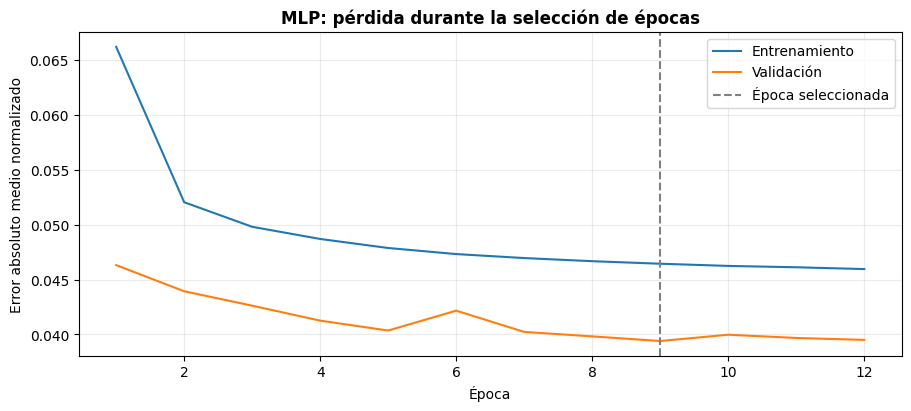

Pronósticos evaluados: 220,800
Pesos finales guardados en data/processed/mlp_multi_output.pt.
MAPE no está definido para todo el panel porque existen consumos reales en cero.


In [7]:
from pathlib import Path
from time import perf_counter
import platform

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from torch import nn


class MultiOutputMLP(nn.Module):
    def __init__(self, window_length=168, feature_count=8, horizon_length=24):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Flatten(),
            nn.Linear(window_length * feature_count, 128),
            nn.ReLU(),
            nn.Dropout(0.1),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(0.1),
            nn.Linear(64, horizon_length),
        )

    def forward(self, history_windows):
        return self.layers(history_windows)


class MLPForecaster:
    def __init__(self, scaler, training_reference, random_seed=123):
        self.scaler = scaler
        self.model_name = "MLP"
        self.random_seed = random_seed
        self.window_length = 168
        self.horizon_length = 24
        self.batch_size = 2048
        self.maximum_epochs = 12
        self.patience = 3
        self.learning_rate = 0.001
        self.weight_decay = 0.0001
        self.device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
        self.original_unit_factors = 1 / scaler.scale_
        self.mase_reference = training_reference.diff(24).abs().mean().to_numpy()
        self.selection_history = pd.DataFrame()
        self.final_training_history = pd.DataFrame()
        self.best_epoch = None
        self.network = None
        self.fit_seconds = 0.0
        self.inference_seconds = 0.0
        self.peak_gpu_memory_bytes = 0
        self.training_state = None

    def synchronize_device(self):
        if self.device.type == "mps":
            torch.mps.synchronize()

    def record_gpu_memory(self):
        if self.device.type == "mps":
            self.peak_gpu_memory_bytes = max(
                self.peak_gpu_memory_bytes, torch.mps.driver_allocated_memory()
            )

    def create_loader(self, window_dataset, shuffle):
        return DataLoader(
            window_dataset, batch_size=self.batch_size, shuffle=shuffle,
            generator=torch.Generator().manual_seed(self.random_seed),
            num_workers=0, collate_fn=keep_window_batch,
        )

    def initialize_network(self, feature_count):
        torch.manual_seed(self.random_seed)
        self.network = MultiOutputMLP(
            self.window_length, feature_count, self.horizon_length
        ).to(self.device)
        return torch.optim.AdamW(
            self.network.parameters(), lr=self.learning_rate, weight_decay=self.weight_decay
        )

    def train_epoch(self, loader, optimizer):
        self.network.train()
        total_loss = 0.0
        example_count = 0
        for history_windows, target_windows in loader:
            history_windows = history_windows.to(self.device)
            target_windows = target_windows.to(self.device)
            optimizer.zero_grad(set_to_none=True)
            predictions = self.network(history_windows)
            loss = nn.functional.l1_loss(predictions, target_windows)
            if not torch.isfinite(loss).item():
                raise FloatingPointError("La pérdida de entrenamiento no es finita.")
            loss.backward()
            optimizer.step()
            self.record_gpu_memory()
            total_loss += loss.item() * len(history_windows)
            example_count += len(history_windows)
        self.synchronize_device()
        return total_loss / example_count

    def evaluate_validation(self, loader):
        self.network.eval()
        total_normalized_error = 0.0
        total_original_error = 0.0
        total_scaled_error = 0.0
        scaled_error_count = 0
        example_count = 0
        client_count = len(self.client_columns)
        with torch.inference_mode():
            for history_windows, target_windows in loader:
                predictions = self.network(history_windows.to(self.device)).cpu()
                absolute_errors = (predictions - target_windows).abs().numpy().astype(np.float64)
                client_positions = np.arange(
                    example_count, example_count + len(history_windows)
                ) % client_count
                original_errors = absolute_errors * self.original_unit_factors[client_positions, None]
                reference_errors = self.mase_reference[client_positions]
                valid_reference = np.isfinite(reference_errors) & (reference_errors > 0)
                total_normalized_error += absolute_errors.sum()
                total_original_error += original_errors.sum()
                total_scaled_error += (
                    original_errors[valid_reference] / reference_errors[valid_reference, None]
                ).sum()
                scaled_error_count += int(valid_reference.sum()) * self.horizon_length
                example_count += len(history_windows)
                self.record_gpu_memory()
        element_count = example_count * self.horizon_length
        return {
            "validation_loss": total_normalized_error / element_count,
            "validation_MAE_kWh": total_original_error / element_count,
            "validation_MASE": total_scaled_error / scaled_error_count if scaled_error_count else np.nan,
        }

    def fit(self, consumption_history, calendar_history):
        fit_start = perf_counter()
        self.client_columns = consumption_history.columns.copy()
        self.calendar_columns = calendar_history.columns.copy()
        assert pd.Index(self.scaler.feature_names_in_).equals(self.client_columns)
        feature_count = 1 + len(self.calendar_columns)
        torch.set_num_threads(4)

        if self.best_epoch is None:
            selection_consumption = consumption_history.loc[:"2014-06-30 23:00"]
            selection_calendar = calendar_history.loc[selection_consumption.index]
            validation_end = pd.Timestamp("2014-09-30 23:00")
            assert consumption_history.index.max() >= validation_end
            training_dataset = PanelWindowDataset(
                selection_consumption, selection_calendar,
                selection_consumption.index.min(), selection_consumption.index.max(),
            )
            validation_dataset = PanelWindowDataset(
                consumption_history.loc[:validation_end], calendar_history.loc[:validation_end],
                pd.Timestamp("2014-07-01"), validation_end,
            )
            training_loader = self.create_loader(training_dataset, shuffle=True)
            validation_loader = self.create_loader(validation_dataset, shuffle=False)
            optimizer = self.initialize_network(feature_count)
            best_validation_loss = np.inf
            epochs_without_improvement = 0
            epoch_records = []
            print(f"{self.model_name}: selección de épocas en {self.device}, {len(training_dataset):,} ventanas de entrenamiento.", flush=True)
            for epoch_number in range(1, self.maximum_epochs + 1):
                epoch_start = perf_counter()
                training_loss = self.train_epoch(training_loader, optimizer)
                training_seconds = perf_counter() - epoch_start
                validation_start = perf_counter()
                validation_metrics = self.evaluate_validation(validation_loader)
                validation_seconds = perf_counter() - validation_start
                if not np.isfinite(validation_metrics["validation_loss"]):
                    raise FloatingPointError("La pérdida de validación no es finita.")
                epoch_records.append({
                    "epoch": epoch_number, "training_loss": training_loss,
                    **validation_metrics,
                    "training_seconds": training_seconds,
                    "validation_seconds": validation_seconds,
                })
                print(
                    f"Selección {epoch_number}/{self.maximum_epochs}: train={training_loss:.5f}, "
                    f"val={validation_metrics['validation_loss']:.5f}, "
                    f"MAE={validation_metrics['validation_MAE_kWh']:.2f} kWh, "
                    f"MASE={validation_metrics['validation_MASE']:.3f}.", flush=True,
                )
                if validation_metrics["validation_loss"] < best_validation_loss - 0.00001:
                    best_validation_loss = validation_metrics["validation_loss"]
                    self.best_epoch = epoch_number
                    epochs_without_improvement = 0
                else:
                    epochs_without_improvement += 1
                if epochs_without_improvement >= self.patience:
                    break
            self.selection_history = pd.DataFrame(epoch_records)
            del optimizer, training_loader, validation_loader

        final_dataset = PanelWindowDataset(
            consumption_history, calendar_history,
            consumption_history.index.min(), consumption_history.index.max(),
        )
        final_loader = self.create_loader(final_dataset, shuffle=True)
        optimizer = self.initialize_network(feature_count)
        final_records = []
        print(f"{self.model_name}: ajuste final hasta {consumption_history.index.max()} durante {self.best_epoch} épocas.", flush=True)
        for epoch_number in range(1, self.best_epoch + 1):
            epoch_start = perf_counter()
            training_loss = self.train_epoch(final_loader, optimizer)
            final_records.append({
                "epoch": epoch_number, "training_loss": training_loss,
                "training_seconds": perf_counter() - epoch_start,
            })
            print(f"Ajuste final {epoch_number}/{self.best_epoch}: train={training_loss:.5f}.", flush=True)
        self.final_training_history = pd.DataFrame(final_records)
        self.network.eval()
        self.training_state = {
            parameter_name: parameter.detach().cpu().clone()
            for parameter_name, parameter in self.network.state_dict().items()
        }
        self.fit_seconds += perf_counter() - fit_start
        return self

    def predict(self, consumption_window, calendar_window, future_calendar):
        inference_start = perf_counter()
        assert consumption_window.columns.equals(self.client_columns)
        assert calendar_window.index.equals(consumption_window.index)
        assert len(consumption_window) == self.window_length
        assert len(future_calendar) == self.horizon_length
        consumption_inputs = torch.from_numpy(
            consumption_window.to_numpy(dtype=np.float32).T.copy()
        ).unsqueeze(-1)
        calendar_inputs = torch.from_numpy(
            calendar_window.to_numpy(dtype=np.float32)
        ).unsqueeze(0).expand(len(self.client_columns), -1, -1)
        history_inputs = torch.cat([consumption_inputs, calendar_inputs], dim=-1).to(self.device)
        self.network.eval()
        with torch.inference_mode():
            predictions = self.network(history_inputs).cpu().numpy().T
        self.record_gpu_memory()
        self.inference_seconds += perf_counter() - inference_start
        return pd.DataFrame(predictions, index=future_calendar.index, columns=self.client_columns)


assert len(selected_clients) == 100 and client_selection_seed == 123
mlp_model = MLPForecaster(electricity_scaler, electricity_train_original, random_seed=123)
mlp_backtest_start = perf_counter()
mlp_results = backtest(mlp_model, window_length=168, refit_monthly=False)
mlp_backtest_seconds = perf_counter() - mlp_backtest_start
mlp_total_parameters = sum(parameter.numel() for parameter in mlp_model.network.parameters())
mlp_trainable_parameters = sum(
    parameter.numel() for parameter in mlp_model.network.parameters() if parameter.requires_grad
)
mlp_configuration = pd.Series({
    "Modelo": "MLP multi-salida global",
    "Clientes": len(selected_clients), "Semilla": 123,
    "Ventana (horas)": 168, "Horizonte (horas)": 24,
    "Variables por hora": 8, "Capas ocultas": "128 y 64, ReLU",
    "Dropout": 0.1, "Optimizador": "AdamW", "Learning rate": 0.001,
    "Weight decay": 0.0001, "Batch": mlp_model.batch_size,
    "Stride de entrenamiento (horas)": 1,
    "Máximo de épocas para selección": mlp_model.maximum_epochs,
    "Paciencia": mlp_model.patience, "Épocas del ajuste final": mlp_model.best_epoch,
    "Pérdida": "Error absoluto sobre consumos normalizados",
    "Parámetros totales": mlp_total_parameters,
    "Parámetros entrenables": mlp_trainable_parameters,
    "Clientes con referencia MASE distinta de cero": int(np.count_nonzero(
        np.isfinite(mlp_model.mase_reference) & (mlp_model.mase_reference > 0)
    )),
    "Hardware": f"{mlp_model.device} | {platform.system()} | {platform.machine()}",
    "PyTorch": str(torch.__version__),
}, name="Configuración")
mlp_results["resources"] = pd.Series({
    "Selección y ajuste final (s)": mlp_model.fit_seconds,
    "Inferencia de los 92 orígenes (s)": mlp_model.inference_seconds,
    "Backtest completo (s)": mlp_backtest_seconds,
    "Memoria GPU del controlador, máxima observada (MiB)": mlp_model.peak_gpu_memory_bytes / 1024**2,
}, name="Recursos")
mlp_results["selection_history"] = mlp_model.selection_history.copy()
mlp_results["final_training_history"] = mlp_model.final_training_history.copy()
mlp_artifact_directory = Path("data/processed")
mlp_artifact_directory.mkdir(parents=True, exist_ok=True)
mlp_checkpoint_path = mlp_artifact_directory / "mlp_multi_output.pt"
torch.save({
    "state_dict": mlp_model.training_state,
    "window_length": 168, "feature_count": 8, "horizon_length": 24,
    "hidden_sizes": [128, 64], "dropout": 0.1,
    "client_columns": selected_clients.tolist(),
    "calendar_columns": calendar_train.columns.tolist(),
    "seed": 123, "selected_epochs": mlp_model.best_epoch,
    "minmax_scale": torch.from_numpy(electricity_scaler.scale_.copy()),
    "minmax_min": torch.from_numpy(electricity_scaler.min_.copy()),
    "torch_version": str(torch.__version__),
}, mlp_checkpoint_path)
mlp_model.selection_history.to_csv(mlp_artifact_directory / "mlp_selection_history.csv", index=False)
mlp_model.final_training_history.to_csv(mlp_artifact_directory / "mlp_final_training_history.csv", index=False)

display(mlp_configuration.to_frame())
print("Selección de épocas con validación")
display(mlp_model.selection_history.round(5))
print("Ajuste final con entrenamiento y validación")
display(mlp_model.final_training_history.round(5))
display(mlp_results["resources"].to_frame().round(4))
print("Métricas generales en prueba")
display(mlp_results["overall_metrics"].to_frame("MLP").T.round(4))
for report_title, report_key in (
    ("Métricas por cliente", "metrics_by_client"),
    ("Métricas por paso del horizonte", "metrics_by_horizon"),
    ("Métricas por hora del día", "metrics_by_hour"),
):
    print(report_title)
    display(mlp_results[report_key].round(4))
print("Métricas de la semana del 22 al 28 de diciembre")
display(mlp_results["christmas_week_metrics"].to_frame("MLP").T.round(4))
mlp_loss_figure, mlp_loss_axis = plt.subplots(figsize=(9, 4), layout="constrained")
mlp_loss_axis.plot(mlp_model.selection_history["epoch"], mlp_model.selection_history["training_loss"], label="Entrenamiento")
mlp_loss_axis.plot(mlp_model.selection_history["epoch"], mlp_model.selection_history["validation_loss"], label="Validación")
mlp_loss_axis.axvline(mlp_model.best_epoch, linestyle="--", color="gray", label="Época seleccionada")
mlp_loss_axis.set_title("MLP: pérdida durante la selección de épocas", fontweight="bold")
mlp_loss_axis.set(xlabel="Época", ylabel="Error absoluto medio normalizado")
mlp_loss_axis.legend()
mlp_loss_axis.grid(alpha=0.25)
plt.show()
print(f"Pronósticos evaluados: {len(mlp_results['forecasts']):,}")
print(f"Pesos finales guardados en {mlp_checkpoint_path}.")
if mlp_results["overall_metrics"]["zero_actual_count"] > 0:
    print("MAPE no está definido para todo el panel porque existen consumos reales en cero.")


### **DLinear**

DLinear separa el historial en una tendencia suavizada y un residuo que conserva las variaciones alrededor de ella. Luego aprende un pronóstico para cada componente mediante dos capas lineales y combina sus resultados para obtener las 24 horas futuras.

- **Descomposición:** Se utilizará una media móvil de 25 horas. Los picos y caídas no se eliminan, ya que permanecen en el residuo y también participan en el pronóstico.
- **Información disponible:** La media se calcula únicamente dentro de la ventana histórica. En sus extremos se repite el primer o último valor disponible, sin consultar observaciones posteriores al origen.
- **Entrada y salida:** Se utilizarán 168 consumos históricos de cada cliente para producir directamente los 24 consumos futuros. Se reutiliza el Dataset, pero este modelo utiliza únicamente su columna de consumo, sin covariables de calendario.
- **Arquitectura:** Se comparten las dos capas lineales entre los 100 clientes. No se utilizan capas ocultas, ReLU ni dropout.
- **Entrenamiento:** Se reutilizará el procedimiento del MLP con AdamW, learning rate de 0.001, weight decay de 0.0001, lotes de 2048, semilla 123 y desplazamiento de una hora. La cantidad de épocas se seleccionará con validación, con máximo de 12 y paciencia de tres.
- **Ajuste final y evaluación:** Se entrenará hasta septiembre con la cantidad de épocas seleccionada y se utilizará el mismo backtest diario, manteniendo los pesos fijos durante prueba. Se registran pérdidas, MAE y MASE de validación, parámetros y recursos, y se guardan los pesos finales.

DLinear: selección de épocas en mps, 2,169,700 ventanas de entrenamiento.


Selección 1/12: train=0.04109, val=0.03575, MAE=32.45 kWh, MASE=0.881.


Selección 2/12: train=0.03521, val=0.03531, MAE=31.88 kWh, MASE=0.869.


Selección 3/12: train=0.03519, val=0.03530, MAE=31.89 kWh, MASE=0.869.


Selección 4/12: train=0.03519, val=0.03539, MAE=32.03 kWh, MASE=0.872.


...

,MAE_kWh,RMSE_kWh,WAPE_pct,MAPE_pct,zero_actual_count
horizon_step,,,,,
1,28.7115,152.8297,7.1845,NaN,17
2,40.9742,214.7159,11.4566,NaN,42
3,31.6704,168.8308,9.1189,NaN,43
4,30.3647,165.9422,8.7603,NaN,29
5,30.3073,170.1559,8.8755,NaN,30
6,32.1224,162.5990,9.2994,NaN,29
7,34.1673,175.9961,8.9494,NaN,29
8,30.9290,172.1805,6.9026,NaN,35
9,32.0304,160.7612,7.0525,NaN,90


Métricas por hora del día


,MAE_kWh,RMSE_kWh,WAPE_pct,MAPE_pct,zero_actual_count
hour_of_day,,,,,
0,28.7115,152.8297,7.1845,NaN,17
1,40.9742,214.7159,11.4566,NaN,42
2,31.6704,168.8308,9.1189,NaN,43
3,30.3647,165.9422,8.7603,NaN,29
4,30.3073,170.1559,8.8755,NaN,30
5,32.1224,162.5990,9.2994,NaN,29
6,34.1673,175.9961,8.9494,NaN,29
7,30.9290,172.1805,6.9026,NaN,35
8,32.0304,160.7612,7.0525,NaN,90


Métricas de la semana del 22 al 28 de diciembre


,MAE_kWh,RMSE_kWh,WAPE_pct,MAPE_pct,zero_actual_count
DLinear,94.2094,549.4086,19.8323,NaN,353.0


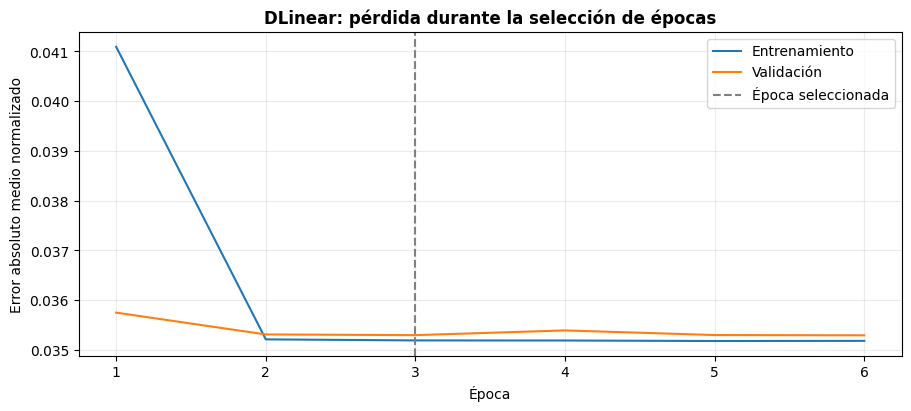

Pronósticos evaluados: 220,800
Pesos finales guardados en data/processed/dlinear.pt.
MAPE no está definido para todo el panel porque existen consumos reales en cero.


In [9]:
class DLinearNetwork(nn.Module):
    def __init__(self, window_length=168, horizon_length=24, moving_average_length=25):
        super().__init__()
        if moving_average_length % 2 == 0 or moving_average_length < 1:
            raise ValueError("La longitud de la media móvil debe ser impar y positiva.")
        self.moving_average_length = moving_average_length
        self.moving_average = nn.AvgPool1d(moving_average_length, stride=1)
        self.trend_linear = nn.Linear(window_length, horizon_length)
        self.residual_linear = nn.Linear(window_length, horizon_length)

    def decompose(self, consumption_history):
        padding_length = (self.moving_average_length - 1) // 2
        padded_history = nn.functional.pad(
            consumption_history.unsqueeze(1), (padding_length, padding_length), mode="replicate"
        )
        trend = self.moving_average(padded_history).squeeze(1)
        residual = consumption_history - trend
        return trend, residual

    def forward(self, history_windows):
        trend, residual = self.decompose(history_windows[:, :, 0])
        return self.trend_linear(trend) + self.residual_linear(residual)


class DLinearForecaster(MLPForecaster):
    def __init__(self, scaler, training_reference, random_seed=123):
        super().__init__(scaler, training_reference, random_seed)
        self.model_name = "DLinear"
        self.moving_average_length = 25

    def initialize_network(self, feature_count):
        torch.manual_seed(self.random_seed)
        self.network = DLinearNetwork(
            self.window_length, self.horizon_length, self.moving_average_length
        ).to(self.device)
        return torch.optim.AdamW(
            self.network.parameters(), lr=self.learning_rate, weight_decay=self.weight_decay
        )


assert len(selected_clients) == 100 and client_selection_seed == 123
dlinear_model = DLinearForecaster(electricity_scaler, electricity_train_original, random_seed=123)
dlinear_backtest_start = perf_counter()
dlinear_results = backtest(dlinear_model, window_length=168, refit_monthly=False)
dlinear_backtest_seconds = perf_counter() - dlinear_backtest_start
dlinear_total_parameters = sum(parameter.numel() for parameter in dlinear_model.network.parameters())
dlinear_trainable_parameters = sum(
    parameter.numel() for parameter in dlinear_model.network.parameters() if parameter.requires_grad
)
dlinear_configuration = pd.Series({
    "Modelo": "DLinear global",
    "Clientes": len(selected_clients), "Semilla": 123,
    "Ventana (horas)": 168, "Horizonte (horas)": 24,
    "Variable utilizada": "Consumo; no utiliza las covariables del Dataset",
    "Media móvil (horas)": 25,
    "Arquitectura": "Una capa lineal para tendencia y otra para residuo; se suman sus pronósticos",
    "Dropout": 0, "Optimizador": "AdamW", "Learning rate": dlinear_model.learning_rate,
    "Weight decay": dlinear_model.weight_decay, "Batch": dlinear_model.batch_size,
    "Stride de entrenamiento (horas)": 1,
    "Máximo de épocas para selección": dlinear_model.maximum_epochs,
    "Paciencia": dlinear_model.patience, "Épocas del ajuste final": dlinear_model.best_epoch,
    "Pérdida": "Error absoluto sobre consumos normalizados",
    "Parámetros totales": dlinear_total_parameters,
    "Parámetros entrenables": dlinear_trainable_parameters,
    "Hardware": f"{dlinear_model.device} | {platform.system()} | {platform.machine()}",
    "PyTorch": str(torch.__version__),
}, name="Configuración")
dlinear_results["resources"] = pd.Series({
    "Selección y ajuste final (s)": dlinear_model.fit_seconds,
    "Inferencia de los 92 orígenes (s)": dlinear_model.inference_seconds,
    "Backtest completo (s)": dlinear_backtest_seconds,
    "Memoria GPU del controlador, máxima observada (MiB)": dlinear_model.peak_gpu_memory_bytes / 1024**2,
}, name="Recursos")
dlinear_results["selection_history"] = dlinear_model.selection_history.copy()
dlinear_results["final_training_history"] = dlinear_model.final_training_history.copy()
dlinear_artifact_directory = Path("data/processed")
dlinear_artifact_directory.mkdir(parents=True, exist_ok=True)
dlinear_checkpoint_path = dlinear_artifact_directory / "dlinear.pt"
torch.save({
    "state_dict": dlinear_model.training_state,
    "window_length": 168, "horizon_length": 24, "moving_average_length": 25,
    "consumption_feature_index": 0,
    "client_columns": selected_clients.tolist(),
    "seed": 123, "selected_epochs": dlinear_model.best_epoch,
    "minmax_scale": torch.from_numpy(electricity_scaler.scale_.copy()),
    "minmax_min": torch.from_numpy(electricity_scaler.min_.copy()),
    "torch_version": str(torch.__version__),
}, dlinear_checkpoint_path)
dlinear_model.selection_history.to_csv(dlinear_artifact_directory / "dlinear_selection_history.csv", index=False)
dlinear_model.final_training_history.to_csv(dlinear_artifact_directory / "dlinear_final_training_history.csv", index=False)

display(dlinear_configuration.to_frame())
print("Selección de épocas con validación")
display(dlinear_model.selection_history.round(5))
print("Ajuste final con entrenamiento y validación")
display(dlinear_model.final_training_history.round(5))
display(dlinear_results["resources"].to_frame().round(4))
print("Métricas generales en prueba")
display(dlinear_results["overall_metrics"].to_frame("DLinear").T.round(4))
for report_title, report_key in (
    ("Métricas por cliente", "metrics_by_client"),
    ("Métricas por paso del horizonte", "metrics_by_horizon"),
    ("Métricas por hora del día", "metrics_by_hour"),
):
    print(report_title)
    display(dlinear_results[report_key].round(4))
print("Métricas de la semana del 22 al 28 de diciembre")
display(dlinear_results["christmas_week_metrics"].to_frame("DLinear").T.round(4))
dlinear_loss_figure, dlinear_loss_axis = plt.subplots(figsize=(9, 4), layout="constrained")
dlinear_loss_axis.plot(dlinear_model.selection_history["epoch"], dlinear_model.selection_history["training_loss"], label="Entrenamiento")
dlinear_loss_axis.plot(dlinear_model.selection_history["epoch"], dlinear_model.selection_history["validation_loss"], label="Validación")
dlinear_loss_axis.axvline(dlinear_model.best_epoch, linestyle="--", color="gray", label="Época seleccionada")
dlinear_loss_axis.set_title("DLinear: pérdida durante la selección de épocas", fontweight="bold")
dlinear_loss_axis.set(xlabel="Época", ylabel="Error absoluto medio normalizado")
dlinear_loss_axis.legend()
dlinear_loss_axis.grid(alpha=0.25)
plt.show()
print(f"Pronósticos evaluados: {len(dlinear_results['forecasts']):,}")
print(f"Pesos finales guardados en {dlinear_checkpoint_path}.")
if dlinear_results["overall_metrics"]["zero_actual_count"] > 0:
    print("MAPE no está definido para todo el panel porque existen consumos reales en cero.")


### **NLinear**

NLinear toma el último consumo de la ventana como referencia y expresa el historial a partir de sus diferencias con ese valor. Luego utiliza una capa lineal para producir las diferencias futuras y recupera el nivel de consumo al incorporar nuevamente la referencia.

- **Entrada y salida:** Se utilizarán 168 consumos históricos para producir directamente las 24 predicciones. Se reutiliza el Dataset, pero el modelo utiliza únicamente su columna de consumo, sin covariables de calendario.
- **Referencia:** Los 24 cambios se miden respecto al mismo último consumo observado, sin acumular predicciones de pasos anteriores. Este centrado se realiza dentro del modelo y se conserva la normalización Min–Max por cliente que ya se definió.
- **Arquitectura:** Se utilizará una capa lineal compartida entre los 100 clientes, sin capas ocultas, ReLU ni dropout.
- **Entrenamiento:** Se mantendrá el procedimiento utilizado para DLinear, con AdamW, learning rate de 0.001, weight decay de 0.0001, lotes de 2048, semilla 123 y desplazamiento de una hora. La cantidad de épocas se seleccionará con validación, con máximo de 12 y paciencia de tres.
- **Ajuste final y evaluación:** Se entrenará hasta septiembre con la cantidad de épocas seleccionada y se utilizará el mismo backtest diario, manteniendo los pesos fijos durante prueba. Se registran pérdidas, MAE y MASE de validación, parámetros y recursos, y se guardan los pesos finales.

NLinear: selección de épocas en mps, 2,169,700 ventanas de entrenamiento.


Selección 1/12: train=0.03988, val=0.03549, MAE=32.08 kWh, MASE=0.872.


Selección 2/12: train=0.03519, val=0.03516, MAE=31.64 kWh, MASE=0.864.


Selección 3/12: train=0.03506, val=0.03518, MAE=31.65 kWh, MASE=0.866.


Selección 4/12: train=0.03504, val=0.03516, MAE=31.70 kWh, MASE=0.865.


...

,MAE_kWh,RMSE_kWh,WAPE_pct,MAPE_pct,zero_actual_count
horizon_step,,,,,
1,29.0500,153.3559,7.2692,NaN,17
2,40.4982,214.7989,11.3235,NaN,42
3,31.5581,168.2675,9.0866,NaN,43
4,30.8438,166.2138,8.8986,NaN,29
5,30.4334,168.6447,8.9125,NaN,30
6,30.4609,159.4571,8.8184,NaN,29
7,30.6974,169.1454,8.0405,NaN,29
8,29.5443,169.0163,6.5936,NaN,35
9,32.2160,160.8487,7.0934,NaN,90


Métricas por hora del día


,MAE_kWh,RMSE_kWh,WAPE_pct,MAPE_pct,zero_actual_count
hour_of_day,,,,,
0,29.0500,153.3559,7.2692,NaN,17
1,40.4982,214.7989,11.3235,NaN,42
2,31.5581,168.2675,9.0866,NaN,43
3,30.8438,166.2138,8.8986,NaN,29
4,30.4334,168.6447,8.9125,NaN,30
5,30.4609,159.4571,8.8184,NaN,29
6,30.6974,169.1454,8.0405,NaN,29
7,29.5443,169.0163,6.5936,NaN,35
8,32.2160,160.8487,7.0934,NaN,90


Métricas de la semana del 22 al 28 de diciembre


,MAE_kWh,RMSE_kWh,WAPE_pct,MAPE_pct,zero_actual_count
NLinear,93.9801,547.5944,19.784,NaN,353.0


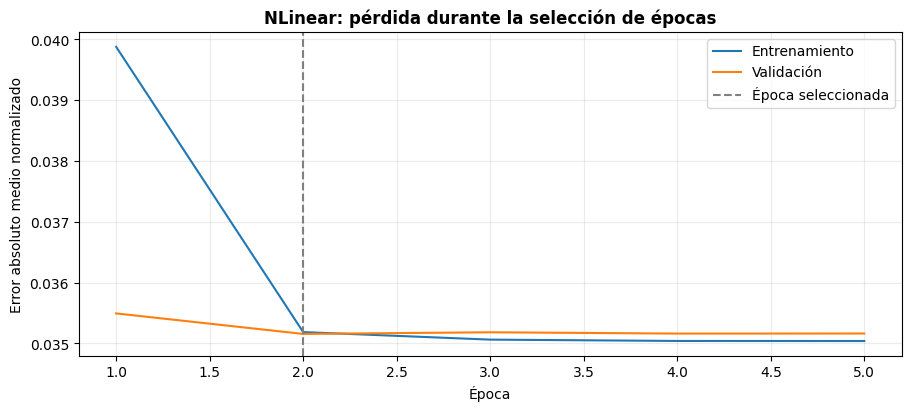

Pronósticos evaluados: 220,800
Pesos finales guardados en data/processed/nlinear.pt.
MAPE no está definido para todo el panel porque existen consumos reales en cero.


In [9]:
class NLinearNetwork(nn.Module):
    def __init__(self, window_length=168, horizon_length=24):
        super().__init__()
        self.linear = nn.Linear(window_length, horizon_length)

    def forward(self, history_windows):
        consumption_history = history_windows[:, :, 0]
        last_consumption = consumption_history[:, -1:].detach()
        relative_history = consumption_history - last_consumption
        predicted_changes = self.linear(relative_history)
        return predicted_changes + last_consumption


class NLinearForecaster(MLPForecaster):
    def __init__(self, scaler, training_reference, random_seed=123):
        super().__init__(scaler, training_reference, random_seed)
        self.model_name = "NLinear"

    def initialize_network(self, feature_count):
        torch.manual_seed(self.random_seed)
        self.network = NLinearNetwork(self.window_length, self.horizon_length).to(self.device)
        return torch.optim.AdamW(
            self.network.parameters(), lr=self.learning_rate, weight_decay=self.weight_decay
        )


assert len(selected_clients) == 100 and client_selection_seed == 123
nlinear_model = NLinearForecaster(electricity_scaler, electricity_train_original, random_seed=123)
nlinear_backtest_start = perf_counter()
nlinear_results = backtest(nlinear_model, window_length=168, refit_monthly=False)
nlinear_backtest_seconds = perf_counter() - nlinear_backtest_start
nlinear_total_parameters = sum(parameter.numel() for parameter in nlinear_model.network.parameters())
nlinear_trainable_parameters = sum(
    parameter.numel() for parameter in nlinear_model.network.parameters() if parameter.requires_grad
)
nlinear_configuration = pd.Series({
    "Modelo": "NLinear global",
    "Clientes": len(selected_clients), "Semilla": 123,
    "Ventana (horas)": 168, "Horizonte (horas)": 24,
    "Variable utilizada": "Consumo; no utiliza las covariables del Dataset",
    "Referencia de la ventana": "Último consumo observado",
    "Arquitectura": "Una capa lineal que predice 24 diferencias y recupera el nivel original",
    "Dropout": 0, "Optimizador": "AdamW", "Learning rate": nlinear_model.learning_rate,
    "Weight decay": nlinear_model.weight_decay, "Batch": nlinear_model.batch_size,
    "Stride de entrenamiento (horas)": 1,
    "Máximo de épocas para selección": nlinear_model.maximum_epochs,
    "Paciencia": nlinear_model.patience, "Épocas del ajuste final": nlinear_model.best_epoch,
    "Pérdida": "Error absoluto sobre consumos normalizados",
    "Parámetros totales": nlinear_total_parameters,
    "Parámetros entrenables": nlinear_trainable_parameters,
    "Hardware": f"{nlinear_model.device} | {platform.system()} | {platform.machine()}",
    "PyTorch": str(torch.__version__),
}, name="Configuración")
nlinear_results["resources"] = pd.Series({
    "Selección y ajuste final (s)": nlinear_model.fit_seconds,
    "Inferencia de los 92 orígenes (s)": nlinear_model.inference_seconds,
    "Backtest completo (s)": nlinear_backtest_seconds,
    "Memoria GPU del controlador, máxima observada (MiB)": nlinear_model.peak_gpu_memory_bytes / 1024**2,
}, name="Recursos")
nlinear_results["selection_history"] = nlinear_model.selection_history.copy()
nlinear_results["final_training_history"] = nlinear_model.final_training_history.copy()
nlinear_artifact_directory = Path("data/processed")
nlinear_artifact_directory.mkdir(parents=True, exist_ok=True)
nlinear_checkpoint_path = nlinear_artifact_directory / "nlinear.pt"
torch.save({
    "state_dict": nlinear_model.training_state,
    "window_length": 168, "horizon_length": 24,
    "reference": "last_observation", "consumption_feature_index": 0,
    "client_columns": selected_clients.tolist(),
    "seed": 123, "selected_epochs": nlinear_model.best_epoch,
    "minmax_scale": torch.from_numpy(electricity_scaler.scale_.copy()),
    "minmax_min": torch.from_numpy(electricity_scaler.min_.copy()),
    "torch_version": str(torch.__version__),
}, nlinear_checkpoint_path)
nlinear_model.selection_history.to_csv(nlinear_artifact_directory / "nlinear_selection_history.csv", index=False)
nlinear_model.final_training_history.to_csv(nlinear_artifact_directory / "nlinear_final_training_history.csv", index=False)

display(nlinear_configuration.to_frame())
print("Selección de épocas con validación")
display(nlinear_model.selection_history.round(5))
print("Ajuste final con entrenamiento y validación")
display(nlinear_model.final_training_history.round(5))
display(nlinear_results["resources"].to_frame().round(4))
print("Métricas generales en prueba")
display(nlinear_results["overall_metrics"].to_frame("NLinear").T.round(4))
for report_title, report_key in (
    ("Métricas por cliente", "metrics_by_client"),
    ("Métricas por paso del horizonte", "metrics_by_horizon"),
    ("Métricas por hora del día", "metrics_by_hour"),
):
    print(report_title)
    display(nlinear_results[report_key].round(4))
print("Métricas de la semana del 22 al 28 de diciembre")
display(nlinear_results["christmas_week_metrics"].to_frame("NLinear").T.round(4))
nlinear_loss_figure, nlinear_loss_axis = plt.subplots(figsize=(9, 4), layout="constrained")
nlinear_loss_axis.plot(nlinear_model.selection_history["epoch"], nlinear_model.selection_history["training_loss"], label="Entrenamiento")
nlinear_loss_axis.plot(nlinear_model.selection_history["epoch"], nlinear_model.selection_history["validation_loss"], label="Validación")
nlinear_loss_axis.axvline(nlinear_model.best_epoch, linestyle="--", color="gray", label="Época seleccionada")
nlinear_loss_axis.set_title("NLinear: pérdida durante la selección de épocas", fontweight="bold")
nlinear_loss_axis.set(xlabel="Época", ylabel="Error absoluto medio normalizado")
nlinear_loss_axis.legend()
nlinear_loss_axis.grid(alpha=0.25)
plt.show()
print(f"Pronósticos evaluados: {len(nlinear_results['forecasts']):,}")
print(f"Pesos finales guardados en {nlinear_checkpoint_path}.")
if nlinear_results["overall_metrics"]["zero_actual_count"] > 0:
    print("MAPE no está definido para todo el panel porque existen consumos reales en cero.")


### **LSTM multi-salida**

Se utilizará una LSTM global que recorre las 168 horas de entrada y construye una representación interna del historial. Una capa lineal utiliza el estado oculto final para producir directamente los 24 consumos futuros.

- **Entrada:** Se utilizarán el consumo de cada cliente y las siete covariables de calendario, manteniendo el orden temporal dentro de cada ventana.
- **Arquitectura:** Se utilizará una capa recurrente con estado oculto de 32 números y el batch primero. Los estados oculto y de celda se reinician en cada ventana, de tal forma que no se arrastre información entre clientes ni ejemplos.
- **Regularización:** El dropout interno de la LSTM se deja en cero porque se utiliza una sola capa recurrente. Se aplica dropout de 0.1 al estado oculto final antes de la capa de salida.
- **Entrenamiento:** Se utilizarán AdamW, learning rate de 0.001, weight decay de 0.0001, lotes de 1024, semilla 123 y recorte de norma del gradiente a 1 para limitar actualizaciones excesivas. Se conservan los 100 clientes y las ventanas con desplazamiento de una hora.
- **Costo y validación:** Esta configuración inicial utiliza un máximo de seis épocas y paciencia de dos, para moderar el costo recurrente. Se selecciona la cantidad de épocas únicamente con validación y se registran pérdida, MAE en kWh y MASE por época.
- **Ajuste final y evaluación:** Se reinicializa la misma arquitectura y se entrena hasta septiembre durante las épocas seleccionadas. Después se utiliza el mismo backtest diario, con pesos fijos durante prueba, y se guardan los resultados y los pesos finales.
- **Estrategia:** Esta implementación produce las 24 salidas de una vez. La comparación con las otras estrategias de LSTM corresponde al apartado 5.1.

LSTM multi-salida: selección de épocas en mps, 2,169,700 ventanas de entrenamiento.


LSTM: 512,000 de 2,169,700 ventanas de la época.


LSTM: 1,024,000 de 2,169,700 ventanas de la época.


LSTM: 1,536,000 de 2,169,700 ventanas de la época.


LSTM: 2,048,000 de 2,169,700 ventanas de la época.


...

,MAE_kWh,RMSE_kWh,WAPE_pct,MAPE_pct,zero_actual_count
horizon_step,,,,,
1,43.0123,155.8342,10.7630,NaN,17
2,49.6793,212.1560,13.8905,NaN,42
3,37.2455,170.9505,10.7241,NaN,43
4,37.1647,191.9499,10.7222,NaN,29
5,37.5193,182.8431,10.9876,NaN,30
6,42.6587,200.2278,12.3497,NaN,29
7,41.7448,186.2421,10.9341,NaN,29
8,50.3390,223.9427,11.2345,NaN,35
9,58.5142,219.9878,12.8838,NaN,90


Métricas por hora del día


,MAE_kWh,RMSE_kWh,WAPE_pct,MAPE_pct,zero_actual_count
hour_of_day,,,,,
0,43.0123,155.8342,10.7630,NaN,17
1,49.6793,212.1560,13.8905,NaN,42
2,37.2455,170.9505,10.7241,NaN,43
3,37.1647,191.9499,10.7222,NaN,29
4,37.5193,182.8431,10.9876,NaN,30
5,42.6587,200.2278,12.3497,NaN,29
6,41.7448,186.2421,10.9341,NaN,29
7,50.3390,223.9427,11.2345,NaN,35
8,58.5142,219.9878,12.8838,NaN,90


Métricas de la semana del 22 al 28 de diciembre


,MAE_kWh,RMSE_kWh,WAPE_pct,MAPE_pct,zero_actual_count
LSTM,102.8677,567.6804,21.6549,NaN,353.0


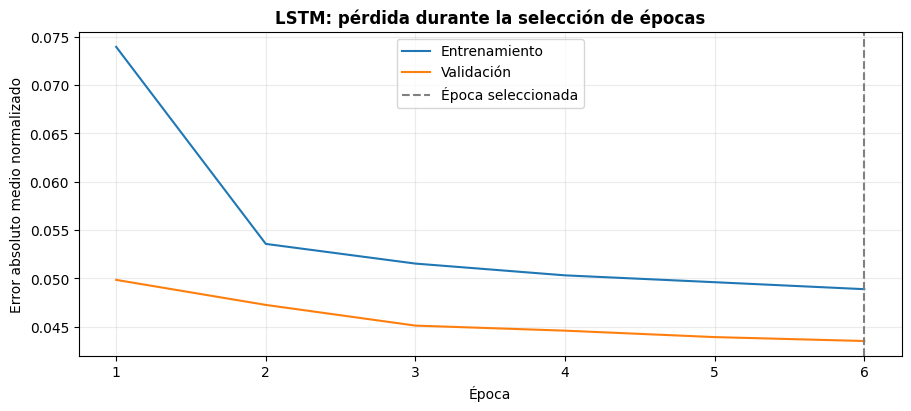

Pronósticos evaluados: 220,800
Pesos finales guardados en data/processed/lstm_multi_output.pt.
MAPE no está definido para todo el panel porque existen consumos reales en cero.


In [9]:
class LSTMMultiOutputNetwork(nn.Module):
    def __init__(self, feature_count=8, hidden_size=32, horizon_length=24):
        super().__init__()
        self.recurrent = nn.LSTM(
            input_size=feature_count, hidden_size=hidden_size,
            num_layers=1, batch_first=True, dropout=0.0,
        )
        self.output_dropout = nn.Dropout(0.1)
        self.output_projection = nn.Linear(hidden_size, horizon_length)

    def forward(self, history_windows):
        sequence_representations, (hidden_states, cell_states) = self.recurrent(history_windows)
        final_representation = hidden_states[-1]
        return self.output_projection(self.output_dropout(final_representation))


class LSTMForecaster(MLPForecaster):
    def __init__(self, scaler, training_reference, random_seed=123):
        super().__init__(scaler, training_reference, random_seed)
        self.model_name = "LSTM multi-salida"
        self.hidden_size = 32
        self.batch_size = 1024
        self.maximum_epochs = 6
        self.patience = 2
        self.gradient_clip_norm = 1.0

    def initialize_network(self, feature_count):
        torch.manual_seed(self.random_seed)
        self.network = LSTMMultiOutputNetwork(
            feature_count, self.hidden_size, self.horizon_length
        ).to(self.device)
        return torch.optim.AdamW(
            self.network.parameters(), lr=self.learning_rate, weight_decay=self.weight_decay
        )

    def train_epoch(self, loader, optimizer):
        self.network.train()
        total_loss = 0.0
        example_count = 0
        for batch_number, (history_windows, target_windows) in enumerate(loader, start=1):
            history_windows = history_windows.to(self.device)
            target_windows = target_windows.to(self.device)
            optimizer.zero_grad(set_to_none=True)
            predictions = self.network(history_windows)
            loss = nn.functional.l1_loss(predictions, target_windows)
            if not torch.isfinite(loss).item():
                raise FloatingPointError("La pérdida de entrenamiento no es finita.")
            loss.backward()
            nn.utils.clip_grad_norm_(
                self.network.parameters(), self.gradient_clip_norm, error_if_nonfinite=True
            )
            optimizer.step()
            self.record_gpu_memory()
            total_loss += loss.item() * len(history_windows)
            example_count += len(history_windows)
            if batch_number % 500 == 0:
                print(f"LSTM: {example_count:,} de {len(loader.dataset):,} ventanas de la época.", flush=True)
        self.synchronize_device()
        return total_loss / example_count


assert len(selected_clients) == 100 and client_selection_seed == 123
lstm_model = LSTMForecaster(electricity_scaler, electricity_train_original, random_seed=123)
lstm_backtest_start = perf_counter()
lstm_results = backtest(lstm_model, window_length=168, refit_monthly=False)
lstm_backtest_seconds = perf_counter() - lstm_backtest_start
lstm_total_parameters = sum(parameter.numel() for parameter in lstm_model.network.parameters())
lstm_trainable_parameters = sum(
    parameter.numel() for parameter in lstm_model.network.parameters() if parameter.requires_grad
)
lstm_configuration = pd.Series({
    "Modelo": "LSTM multi-salida global",
    "Clientes": len(selected_clients), "Semilla": 123,
    "Ventana (horas)": 168, "Horizonte (horas)": 24,
    "Variables por hora": 8,
    "Input size": 8, "Hidden size": 32, "Capas recurrentes": 1,
    "Batch first": True,
    "Dropout entre capas recurrentes": 0,
    "Dropout antes de la salida": 0.1,
    "Estrategia": "24 salidas directas desde el estado oculto final",
    "Optimizador": "AdamW", "Learning rate": lstm_model.learning_rate,
    "Weight decay": lstm_model.weight_decay, "Batch": lstm_model.batch_size,
    "Recorte de norma del gradiente": lstm_model.gradient_clip_norm,
    "Stride de entrenamiento (horas)": 1,
    "Máximo de épocas para selección": lstm_model.maximum_epochs,
    "Paciencia": lstm_model.patience, "Épocas del ajuste final": lstm_model.best_epoch,
    "Pérdida": "Error absoluto sobre consumos normalizados",
    "Parámetros totales": lstm_total_parameters,
    "Parámetros entrenables": lstm_trainable_parameters,
    "Hardware": f"{lstm_model.device} | {platform.system()} | {platform.machine()}",
    "PyTorch": str(torch.__version__),
}, name="Configuración")
lstm_results["resources"] = pd.Series({
    "Selección y ajuste final (s)": lstm_model.fit_seconds,
    "Inferencia de los 92 orígenes (s)": lstm_model.inference_seconds,
    "Backtest completo (s)": lstm_backtest_seconds,
    "Memoria GPU del controlador, máxima observada (MiB)": lstm_model.peak_gpu_memory_bytes / 1024**2,
}, name="Recursos")
lstm_results["selection_history"] = lstm_model.selection_history.copy()
lstm_results["final_training_history"] = lstm_model.final_training_history.copy()
lstm_artifact_directory = Path("data/processed")
lstm_artifact_directory.mkdir(parents=True, exist_ok=True)
lstm_checkpoint_path = lstm_artifact_directory / "lstm_multi_output.pt"
torch.save({
    "state_dict": lstm_model.training_state,
    "window_length": 168, "feature_count": 8, "horizon_length": 24,
    "hidden_size": 32, "num_layers": 1, "output_dropout": 0.1,
    "strategy": "multi_output", "client_columns": selected_clients.tolist(),
    "calendar_columns": calendar_train.columns.tolist(),
    "seed": 123, "selected_epochs": lstm_model.best_epoch,
    "minmax_scale": torch.from_numpy(electricity_scaler.scale_.copy()),
    "minmax_min": torch.from_numpy(electricity_scaler.min_.copy()),
    "torch_version": str(torch.__version__),
}, lstm_checkpoint_path)
lstm_model.selection_history.to_csv(lstm_artifact_directory / "lstm_selection_history.csv", index=False)
lstm_model.final_training_history.to_csv(lstm_artifact_directory / "lstm_final_training_history.csv", index=False)

display(lstm_configuration.to_frame())
print("Selección de épocas con validación")
display(lstm_model.selection_history.round(5))
print("Ajuste final con entrenamiento y validación")
display(lstm_model.final_training_history.round(5))
display(lstm_results["resources"].to_frame().round(4))
print("Métricas generales en prueba")
display(lstm_results["overall_metrics"].to_frame("LSTM").T.round(4))
for report_title, report_key in (
    ("Métricas por cliente", "metrics_by_client"),
    ("Métricas por paso del horizonte", "metrics_by_horizon"),
    ("Métricas por hora del día", "metrics_by_hour"),
):
    print(report_title)
    display(lstm_results[report_key].round(4))
print("Métricas de la semana del 22 al 28 de diciembre")
display(lstm_results["christmas_week_metrics"].to_frame("LSTM").T.round(4))
lstm_loss_figure, lstm_loss_axis = plt.subplots(figsize=(9, 4), layout="constrained")
lstm_loss_axis.plot(lstm_model.selection_history["epoch"], lstm_model.selection_history["training_loss"], label="Entrenamiento")
lstm_loss_axis.plot(lstm_model.selection_history["epoch"], lstm_model.selection_history["validation_loss"], label="Validación")
lstm_loss_axis.axvline(lstm_model.best_epoch, linestyle="--", color="gray", label="Época seleccionada")
lstm_loss_axis.set_title("LSTM: pérdida durante la selección de épocas", fontweight="bold")
lstm_loss_axis.set(xlabel="Época", ylabel="Error absoluto medio normalizado")
lstm_loss_axis.legend()
lstm_loss_axis.grid(alpha=0.25)
plt.show()
print(f"Pronósticos evaluados: {len(lstm_results['forecasts']):,}")
print(f"Pesos finales guardados en {lstm_checkpoint_path}.")
if lstm_results["overall_metrics"]["zero_actual_count"] > 0:
    print("MAPE no está definido para todo el panel porque existen consumos reales en cero.")


### **Seq2seq con calendario en el decoder**

Se utilizará un modelo global encoder–decoder. El encoder procesa las 168 horas históricas y entrega sus estados oculto y de celda al decoder, que genera los 24 consumos futuros utilizando el calendario de cada hora objetivo.

- **Arquitectura:** Encoder y decoder serán LSTM de una capa con estado oculto de 32 números. El encoder recibe consumo y calendario histórico, mientras que cada entrada del decoder contiene el consumo anterior y las siete covariables futuras de calendario. Se aplica dropout de 0.1 antes de la proyección de salida.
- **Entrenamiento con teacher forcing:** Para el primer paso se utiliza el último consumo histórico. En los siguientes se utiliza el consumo real del paso anterior de la secuencia objetivo, manteniendo el desplazamiento para que no se entregue como entrada la respuesta que se está pronosticando.
- **Validación y prueba:** El decoder utiliza sus propias predicciones como consumos anteriores y recibe únicamente calendario conocido a futuro. Los consumos reales futuros se utilizan para calcular errores, sin entrar al modelo durante estas evaluaciones.
- **Dataset:** Se reutilizan las mismas ventanas y se añade un acceso al calendario de sus 24 fechas objetivo, conservando su alineación temporal.
- **Configuración inicial:** Se mantendrán 100 clientes, semilla 123, AdamW, learning rate de 0.001, weight decay de 0.0001, lotes de 1024, recorte de norma a 1 y desplazamiento de una hora. Se utilizará un máximo de seis épocas y paciencia de dos.
- **Selección y ajuste final:** Las épocas se seleccionan mediante validación autorregresiva, sin teacher forcing. Después se reinicializa la misma arquitectura y se entrena hasta septiembre con el número seleccionado, manteniendo los pesos fijos durante el backtest de prueba.
- **Registro:** Se guardan pérdidas, MAE y MASE de validación, parámetros, recursos y pesos finales. Las pérdidas de entrenamiento y validación corresponden a condiciones diferentes, ya que únicamente entrenamiento utiliza teacher forcing.

Seq2seq con calendario: selección de épocas en mps, 2,169,700 ventanas de entrenamiento.


Seq2seq: 512,000 de 2,169,700 ventanas de la época.


Seq2seq: 1,024,000 de 2,169,700 ventanas de la época.


Seq2seq: 1,536,000 de 2,169,700 ventanas de la época.


Seq2seq: 2,048,000 de 2,169,700 ventanas de la época.


...

,MAE_kWh,RMSE_kWh,WAPE_pct,MAPE_pct,zero_actual_count
horizon_step,,,,,
1,35.2785,141.3780,8.8278,NaN,17
2,45.5849,207.1206,12.7457,NaN,42
3,38.3954,169.9648,11.0552,NaN,43
4,39.7000,197.6793,11.4536,NaN,29
5,39.1035,192.6622,11.4515,NaN,30
6,44.5806,185.2188,12.9061,NaN,29
7,42.6125,182.3009,11.1614,NaN,29
8,54.8261,243.0263,12.2359,NaN,35
9,53.5579,213.4350,11.7925,NaN,90


Métricas por hora del día


,MAE_kWh,RMSE_kWh,WAPE_pct,MAPE_pct,zero_actual_count
hour_of_day,,,,,
0,35.2785,141.3780,8.8278,NaN,17
1,45.5849,207.1206,12.7457,NaN,42
2,38.3954,169.9648,11.0552,NaN,43
3,39.7000,197.6793,11.4536,NaN,29
4,39.1035,192.6622,11.4515,NaN,30
5,44.5806,185.2188,12.9061,NaN,29
6,42.6125,182.3009,11.1614,NaN,29
7,54.8261,243.0263,12.2359,NaN,35
8,53.5579,213.4350,11.7925,NaN,90


Métricas de la semana del 22 al 28 de diciembre


,MAE_kWh,RMSE_kWh,WAPE_pct,MAPE_pct,zero_actual_count
Seq2seq,101.0136,565.8757,21.2646,NaN,353.0


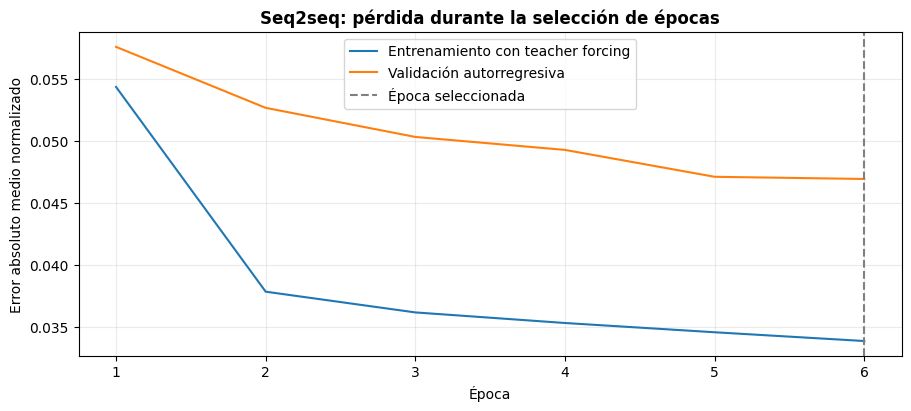

Pronósticos evaluados: 220,800
Pesos finales guardados en data/processed/seq2seq_calendar.pt.
MAPE no está definido para todo el panel porque existen consumos reales en cero.


In [10]:
class DecoderCalendarDataset(Dataset):
    def __init__(self, window_dataset):
        self.window_dataset = window_dataset

    def __len__(self):
        return len(self.window_dataset)

    def __getitem__(self, example_index):
        (history_windows, future_calendars), targets = self.__getitems__([example_index])
        return (history_windows[0], future_calendars[0]), targets[0]

    def __getitems__(self, example_indices):
        history_windows, targets = self.window_dataset.__getitems__(example_indices)
        batch_indices = torch.as_tensor(example_indices, dtype=torch.long)
        target_positions = self.window_dataset.target_positions[
            batch_indices // self.window_dataset.client_count
        ]
        future_positions = target_positions[:, None] + self.window_dataset.target_offsets
        future_calendars = self.window_dataset.calendar_values[future_positions]
        return (history_windows, future_calendars), targets


class CalendarSeq2SeqNetwork(nn.Module):
    def __init__(self, feature_count=8, calendar_feature_count=7, hidden_size=32, horizon_length=24):
        super().__init__()
        self.horizon_length = horizon_length
        self.encoder = nn.LSTM(feature_count, hidden_size, num_layers=1, batch_first=True)
        self.decoder = nn.LSTM(1 + calendar_feature_count, hidden_size, num_layers=1, batch_first=True)
        self.output_dropout = nn.Dropout(0.1)
        self.output_projection = nn.Linear(hidden_size, 1)

    def forward(self, history_windows, future_calendars, teacher_forcing_targets=None):
        assert future_calendars.shape[1] == self.horizon_length
        encoder_outputs, decoder_states = self.encoder(history_windows)
        last_consumption = history_windows[:, -1, 0:1]
        if teacher_forcing_targets is not None:
            if not self.training:
                raise ValueError("Teacher forcing se permite únicamente durante entrenamiento.")
            assert teacher_forcing_targets.shape == (len(history_windows), self.horizon_length)
            previous_consumptions = torch.cat(
                [last_consumption, teacher_forcing_targets[:, :-1]], dim=1
            ).unsqueeze(-1)
            decoder_inputs = torch.cat([previous_consumptions, future_calendars], dim=-1)
            decoder_outputs, final_states = self.decoder(decoder_inputs, decoder_states)
            return self.output_projection(self.output_dropout(decoder_outputs)).squeeze(-1)

        previous_consumption = last_consumption
        predictions = []
        for horizon_position in range(self.horizon_length):
            decoder_input = torch.cat([
                previous_consumption, future_calendars[:, horizon_position, :]
            ], dim=1).unsqueeze(1)
            decoder_output, decoder_states = self.decoder(decoder_input, decoder_states)
            current_prediction = self.output_projection(
                self.output_dropout(decoder_output[:, -1, :])
            )
            predictions.append(current_prediction)
            previous_consumption = current_prediction
        return torch.cat(predictions, dim=1)


class Seq2SeqForecaster(LSTMForecaster):
    def __init__(self, scaler, training_reference, random_seed=123):
        super().__init__(scaler, training_reference, random_seed)
        self.model_name = "Seq2seq con calendario"

    def create_loader(self, window_dataset, shuffle):
        return DataLoader(
            DecoderCalendarDataset(window_dataset), batch_size=self.batch_size, shuffle=shuffle,
            generator=torch.Generator().manual_seed(self.random_seed),
            num_workers=0, collate_fn=keep_window_batch,
        )

    def initialize_network(self, feature_count):
        torch.manual_seed(self.random_seed)
        self.network = CalendarSeq2SeqNetwork(
            feature_count, feature_count - 1, self.hidden_size, self.horizon_length
        ).to(self.device)
        return torch.optim.AdamW(
            self.network.parameters(), lr=self.learning_rate, weight_decay=self.weight_decay
        )

    def train_epoch(self, loader, optimizer):
        self.network.train()
        total_loss = 0.0
        example_count = 0
        for batch_number, ((history_windows, future_calendars), target_windows) in enumerate(loader, start=1):
            history_windows = history_windows.to(self.device)
            future_calendars = future_calendars.to(self.device)
            target_windows = target_windows.to(self.device)
            optimizer.zero_grad(set_to_none=True)
            predictions = self.network(
                history_windows, future_calendars, teacher_forcing_targets=target_windows
            )
            loss = nn.functional.l1_loss(predictions, target_windows)
            if not torch.isfinite(loss).item():
                raise FloatingPointError("La pérdida de entrenamiento no es finita.")
            loss.backward()
            nn.utils.clip_grad_norm_(
                self.network.parameters(), self.gradient_clip_norm, error_if_nonfinite=True
            )
            optimizer.step()
            self.record_gpu_memory()
            total_loss += loss.item() * len(history_windows)
            example_count += len(history_windows)
            if batch_number % 500 == 0:
                print(f"Seq2seq: {example_count:,} de {len(loader.dataset):,} ventanas de la época.", flush=True)
        self.synchronize_device()
        return total_loss / example_count

    def evaluate_validation(self, loader):
        self.network.eval()
        total_normalized_error = 0.0
        total_original_error = 0.0
        total_scaled_error = 0.0
        scaled_error_count = 0
        example_count = 0
        client_count = len(self.client_columns)
        with torch.inference_mode():
            for (history_windows, future_calendars), target_windows in loader:
                predictions = self.network(
                    history_windows.to(self.device), future_calendars.to(self.device)
                ).cpu()
                absolute_errors = (predictions - target_windows).abs().numpy().astype(np.float64)
                client_positions = np.arange(
                    example_count, example_count + len(history_windows)
                ) % client_count
                original_errors = absolute_errors * self.original_unit_factors[client_positions, None]
                reference_errors = self.mase_reference[client_positions]
                valid_reference = np.isfinite(reference_errors) & (reference_errors > 0)
                total_normalized_error += absolute_errors.sum()
                total_original_error += original_errors.sum()
                total_scaled_error += (
                    original_errors[valid_reference] / reference_errors[valid_reference, None]
                ).sum()
                scaled_error_count += int(valid_reference.sum()) * self.horizon_length
                example_count += len(history_windows)
                self.record_gpu_memory()
        element_count = example_count * self.horizon_length
        return {
            "validation_loss": total_normalized_error / element_count,
            "validation_MAE_kWh": total_original_error / element_count,
            "validation_MASE": total_scaled_error / scaled_error_count if scaled_error_count else np.nan,
        }

    def predict(self, consumption_window, calendar_window, future_calendar):
        inference_start = perf_counter()
        assert consumption_window.columns.equals(self.client_columns)
        assert calendar_window.index.equals(consumption_window.index)
        assert future_calendar.columns.equals(self.calendar_columns)
        assert len(consumption_window) == self.window_length
        assert len(future_calendar) == self.horizon_length
        consumption_inputs = torch.from_numpy(
            consumption_window.to_numpy(dtype=np.float32).T.copy()
        ).unsqueeze(-1)
        calendar_inputs = torch.from_numpy(
            calendar_window.to_numpy(dtype=np.float32)
        ).unsqueeze(0).expand(len(self.client_columns), -1, -1)
        history_inputs = torch.cat([consumption_inputs, calendar_inputs], dim=-1).to(self.device)
        future_calendar_inputs = torch.from_numpy(
            future_calendar.to_numpy(dtype=np.float32)
        ).unsqueeze(0).expand(len(self.client_columns), -1, -1).to(self.device)
        self.network.eval()
        with torch.inference_mode():
            predictions = self.network(history_inputs, future_calendar_inputs).cpu().numpy().T
        self.record_gpu_memory()
        self.inference_seconds += perf_counter() - inference_start
        return pd.DataFrame(predictions, index=future_calendar.index, columns=self.client_columns)


assert len(selected_clients) == 100 and client_selection_seed == 123
seq2seq_model = Seq2SeqForecaster(electricity_scaler, electricity_train_original, random_seed=123)
seq2seq_backtest_start = perf_counter()
seq2seq_results = backtest(seq2seq_model, window_length=168, refit_monthly=False)
seq2seq_backtest_seconds = perf_counter() - seq2seq_backtest_start
seq2seq_total_parameters = sum(parameter.numel() for parameter in seq2seq_model.network.parameters())
seq2seq_trainable_parameters = sum(
    parameter.numel() for parameter in seq2seq_model.network.parameters() if parameter.requires_grad
)
seq2seq_configuration = pd.Series({
    "Modelo": "Seq2seq global con calendario en el decoder",
    "Clientes": len(selected_clients), "Semilla": 123,
    "Ventana (horas)": 168, "Horizonte (horas)": 24,
    "Variables históricas": 8, "Covariables futuras de calendario": 7,
    "Encoder": "LSTM, una capa, hidden size 32",
    "Decoder": "LSTM, una capa, hidden size 32",
    "Entrada de cada paso del decoder": "Consumo anterior y calendario de la hora objetivo",
    "Teacher forcing en entrenamiento": True,
    "Teacher forcing en validación y prueba": False,
    "Dropout antes de la salida": 0.1,
    "Optimizador": "AdamW", "Learning rate": seq2seq_model.learning_rate,
    "Weight decay": seq2seq_model.weight_decay, "Batch": seq2seq_model.batch_size,
    "Recorte de norma del gradiente": seq2seq_model.gradient_clip_norm,
    "Stride de entrenamiento (horas)": 1,
    "Máximo de épocas para selección": seq2seq_model.maximum_epochs,
    "Paciencia": seq2seq_model.patience, "Épocas del ajuste final": seq2seq_model.best_epoch,
    "Parámetros totales": seq2seq_total_parameters,
    "Parámetros entrenables": seq2seq_trainable_parameters,
    "Hardware": f"{seq2seq_model.device} | {platform.system()} | {platform.machine()}",
    "PyTorch": str(torch.__version__),
}, name="Configuración")
seq2seq_results["resources"] = pd.Series({
    "Selección y ajuste final (s)": seq2seq_model.fit_seconds,
    "Inferencia de los 92 orígenes (s)": seq2seq_model.inference_seconds,
    "Backtest completo (s)": seq2seq_backtest_seconds,
    "Memoria GPU del controlador, máxima observada (MiB)": seq2seq_model.peak_gpu_memory_bytes / 1024**2,
}, name="Recursos")
seq2seq_results["selection_history"] = seq2seq_model.selection_history.copy()
seq2seq_results["final_training_history"] = seq2seq_model.final_training_history.copy()
seq2seq_artifact_directory = Path("data/processed")
seq2seq_artifact_directory.mkdir(parents=True, exist_ok=True)
seq2seq_checkpoint_path = seq2seq_artifact_directory / "seq2seq_calendar.pt"
torch.save({
    "state_dict": seq2seq_model.training_state,
    "window_length": 168, "feature_count": 8, "calendar_feature_count": 7,
    "horizon_length": 24, "hidden_size": 32, "num_layers": 1, "output_dropout": 0.1,
    "strategy": "encoder_decoder", "teacher_forcing_train_only": True,
    "client_columns": selected_clients.tolist(),
    "calendar_columns": calendar_train.columns.tolist(),
    "seed": 123, "selected_epochs": seq2seq_model.best_epoch,
    "minmax_scale": torch.from_numpy(electricity_scaler.scale_.copy()),
    "minmax_min": torch.from_numpy(electricity_scaler.min_.copy()),
    "torch_version": str(torch.__version__),
}, seq2seq_checkpoint_path)
seq2seq_model.selection_history.to_csv(seq2seq_artifact_directory / "seq2seq_selection_history.csv", index=False)
seq2seq_model.final_training_history.to_csv(seq2seq_artifact_directory / "seq2seq_final_training_history.csv", index=False)

display(seq2seq_configuration.to_frame())
print("Selección de épocas con validación sin teacher forcing")
display(seq2seq_model.selection_history.round(5))
print("Ajuste final con entrenamiento y validación")
display(seq2seq_model.final_training_history.round(5))
display(seq2seq_results["resources"].to_frame().round(4))
print("Métricas generales en prueba")
display(seq2seq_results["overall_metrics"].to_frame("Seq2seq").T.round(4))
for report_title, report_key in (
    ("Métricas por cliente", "metrics_by_client"),
    ("Métricas por paso del horizonte", "metrics_by_horizon"),
    ("Métricas por hora del día", "metrics_by_hour"),
):
    print(report_title)
    display(seq2seq_results[report_key].round(4))
print("Métricas de la semana del 22 al 28 de diciembre")
display(seq2seq_results["christmas_week_metrics"].to_frame("Seq2seq").T.round(4))
seq2seq_loss_figure, seq2seq_loss_axis = plt.subplots(figsize=(9, 4), layout="constrained")
seq2seq_loss_axis.plot(seq2seq_model.selection_history["epoch"], seq2seq_model.selection_history["training_loss"], label="Entrenamiento con teacher forcing")
seq2seq_loss_axis.plot(seq2seq_model.selection_history["epoch"], seq2seq_model.selection_history["validation_loss"], label="Validación autorregresiva")
seq2seq_loss_axis.axvline(seq2seq_model.best_epoch, linestyle="--", color="gray", label="Época seleccionada")
seq2seq_loss_axis.set_title("Seq2seq: pérdida durante la selección de épocas", fontweight="bold")
seq2seq_loss_axis.set(xlabel="Época", ylabel="Error absoluto medio normalizado")
seq2seq_loss_axis.legend()
seq2seq_loss_axis.grid(alpha=0.25)
plt.show()
print(f"Pronósticos evaluados: {len(seq2seq_results['forecasts']):,}")
print(f"Pesos finales guardados en {seq2seq_checkpoint_path}.")
if seq2seq_results["overall_metrics"]["zero_actual_count"] > 0:
    print("MAPE no está definido para todo el panel porque existen consumos reales en cero.")


### **N-HiTS global**

Se utilizará N-HiTS para observar las mismas 168 horas con distintas resoluciones. Los primeros bloques trabajan con una vista más agrupada y los siguientes conservan mayor detalle. Cada bloque busca explicar lo que queda del historial y aporta una parte al pronóstico final de 24 horas.

- **Arquitectura:** Se utilizará NeuralForecast con tres bloques, cada uno con dos capas ocultas de 128 neuronas y activación ReLU. El pooling promedio agrupa 4, 2 y 1 horas, respectivamente. Las salidas parciales se construyen con resoluciones diferentes y se interpolan para obtener los 24 valores horarios.
- **Entradas:** Consumo histórico normalizado y siete variables de calendario, tanto históricas como futuras conocidas. Se conserva el MinMax por cliente ajustado únicamente con entrenamiento y se desactiva cualquier escalamiento adicional de la biblioteca.
- **Configuración inicial:** Semilla 123, Adam con learning rate de 0.001, dropout de 0.1 y recorte de norma a 1. Se cargarán cuatro clientes por lote y se muestrearán 1024 ventanas por paso para limitar el uso de memoria. Las ventanas disponibles se desplazan una hora.
- **Selección y ajuste final:** Se realizarán hasta 1000 pasos de actualización, con validación cada 100 y paciencia de tres controles. Aquí se cuentan pasos del optimizador, no épocas completas. La selección utiliza entrenamiento hasta junio y validación de julio a septiembre. Después se reinicializa la misma arquitectura y se ajusta hasta septiembre con el número de pasos elegido.
- **Evaluación:** Se mantiene el mismo backtest diario y los mismos 100 clientes. Los pesos quedan fijos durante prueba; cada entrada contiene únicamente consumo histórico y calendario conocido. Se verificará que la inferencia directa del modelo coincida con la salida de NeuralForecast.
- **Registro:** Se guardarán pérdidas por paso, MAE y MASE de validación en cada control, parámetros, recursos, pronósticos de prueba y el modelo final. La curva de entrenamiento muestra una media móvil de 100 pasos para facilitar su lectura.

Seed set to 123


N-HiTS: selección con entrenamiento hasta junio y validación de julio a septiembre en mps.


GPU available: True (mps), used: True


TPU available: False, using: 0 TPU cores


/Users/bryan/VirtualEnv/venv/lib/python3.13/site-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


...

,MAE_kWh,RMSE_kWh,WAPE_pct,MAPE_pct,zero_actual_count
horizon_step,,,,,
1,36.5375,160.9360,9.1428,NaN,17
2,44.3057,211.3882,12.3881,NaN,42
3,40.4723,182.2200,11.6532,NaN,43
4,45.0719,217.5047,13.0034,NaN,29
5,45.6564,216.8323,13.3705,NaN,30
6,45.8399,199.6315,13.2707,NaN,29
7,49.7393,206.9616,13.0281,NaN,29
8,57.6573,251.9069,12.8678,NaN,35
9,57.2930,214.1605,12.6149,NaN,90


Métricas por hora del día


,MAE_kWh,RMSE_kWh,WAPE_pct,MAPE_pct,zero_actual_count
hour_of_day,,,,,
0,36.5375,160.9360,9.1428,NaN,17
1,44.3057,211.3882,12.3881,NaN,42
2,40.4723,182.2200,11.6532,NaN,43
3,45.0719,217.5047,13.0034,NaN,29
4,45.6564,216.8323,13.3705,NaN,30
5,45.8399,199.6315,13.2707,NaN,29
6,49.7393,206.9616,13.0281,NaN,29
7,57.6573,251.9069,12.8678,NaN,35
8,57.2930,214.1605,12.6149,NaN,90


Métricas de la semana del 22 al 28 de diciembre


,MAE_kWh,RMSE_kWh,WAPE_pct,MAPE_pct,zero_actual_count
N-HiTS,87.2242,458.2765,18.3618,NaN,353.0


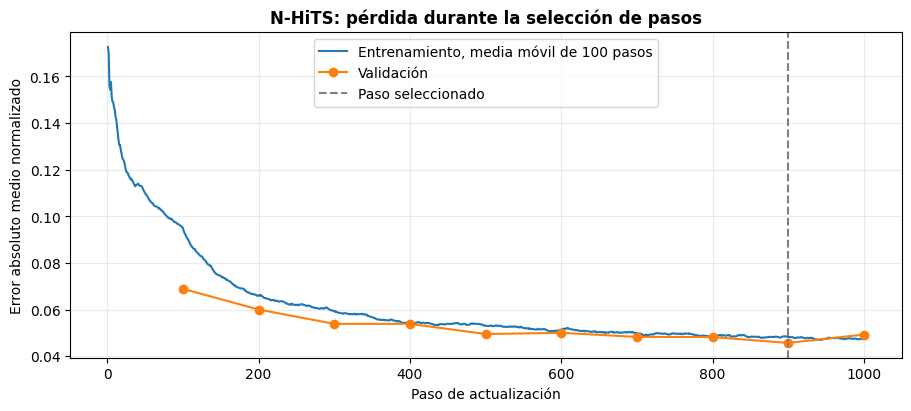

Pronósticos evaluados: 220,800
Modelo final guardado en data/processed/nhits_model.
MAPE no está definido para todo el panel porque existen consumos reales en cero.


In [8]:
from pathlib import Path
from time import perf_counter
import platform

import matplotlib.pyplot as plt
import neuralforecast
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from neuralforecast import NeuralForecast
from neuralforecast.losses.pytorch import MAE
from neuralforecast.models import NHITS
from pytorch_lightning import Callback


def build_nhits_inputs(history_windows, future_calendar_windows, device):
    consumption_inputs = history_windows[:, :, :1].to(device)
    return {
        "insample_y": consumption_inputs,
        "insample_mask": torch.ones_like(consumption_inputs),
        "futr_exog": torch.cat([
            history_windows[:, :, 1:], future_calendar_windows
        ], dim=1).to(device),
        "hist_exog": None,
        "stat_exog": None,
    }


class NHITSTrainingMonitor(Callback):
    def __init__(self, forecaster, stage):
        self.forecaster = forecaster
        self.stage = stage
        self.records = []
        self.validation_records = []

    def on_train_batch_end(self, trainer, model, outputs, batch, batch_idx):
        step_number = int(trainer.global_step)
        training_loss = float(model.train_trajectories[-1][1])
        if not np.isfinite(training_loss):
            raise FloatingPointError("La pérdida de N-HiTS no es finita.")
        self.records.append({"step": step_number, "training_loss": training_loss})
        self.forecaster.record_gpu_memory()
        if step_number % 100 == 0:
            print(f"{self.forecaster.model_name} · {self.stage}: paso {step_number}, train={training_loss:.5f}.", flush=True)

    def on_validation_end(self, trainer, model):
        if trainer.sanity_checking or model.val_size == 0:
            return
        step_number, validation_loss = model.valid_trajectories[-1]
        validation_metrics = self.forecaster.evaluate_validation(model)
        np.testing.assert_allclose(
            validation_metrics["validation_loss"], validation_loss, rtol=0.0001, atol=0.000001
        )
        self.validation_records.append({"step": int(step_number), **validation_metrics})
        print(
            f"{self.forecaster.model_name} · validación en paso {step_number}: val={validation_loss:.5f}, "
            f"MAE={validation_metrics['validation_MAE_kWh']:.2f} kWh, "
            f"MASE={validation_metrics['validation_MASE']:.3f}.", flush=True,
        )


class NHITSForecaster:
    def __init__(self, scaler, training_reference, random_seed=123):
        self.scaler = scaler
        self.model_name = "N-HiTS"
        self.random_seed = random_seed
        self.window_length = 168
        self.horizon_length = 24
        self.maximum_steps = 1000
        self.validation_check_steps = 100
        self.patience = 3
        self.series_batch_size = 4
        self.windows_batch_size = 1024
        self.validation_batch_size = 2048
        self.device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
        self.original_unit_factors = 1 / scaler.scale_
        self.mase_reference = training_reference.diff(24).abs().mean().to_numpy()
        self.best_step = None
        self.fit_seconds = 0.0
        self.inference_seconds = 0.0
        self.peak_gpu_memory_bytes = 0

    def record_gpu_memory(self):
        if self.device.type == "mps":
            self.peak_gpu_memory_bytes = max(
                self.peak_gpu_memory_bytes, torch.mps.driver_allocated_memory()
            )

    def to_long_panel(self, consumption, calendar):
        assert consumption.index.equals(calendar.index)
        assert consumption.columns.equals(self.client_columns)
        panel = consumption.rename_axis("ds").reset_index().melt(
            id_vars="ds", var_name="unique_id", value_name="y"
        )
        panel = panel.merge(calendar.rename_axis("ds").reset_index(), on="ds", validate="many_to_one")
        numeric_columns = ["y", *self.calendar_columns]
        panel[numeric_columns] = panel[numeric_columns].astype(np.float32)
        assert not panel.duplicated(["unique_id", "ds"]).any()
        return panel

    def create_forecast_model(self, maximum_steps, monitor, selecting):
        network = NHITS(
            h=self.horizon_length, input_size=self.window_length,
            futr_exog_list=self.calendar_columns.tolist(),
            n_blocks=[1, 1, 1], mlp_units=[[128, 128], [128, 128], [128, 128]],
            n_pool_kernel_size=[4, 2, 1], n_freq_downsample=[4, 2, 1],
            pooling_mode="AvgPool1d", interpolation_mode="linear", dropout_prob_theta=0.1,
            loss=MAE(), valid_loss=MAE(), learning_rate=0.001, num_lr_decays=0,
            max_steps=maximum_steps, val_check_steps=min(self.validation_check_steps, maximum_steps),
            early_stop_patience_steps=self.patience if selecting else -1,
            batch_size=self.series_batch_size, valid_batch_size=self.series_batch_size,
            windows_batch_size=self.windows_batch_size, inference_windows_batch_size=1024,
            step_size=1, start_padding_enabled=False, training_data_availability_threshold=1.0,
            scaler_type="identity", random_seed=self.random_seed, alias="NHiTS",
            accelerator=self.device.type, devices=1, precision="32-true",
            gradient_clip_val=1.0, logger=False, enable_checkpointing=False,
            enable_progress_bar=False, enable_model_summary=False, num_sanity_val_steps=0,
            dataloader_kwargs={"num_workers": 0},
        )
        forecast_model = NeuralForecast(models=[network], freq="h", local_scaler_type=None)
        forecast_model.models[0].trainer_kwargs.setdefault("callbacks", []).append(monitor)
        return forecast_model

    def evaluate_validation(self, network):
        validation_loader = DataLoader(
            self.validation_dataset, batch_size=self.validation_batch_size, shuffle=False,
            num_workers=0, collate_fn=keep_window_batch,
        )
        client_count = len(self.client_columns)
        normalized_error_sum = 0.0
        original_error_sum = 0.0
        scaled_error_sum = 0.0
        scaled_error_count = 0
        example_count = 0
        with torch.inference_mode():
            for history_windows, target_windows in validation_loader:
                example_positions = torch.arange(example_count, example_count + len(history_windows))
                target_positions = self.validation_dataset.target_positions[example_positions // client_count]
                calendar_positions = target_positions[:, None] + self.validation_dataset.target_offsets
                future_calendar_windows = self.validation_dataset.calendar_values[calendar_positions]
                predictions = network(build_nhits_inputs(
                    history_windows, future_calendar_windows, self.device
                )).squeeze(-1).cpu()
                absolute_errors = (predictions - target_windows).abs().numpy().astype(np.float64)
                client_positions = example_positions.numpy() % client_count
                original_errors = absolute_errors * self.original_unit_factors[client_positions, None]
                reference_errors = self.mase_reference[client_positions]
                valid_reference = np.isfinite(reference_errors) & (reference_errors > 0)
                normalized_error_sum += absolute_errors.sum()
                original_error_sum += original_errors.sum()
                scaled_error_sum += (
                    original_errors[valid_reference] / reference_errors[valid_reference, None]
                ).sum()
                scaled_error_count += int(valid_reference.sum()) * self.horizon_length
                example_count += len(history_windows)
                self.record_gpu_memory()
        element_count = example_count * self.horizon_length
        return {
            "validation_loss": normalized_error_sum / element_count,
            "validation_MAE_kWh": original_error_sum / element_count,
            "validation_MASE": scaled_error_sum / scaled_error_count if scaled_error_count else np.nan,
        }

    def fit(self, consumption_history, calendar_history):
        fit_start = perf_counter()
        self.client_columns = consumption_history.columns.copy()
        self.calendar_columns = calendar_history.columns.copy()
        assert pd.Index(self.scaler.feature_names_in_).equals(self.client_columns)
        assert consumption_history.index.equals(calendar_history.index)
        torch.set_num_threads(4)
        long_panel = self.to_long_panel(consumption_history, calendar_history)

        if self.best_step is None:
            validation_start = pd.Timestamp("2014-07-01")
            validation_end = pd.Timestamp("2014-09-30 23:00")
            assert consumption_history.index.max() == validation_end
            validation_size = int((consumption_history.index >= validation_start).sum())
            assert validation_size == len(electricity_val)
            assert consumption_history.index[-validation_size - 1] == electricity_train.index.max()
            self.validation_dataset = PanelWindowDataset(
                consumption_history, calendar_history, validation_start, validation_end,
                window_length=self.window_length, horizon_length=self.horizon_length,
            )
            selection_monitor = NHITSTrainingMonitor(self, "selección")
            selection_forecast = self.create_forecast_model(self.maximum_steps, selection_monitor, selecting=True)
            print(f"{self.model_name}: selección con entrenamiento hasta junio y validación de julio a septiembre en {self.device}.", flush=True)
            selection_forecast.fit(df=long_panel, val_size=validation_size)
            self.selection_training_history = pd.DataFrame(selection_monitor.records)
            self.selection_history = pd.DataFrame(selection_monitor.validation_records)
            assert not self.selection_history.empty
            assert np.isfinite(self.selection_history["validation_loss"]).all()
            self.best_step = int(self.selection_history.loc[
                self.selection_history["validation_loss"].idxmin(), "step"
            ])
            del selection_forecast
            del self.validation_dataset
            if self.device.type == "mps":
                torch.mps.empty_cache()

        final_monitor = NHITSTrainingMonitor(self, "ajuste final")
        self.forecast_model = self.create_forecast_model(self.best_step, final_monitor, selecting=False)
        print(f"{self.model_name}: ajuste final hasta {consumption_history.index.max()}, {self.best_step} pasos.", flush=True)
        self.forecast_model.fit(df=long_panel, val_size=0)
        self.final_training_history = pd.DataFrame(final_monitor.records)
        self.network = self.forecast_model.models[0].to(self.device).eval()
        self.training_state = {
            parameter_name: parameter.detach().cpu().clone()
            for parameter_name, parameter in self.network.state_dict().items()
        }
        assert not self.forecast_model.scalers_
        self.record_gpu_memory()
        self.fit_seconds += perf_counter() - fit_start
        return self

    def predict(self, consumption_window, calendar_window, future_calendar):
        inference_start = perf_counter()
        assert consumption_window.columns.equals(self.client_columns)
        assert calendar_window.index.equals(consumption_window.index)
        assert calendar_window.columns.equals(self.calendar_columns)
        assert future_calendar.columns.equals(self.calendar_columns)
        assert len(consumption_window) == self.window_length
        assert len(future_calendar) == self.horizon_length
        assert future_calendar.index[0] == consumption_window.index[-1] + pd.Timedelta(hours=1)
        client_count = len(self.client_columns)
        consumption_inputs = torch.from_numpy(
            consumption_window.to_numpy(dtype=np.float32).T.copy()
        ).unsqueeze(-1)
        calendar_inputs = torch.from_numpy(
            calendar_window.to_numpy(dtype=np.float32)
        ).unsqueeze(0).expand(client_count, -1, -1)
        history_inputs = torch.cat([consumption_inputs, calendar_inputs], dim=-1)
        future_inputs = torch.from_numpy(
            future_calendar.to_numpy(dtype=np.float32)
        ).unsqueeze(0).expand(client_count, -1, -1)
        self.network.eval()
        with torch.inference_mode():
            predictions = self.network(build_nhits_inputs(
                history_inputs, future_inputs, self.device
            )).squeeze(-1).cpu().numpy().T
        self.record_gpu_memory()
        self.inference_seconds += perf_counter() - inference_start
        return pd.DataFrame(predictions, index=future_calendar.index, columns=self.client_columns)


assert len(selected_clients) == 100 and client_selection_seed == 123
nhits_model = NHITSForecaster(electricity_scaler, electricity_train_original, random_seed=123)
nhits_backtest_start = perf_counter()
nhits_results = backtest(nhits_model, window_length=168, refit_monthly=False)
nhits_backtest_seconds = perf_counter() - nhits_backtest_start
nhits_total_parameters = sum(parameter.numel() for parameter in nhits_model.network.parameters())
nhits_trainable_parameters = sum(
    parameter.numel() for parameter in nhits_model.network.parameters() if parameter.requires_grad
)
nhits_configuration = pd.Series({
    "Modelo": "N-HiTS global", "Biblioteca": f"NeuralForecast {neuralforecast.__version__}",
    "Clientes": len(selected_clients), "Semilla": 123,
    "Ventana (horas)": 168, "Horizonte (horas)": 24,
    "Bloques": "3, uno por resolución", "Capas ocultas por bloque": "128 y 128, ReLU",
    "Pooling promedio": "4, 2 y 1", "Reducción de resolución de salida": "4, 2 y 1",
    "Interpolación": "Lineal", "Dropout": 0.1,
    "Covariables": "Calendario histórico y futuro conocido",
    "Escalamiento adicional": "Ninguno; MinMax previo ajustado solo con entrenamiento",
    "Learning rate": 0.001, "Optimizador": "Adam", "Recorte de norma": 1.0,
    "Series por lote": nhits_model.series_batch_size,
    "Ventanas muestreadas por paso": nhits_model.windows_batch_size,
    "Stride de ventanas (horas)": 1, "Máximo de pasos": nhits_model.maximum_steps,
    "Validación cada N pasos": nhits_model.validation_check_steps,
    "Paciencia (controles de validación)": nhits_model.patience,
    "Pasos seleccionados": nhits_model.best_step,
    "Parámetros totales": nhits_total_parameters,
    "Parámetros entrenables": nhits_trainable_parameters,
    "Hardware": f"{nhits_model.device} | {platform.system()} | {platform.machine()}",
}, name="Configuración")
nhits_results["resources"] = pd.Series({
    "Selección y ajuste final (s)": nhits_model.fit_seconds,
    "Inferencia de los 92 orígenes (s)": nhits_model.inference_seconds,
    "Backtest completo (s)": nhits_backtest_seconds,
    "Memoria GPU del controlador, máxima observada (MiB)": nhits_model.peak_gpu_memory_bytes / 1024**2,
}, name="Recursos")
nhits_results["selection_history"] = nhits_model.selection_history.copy()
nhits_results["final_training_history"] = nhits_model.final_training_history.copy()
nhits_artifact_directory = Path("data/processed")
nhits_artifact_directory.mkdir(parents=True, exist_ok=True)
nhits_checkpoint_directory = nhits_artifact_directory / "nhits_model"
nhits_model.forecast_model.save(str(nhits_checkpoint_directory), save_dataset=False, overwrite=True)
torch.save({
    "state_dict": nhits_model.training_state,
    "window_length": 168, "horizon_length": 24, "seed": 123,
    "selected_steps": nhits_model.best_step,
    "client_columns": selected_clients.tolist(),
    "calendar_columns": calendar_train.columns.tolist(),
    "minmax_scale": torch.from_numpy(electricity_scaler.scale_.copy()),
    "minmax_min": torch.from_numpy(electricity_scaler.min_.copy()),
    "neuralforecast_version": str(neuralforecast.__version__),
}, nhits_artifact_directory / "nhits_panel_metadata.pt")
nhits_model.selection_history.to_csv(nhits_artifact_directory / "nhits_selection_history.csv", index=False)
nhits_model.selection_training_history.to_csv(nhits_artifact_directory / "nhits_selection_training_history.csv", index=False)
nhits_model.final_training_history.to_csv(nhits_artifact_directory / "nhits_final_training_history.csv", index=False)
nhits_results["forecasts"].to_csv(nhits_artifact_directory / "nhits_test_forecasts.csv", index=False)

display(nhits_configuration.to_frame())
print("Selección de pasos mediante validación")
display(nhits_model.selection_history.round(5))
display(nhits_results["resources"].to_frame().round(4))
print("Métricas generales en prueba")
display(nhits_results["overall_metrics"].to_frame("N-HiTS").T.round(4))
for report_title, report_key in (
    ("Métricas por cliente", "metrics_by_client"),
    ("Métricas por paso del horizonte", "metrics_by_horizon"),
    ("Métricas por hora del día", "metrics_by_hour"),
):
    print(report_title)
    display(nhits_results[report_key].round(4))
print("Métricas de la semana del 22 al 28 de diciembre")
display(nhits_results["christmas_week_metrics"].to_frame("N-HiTS").T.round(4))
nhits_loss_figure, nhits_loss_axis = plt.subplots(figsize=(9, 4), layout="constrained")
nhits_smoothed_training = nhits_model.selection_training_history["training_loss"].rolling(100, min_periods=1).mean()
nhits_loss_axis.plot(nhits_model.selection_training_history["step"], nhits_smoothed_training, label="Entrenamiento, media móvil de 100 pasos")
nhits_loss_axis.plot(nhits_model.selection_history["step"], nhits_model.selection_history["validation_loss"], marker="o", label="Validación")
nhits_loss_axis.axvline(nhits_model.best_step, linestyle="--", color="gray", label="Paso seleccionado")
nhits_loss_axis.set_title("N-HiTS: pérdida durante la selección de pasos", fontweight="bold")
nhits_loss_axis.set(xlabel="Paso de actualización", ylabel="Error absoluto medio normalizado")
nhits_loss_axis.legend()
nhits_loss_axis.grid(alpha=0.25)
plt.show()
print(f"Pronósticos evaluados: {len(nhits_results['forecasts']):,}")
print(f"Modelo final guardado en {nhits_checkpoint_directory}.")
if nhits_results["overall_metrics"]["zero_actual_count"] > 0:
    print("MAPE no está definido para todo el panel porque existen consumos reales en cero.")


### **TCN global**

Se utilizará una TCN para aprender patrones sobre el consumo mediante convoluciones causales con dilataciones crecientes. Cada capa combina información que puede abarcar un intervalo mayor, y después una proyección temporal y un MLP producen directamente las 24 predicciones.

- **Arquitectura:** Se utilizará NeuralForecast con kernel de 3, siete capas convolucionales de 32 canales y dilataciones de 1, 2, 4, 8, 16, 32 y 64. Se mantiene activación ReLU y un decoder con capa oculta de 64 neuronas.
- **Campo receptivo:** El encoder tendrá un alcance teórico de 255 horas por posición, suficiente para cubrir las 168 horas disponibles. La entrada sigue conteniendo únicamente esas 168 horas reales. El padding causal conserva la longitud de la secuencia y completa el inicio donde falta historia.
- **Entradas:** Consumo histórico y siete variables de calendario, con calendario futuro conocido para las horas que se pronostican. Se conserva el MinMax por cliente ajustado únicamente con entrenamiento y se desactiva el escalamiento adicional de NeuralForecast.
- **Configuración inicial:** Semilla 123, Adam con learning rate de 0.001 y recorte de norma a 1. Se cargarán cuatro clientes por lote y se muestrearán 128 ventanas por paso, manteniendo un desplazamiento de una hora entre las ventanas disponibles.
- **Selección y ajuste final:** Se realizarán hasta 1000 pasos de actualización, con validación cada 100 y paciencia de tres controles. Se reutiliza el adaptador de NeuralForecast para seleccionar los pasos con entrenamiento hasta junio y validación de julio a septiembre, y después reinicializar el modelo para ajustarlo hasta septiembre con la duración seleccionada.
- **Evaluación:** Se mantienen los mismos 100 clientes y el mismo backtest de 92 días, con ventana de 168 horas y horizonte de 24. Los pesos quedan fijos durante prueba y cada entrada se construye con información disponible al emitir el pronóstico.
- **Registro:** Se guardarán pérdidas por paso, MAE y MASE de validación, parámetros, recursos, pronósticos y el modelo final. Se verificará la causalidad del encoder y que la inferencia coincida con NeuralForecast. La curva de entrenamiento utiliza una media móvil de 100 pasos para facilitar su lectura.

Seed set to 123


TCN: selección con entrenamiento hasta junio y validación de julio a septiembre en mps.


GPU available: True (mps), used: True


TPU available: False, using: 0 TPU cores


/Users/bryan/VirtualEnv/venv/lib/python3.13/site-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


...

,MAE_kWh,RMSE_kWh,WAPE_pct,MAPE_pct,zero_actual_count
horizon_step,,,,,
1,48.5218,153.7079,12.1417,NaN,17
2,45.4350,183.5914,12.7038,NaN,42
3,40.6026,164.4417,11.6908,NaN,43
4,49.3905,210.1980,14.2494,NaN,29
5,42.8675,166.9803,12.5538,NaN,30
6,46.4909,171.3781,13.4591,NaN,29
7,43.6569,161.4981,11.4349,NaN,29
8,54.9543,204.3067,12.2645,NaN,35
9,67.1389,219.0908,14.7828,NaN,90


Métricas por hora del día


,MAE_kWh,RMSE_kWh,WAPE_pct,MAPE_pct,zero_actual_count
hour_of_day,,,,,
0,48.5218,153.7079,12.1417,NaN,17
1,45.4350,183.5914,12.7038,NaN,42
2,40.6026,164.4417,11.6908,NaN,43
3,49.3905,210.1980,14.2494,NaN,29
4,42.8675,166.9803,12.5538,NaN,30
5,46.4909,171.3781,13.4591,NaN,29
6,43.6569,161.4981,11.4349,NaN,29
7,54.9543,204.3067,12.2645,NaN,35
8,67.1389,219.0908,14.7828,NaN,90


Métricas de la semana del 22 al 28 de diciembre


,MAE_kWh,RMSE_kWh,WAPE_pct,MAPE_pct,zero_actual_count
TCN,82.8409,444.7423,17.4391,NaN,353.0


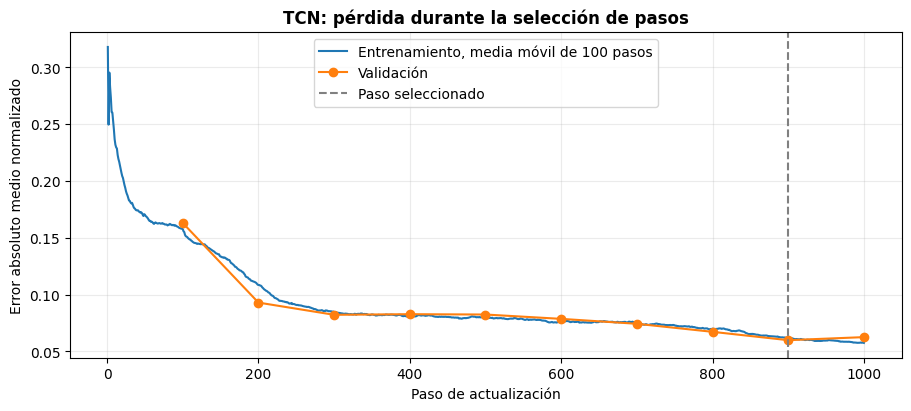

Pronósticos evaluados: 220,800
Modelo final guardado en data/processed/tcn_model.
MAPE no está definido para todo el panel porque existen consumos reales en cero.


In [9]:
from neuralforecast.models import TCN


class TCNForecaster(NHITSForecaster):
    def __init__(self, scaler, training_reference, random_seed=123):
        super().__init__(scaler, training_reference, random_seed)
        self.model_name = "TCN"
        self.kernel_size = 3
        self.dilations = [1, 2, 4, 8, 16, 32, 64]
        self.encoder_hidden_size = 32
        self.decoder_hidden_size = 64
        self.windows_batch_size = 128
        self.validation_batch_size = 256

    def create_forecast_model(self, maximum_steps, monitor, selecting):
        network = TCN(
            h=self.horizon_length, input_size=self.window_length,
            kernel_size=self.kernel_size, dilations=self.dilations,
            encoder_hidden_size=self.encoder_hidden_size, encoder_activation="ReLU",
            decoder_hidden_size=self.decoder_hidden_size, decoder_layers=2,
            futr_exog_list=self.calendar_columns.tolist(),
            loss=MAE(), valid_loss=MAE(), learning_rate=0.001, num_lr_decays=0,
            max_steps=maximum_steps, val_check_steps=min(self.validation_check_steps, maximum_steps),
            early_stop_patience_steps=self.patience if selecting else -1,
            batch_size=self.series_batch_size, valid_batch_size=self.series_batch_size,
            windows_batch_size=self.windows_batch_size,
            inference_windows_batch_size=self.validation_batch_size,
            step_size=1, start_padding_enabled=False, training_data_availability_threshold=1.0,
            scaler_type="identity", random_seed=self.random_seed, alias="TCN",
            accelerator=self.device.type, devices=1, precision="32-true",
            gradient_clip_val=1.0, logger=False, enable_checkpointing=False,
            enable_progress_bar=False, enable_model_summary=False, num_sanity_val_steps=0,
            dataloader_kwargs={"num_workers": 0},
        )
        forecast_model = NeuralForecast(models=[network], freq="h", local_scaler_type=None)
        forecast_model.models[0].trainer_kwargs.setdefault("callbacks", []).append(monitor)
        return forecast_model


assert len(selected_clients) == 100 and client_selection_seed == 123
tcn_model = TCNForecaster(electricity_scaler, electricity_train_original, random_seed=123)
tcn_backtest_start = perf_counter()
tcn_results = backtest(tcn_model, window_length=168, refit_monthly=False)
tcn_backtest_seconds = perf_counter() - tcn_backtest_start
tcn_total_parameters = sum(parameter.numel() for parameter in tcn_model.network.parameters())
tcn_trainable_parameters = sum(
    parameter.numel() for parameter in tcn_model.network.parameters() if parameter.requires_grad
)
tcn_convolutions = [
    layer for layer in tcn_model.network.hist_encoder.modules() if isinstance(layer, torch.nn.Conv1d)
]
tcn_receptive_field = 1 + sum(
    (convolution.kernel_size[0] - 1) * convolution.dilation[0]
    for convolution in tcn_convolutions
)
assert tcn_receptive_field == 255
tcn_configuration = pd.Series({
    "Modelo": "TCN global", "Biblioteca": f"NeuralForecast {neuralforecast.__version__}",
    "Clientes": len(selected_clients), "Semilla": 123,
    "Ventana (horas)": 168, "Horizonte (horas)": 24,
    "Kernel": tcn_model.kernel_size, "Capas convolucionales": len(tcn_convolutions),
    "Dilataciones": str(tcn_model.dilations),
    "Canales del encoder": tcn_model.encoder_hidden_size,
    "Campo receptivo convolucional teórico (horas)": tcn_receptive_field,
    "Historia real disponible (horas)": tcn_model.window_length,
    "Capa oculta del decoder": tcn_model.decoder_hidden_size,
    "Activación": "ReLU", "Salida": "24 pasos directos mediante adaptador temporal y MLP",
    "Covariables": "Calendario histórico y futuro conocido",
    "Escalamiento adicional": "Ninguno; MinMax previo ajustado solo con entrenamiento",
    "Learning rate": 0.001, "Optimizador": "Adam", "Recorte de norma": 1.0,
    "Series por lote": tcn_model.series_batch_size,
    "Ventanas muestreadas por paso": tcn_model.windows_batch_size,
    "Stride de ventanas (horas)": 1, "Máximo de pasos": tcn_model.maximum_steps,
    "Validación cada N pasos": tcn_model.validation_check_steps,
    "Paciencia (controles de validación)": tcn_model.patience,
    "Pasos seleccionados": tcn_model.best_step,
    "Parámetros totales": tcn_total_parameters,
    "Parámetros entrenables": tcn_trainable_parameters,
    "Hardware": f"{tcn_model.device} | {platform.system()} | {platform.machine()}",
}, name="Configuración")
tcn_results["resources"] = pd.Series({
    "Selección y ajuste final (s)": tcn_model.fit_seconds,
    "Inferencia de los 92 orígenes (s)": tcn_model.inference_seconds,
    "Backtest completo (s)": tcn_backtest_seconds,
    "Memoria GPU del controlador, máxima observada (MiB)": tcn_model.peak_gpu_memory_bytes / 1024**2,
}, name="Recursos")
tcn_results["selection_history"] = tcn_model.selection_history.copy()
tcn_results["final_training_history"] = tcn_model.final_training_history.copy()
tcn_artifact_directory = Path("data/processed")
tcn_artifact_directory.mkdir(parents=True, exist_ok=True)
tcn_checkpoint_directory = tcn_artifact_directory / "tcn_model"
tcn_model.forecast_model.save(str(tcn_checkpoint_directory), save_dataset=False, overwrite=True)
torch.save({
    "state_dict": tcn_model.training_state,
    "window_length": 168, "horizon_length": 24, "seed": 123,
    "kernel_size": tcn_model.kernel_size, "dilations": tcn_model.dilations,
    "encoder_hidden_size": tcn_model.encoder_hidden_size,
    "decoder_hidden_size": tcn_model.decoder_hidden_size,
    "selected_steps": tcn_model.best_step,
    "client_columns": selected_clients.tolist(),
    "calendar_columns": calendar_train.columns.tolist(),
    "minmax_scale": torch.from_numpy(electricity_scaler.scale_.copy()),
    "minmax_min": torch.from_numpy(electricity_scaler.min_.copy()),
    "neuralforecast_version": str(neuralforecast.__version__),
}, tcn_artifact_directory / "tcn_panel_metadata.pt")
tcn_model.selection_history.to_csv(tcn_artifact_directory / "tcn_selection_history.csv", index=False)
tcn_model.selection_training_history.to_csv(tcn_artifact_directory / "tcn_selection_training_history.csv", index=False)
tcn_model.final_training_history.to_csv(tcn_artifact_directory / "tcn_final_training_history.csv", index=False)
tcn_results["forecasts"].to_csv(tcn_artifact_directory / "tcn_test_forecasts.csv", index=False)

display(tcn_configuration.to_frame())
print("Selección de pasos mediante validación")
display(tcn_model.selection_history.round(5))
display(tcn_results["resources"].to_frame().round(4))
print("Métricas generales en prueba")
display(tcn_results["overall_metrics"].to_frame("TCN").T.round(4))
for report_title, report_key in (
    ("Métricas por cliente", "metrics_by_client"),
    ("Métricas por paso del horizonte", "metrics_by_horizon"),
    ("Métricas por hora del día", "metrics_by_hour"),
):
    print(report_title)
    display(tcn_results[report_key].round(4))
print("Métricas de la semana del 22 al 28 de diciembre")
display(tcn_results["christmas_week_metrics"].to_frame("TCN").T.round(4))
tcn_loss_figure, tcn_loss_axis = plt.subplots(figsize=(9, 4), layout="constrained")
tcn_smoothed_training = tcn_model.selection_training_history["training_loss"].rolling(100, min_periods=1).mean()
tcn_loss_axis.plot(tcn_model.selection_training_history["step"], tcn_smoothed_training, label="Entrenamiento, media móvil de 100 pasos")
tcn_loss_axis.plot(tcn_model.selection_history["step"], tcn_model.selection_history["validation_loss"], marker="o", label="Validación")
tcn_loss_axis.axvline(tcn_model.best_step, linestyle="--", color="gray", label="Paso seleccionado")
tcn_loss_axis.set_title("TCN: pérdida durante la selección de pasos", fontweight="bold")
tcn_loss_axis.set(xlabel="Paso de actualización", ylabel="Error absoluto medio normalizado")
tcn_loss_axis.legend()
tcn_loss_axis.grid(alpha=0.25)
plt.show()
print(f"Pronósticos evaluados: {len(tcn_results['forecasts']):,}")
print(f"Modelo final guardado en {tcn_checkpoint_directory}.")
if tcn_results["overall_metrics"]["zero_actual_count"] > 0:
    print("MAPE no está definido para todo el panel porque existen consumos reales en cero.")


### **PatchTST global**

Se utilizará PatchTST para agrupar las 168 horas históricas en segmentos y convertir cada uno en una representación numérica. Después, el encoder utiliza atención para aprender relaciones entre estos grupos y combina sus representaciones para producir las 24 predicciones.

- **Parches:** Se utilizarán segmentos de 24 horas con desplazamiento de 12 horas, ya que esto permite representar un día completo y mantener solapamiento entre grupos consecutivos. La biblioteca completa el último parche repitiendo el último consumo observado, por lo que se obtienen 14 parches y no se introducen consumos futuros reales.
- **Arquitectura:** Se utilizará NeuralForecast con dos capas de encoder, cuatro cabezas de atención, representaciones de 64 números y una capa feedforward intermedia de 128. Se mantendrá codificación posicional aprendida, activación GELU y dropout de 0.1 en el encoder y la salida.
- **Entradas:** Esta implementación utiliza únicamente consumo histórico. Cada cliente se procesa como una serie individual, pero se comparten los pesos entre los mismos 100 clientes del panel.
- **Normalización:** Se mantiene el MinMax por cliente ajustado únicamente con entrenamiento. Dentro del modelo se activa RevIN, calculando media y desviación solamente con las 168 horas históricas de cada ventana. Su transformación se revierte en la salida del modelo y después el evaluador deshace MinMax para calcular métricas en kWh. El escalador adicional de NeuralForecast queda desactivado.
- **Configuración inicial:** Semilla 123, Adam con learning rate de 0.0005 y recorte de norma a 1. Se cargarán cuatro clientes por lote y se muestrearán 256 ventanas por paso. El desplazamiento entre ventanas de entrenamiento sigue siendo de una hora; las 12 horas corresponden únicamente al desplazamiento de los parches internos.
- **Selección y ajuste final:** Se realizarán hasta 1000 pasos de actualización, con validación cada 100 y paciencia de tres controles. Se seleccionará la duración con entrenamiento hasta junio y validación de julio a septiembre, y después se reinicializará el modelo para ajustarlo hasta septiembre con los pasos seleccionados.
- **Evaluación:** Se conservarán ventana de 168 horas, horizonte de 24 y el mismo backtest de 92 días, con pesos fijos durante prueba. La atención puede relacionar todos los parches del historial, ya que cada uno contiene información disponible al emitir el pronóstico.
- **Registro:** Se guardarán pérdidas por paso, MAE y MASE de validación, parámetros, recursos, pronósticos y modelo final. Se verificará la construcción de parches, las estadísticas históricas de RevIN y la coincidencia con la inferencia de NeuralForecast. La curva de entrenamiento muestra una media móvil de 100 pasos.

Seed set to 123


PatchTST: selección con entrenamiento hasta junio y validación de julio a septiembre en mps.


GPU available: True (mps), used: True


TPU available: False, using: 0 TPU cores


/Users/bryan/VirtualEnv/venv/lib/python3.13/site-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


...

,MAE_kWh,RMSE_kWh,WAPE_pct,MAPE_pct,zero_actual_count
horizon_step,,,,,
1,33.1987,149.7026,8.3074,NaN,17
2,46.3349,216.4260,12.9554,NaN,42
3,35.5560,173.3633,10.2377,NaN,43
4,44.6576,178.4993,12.8839,NaN,29
5,40.8375,183.7413,11.9593,NaN,30
6,45.3651,195.9591,13.1332,NaN,29
7,40.0954,194.8214,10.5021,NaN,29
8,36.3799,185.1354,8.1191,NaN,35
9,37.6251,176.4528,8.2844,NaN,90


Métricas por hora del día


,MAE_kWh,RMSE_kWh,WAPE_pct,MAPE_pct,zero_actual_count
hour_of_day,,,,,
0,33.1987,149.7026,8.3074,NaN,17
1,46.3349,216.4260,12.9554,NaN,42
2,35.5560,173.3633,10.2377,NaN,43
3,44.6576,178.4993,12.8839,NaN,29
4,40.8375,183.7413,11.9593,NaN,30
5,45.3651,195.9591,13.1332,NaN,29
6,40.0954,194.8214,10.5021,NaN,29
7,36.3799,185.1354,8.1191,NaN,35
8,37.6251,176.4528,8.2844,NaN,90


Métricas de la semana del 22 al 28 de diciembre


,MAE_kWh,RMSE_kWh,WAPE_pct,MAPE_pct,zero_actual_count
PatchTST,95.6659,539.0732,20.1389,NaN,353.0


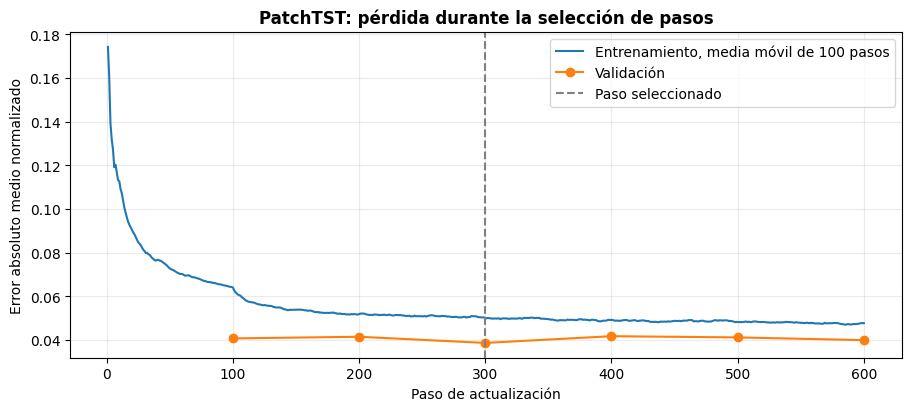

Pronósticos evaluados: 220,800
Modelo final guardado en data/processed/patchtst_model.
MAPE no está definido para todo el panel porque existen consumos reales en cero.


In [9]:
from neuralforecast.models import PatchTST


class PatchTSTForecaster(NHITSForecaster):
    def __init__(self, scaler, training_reference, random_seed=123):
        super().__init__(scaler, training_reference, random_seed)
        self.model_name = "PatchTST"
        self.patch_length = 24
        self.patch_stride = 12
        self.encoder_layers = 2
        self.hidden_size = 64
        self.attention_heads = 4
        self.feedforward_size = 128
        self.learning_rate = 0.0005
        self.windows_batch_size = 256
        self.validation_batch_size = 512

    def to_long_panel(self, consumption, calendar):
        assert consumption.index.equals(calendar.index)
        assert consumption.columns.equals(self.client_columns)
        panel = consumption.rename_axis("ds").reset_index().melt(
            id_vars="ds", var_name="unique_id", value_name="y"
        )
        panel["y"] = panel["y"].astype(np.float32)
        assert not panel.duplicated(["unique_id", "ds"]).any()
        return panel

    def create_forecast_model(self, maximum_steps, monitor, selecting):
        network = PatchTST(
            h=self.horizon_length, input_size=self.window_length,
            patch_len=self.patch_length, stride=self.patch_stride,
            encoder_layers=self.encoder_layers, n_heads=self.attention_heads,
            hidden_size=self.hidden_size, linear_hidden_size=self.feedforward_size,
            dropout=0.1, fc_dropout=0.1, head_dropout=0.1, attn_dropout=0.0,
            learn_pos_embed=True, activation="gelu",
            revin=True, revin_affine=False, revin_subtract_last=False,
            loss=MAE(), valid_loss=MAE(), learning_rate=self.learning_rate, num_lr_decays=0,
            max_steps=maximum_steps, val_check_steps=min(self.validation_check_steps, maximum_steps),
            early_stop_patience_steps=self.patience if selecting else -1,
            batch_size=self.series_batch_size, valid_batch_size=self.series_batch_size,
            windows_batch_size=self.windows_batch_size,
            inference_windows_batch_size=self.validation_batch_size,
            step_size=1, start_padding_enabled=False, training_data_availability_threshold=1.0,
            scaler_type="identity", random_seed=self.random_seed, alias="PatchTST",
            accelerator=self.device.type, devices=1, precision="32-true",
            gradient_clip_val=1.0, logger=False, enable_checkpointing=False,
            enable_progress_bar=False, enable_model_summary=False, num_sanity_val_steps=0,
            dataloader_kwargs={"num_workers": 0},
        )
        forecast_model = NeuralForecast(models=[network], freq="h", local_scaler_type=None)
        forecast_model.models[0].trainer_kwargs.setdefault("callbacks", []).append(monitor)
        return forecast_model

    def evaluate_validation(self, network):
        validation_loader = DataLoader(
            self.validation_dataset, batch_size=self.validation_batch_size, shuffle=False,
            num_workers=0, collate_fn=keep_window_batch,
        )
        client_count = len(self.client_columns)
        normalized_error_sum = 0.0
        original_error_sum = 0.0
        scaled_error_sum = 0.0
        scaled_error_count = 0
        example_count = 0
        with torch.inference_mode():
            for history_windows, target_windows in validation_loader:
                predictions = network({
                    "insample_y": history_windows[:, :, :1].to(self.device)
                }).squeeze(-1).cpu()
                absolute_errors = (predictions - target_windows).abs().numpy().astype(np.float64)
                client_positions = np.arange(example_count, example_count + len(history_windows)) % client_count
                original_errors = absolute_errors * self.original_unit_factors[client_positions, None]
                reference_errors = self.mase_reference[client_positions]
                valid_reference = np.isfinite(reference_errors) & (reference_errors > 0)
                normalized_error_sum += absolute_errors.sum()
                original_error_sum += original_errors.sum()
                scaled_error_sum += (
                    original_errors[valid_reference] / reference_errors[valid_reference, None]
                ).sum()
                scaled_error_count += int(valid_reference.sum()) * self.horizon_length
                example_count += len(history_windows)
                self.record_gpu_memory()
        element_count = example_count * self.horizon_length
        return {
            "validation_loss": normalized_error_sum / element_count,
            "validation_MAE_kWh": original_error_sum / element_count,
            "validation_MASE": scaled_error_sum / scaled_error_count if scaled_error_count else np.nan,
        }

    def predict(self, consumption_window, calendar_window, future_calendar):
        inference_start = perf_counter()
        assert consumption_window.columns.equals(self.client_columns)
        assert calendar_window.index.equals(consumption_window.index)
        assert len(consumption_window) == self.window_length
        assert len(future_calendar) == self.horizon_length
        assert future_calendar.index[0] == consumption_window.index[-1] + pd.Timedelta(hours=1)
        consumption_inputs = torch.from_numpy(
            consumption_window.to_numpy(dtype=np.float32).T.copy()
        ).unsqueeze(-1).to(self.device)
        self.network.eval()
        with torch.inference_mode():
            predictions = self.network({"insample_y": consumption_inputs}).squeeze(-1).cpu().numpy().T
        self.record_gpu_memory()
        self.inference_seconds += perf_counter() - inference_start
        return pd.DataFrame(predictions, index=future_calendar.index, columns=self.client_columns)


assert len(selected_clients) == 100 and client_selection_seed == 123
patchtst_model = PatchTSTForecaster(electricity_scaler, electricity_train_original, random_seed=123)
patchtst_backtest_start = perf_counter()
patchtst_results = backtest(patchtst_model, window_length=168, refit_monthly=False)
patchtst_backtest_seconds = perf_counter() - patchtst_backtest_start
patchtst_total_parameters = sum(parameter.numel() for parameter in patchtst_model.network.parameters())
patchtst_trainable_parameters = sum(
    parameter.numel() for parameter in patchtst_model.network.parameters() if parameter.requires_grad
)
patchtst_patch_count = patchtst_model.network.model.backbone.patch_num
assert patchtst_patch_count == 14
patchtst_configuration = pd.Series({
    "Modelo": "PatchTST global", "Biblioteca": f"NeuralForecast {neuralforecast.__version__}",
    "Clientes": len(selected_clients), "Semilla": 123,
    "Ventana (horas)": 168, "Horizonte (horas)": 24,
    "Longitud de parche (horas)": patchtst_model.patch_length,
    "Desplazamiento de parches (horas)": patchtst_model.patch_stride,
    "Parches por ventana": patchtst_patch_count,
    "Relleno del último parche": "Repetición del último consumo histórico",
    "Capas del encoder": patchtst_model.encoder_layers,
    "Tamaño de representación": patchtst_model.hidden_size,
    "Cabezas de atención": patchtst_model.attention_heads,
    "Capa intermedia feedforward": patchtst_model.feedforward_size,
    "Activación": "GELU", "Codificación posicional": "Aprendida",
    "Dropout encoder y salida": 0.1,
    "Entradas": "Solo consumo histórico; pesos compartidos entre clientes",
    "Normalización previa": "MinMax por cliente ajustado solo con entrenamiento",
    "RevIN": "Media y desviación calculadas solo con la ventana histórica; reversible",
    "Escalador adicional de NeuralForecast": "Desactivado",
    "Learning rate": patchtst_model.learning_rate, "Optimizador": "Adam", "Recorte de norma": 1.0,
    "Series por lote": patchtst_model.series_batch_size,
    "Ventanas muestreadas por paso": patchtst_model.windows_batch_size,
    "Stride de ventanas de entrenamiento (horas)": 1,
    "Máximo de pasos": patchtst_model.maximum_steps,
    "Validación cada N pasos": patchtst_model.validation_check_steps,
    "Paciencia (controles de validación)": patchtst_model.patience,
    "Pasos seleccionados": patchtst_model.best_step,
    "Parámetros totales": patchtst_total_parameters,
    "Parámetros entrenables": patchtst_trainable_parameters,
    "Hardware": f"{patchtst_model.device} | {platform.system()} | {platform.machine()}",
}, name="Configuración")
patchtst_results["resources"] = pd.Series({
    "Selección y ajuste final (s)": patchtst_model.fit_seconds,
    "Inferencia de los 92 orígenes (s)": patchtst_model.inference_seconds,
    "Backtest completo (s)": patchtst_backtest_seconds,
    "Memoria GPU del controlador, máxima observada (MiB)": patchtst_model.peak_gpu_memory_bytes / 1024**2,
}, name="Recursos")
patchtst_results["selection_history"] = patchtst_model.selection_history.copy()
patchtst_results["final_training_history"] = patchtst_model.final_training_history.copy()
patchtst_artifact_directory = Path("data/processed")
patchtst_artifact_directory.mkdir(parents=True, exist_ok=True)
patchtst_checkpoint_directory = patchtst_artifact_directory / "patchtst_model"
patchtst_model.forecast_model.save(str(patchtst_checkpoint_directory), save_dataset=False, overwrite=True)
torch.save({
    "state_dict": patchtst_model.training_state,
    "window_length": 168, "horizon_length": 24, "seed": 123,
    "patch_length": patchtst_model.patch_length, "patch_stride": patchtst_model.patch_stride,
    "encoder_layers": patchtst_model.encoder_layers, "hidden_size": patchtst_model.hidden_size,
    "attention_heads": patchtst_model.attention_heads, "feedforward_size": patchtst_model.feedforward_size,
    "selected_steps": patchtst_model.best_step, "revin": True, "revin_subtract_last": False,
    "client_columns": selected_clients.tolist(),
    "calendar_columns_used": [],
    "minmax_scale": torch.from_numpy(electricity_scaler.scale_.copy()),
    "minmax_min": torch.from_numpy(electricity_scaler.min_.copy()),
    "neuralforecast_version": str(neuralforecast.__version__),
}, patchtst_artifact_directory / "patchtst_panel_metadata.pt")
patchtst_model.selection_history.to_csv(patchtst_artifact_directory / "patchtst_selection_history.csv", index=False)
patchtst_model.selection_training_history.to_csv(patchtst_artifact_directory / "patchtst_selection_training_history.csv", index=False)
patchtst_model.final_training_history.to_csv(patchtst_artifact_directory / "patchtst_final_training_history.csv", index=False)
patchtst_results["forecasts"].to_csv(patchtst_artifact_directory / "patchtst_test_forecasts.csv", index=False)

display(patchtst_configuration.to_frame())
print("Selección de pasos mediante validación")
display(patchtst_model.selection_history.round(5))
display(patchtst_results["resources"].to_frame().round(4))
print("Métricas generales en prueba")
display(patchtst_results["overall_metrics"].to_frame("PatchTST").T.round(4))
for report_title, report_key in (
    ("Métricas por cliente", "metrics_by_client"),
    ("Métricas por paso del horizonte", "metrics_by_horizon"),
    ("Métricas por hora del día", "metrics_by_hour"),
):
    print(report_title)
    display(patchtst_results[report_key].round(4))
print("Métricas de la semana del 22 al 28 de diciembre")
display(patchtst_results["christmas_week_metrics"].to_frame("PatchTST").T.round(4))
patchtst_loss_figure, patchtst_loss_axis = plt.subplots(figsize=(9, 4), layout="constrained")
patchtst_smoothed_training = patchtst_model.selection_training_history["training_loss"].rolling(100, min_periods=1).mean()
patchtst_loss_axis.plot(patchtst_model.selection_training_history["step"], patchtst_smoothed_training, label="Entrenamiento, media móvil de 100 pasos")
patchtst_loss_axis.plot(patchtst_model.selection_history["step"], patchtst_model.selection_history["validation_loss"], marker="o", label="Validación")
patchtst_loss_axis.axvline(patchtst_model.best_step, linestyle="--", color="gray", label="Paso seleccionado")
patchtst_loss_axis.set_title("PatchTST: pérdida durante la selección de pasos", fontweight="bold")
patchtst_loss_axis.set(xlabel="Paso de actualización", ylabel="Error absoluto medio normalizado")
patchtst_loss_axis.legend()
patchtst_loss_axis.grid(alpha=0.25)
plt.show()
print(f"Pronósticos evaluados: {len(patchtst_results['forecasts']):,}")
print(f"Modelo final guardado en {patchtst_checkpoint_directory}.")
if patchtst_results["overall_metrics"]["zero_actual_count"] > 0:
    print("MAPE no está definido para todo el panel porque existen consumos reales en cero.")


### **TFT global**

Se utilizará TFT para combinar el historial del consumo con el calendario. La red aprende cuánto aportar de cada variable, procesa la secuencia mediante una LSTM y utiliza atención para relacionar momentos que pueden ayudar a generar las 24 predicciones.

- **Arquitectura:** Se utilizará NeuralForecast con representaciones de 32 números, una capa LSTM y cuatro cabezas de atención. Se mantendrá dropout de 0.1 y activación ELU en las redes con compuertas. La selección de variables puede cambiar según el momento y la entrada que se está analizando.
- **Entradas:** El encoder recibe consumo y siete covariables de calendario durante las 168 horas históricas. Para las 24 horas objetivo se entrega únicamente calendario conocido, sin incluir los consumos que se buscan pronosticar. Se compartirán los pesos entre los mismos 100 clientes del panel.
- **Salida:** La LSTM del decoder procesa el calendario futuro a partir del estado histórico y la atención causal combina las representaciones temporales. La salida entrega los 24 consumos; no se necesita entregar consumo real futuro al decoder.
- **Normalización:** Se mantiene el MinMax por cliente ajustado únicamente con entrenamiento y se desactiva el escalador adicional de NeuralForecast. Las métricas se calcularán después de regresar a kWh.
- **Configuración inicial:** Semilla 123, Adam con learning rate de 0.001 y recorte de norma a 1. Se cargarán cuatro clientes por lote y se muestrearán 128 ventanas por paso, manteniendo un desplazamiento de una hora entre ventanas disponibles.
- **Selección y ajuste final:** Se realizarán hasta 1000 pasos de actualización, con validación cada 100 y paciencia de tres controles. Se seleccionará la duración con entrenamiento hasta junio y validación de julio a septiembre, y después se reinicializará el modelo para ajustarlo hasta septiembre con los pasos seleccionados.
- **Evaluación:** Se conservarán ventana de 168 horas, horizonte de 24 y el mismo backtest de 92 días, con pesos fijos durante prueba. Se comprobará que las entradas futuras contengan únicamente calendario y que la inferencia coincida con NeuralForecast.
- **Registro:** Se guardarán pérdidas por paso, MAE y MASE de validación, parámetros, recursos, pronósticos y modelo final. La curva de entrenamiento muestra una media móvil de 100 pasos.

Seed set to 123


TFT: selección con entrenamiento hasta junio y validación de julio a septiembre en mps.


GPU available: True (mps), used: True


TPU available: False, using: 0 TPU cores


/Users/bryan/VirtualEnv/venv/lib/python3.13/site-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


...

,MAE_kWh,RMSE_kWh,WAPE_pct,MAPE_pct,zero_actual_count
horizon_step,,,,,
1,42.2527,168.6530,10.5730,NaN,17
2,45.2562,207.4850,12.6538,NaN,42
3,33.9751,151.1599,9.7825,NaN,43
4,33.8717,162.0084,9.7721,NaN,29
5,32.5955,158.7492,9.5456,NaN,30
6,34.2703,159.3923,9.9213,NaN,29
7,33.6312,157.2289,8.8089,NaN,29
8,33.1348,162.2321,7.3949,NaN,35
9,52.0564,224.7224,11.4619,NaN,90


Métricas por hora del día


,MAE_kWh,RMSE_kWh,WAPE_pct,MAPE_pct,zero_actual_count
hour_of_day,,,,,
0,42.2527,168.6530,10.5730,NaN,17
1,45.2562,207.4850,12.6538,NaN,42
2,33.9751,151.1599,9.7825,NaN,43
3,33.8717,162.0084,9.7721,NaN,29
4,32.5955,158.7492,9.5456,NaN,30
5,34.2703,159.3923,9.9213,NaN,29
6,33.6312,157.2289,8.8089,NaN,29
7,33.1348,162.2321,7.3949,NaN,35
8,52.0564,224.7224,11.4619,NaN,90


Métricas de la semana del 22 al 28 de diciembre


,MAE_kWh,RMSE_kWh,WAPE_pct,MAPE_pct,zero_actual_count
TFT,83.1608,485.3388,17.5064,NaN,353.0


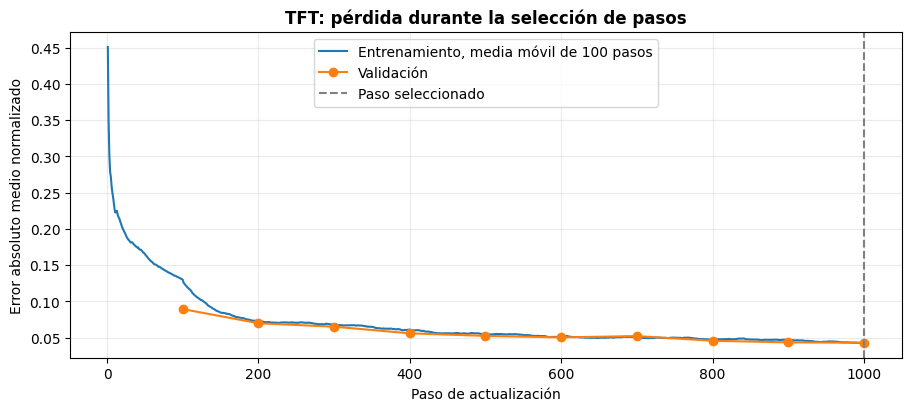

Pronósticos evaluados: 220,800
Modelo final guardado en data/processed/tft_model.
MAPE no está definido para todo el panel porque existen consumos reales en cero.


In [9]:
from neuralforecast.models import TFT


class TFTForecaster(NHITSForecaster):
    def __init__(self, scaler, training_reference, random_seed=123):
        super().__init__(scaler, training_reference, random_seed)
        self.model_name = "TFT"
        self.hidden_size = 32
        self.recurrent_layers = 1
        self.attention_heads = 4
        self.windows_batch_size = 128
        self.validation_batch_size = 256

    def create_forecast_model(self, maximum_steps, monitor, selecting):
        network = TFT(
            h=self.horizon_length, input_size=self.window_length,
            hidden_size=self.hidden_size, n_head=self.attention_heads,
            n_rnn_layers=self.recurrent_layers, rnn_type="lstm",
            dropout=0.1, attn_dropout=0.0, grn_activation="ELU",
            futr_exog_list=self.calendar_columns.tolist(),
            loss=MAE(), valid_loss=MAE(), learning_rate=0.001, num_lr_decays=0,
            max_steps=maximum_steps, val_check_steps=min(self.validation_check_steps, maximum_steps),
            early_stop_patience_steps=self.patience if selecting else -1,
            batch_size=self.series_batch_size, valid_batch_size=self.series_batch_size,
            windows_batch_size=self.windows_batch_size,
            inference_windows_batch_size=self.validation_batch_size,
            step_size=1, start_padding_enabled=False, training_data_availability_threshold=1.0,
            scaler_type="identity", random_seed=self.random_seed, alias="TFT",
            accelerator=self.device.type, devices=1, precision="32-true",
            gradient_clip_val=1.0, logger=False, enable_checkpointing=False,
            enable_progress_bar=False, enable_model_summary=False, num_sanity_val_steps=0,
            dataloader_kwargs={"num_workers": 0},
        )
        forecast_model = NeuralForecast(models=[network], freq="h", local_scaler_type=None)
        forecast_model.models[0].trainer_kwargs.setdefault("callbacks", []).append(monitor)
        return forecast_model


assert len(selected_clients) == 100 and client_selection_seed == 123
tft_model = TFTForecaster(electricity_scaler, electricity_train_original, random_seed=123)
tft_backtest_start = perf_counter()
tft_results = backtest(tft_model, window_length=168, refit_monthly=False)
tft_backtest_seconds = perf_counter() - tft_backtest_start
tft_total_parameters = sum(parameter.numel() for parameter in tft_model.network.parameters())
tft_trainable_parameters = sum(
    parameter.numel() for parameter in tft_model.network.parameters() if parameter.requires_grad
)
tft_configuration = pd.Series({
    "Modelo": "TFT global", "Biblioteca": f"NeuralForecast {neuralforecast.__version__}",
    "Clientes": len(selected_clients), "Semilla": 123,
    "Ventana (horas)": 168, "Horizonte (horas)": 24,
    "Estado oculto": tft_model.hidden_size,
    "Capas LSTM": tft_model.recurrent_layers,
    "Cabezas de atención": tft_model.attention_heads,
    "Variables históricas": "Consumo y siete covariables de calendario",
    "Entradas futuras": "Únicamente siete covariables de calendario conocido",
    "Dropout": 0.1, "Activación de redes con compuertas": "ELU",
    "Salida": "24 pasos mediante decoder temporal y atención causal",
    "Covariables": "Calendario histórico y futuro conocido",
    "Escalamiento adicional": "Ninguno; MinMax previo ajustado solo con entrenamiento",
    "Learning rate": 0.001, "Optimizador": "Adam", "Recorte de norma": 1.0,
    "Series por lote": tft_model.series_batch_size,
    "Ventanas muestreadas por paso": tft_model.windows_batch_size,
    "Stride de ventanas (horas)": 1, "Máximo de pasos": tft_model.maximum_steps,
    "Validación cada N pasos": tft_model.validation_check_steps,
    "Paciencia (controles de validación)": tft_model.patience,
    "Pasos seleccionados": tft_model.best_step,
    "Parámetros totales": tft_total_parameters,
    "Parámetros entrenables": tft_trainable_parameters,
    "Hardware": f"{tft_model.device} | {platform.system()} | {platform.machine()}",
}, name="Configuración")
tft_results["resources"] = pd.Series({
    "Selección y ajuste final (s)": tft_model.fit_seconds,
    "Inferencia de los 92 orígenes (s)": tft_model.inference_seconds,
    "Backtest completo (s)": tft_backtest_seconds,
    "Memoria GPU del controlador, máxima observada (MiB)": tft_model.peak_gpu_memory_bytes / 1024**2,
}, name="Recursos")
tft_results["selection_history"] = tft_model.selection_history.copy()
tft_results["final_training_history"] = tft_model.final_training_history.copy()
tft_artifact_directory = Path("data/processed")
tft_artifact_directory.mkdir(parents=True, exist_ok=True)
tft_checkpoint_directory = tft_artifact_directory / "tft_model"
tft_model.forecast_model.save(str(tft_checkpoint_directory), save_dataset=False, overwrite=True)
torch.save({
    "state_dict": tft_model.training_state,
    "window_length": 168, "horizon_length": 24, "seed": 123,
    "hidden_size": tft_model.hidden_size,
    "recurrent_layers": tft_model.recurrent_layers,
    "attention_heads": tft_model.attention_heads,
    "dropout": 0.1, "future_consumption_as_input": False,
    "selected_steps": tft_model.best_step,
    "client_columns": selected_clients.tolist(),
    "calendar_columns": calendar_train.columns.tolist(),
    "minmax_scale": torch.from_numpy(electricity_scaler.scale_.copy()),
    "minmax_min": torch.from_numpy(electricity_scaler.min_.copy()),
    "neuralforecast_version": str(neuralforecast.__version__),
}, tft_artifact_directory / "tft_panel_metadata.pt")
tft_model.selection_history.to_csv(tft_artifact_directory / "tft_selection_history.csv", index=False)
tft_model.selection_training_history.to_csv(tft_artifact_directory / "tft_selection_training_history.csv", index=False)
tft_model.final_training_history.to_csv(tft_artifact_directory / "tft_final_training_history.csv", index=False)
tft_results["forecasts"].to_csv(tft_artifact_directory / "tft_test_forecasts.csv", index=False)

display(tft_configuration.to_frame())
print("Selección de pasos mediante validación")
display(tft_model.selection_history.round(5))
display(tft_results["resources"].to_frame().round(4))
print("Métricas generales en prueba")
display(tft_results["overall_metrics"].to_frame("TFT").T.round(4))
for report_title, report_key in (
    ("Métricas por cliente", "metrics_by_client"),
    ("Métricas por paso del horizonte", "metrics_by_horizon"),
    ("Métricas por hora del día", "metrics_by_hour"),
):
    print(report_title)
    display(tft_results[report_key].round(4))
print("Métricas de la semana del 22 al 28 de diciembre")
display(tft_results["christmas_week_metrics"].to_frame("TFT").T.round(4))
tft_loss_figure, tft_loss_axis = plt.subplots(figsize=(9, 4), layout="constrained")
tft_smoothed_training = tft_model.selection_training_history["training_loss"].rolling(100, min_periods=1).mean()
tft_loss_axis.plot(tft_model.selection_training_history["step"], tft_smoothed_training, label="Entrenamiento, media móvil de 100 pasos")
tft_loss_axis.plot(tft_model.selection_history["step"], tft_model.selection_history["validation_loss"], marker="o", label="Validación")
tft_loss_axis.axvline(tft_model.best_step, linestyle="--", color="gray", label="Paso seleccionado")
tft_loss_axis.set_title("TFT: pérdida durante la selección de pasos", fontweight="bold")
tft_loss_axis.set(xlabel="Paso de actualización", ylabel="Error absoluto medio normalizado")
tft_loss_axis.legend()
tft_loss_axis.grid(alpha=0.25)
plt.show()
print(f"Pronósticos evaluados: {len(tft_results['forecasts']):,}")
print(f"Modelo final guardado en {tft_checkpoint_directory}.")
if tft_results["overall_metrics"]["zero_actual_count"] > 0:
    print("MAPE no está definido para todo el panel porque existen consumos reales en cero.")


### **DeepAR global**

Se utilizará DeepAR para aprender una distribución de posibles consumos por hora. La LSTM procesa el historial y, al pronosticar, cada trayectoria toma una muestra de su distribución y utiliza ese valor para continuar con la siguiente hora. Después se resumen las trayectorias mediante cuantiles.

- **Arquitectura:** Se utilizará el DeepAR de NeuralForecast, con una capa LSTM de 32 unidades y una proyección lineal que produce los parámetros de una distribución Normal. Esta es una configuración inicial para consumo continuo, compartiendo los pesos entre los mismos 100 clientes.
- **Entradas:** Se entregarán 168 consumos históricos y el calendario de la hora que se busca predecir en cada paso. Se mantendrán las siete covariables de calendario y su desplazamiento temporal, sin entregar como entrada el consumo real de la hora objetivo.
- **Entrenamiento:** Se minimizará la log-verosimilitud negativa utilizando teacher forcing desplazado durante los 24 pasos de entrenamiento. Se conservan ventanas disponibles con desplazamiento de una hora, semilla 123, Adam con learning rate de 0.001, recorte de norma a 1, cuatro clientes por lote y 256 ventanas muestreadas por paso. La biblioteca ajusta internamente la longitud para modelos recurrentes y se comprueba que la historia efectiva tenga 168 observaciones.
- **Normalización:** Se conserva el MinMax por cliente ajustado únicamente con entrenamiento, sin añadir otro escalador. Los consumos y cuantiles se regresarán a kWh para evaluarlos.
- **Trayectorias:** Se generarán 100 escenarios por cliente y origen. El muestreo explícito reutiliza la LSTM y la proyección entrenadas por NeuralForecast, ya que el predictor genérico de la versión instalada realimenta la media. Aquí cada escenario realimenta su propia muestra, manteniendo el mecanismo probabilístico que discutimos. Se utiliza una semilla por origen para reproducir las simulaciones.
- **Selección y ajuste final:** Se realizarán hasta 1000 pasos, con validación cada 100 y paciencia de tres controles. La validación recorre los 92 días de julio a septiembre, con origen diario y horizonte de 24, de tal forma que se evalúan 9200 ventanas y sus trayectorias completas. Se selecciona el menor MAE normalizado de P50, sin consumos reales futuros como entrada. Después se reinicializa el modelo y se ajusta hasta septiembre con la duración seleccionada.
- **Evaluación:** Se conservará el mismo backtest de prueba de 92 días y los pesos quedarán fijos. Se utilizará P50 como pronóstico central para MAE, RMSE, WAPE y MAPE. También se guardarán P10 y P90 para calcular pinball loss y cobertura del intervalo, cuya cobertura nominal es de 80 por ciento.
- **Registro:** Se guardarán modelo, metadatos de normalización, historia de entrenamiento, métricas, recursos y pronósticos con sus cuantiles. La NLL de entrenamiento y el MAE de validación se mostrarán en gráficas separadas porque representan objetivos distintos.

Seed set to 123


DeepAR: selección en mps, validación con 92 orígenes diarios y 100 trayectorias por cliente.


GPU available: True (mps), used: True


TPU available: False, using: 0 TPU cores


/Users/bryan/VirtualEnv/venv/lib/python3.13/site-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


...

,MAE_kWh,RMSE_kWh,WAPE_pct,MAPE_pct,zero_actual_count
hour_of_day,,,,,
0,98.1102,268.0133,24.5502,NaN,17
1,117.2420,338.8135,32.7814,NaN,42
2,108.0296,313.8949,31.1051,NaN,43
3,113.1634,356.6116,32.6481,NaN,29
4,110.0736,347.0785,32.2352,NaN,30
5,110.1018,319.1299,31.8744,NaN,29
6,128.2540,368.3301,33.5932,NaN,29
7,154.7997,547.0556,34.5477,NaN,35
8,129.9512,380.0137,28.6130,NaN,90


Métricas de la semana del 22 al 28 de diciembre


,MAE_kWh,RMSE_kWh,WAPE_pct,MAPE_pct,zero_actual_count
DeepAR,139.6623,521.9136,29.4007,NaN,353.0


Resultados probabilísticos en prueba


,DeepAR
Pinball_P10_kWh,38.9785
Pinball_P50_kWh,61.9956
Pinball_P90_kWh,31.4546
Pinball_promedio_kWh,44.1429
Cobertura_P10_P90_pct,96.7672
Amplitud_media_P10_P90_kWh,691.5040


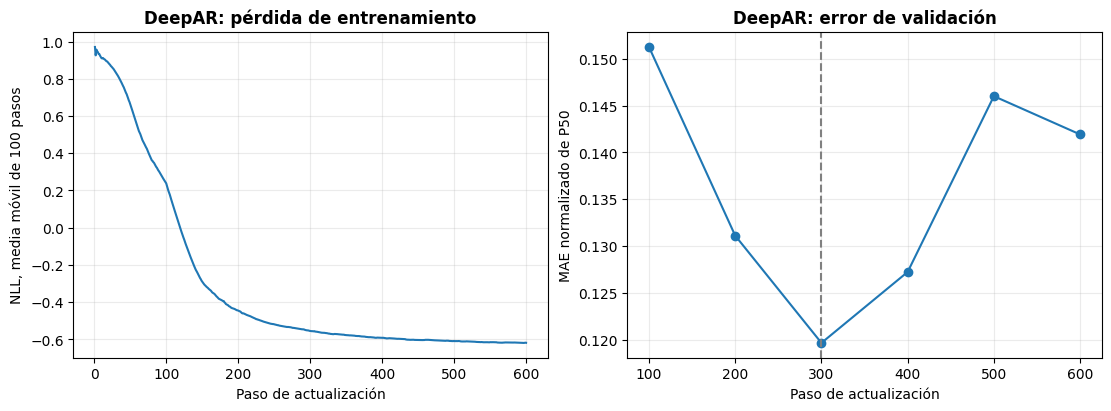

Pronósticos evaluados: 220,800
Modelo final y cuantiles guardados en data/processed.
MAPE no está definido porque existen consumos reales en cero.


In [9]:
from neuralforecast.models import DeepAR
from neuralforecast.losses.pytorch import DistributionLoss


def sample_deepar_paths(network, history_windows, future_calendar_windows, trajectory_count, random_seed):
    device = next(network.parameters()).device
    context_count, history_length, feature_count = history_windows.shape
    horizon_length = future_calendar_windows.shape[1]
    history_windows = history_windows.to(device)
    future_calendar_windows = future_calendar_windows.to(device)
    next_hour_calendar = torch.cat([
        history_windows[:, 1:, 1:], future_calendar_windows[:, :1]
    ], dim=1)
    recurrent_inputs = torch.cat([history_windows[:, :, :1], next_hour_calendar], dim=-1)
    noise_generator = torch.Generator(device="cpu").manual_seed(random_seed)
    trajectory_noise = torch.randn(
        context_count, trajectory_count, horizon_length, generator=noise_generator
    ).to(device)
    was_training = network.training
    network.eval()
    try:
        with torch.inference_mode():
            historical_states, recurrent_state = network.hist_encoder(recurrent_inputs)
            raw_parameters = network.decoder(historical_states[:, -1:])
            mapped_parameters = network.loss.domain_map(raw_parameters)
            location, dispersion = network.loss.scale_decouple(
                mapped_parameters, loc=torch.zeros_like(mapped_parameters[0]),
                scale=torch.ones_like(mapped_parameters[0]),
            )
            current_samples = location.reshape(context_count, 1) + dispersion.reshape(context_count, 1) * trajectory_noise[:, :, 0]
            trajectories = [current_samples]
            recurrent_state = tuple(
                state.repeat_interleave(trajectory_count, dim=1) for state in recurrent_state
            )
            for horizon_position in range(1, horizon_length):
                previous_consumption = current_samples.reshape(-1, 1, 1)
                next_calendar = future_calendar_windows[:, horizon_position:horizon_position + 1].repeat_interleave(trajectory_count, dim=0)
                recurrent_inputs = torch.cat([previous_consumption, next_calendar], dim=-1)
                recurrent_output, recurrent_state = network.hist_encoder(recurrent_inputs, recurrent_state)
                mapped_parameters = network.loss.domain_map(network.decoder(recurrent_output))
                location, dispersion = network.loss.scale_decouple(
                    mapped_parameters, loc=torch.zeros_like(mapped_parameters[0]),
                    scale=torch.ones_like(mapped_parameters[0]),
                )
                current_samples = location.reshape(context_count, trajectory_count) + dispersion.reshape(context_count, trajectory_count) * trajectory_noise[:, :, horizon_position]
                trajectories.append(current_samples)
            paths = torch.stack(trajectories, dim=-1).cpu()
    finally:
        network.train(was_training)
    if not torch.isfinite(paths).all().item():
        raise FloatingPointError("DeepAR generó trayectorias no finitas.")
    return paths


class DeepARTrainingMonitor(Callback):
    def __init__(self, forecaster, selecting):
        self.forecaster = forecaster
        self.selecting = selecting
        self.records = []
        self.validation_records = []
        self.best_loss = np.inf
        self.checks_without_improvement = 0

    def on_train_batch_end(self, trainer, network, outputs, batch, batch_idx):
        step_number = int(trainer.global_step)
        training_loss = float(network.train_trajectories[-1][1])
        if not np.isfinite(training_loss):
            raise FloatingPointError("La pérdida de DeepAR no es finita.")
        self.records.append({"step": step_number, "training_NLL": training_loss})
        self.forecaster.record_gpu_memory()
        if step_number % self.forecaster.validation_check_steps:
            return
        stage = "selección" if self.selecting else "ajuste final"
        print(f"DeepAR · {stage}: paso {step_number}, NLL={training_loss:.5f}.", flush=True)
        if self.selecting:
            validation_metrics = self.forecaster.evaluate_daily_validation(network)
            self.validation_records.append({"step": step_number, **validation_metrics})
            print(
                f"DeepAR · validación en paso {step_number}: "
                f"MAE={validation_metrics['validation_MAE_kWh']:.2f} kWh, "
                f"MASE={validation_metrics['validation_MASE']:.3f}.", flush=True,
            )
            if validation_metrics["validation_loss"] < self.best_loss:
                self.best_loss = validation_metrics["validation_loss"]
                self.forecaster.best_step = step_number
                self.checks_without_improvement = 0
            else:
                self.checks_without_improvement += 1
            if self.checks_without_improvement >= self.forecaster.patience:
                trainer.should_stop = True


class DeepARForecaster(NHITSForecaster):
    def __init__(self, scaler, training_reference, random_seed=123):
        super().__init__(scaler, training_reference, random_seed)
        self.model_name = "DeepAR"
        self.hidden_size = 32
        self.recurrent_layers = 1
        self.windows_batch_size = 256
        self.trajectory_count = 100
        self.quantile_levels = torch.tensor([0.1, 0.5, 0.9])
        self.quantile_forecasts = []

    def create_forecast_model(self, maximum_steps, monitor):
        # NeuralForecast añade una observación a input_size al preparar modelos recurrentes.
        network = DeepAR(
            h=self.horizon_length, input_size=self.window_length - 1, h_train=self.horizon_length,
            lstm_n_layers=self.recurrent_layers, lstm_hidden_size=self.hidden_size, lstm_dropout=0.0,
            decoder_hidden_layers=0, trajectory_samples=self.trajectory_count,
            futr_exog_list=self.calendar_columns.tolist(),
            loss=DistributionLoss(distribution="Normal", quantiles=[0.1, 0.5, 0.9], return_params=True),
            valid_loss=MAE(), learning_rate=0.001, num_lr_decays=0,
            max_steps=maximum_steps, val_check_steps=maximum_steps, early_stop_patience_steps=-1,
            batch_size=self.series_batch_size, valid_batch_size=self.series_batch_size,
            windows_batch_size=self.windows_batch_size, inference_windows_batch_size=100,
            step_size=1, start_padding_enabled=False, training_data_availability_threshold=1.0,
            scaler_type="identity", random_seed=self.random_seed, alias="DeepAR",
            accelerator=self.device.type, devices=1, precision="32-true",
            gradient_clip_val=1.0, logger=False, enable_checkpointing=False,
            enable_progress_bar=False, enable_model_summary=False, num_sanity_val_steps=0,
            dataloader_kwargs={"num_workers": 0},
        )
        forecast_model = NeuralForecast(models=[network], freq="h", local_scaler_type=None)
        forecast_model.models[0].trainer_kwargs.setdefault("callbacks", []).append(monitor)
        assert forecast_model.models[0].input_size == self.window_length
        return forecast_model

    def evaluate_daily_validation(self, network):
        validation_loader = DataLoader(
            self.validation_dataset, batch_size=len(self.client_columns), shuffle=False,
            num_workers=0, collate_fn=keep_window_batch,
        )
        normalized_error_sum = 0.0
        original_error_sum = 0.0
        scaled_error_sum = 0.0
        scaled_error_count = 0
        example_count = 0
        client_count = len(self.client_columns)
        for history_windows, target_windows in validation_loader:
            origin_position = example_count // client_count
            target_position = self.validation_dataset.target_positions[origin_position]
            future_positions = target_position + self.validation_dataset.target_offsets
            future_calendar = self.validation_dataset.calendar_values[future_positions]
            future_calendar_windows = future_calendar.unsqueeze(0).expand(client_count, -1, -1)
            paths = sample_deepar_paths(
                network, history_windows, future_calendar_windows, self.trajectory_count,
                self.random_seed + origin_position,
            )
            median_forecasts = paths.quantile(0.5, dim=1)
            absolute_errors = (median_forecasts - target_windows).abs().numpy().astype(np.float64)
            original_errors = absolute_errors * self.original_unit_factors[:, None]
            valid_reference = np.isfinite(self.mase_reference) & (self.mase_reference > 0)
            normalized_error_sum += absolute_errors.sum()
            original_error_sum += original_errors.sum()
            scaled_error_sum += (
                original_errors[valid_reference] / self.mase_reference[valid_reference, None]
            ).sum()
            scaled_error_count += int(valid_reference.sum()) * self.horizon_length
            example_count += client_count
            self.record_gpu_memory()
        element_count = example_count * self.horizon_length
        return {
            "validation_loss": normalized_error_sum / element_count,
            "validation_MAE_kWh": original_error_sum / element_count,
            "validation_MASE": scaled_error_sum / scaled_error_count if scaled_error_count else np.nan,
        }

    def fit(self, consumption_history, calendar_history):
        fit_start = perf_counter()
        self.client_columns = consumption_history.columns.copy()
        self.calendar_columns = calendar_history.columns.copy()
        assert pd.Index(self.scaler.feature_names_in_).equals(self.client_columns)
        assert consumption_history.index.equals(calendar_history.index)
        torch.set_num_threads(4)
        if self.best_step is None:
            validation_end = pd.Timestamp("2014-09-30 23:00")
            assert consumption_history.index.max() == validation_end
            self.validation_dataset = PanelWindowDataset(
                consumption_history, calendar_history, pd.Timestamp("2014-07-01"), validation_end,
                window_length=self.window_length, horizon_length=self.horizon_length, stride=24,
            )
            assert len(self.validation_dataset) == 92 * len(self.client_columns)
            training_consumption = consumption_history.loc[:"2014-06-30 23:00"]
            training_calendar = calendar_history.loc[training_consumption.index]
            assert training_consumption.index.max() < pd.Timestamp("2014-07-01")
            selection_monitor = DeepARTrainingMonitor(self, selecting=True)
            selection_forecast = self.create_forecast_model(self.maximum_steps, selection_monitor)
            print(f"DeepAR: selección en {self.device}, validación con 92 orígenes diarios y 100 trayectorias por cliente.", flush=True)
            selection_forecast.fit(df=self.to_long_panel(training_consumption, training_calendar), val_size=0)
            self.selection_training_history = pd.DataFrame(selection_monitor.records)
            self.selection_history = pd.DataFrame(selection_monitor.validation_records)
            assert not self.selection_history.empty and self.best_step is not None
            del selection_forecast, self.validation_dataset
            if self.device.type == "mps":
                torch.mps.empty_cache()
        final_monitor = DeepARTrainingMonitor(self, selecting=False)
        self.forecast_model = self.create_forecast_model(self.best_step, final_monitor)
        print(f"DeepAR: ajuste final hasta {consumption_history.index.max()}, {self.best_step} pasos.", flush=True)
        self.forecast_model.fit(df=self.to_long_panel(consumption_history, calendar_history), val_size=0)
        self.final_training_history = pd.DataFrame(final_monitor.records)
        self.network = self.forecast_model.models[0].to(self.device).eval()
        # La distribución guardada por la última pérdida conserva un grafo que no se serializa.
        if hasattr(self.network.loss, "distr_mean"):
            self.network.loss.distr_mean = self.network.loss.distr_mean.detach()
        self.training_state = {
            parameter_name: parameter.detach().cpu().clone()
            for parameter_name, parameter in self.network.state_dict().items()
        }
        self.quantile_forecasts = []
        self.record_gpu_memory()
        self.fit_seconds += perf_counter() - fit_start
        return self

    def predict(self, consumption_window, calendar_window, future_calendar):
        inference_start = perf_counter()
        assert consumption_window.columns.equals(self.client_columns)
        assert calendar_window.index.equals(consumption_window.index)
        assert len(consumption_window) == self.window_length
        assert len(future_calendar) == self.horizon_length
        assert future_calendar.index[0] == consumption_window.index[-1] + pd.Timedelta(hours=1)
        client_count = len(self.client_columns)
        consumption_inputs = torch.from_numpy(consumption_window.to_numpy(dtype=np.float32).T.copy()).unsqueeze(-1)
        historical_calendar = torch.from_numpy(calendar_window.to_numpy(dtype=np.float32)).unsqueeze(0).expand(client_count, -1, -1)
        history_windows = torch.cat([consumption_inputs, historical_calendar], dim=-1)
        future_calendar_windows = torch.from_numpy(future_calendar.to_numpy(dtype=np.float32)).unsqueeze(0).expand(client_count, -1, -1)
        origin_seed = self.random_seed + int(future_calendar.index[0].value // pd.Timedelta(hours=1).value)
        paths = sample_deepar_paths(
            self.network, history_windows, future_calendar_windows, self.trajectory_count, origin_seed
        )
        quantiles = paths.quantile(self.quantile_levels, dim=1).numpy()
        original_quantiles = {
            quantile_name: self.scaler.inverse_transform(pd.DataFrame(
                quantiles[quantile_position].T, columns=self.client_columns
            )).reshape(-1)
            for quantile_position, quantile_name in enumerate(["P10", "P50", "P90"])
        }
        self.quantile_forecasts.append(pd.DataFrame({
            "unique_id": np.tile(self.client_columns.to_numpy(), self.horizon_length),
            "ds": future_calendar.index.repeat(client_count), **original_quantiles,
        }))
        self.record_gpu_memory()
        self.inference_seconds += perf_counter() - inference_start
        return pd.DataFrame(quantiles[1].T, index=future_calendar.index, columns=self.client_columns)


assert len(selected_clients) == 100 and client_selection_seed == 123
deepar_model = DeepARForecaster(electricity_scaler, electricity_train_original, random_seed=123)
deepar_backtest_start = perf_counter()
deepar_results = backtest(deepar_model, window_length=168, refit_monthly=False)
deepar_backtest_seconds = perf_counter() - deepar_backtest_start
deepar_quantiles = pd.concat(deepar_model.quantile_forecasts, ignore_index=True)
deepar_probabilistic_forecasts = deepar_results["forecasts"].merge(
    deepar_quantiles, on=["unique_id", "ds"], validate="one_to_one"
)
assert (deepar_probabilistic_forecasts["P10"] <= deepar_probabilistic_forecasts["P50"]).all()
assert (deepar_probabilistic_forecasts["P50"] <= deepar_probabilistic_forecasts["P90"]).all()
np.testing.assert_allclose(deepar_probabilistic_forecasts["P50"], deepar_probabilistic_forecasts["y_hat"])
deepar_quantile_errors = deepar_probabilistic_forecasts["y"].to_numpy()[:, None] - deepar_probabilistic_forecasts[["P10", "P50", "P90"]].to_numpy()
deepar_quantile_levels = np.array([0.1, 0.5, 0.9])
deepar_pinball_values = np.maximum(
    deepar_quantile_levels * deepar_quantile_errors,
    (deepar_quantile_levels - 1) * deepar_quantile_errors,
)
deepar_results["probabilistic_metrics"] = pd.Series({
    "Pinball_P10_kWh": deepar_pinball_values[:, 0].mean(),
    "Pinball_P50_kWh": deepar_pinball_values[:, 1].mean(),
    "Pinball_P90_kWh": deepar_pinball_values[:, 2].mean(),
    "Pinball_promedio_kWh": deepar_pinball_values.mean(),
    "Cobertura_P10_P90_pct": ((deepar_probabilistic_forecasts["y"] >= deepar_probabilistic_forecasts["P10"]) & (deepar_probabilistic_forecasts["y"] <= deepar_probabilistic_forecasts["P90"])).mean() * 100,
    "Amplitud_media_P10_P90_kWh": (deepar_probabilistic_forecasts["P90"] - deepar_probabilistic_forecasts["P10"]).mean(),
}, name="DeepAR")
deepar_total_parameters = sum(parameter.numel() for parameter in deepar_model.network.parameters())
deepar_trainable_parameters = sum(parameter.numel() for parameter in deepar_model.network.parameters() if parameter.requires_grad)
deepar_configuration = pd.Series({
    "Modelo": "DeepAR global", "Biblioteca": f"NeuralForecast {neuralforecast.__version__}",
    "Clientes": len(selected_clients), "Semilla": 123,
    "Ventana efectiva (horas)": 168, "Horizonte (horas)": 24,
    "Capas LSTM": 1, "Estado oculto": 32, "Distribución": "Normal",
    "Objetivo de entrenamiento": "Log-verosimilitud negativa, con teacher forcing desplazado",
    "Covariables": "Calendario histórico y futuro conocido, alineado con la siguiente hora",
    "Trayectorias por cliente y origen": deepar_model.trajectory_count,
    "Pronóstico central": "Mediana de las trayectorias (P50)", "Cuantiles": "P10, P50 y P90",
    "Normalización": "MinMax por cliente, ajustado solo con entrenamiento; sin escalado adicional",
    "Learning rate": 0.001, "Optimizador": "Adam", "Recorte de norma": 1.0,
    "Series por lote": deepar_model.series_batch_size,
    "Ventanas muestreadas por paso": deepar_model.windows_batch_size,
    "Stride de entrenamiento (horas)": 1, "Validación": "92 orígenes diarios, 9200 ventanas",
    "Máximo de pasos": deepar_model.maximum_steps, "Validación cada N pasos": 100,
    "Paciencia (controles)": 3, "Pasos seleccionados": deepar_model.best_step,
    "Parámetros totales": deepar_total_parameters, "Parámetros entrenables": deepar_trainable_parameters,
    "Hardware": f"{deepar_model.device} | {platform.system()} | {platform.machine()}",
}, name="Configuración")
deepar_results["resources"] = pd.Series({
    "Selección y ajuste final (s)": deepar_model.fit_seconds,
    "Inferencia de los 92 orígenes (s)": deepar_model.inference_seconds,
    "Backtest completo (s)": deepar_backtest_seconds,
    "Memoria GPU del controlador, máxima observada (MiB)": deepar_model.peak_gpu_memory_bytes / 1024**2,
}, name="Recursos")
deepar_artifact_directory = Path("data/processed")
deepar_artifact_directory.mkdir(parents=True, exist_ok=True)
deepar_checkpoint_directory = deepar_artifact_directory / "deepar_model"
deepar_model.forecast_model.save(str(deepar_checkpoint_directory), save_dataset=False, overwrite=True)
torch.save({
    "state_dict": deepar_model.training_state, "window_length": 168, "horizon_length": 24,
    "seed": 123, "selected_steps": deepar_model.best_step,
    "distribution": "Normal", "trajectory_count": 100, "point_forecast": "P50",
    "client_columns": selected_clients.tolist(), "calendar_columns": calendar_train.columns.tolist(),
    "minmax_scale": torch.from_numpy(electricity_scaler.scale_.copy()),
    "minmax_min": torch.from_numpy(electricity_scaler.min_.copy()),
    "neuralforecast_version": str(neuralforecast.__version__),
}, deepar_artifact_directory / "deepar_panel_metadata.pt")
deepar_model.selection_history.to_csv(deepar_artifact_directory / "deepar_selection_history.csv", index=False)
deepar_model.selection_training_history.to_csv(deepar_artifact_directory / "deepar_selection_training_history.csv", index=False)
deepar_model.final_training_history.to_csv(deepar_artifact_directory / "deepar_final_training_history.csv", index=False)
deepar_probabilistic_forecasts.to_csv(deepar_artifact_directory / "deepar_test_forecasts.csv", index=False)
deepar_results["probabilistic_metrics"].to_csv(deepar_artifact_directory / "deepar_probabilistic_metrics.csv")
display(deepar_configuration.to_frame())
display(deepar_model.selection_history.round(5))
display(deepar_results["resources"].to_frame().round(4))
print("Métricas generales en prueba, usando P50")
display(deepar_results["overall_metrics"].to_frame("DeepAR").T.round(4))
for report_title, report_key in (
    ("Métricas por cliente", "metrics_by_client"),
    ("Métricas por paso del horizonte", "metrics_by_horizon"),
    ("Métricas por hora del día", "metrics_by_hour"),
):
    print(report_title)
    display(deepar_results[report_key].round(4))
print("Métricas de la semana del 22 al 28 de diciembre")
display(deepar_results["christmas_week_metrics"].to_frame("DeepAR").T.round(4))
print("Resultados probabilísticos en prueba")
display(deepar_results["probabilistic_metrics"].to_frame().round(4))
deepar_loss_figure, deepar_loss_axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
deepar_loss_axes[0].plot(deepar_model.selection_training_history["step"], deepar_model.selection_training_history["training_NLL"].rolling(100, min_periods=1).mean())
deepar_loss_axes[0].set_title("DeepAR: pérdida de entrenamiento", fontweight="bold")
deepar_loss_axes[0].set(xlabel="Paso de actualización", ylabel="NLL, media móvil de 100 pasos")
deepar_loss_axes[1].plot(deepar_model.selection_history["step"], deepar_model.selection_history["validation_loss"], marker="o")
deepar_loss_axes[1].axvline(deepar_model.best_step, linestyle="--", color="gray")
deepar_loss_axes[1].set_title("DeepAR: error de validación", fontweight="bold")
deepar_loss_axes[1].set(xlabel="Paso de actualización", ylabel="MAE normalizado de P50")
for loss_axis in deepar_loss_axes:
    loss_axis.grid(alpha=0.25)
plt.show()
print(f"Pronósticos evaluados: {len(deepar_results['forecasts']):,}")
print(f"Modelo final y cuantiles guardados en {deepar_artifact_directory}.")
if deepar_results["overall_metrics"]["zero_actual_count"] > 0:
    print("MAPE no está definido porque existen consumos reales en cero.")


### **Chronos-Bolt Mini en zero-shot**

Se utilizará Chronos-Bolt Mini como modelo fundacional preentrenado. Recibirá las 168 horas de consumo histórico y generará directamente los cuantiles de las 24 horas siguientes, manteniendo sus pesos sin actualizaciones con los datos del laboratorio.

- **Modelo:** Se utilizará el checkpoint público de Chronos-Bolt Mini con la revisión exacta registrada en la configuración, de tal forma que se puedan recuperar los mismos pesos. Se eligió la variante Mini para mantener moderado el uso de memoria y el tiempo de inferencia.
- **Entradas:** Se conservarán los mismos 100 clientes y 168 horas de historia por cliente. El adaptador deshace el MinMax del evaluador para entregar consumo en kWh al modelo. Chronos calcula sus estadísticas internas a partir del contexto que recibe, sin utilizar consumo futuro ni covariables de calendario.
- **Zero-shot:** El método fit del adaptador únicamente registra el orden de los clientes para cumplir la interfaz del backtest. No se calcula una pérdida de entrenamiento, no hay optimizador y no se ajustan los pesos con entrenamiento, validación ni prueba. Todos los parámetros quedan congelados y se compara su huella SHA-256 antes y después de la evaluación.
- **Pronósticos:** Se utilizará BaseChronosPipeline.predict_quantiles con horizonte de 24 y niveles P10, P50 y P90. Se toma P50 como pronóstico central, igual que en DeepAR. Chronos-Bolt produce estos cuantiles directamente. Si se presentan cruces, se ordenarán los tres valores por hora y se registrará cuántas observaciones requirieron esa corrección.
- **Evaluación:** Se mantendrá el mismo backtest de 92 orígenes diarios. P50 se devuelve a la escala normalizada para utilizar el evaluador común, que calcula MAE, RMSE, WAPE y MAPE en kWh. También se calcularán pinball loss y cobertura del intervalo P10–P90, cuya cobertura nominal es de 80 por ciento.
- **Registro:** Se guardarán checkpoint, revisión, versiones de las bibliotecas, pronósticos, cuantiles, métricas y recursos. El entrenamiento local se reportará con tiempo de cero y se mostrarán por separado descarga, carga e inferencia. Se mantendrá semilla 123 y precisión float32.

In [7]:
from pathlib import Path
from time import perf_counter
from importlib.metadata import version
import hashlib
import json
import platform

import numpy as np
import pandas as pd
import torch
from chronos import BaseChronosPipeline
from huggingface_hub import snapshot_download
from IPython.display import display


def fingerprint_chronos_weights(network):
    weight_hash = hashlib.sha256()
    for parameter_name, parameter in network.named_parameters():
        weight_hash.update(parameter_name.encode())
        weight_hash.update(parameter.detach().cpu().contiguous().numpy().tobytes())
    return weight_hash.hexdigest()


class ChronosBoltForecaster:
    def __init__(self, scaler, model_revision, random_seed=123):
        self.scaler = scaler
        self.model_id = "amazon/chronos-bolt-mini"
        self.model_revision = model_revision
        self.random_seed = random_seed
        self.window_length = 168
        self.horizon_length = 24
        self.quantile_levels = [0.1, 0.5, 0.9]
        self.device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
        self.model_directory = Path("data/processed/chronos_bolt_mini")
        self.quantile_forecasts = []
        self.fit_seconds = 0.0
        self.inference_seconds = 0.0
        self.fit_calls = 0
        self.forecast_calls = 0
        self.peak_gpu_memory_bytes = 0
        self.quantile_crossing_count = 0
        self.download_seconds = 0.0
        torch.manual_seed(self.random_seed)
        torch.set_num_threads(4)
        source_metadata_path = self.model_directory / "lab_model_source.json"
        if source_metadata_path.exists():
            source_metadata = json.loads(source_metadata_path.read_text())
            if source_metadata["revision"] != self.model_revision:
                raise ValueError("La revisión de los pesos locales no coincide con la configuración.")
            self.download_seconds = source_metadata.get("download_seconds", 0.0)
        if not (self.model_directory / "model.safetensors").exists():
            download_start = perf_counter()
            snapshot_download(
                self.model_id, revision=self.model_revision, local_dir=self.model_directory,
                allow_patterns=["config.json", "model.safetensors", "generation_config.json"], token=False,
            )
            self.download_seconds = perf_counter() - download_start
            source_metadata_path.write_text(json.dumps({
                "model_id": self.model_id, "revision": self.model_revision,
                "download_seconds": self.download_seconds,
            }, indent=2))
        loading_start = perf_counter()
        self.pipeline = BaseChronosPipeline.from_pretrained(
            self.model_directory, device_map=self.device.type, dtype=torch.float32,
            local_files_only=True, trust_remote_code=False,
        )
        self.pipeline.model.eval()
        self.pipeline.model.requires_grad_(False)
        assert self.window_length <= self.pipeline.model_context_length
        assert self.horizon_length <= self.pipeline.model_prediction_length
        if self.device.type == "mps":
            torch.mps.synchronize()
        self.loading_seconds = perf_counter() - loading_start
        self.initial_weight_fingerprint = fingerprint_chronos_weights(self.pipeline.model)
        self.record_gpu_memory()
        print(f"Chronos-Bolt Mini cargado en {self.device}; pesos congelados, sin entrenamiento local.", flush=True)

    def record_gpu_memory(self):
        if self.device.type == "mps":
            self.peak_gpu_memory_bytes = max(
                self.peak_gpu_memory_bytes, torch.mps.driver_allocated_memory()
            )

    def fit(self, consumption_history, calendar_history):
        preparation_start = perf_counter()
        self.client_columns = consumption_history.columns.copy()
        assert consumption_history.index.equals(calendar_history.index)
        assert pd.Index(self.scaler.feature_names_in_).equals(self.client_columns)
        self.fit_calls += 1
        self.fit_seconds += perf_counter() - preparation_start
        return self

    def predict(self, consumption_window, calendar_window, future_calendar):
        inference_start = perf_counter()
        assert consumption_window.columns.equals(self.client_columns)
        assert consumption_window.index.equals(calendar_window.index)
        assert len(consumption_window) == self.window_length
        assert len(future_calendar) == self.horizon_length
        assert future_calendar.index[0] == consumption_window.index[-1] + pd.Timedelta(hours=1)
        original_consumption = self.scaler.inverse_transform(consumption_window)
        history_inputs = torch.from_numpy(original_consumption.astype(np.float32).T.copy())
        with torch.inference_mode():
            quantile_predictions, central_predictions = self.pipeline.predict_quantiles(
                inputs=history_inputs, prediction_length=self.horizon_length,
                quantile_levels=self.quantile_levels,
            )
        assert quantile_predictions.shape == (len(self.client_columns), self.horizon_length, 3)
        assert torch.isfinite(quantile_predictions).all().item()
        np.testing.assert_allclose(central_predictions, quantile_predictions[:, :, 1], rtol=0.00001, atol=0.00001)
        crossing_mask = (quantile_predictions[:, :, 0] > quantile_predictions[:, :, 1]) | (quantile_predictions[:, :, 1] > quantile_predictions[:, :, 2])
        self.quantile_crossing_count += int(crossing_mask.sum())
        ordered_quantiles = quantile_predictions.sort(dim=-1).values.numpy()
        self.quantile_forecasts.append(pd.DataFrame({
            "unique_id": np.tile(self.client_columns.to_numpy(), self.horizon_length),
            "ds": future_calendar.index.repeat(len(self.client_columns)),
            "P10": ordered_quantiles[:, :, 0].T.reshape(-1),
            "P50": ordered_quantiles[:, :, 1].T.reshape(-1),
            "P90": ordered_quantiles[:, :, 2].T.reshape(-1),
        }))
        original_median = pd.DataFrame(ordered_quantiles[:, :, 1].T, columns=self.client_columns)
        scaled_median = self.scaler.transform(original_median)
        self.forecast_calls += 1
        if self.forecast_calls % 20 == 0:
            print(f"Chronos-Bolt: {self.forecast_calls}/92 orígenes de prueba evaluados.", flush=True)
        self.record_gpu_memory()
        self.inference_seconds += perf_counter() - inference_start
        return pd.DataFrame(scaled_median, index=future_calendar.index, columns=self.client_columns)


assert len(selected_clients) == 100 and client_selection_seed == 123
chronos_model_revision = "251268337516a88e253628c43e1d26ec577b376b"
chronos_model = ChronosBoltForecaster(electricity_scaler, chronos_model_revision, random_seed=123)
chronos_backtest_start = perf_counter()
chronos_results = backtest(chronos_model, window_length=168, refit_monthly=False)
chronos_backtest_seconds = perf_counter() - chronos_backtest_start
chronos_final_fingerprint = fingerprint_chronos_weights(chronos_model.pipeline.model)
assert chronos_final_fingerprint == chronos_model.initial_weight_fingerprint
assert not any(parameter.requires_grad for parameter in chronos_model.pipeline.model.parameters())
chronos_quantiles = pd.concat(chronos_model.quantile_forecasts, ignore_index=True)
chronos_probabilistic_forecasts = chronos_results["forecasts"].merge(
    chronos_quantiles, on=["unique_id", "ds"], validate="one_to_one"
)
np.testing.assert_allclose(chronos_probabilistic_forecasts["P50"], chronos_probabilistic_forecasts["y_hat"], rtol=0.00001, atol=0.00001)
chronos_quantile_errors = chronos_probabilistic_forecasts["y"].to_numpy()[:, None] - chronos_probabilistic_forecasts[["P10", "P50", "P90"]].to_numpy()
chronos_quantile_levels = np.array([0.1, 0.5, 0.9])
chronos_pinball_values = np.maximum(
    chronos_quantile_levels * chronos_quantile_errors,
    (chronos_quantile_levels - 1) * chronos_quantile_errors,
)
chronos_results["probabilistic_metrics"] = pd.Series({
    "Pinball_P10_kWh": chronos_pinball_values[:, 0].mean(),
    "Pinball_P50_kWh": chronos_pinball_values[:, 1].mean(),
    "Pinball_P90_kWh": chronos_pinball_values[:, 2].mean(),
    "Pinball_promedio_kWh": chronos_pinball_values.mean(),
    "Cobertura_P10_P90_pct": ((chronos_probabilistic_forecasts["y"] >= chronos_probabilistic_forecasts["P10"]) & (chronos_probabilistic_forecasts["y"] <= chronos_probabilistic_forecasts["P90"])).mean() * 100,
    "Amplitud_media_P10_P90_kWh": (chronos_probabilistic_forecasts["P90"] - chronos_probabilistic_forecasts["P10"]).mean(),
    "Observaciones con cruce de cuantiles antes de ordenar": chronos_model.quantile_crossing_count,
}, name="Chronos-Bolt Mini")
chronos_total_parameters = sum(parameter.numel() for parameter in chronos_model.pipeline.model.parameters())
chronos_configuration = pd.Series({
    "Modelo": "Chronos-Bolt Mini, zero-shot", "Checkpoint": chronos_model.model_id,
    "Revisión": chronos_model.model_revision,
    "Biblioteca": f"chronos-forecasting {version('chronos-forecasting')}",
    "Clientes": len(selected_clients), "Semilla": 123,
    "Ventana (horas)": 168, "Horizonte (horas)": 24,
    "Entradas": "Únicamente consumo histórico en kWh",
    "Normalización": "Estadísticos internos calculados sobre el contexto recibido",
    "Cuantiles": "P10, P50 y P90", "Pronóstico central": "P50",
    "Ajuste de pesos con datos del laboratorio": "Ninguno",
    "Parámetros totales": chronos_total_parameters, "Parámetros entrenables": 0,
    "Huella de pesos antes y después": "Idéntica (SHA-256)",
    "Hardware": f"{chronos_model.device} | {platform.system()} | {platform.machine()}",
}, name="Configuración")
chronos_results["resources"] = pd.Series({
    "Entrenamiento local (s)": 0.0,
    "Descarga inicial del checkpoint (s)": chronos_model.download_seconds,
    "Carga del checkpoint (s)": chronos_model.loading_seconds,
    "Preparación de metadatos en fit (s)": chronos_model.fit_seconds,
    "Inferencia de los 92 orígenes (s)": chronos_model.inference_seconds,
    "Backtest completo, sin carga (s)": chronos_backtest_seconds,
    "Memoria GPU del controlador, máxima observada (MiB)": chronos_model.peak_gpu_memory_bytes / 1024**2,
}, name="Recursos")
chronos_artifact_directory = Path("data/processed")
chronos_probabilistic_forecasts.to_csv(chronos_artifact_directory / "chronos_bolt_test_forecasts.csv", index=False)
chronos_results["probabilistic_metrics"].to_csv(chronos_artifact_directory / "chronos_bolt_probabilistic_metrics.csv")
chronos_results["resources"].to_csv(chronos_artifact_directory / "chronos_bolt_resources.csv")
(chronos_artifact_directory / "chronos_bolt_evaluation_metadata.json").write_text(json.dumps({
    "model_id": chronos_model.model_id, "revision": chronos_model.model_revision,
    "chronos_version": version("chronos-forecasting"), "transformers_version": version("transformers"),
    "window_length": 168, "horizon_length": 24, "seed": 123,
    "client_columns": selected_clients.tolist(), "quantile_levels": [0.1, 0.5, 0.9],
    "point_forecast": "P50", "weight_fingerprint_before": chronos_model.initial_weight_fingerprint,
    "weight_fingerprint_after": chronos_final_fingerprint, "zero_shot": True,
    "quantile_crossings_corrected": chronos_model.quantile_crossing_count,
    "overall_metrics": {
        metric_name: float(metric_value) if np.isfinite(metric_value) else None
        for metric_name, metric_value in chronos_results["overall_metrics"].items()
    },
}, indent=2))
display(chronos_configuration.to_frame())
display(chronos_results["resources"].to_frame().round(4))
print("Métricas generales en prueba, usando P50")
display(chronos_results["overall_metrics"].to_frame("Chronos-Bolt Mini").T.round(4))
for report_title, report_key in (
    ("Métricas por cliente", "metrics_by_client"),
    ("Métricas por paso del horizonte", "metrics_by_horizon"),
    ("Métricas por hora del día", "metrics_by_hour"),
):
    print(report_title)
    display(chronos_results[report_key].round(4))
print("Métricas de la semana del 22 al 28 de diciembre")
display(chronos_results["christmas_week_metrics"].to_frame("Chronos-Bolt Mini").T.round(4))
print("Resultados probabilísticos en prueba")
display(chronos_results["probabilistic_metrics"].to_frame().round(4))
print(f"Pronósticos evaluados: {len(chronos_results['forecasts']):,}")
print("Verificación zero-shot: pesos idénticos antes y después de prueba; sin actualizaciones.")
if chronos_results["overall_metrics"]["zero_actual_count"] > 0:
    print("MAPE no está definido porque existen consumos reales en cero.")


Loading weights:   0%|          | 0/101 [00:00<?, ?it/s]

Chronos-Bolt Mini cargado en mps; pesos congelados, sin entrenamiento local.


Chronos-Bolt: 20/92 orígenes de prueba evaluados.


Chronos-Bolt: 40/92 orígenes de prueba evaluados.


Chronos-Bolt: 60/92 orígenes de prueba evaluados.


...

Métricas de la semana del 22 al 28 de diciembre


,MAE_kWh,RMSE_kWh,WAPE_pct,MAPE_pct,zero_actual_count
Chronos-Bolt Mini,84.4703,565.7758,17.7821,NaN,353.0


Resultados probabilísticos en prueba


,Chronos-Bolt Mini
Pinball_P10_kWh,9.4558
Pinball_P50_kWh,17.5184
Pinball_P90_kWh,8.5942
Pinball_promedio_kWh,11.8561
Cobertura_P10_P90_pct,81.1286
Amplitud_media_P10_P90_kWh,105.4791
Observaciones con cruce de cuantiles antes de ordenar,25.0000


Pronósticos evaluados: 220,800
Verificación zero-shot: pesos idénticos antes y después de prueba; sin actualizaciones.
MAPE no está definido porque existen consumos reales en cero.


## **5.1 Estrategias multi-paso**

Se compararán tres formas de producir las siguientes 24 horas con LSTM: autorregresiva, multi-salida y encoder–decoder. Se conservarán los mismos 100 clientes, ventana inicial de 168 horas, normalización y los 92 orígenes diarios de prueba, de tal forma que las curvas correspondan a las mismas observaciones.

- **Autorregresiva:** Se entrenará una LSTM con estado oculto de 32 números para predecir únicamente el consumo real de la siguiente hora. Al pronosticar, su primera predicción se incorpora como entrada para generar la segunda y así se continúa hasta completar las 24. Se conserva el estado recurrente dentro del pronóstico, sin volver a recorrer el historial completo en cada paso, y se reinicia al comenzar otro contexto. Cada predicción se acompaña del calendario de su propia hora al alimentar el siguiente paso.
- **Multi-salida:** Se recuperará la LSTM ya entrenada, cuya capa de salida devuelve los 24 consumos directamente a partir del estado oculto final. Sus pesos se cargarán del archivo guardado y no se volverán a entrenar.
- **Encoder–decoder:** Se recuperará el modelo ya entrenado con LSTM en encoder y decoder. Durante esta evaluación, el decoder utilizará sus propias predicciones y el calendario conocido de la hora objetivo, sin teacher forcing.
- **Configuración de la autorregresiva:** Se mantendrán una capa LSTM, ocho variables históricas, dropout de salida de 0.1, AdamW con learning rate de 0.001, weight decay de 0.0001, lotes de 1024, recorte de norma a 1 y semilla 123. Se utilizará un máximo de seis épocas y paciencia de dos.
- **Selección y ajuste final:** Aunque la pérdida de entrenamiento de la autorregresiva corresponde a una hora, su validación recorrerá las 24 horas utilizando predicciones anteriores. La duración se selecciona con validación y después se reinicializa el modelo para ajustarlo hasta septiembre. No se utilizan consumos reales futuros como entradas en validación ni prueba.
- **Comparación:** Se calculará el MAE en kWh para cada paso del horizonte y se graficarán las tres curvas. También se guardarán las métricas generales y los pronósticos. La lectura sobre acumulación de error se discutirá a partir de los resultados, considerando que cada paso coincide también con una hora distinta del día.

**¿Se observa la acumulación de errores de la estrategia autorregresiva?**

Respuesta pendiente de discutir a partir de la gráfica.

LSTM autorregresiva: selección de épocas en mps, 2,169,700 ventanas de entrenamiento.


LSTM autorregresiva: 512,000 de 2,169,700 ventanas de la época.


LSTM autorregresiva: 1,024,000 de 2,169,700 ventanas de la época.


LSTM autorregresiva: 1,536,000 de 2,169,700 ventanas de la época.


LSTM autorregresiva: 2,048,000 de 2,169,700 ventanas de la época.


...

,MAE_kWh,RMSE_kWh,WAPE_pct,MAPE_pct,zero_actual_count
Estrategia,,,,,
Autorregresiva,49.3752,222.7123,9.3096,NaN,1898.0
Multi-salida,45.8975,203.9037,8.6539,NaN,1898.0
Encoder–decoder,48.1708,207.0242,9.0825,NaN,1898.0


MAE por paso del horizonte


,Autorregresiva,Multi-salida,Encoder–decoder
Paso del horizonte,,,
1,33.0247,43.0123,35.2785
2,43.9925,49.6793,45.5849
3,40.1092,37.2455,38.3954
4,43.2167,37.1647,39.7000
5,38.6472,37.5193,39.1035
6,42.5192,42.6587,44.5806
7,42.2692,41.7448,42.6125
8,54.4869,50.3390,54.8261
9,56.3605,58.5142,53.5579


Error de la primera y última hora


,MAE primera hora (kWh),MAE última hora (kWh),Cambio primera a última hora (kWh)
Estrategia,,,
Autorregresiva,33.0247,54.6275,21.6029
Multi-salida,43.0123,53.7777,10.7654
Encoder–decoder,35.2785,59.3620,24.0835


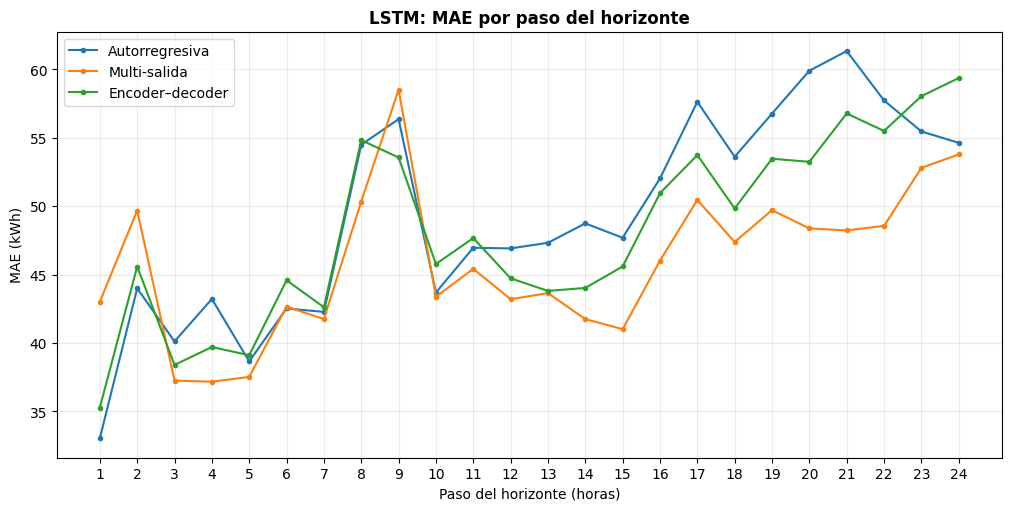

La interpretación sobre acumulación de errores queda pendiente de discutir a partir de la gráfica.


In [11]:
class AutoregressiveLSTMNetwork(nn.Module):
    def __init__(self, feature_count=8, hidden_size=32, horizon_length=24):
        super().__init__()
        self.horizon_length = horizon_length
        self.recurrent = nn.LSTM(feature_count, hidden_size, num_layers=1, batch_first=True)
        self.output_dropout = nn.Dropout(0.1)
        self.output_projection = nn.Linear(hidden_size, 1)

    def forward(self, history_windows, future_calendars=None):
        sequence_representations, recurrent_states = self.recurrent(history_windows)
        current_prediction = self.output_projection(self.output_dropout(recurrent_states[0][-1]))
        if future_calendars is None:
            return current_prediction
        assert future_calendars.shape[1] == self.horizon_length
        predictions = [current_prediction]
        for horizon_position in range(1, self.horizon_length):
            recurrent_input = torch.cat([
                current_prediction, future_calendars[:, horizon_position - 1, :]
            ], dim=1).unsqueeze(1)
            recurrent_output, recurrent_states = self.recurrent(recurrent_input, recurrent_states)
            current_prediction = self.output_projection(self.output_dropout(recurrent_output[:, -1]))
            predictions.append(current_prediction)
        return torch.cat(predictions, dim=1)


class AutoregressiveLSTMForecaster(Seq2SeqForecaster):
    def __init__(self, scaler, training_reference, random_seed=123):
        super().__init__(scaler, training_reference, random_seed)
        self.model_name = "LSTM autorregresiva"

    def initialize_network(self, feature_count):
        torch.manual_seed(self.random_seed)
        self.network = AutoregressiveLSTMNetwork(
            feature_count, self.hidden_size, self.horizon_length
        ).to(self.device)
        return torch.optim.AdamW(
            self.network.parameters(), lr=self.learning_rate, weight_decay=self.weight_decay
        )

    def train_epoch(self, loader, optimizer):
        self.network.train()
        total_loss = 0.0
        example_count = 0
        for batch_number, ((history_windows, future_calendars), target_windows) in enumerate(loader, start=1):
            history_windows = history_windows.to(self.device)
            next_hour_targets = target_windows[:, :1].to(self.device)
            optimizer.zero_grad(set_to_none=True)
            next_hour_predictions = self.network(history_windows)
            loss = nn.functional.l1_loss(next_hour_predictions, next_hour_targets)
            if not torch.isfinite(loss).item():
                raise FloatingPointError("La pérdida autorregresiva no es finita.")
            loss.backward()
            nn.utils.clip_grad_norm_(self.network.parameters(), self.gradient_clip_norm, error_if_nonfinite=True)
            optimizer.step()
            self.record_gpu_memory()
            total_loss += loss.item() * len(history_windows)
            example_count += len(history_windows)
            if batch_number % 500 == 0:
                print(f"LSTM autorregresiva: {example_count:,} de {len(loader.dataset):,} ventanas de la época.", flush=True)
        self.synchronize_device()
        return total_loss / example_count


class FrozenLSTMStrategy:
    def __init__(self, checkpoint_path, strategy):
        self.checkpoint = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
        assert self.checkpoint["strategy"] == strategy
        assert self.checkpoint["client_columns"] == selected_clients.tolist()
        assert self.checkpoint["calendar_columns"] == calendar_train.columns.tolist()
        np.testing.assert_allclose(self.checkpoint["minmax_scale"].numpy(), electricity_scaler.scale_)
        np.testing.assert_allclose(self.checkpoint["minmax_min"].numpy(), electricity_scaler.min_)
        if strategy == "multi_output":
            self.forecaster = LSTMForecaster(electricity_scaler, electricity_train_original)
            self.forecaster.network = LSTMMultiOutputNetwork(
                self.checkpoint["feature_count"], self.checkpoint["hidden_size"], self.checkpoint["horizon_length"]
            )
        elif strategy == "encoder_decoder":
            self.forecaster = Seq2SeqForecaster(electricity_scaler, electricity_train_original)
            self.forecaster.network = CalendarSeq2SeqNetwork(
                self.checkpoint["feature_count"], self.checkpoint["calendar_feature_count"],
                self.checkpoint["hidden_size"], self.checkpoint["horizon_length"]
            )
        else:
            raise ValueError("Estrategia guardada no reconocida.")
        self.forecaster.network.load_state_dict(self.checkpoint["state_dict"])
        self.forecaster.network.to(self.forecaster.device).eval().requires_grad_(False)
        self.fit_calls = 0

    def fit(self, consumption_history, calendar_history):
        assert consumption_history.columns.tolist() == self.checkpoint["client_columns"]
        assert consumption_history.index.equals(calendar_history.index)
        self.forecaster.client_columns = consumption_history.columns.copy()
        self.forecaster.calendar_columns = calendar_history.columns.copy()
        self.fit_calls += 1
        return self

    def predict(self, consumption_window, calendar_window, future_calendar):
        return self.forecaster.predict(consumption_window, calendar_window, future_calendar)


assert len(selected_clients) == 100 and client_selection_seed == 123
autoregressive_lstm_model = AutoregressiveLSTMForecaster(electricity_scaler, electricity_train_original, random_seed=123)
autoregressive_backtest_start = perf_counter()
autoregressive_lstm_results = backtest(autoregressive_lstm_model, window_length=168, refit_monthly=False)
autoregressive_backtest_seconds = perf_counter() - autoregressive_backtest_start
autoregressive_parameter_count = sum(parameter.numel() for parameter in autoregressive_lstm_model.network.parameters())
multistep_artifact_directory = Path("data/processed")
autoregressive_checkpoint_path = multistep_artifact_directory / "lstm_autoregressive.pt"
torch.save({
    "state_dict": autoregressive_lstm_model.training_state,
    "window_length": 168, "feature_count": 8, "horizon_length": 24,
    "hidden_size": 32, "num_layers": 1, "output_dropout": 0.1,
    "strategy": "autoregressive", "training_horizon": 1,
    "recursive_state": "Reiniciado por contexto; se conserva entre pasos del mismo pronóstico",
    "client_columns": selected_clients.tolist(), "calendar_columns": calendar_train.columns.tolist(),
    "seed": 123, "selected_epochs": autoregressive_lstm_model.best_epoch,
    "minmax_scale": torch.from_numpy(electricity_scaler.scale_.copy()),
    "minmax_min": torch.from_numpy(electricity_scaler.min_.copy()),
    "torch_version": str(torch.__version__),
}, autoregressive_checkpoint_path)
autoregressive_lstm_model.selection_history.to_csv(multistep_artifact_directory / "lstm_autoregressive_selection_history.csv", index=False)
autoregressive_lstm_model.final_training_history.to_csv(multistep_artifact_directory / "lstm_autoregressive_final_training_history.csv", index=False)
autoregressive_lstm_results["resources"] = pd.Series({
    "Selección y ajuste final (s)": autoregressive_lstm_model.fit_seconds,
    "Inferencia de los 92 orígenes (s)": autoregressive_lstm_model.inference_seconds,
    "Backtest completo (s)": autoregressive_backtest_seconds,
    "Memoria GPU del controlador, máxima observada (MiB)": autoregressive_lstm_model.peak_gpu_memory_bytes / 1024**2,
}, name="Recursos")

print("Recuperando LSTM multi-salida y encoder–decoder; sus pesos no se volverán a entrenar.", flush=True)
multistep_saved_multi_output = FrozenLSTMStrategy(multistep_artifact_directory / "lstm_multi_output.pt", "multi_output")
multistep_saved_seq2seq = FrozenLSTMStrategy(multistep_artifact_directory / "seq2seq_calendar.pt", "encoder_decoder")
multistep_multi_output_results = backtest(multistep_saved_multi_output, window_length=168, refit_monthly=False)
multistep_seq2seq_results = backtest(multistep_saved_seq2seq, window_length=168, refit_monthly=False)
multistep_results = {
    "Autorregresiva": autoregressive_lstm_results,
    "Multi-salida": multistep_multi_output_results,
    "Encoder–decoder": multistep_seq2seq_results,
}
multistep_overall_metrics = pd.DataFrame({
    strategy_name: strategy_results["overall_metrics"]
    for strategy_name, strategy_results in multistep_results.items()
}).T.rename_axis("Estrategia")
multistep_horizon_mae = pd.DataFrame({
    strategy_name: strategy_results["metrics_by_horizon"]["MAE_kWh"]
    for strategy_name, strategy_results in multistep_results.items()
})
multistep_horizon_mae.index.name = "Paso del horizonte"
multistep_endpoint_metrics = pd.DataFrame({
    "MAE primera hora (kWh)": multistep_horizon_mae.iloc[0],
    "MAE última hora (kWh)": multistep_horizon_mae.iloc[-1],
    "Cambio primera a última hora (kWh)": multistep_horizon_mae.iloc[-1] - multistep_horizon_mae.iloc[0],
}).rename_axis("Estrategia")
for strategy_name, strategy_results in multistep_results.items():
    strategy_forecasts = strategy_results["forecasts"].copy()
    strategy_forecasts["modelo"] = strategy_name
    strategy_file_names = {
        "Autorregresiva": "lstm_autoregressive_test_forecasts.csv",
        "Multi-salida": "lstm_multi_output_test_forecasts.csv",
        "Encoder–decoder": "seq2seq_test_forecasts.csv",
    }
    strategy_forecasts.to_csv(multistep_artifact_directory / strategy_file_names[strategy_name], index=False)
multistep_overall_metrics.to_csv(multistep_artifact_directory / "multistep_overall_metrics.csv")
multistep_horizon_mae.to_csv(multistep_artifact_directory / "multistep_mae_by_horizon.csv")
multistep_endpoint_metrics.to_csv(multistep_artifact_directory / "multistep_endpoint_metrics.csv")

autoregressive_configuration = pd.Series({
    "Modelo": "LSTM autorregresiva global", "Clientes": 100, "Semilla": 123,
    "Ventana inicial (horas)": 168, "Horizonte de evaluación (horas)": 24,
    "Objetivo de entrenamiento": "Consumo real de la siguiente hora",
    "Estado oculto": 32, "Capas recurrentes": 1, "Dropout de salida": 0.1,
    "Realimentación en validación y prueba": "Predicción anterior y su calendario",
    "Estados recurrentes": "Reiniciados por contexto y conservados dentro de sus 24 pasos",
    "Optimizador": "AdamW", "Learning rate": autoregressive_lstm_model.learning_rate,
    "Weight decay": autoregressive_lstm_model.weight_decay,
    "Batch": autoregressive_lstm_model.batch_size,
    "Máximo de épocas": autoregressive_lstm_model.maximum_epochs,
    "Paciencia": autoregressive_lstm_model.patience,
    "Épocas seleccionadas": autoregressive_lstm_model.best_epoch,
    "Parámetros entrenables": autoregressive_parameter_count,
}, name="Configuración")
display(autoregressive_configuration.to_frame())
display(autoregressive_lstm_model.selection_history.round(5))
display(autoregressive_lstm_results["resources"].to_frame().round(4))
print("Métricas de las tres estrategias, mismas fechas y clientes")
display(multistep_overall_metrics.round(4))
print("MAE por paso del horizonte")
display(multistep_horizon_mae.round(4))
print("Error de la primera y última hora")
display(multistep_endpoint_metrics.round(4))
multistep_figure, multistep_axis = plt.subplots(figsize=(10, 5), layout="constrained")
for strategy_name in multistep_horizon_mae.columns:
    multistep_axis.plot(multistep_horizon_mae.index, multistep_horizon_mae[strategy_name], marker="o", markersize=3, label=strategy_name)
multistep_axis.set_title("LSTM: MAE por paso del horizonte", fontweight="bold")
multistep_axis.set(xlabel="Paso del horizonte (horas)", ylabel="MAE (kWh)", xticks=range(1, 25))
multistep_axis.legend()
multistep_axis.grid(alpha=0.25)
multistep_figure.savefig(multistep_artifact_directory / "multistep_mae_by_horizon.png", dpi=180)
plt.show()
print("La interpretación sobre acumulación de errores queda pendiente de discutir a partir de la gráfica.")


## **5.2 Iteraciones de hiperparámetros**

Se realizarán dos experimentos separados para cambiar un factor a la vez. Primero, se compararán ventanas de 48, 168 y 336 horas con DLinear y toda la historia de entrenamiento. Después se compararán 3, 12 y 30 meses de historia con seasonal naive, LightGBM, DLinear, LSTM multi-salida y PatchTST, manteniendo una ventana de 168 horas.

- **Condiciones comunes:** Se conservarán los mismos 100 clientes, semilla 123, horizonte de 24 y particiones temporales de validación y prueba. La LSTM multi-salida se eligió como recurrente a partir de su MASE de validación, sin utilizar prueba para esa decisión.
- **Meses de historia:** Los 3, 12 y 30 meses se cuentan antes del bloque de validación y terminan el 30 de junio de 2014. La validación permanece en julio–septiembre. Después de seleccionar la configuración se incorporan esos tres meses al ajuste final, por lo que las historias finales abarcan 6, 15 y 33 meses, respectivamente. Se registran ambas duraciones y sus fechas.
- **Normalización y MASE:** Cada iteración ajustará su propio MinMax únicamente con su historia de entrenamiento, sin recortar los valores de validación o prueba. Para comparar MASE se mantendrá una referencia común, calculada con el error estacional de 24 horas en el bloque original de entrenamiento. Esa referencia se utiliza para evaluar, sin entrar como variable al modelo.
- **Selección:** Se elegirá el menor MASE de validación. Primero se completan las 17 configuraciones y se guarda la selección; después se realiza el ajuste final y la evaluación de prueba. Los resultados de prueba no se utilizarán para cambiar las decisiones.
- **Redes propias:** DLinear conservará su descomposición con media móvil de 25 horas, AdamW y su configuración inicial. La LSTM conservará una capa con estado oculto de 32 y salida directa de 24 valores. Se registrarán pérdida de entrenamiento, pérdida de validación, MAE y MASE al final de cada época, junto con sus tiempos.
- **PatchTST:** Se mantienen parches de 24 horas, desplazamiento de 12, dos capas, cuatro cabezas, representación de 64 y feedforward de 128. Se utiliza el máximo de 1000 actualizaciones. Una época de NeuralForecast recorre los lotes de series y muestrea ventanas dentro de ellas; se registran tanto época como paso del optimizador. Se evalúa cada época y se mantiene una paciencia equivalente a 300 actualizaciones, que son 12 épocas de 25 pasos.
- **Modelos sin épocas neuronales:** LightGBM utilizará un hilo de CPU para evitar la espera entre las bibliotecas de hilos de este entorno, conservará 200 árboles y registrará pérdida y validación autorregresiva cada 10 rondas. Esa pérdida de entrenamiento corresponde a predicciones de un paso, mientras la validación completa pronostica las 24 horas. Seasonal naive no aprende pesos ni tiene épocas; se selecciona su período de 24 o 168 con validación y se registra esa condición.
- **Reutilización y recuperación:** Se aprovecharán los pesos y registros de la LSTM de 30 meses si coinciden con los clientes, escalador y criterio de selección. Las demás iteraciones se guardan por separado, con registros y checkpoints para poder recuperar el trabajo.
- **Resultados:** Se generarán curvas de pérdida para las tres ventanas de DLinear, la comparación de MASE por ventana y las curvas por meses de historia. Chronos-Bolt quedará como referencia fija en la gráfica de prueba. Se reportan tiempos, parámetros y memoria del controlador GPU máxima observada; los modelos en CPU se identifican por separado.

In [12]:
from contextlib import contextmanager
from pathlib import Path
from time import perf_counter
import gc
import hashlib
import json
import re

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from neuralforecast.models import PatchTST
from neuralforecast.losses.pytorch import MAE
from pytorch_lightning import Callback
from sklearn.preprocessing import MinMaxScaler
from statsforecast.models import SeasonalNaive


class ExperimentLightGBM(GlobalLightGBM):

    def fit(self, consumption_history, calendar_history):
        fit_start = perf_counter()
        self.client_columns = consumption_history.columns.copy()
        self.calendar_columns = calendar_history.columns.copy()
        training_features, training_targets = self.build_training_examples(consumption_history, calendar_history)
        self.training_observations = len(training_targets)
        self.estimator = lgb.LGBMRegressor(objective='regression_l1', n_estimators=200, learning_rate=0.05, num_leaves=31, max_depth=8, min_child_samples=100, max_bin=63, random_state=self.random_seed, n_jobs=1, deterministic=True, force_col_wise=True, verbosity=-1)
        print(f'LightGBM: ajuste global con {self.training_observations:,} ejemplos.', flush=True)
        self.estimator.fit(training_features, training_targets, feature_name=self.feature_names, categorical_feature=[len(self.feature_names) - 1])
        self.fit_seconds += perf_counter() - fit_start
        return self

    def predict(self, consumption_window, calendar_window, future_calendar):
        inference_start = perf_counter()
        assert consumption_window.columns.equals(self.client_columns)
        assert future_calendar.columns.equals(self.calendar_columns)
        assert len(consumption_window) >= max(self.lag_hours)
        client_count = len(self.client_columns)
        history_length = len(consumption_window)
        horizon_length = len(future_calendar)
        consumption_buffer = np.empty((history_length + horizon_length, client_count), dtype=float)
        consumption_buffer[:history_length] = consumption_window.to_numpy()
        prediction_features = np.empty((client_count, len(self.feature_names)), dtype=np.float32)
        prediction_features[:, -1] = np.arange(client_count)
        for horizon_position in range(horizon_length):
            target_position = history_length + horizon_position
            for feature_position, lag_hour in enumerate(self.lag_hours):
                prediction_features[:, feature_position] = consumption_buffer[target_position - lag_hour]
            prediction_features[:, len(self.lag_hours):-1] = future_calendar.iloc[horizon_position].to_numpy()
            consumption_buffer[target_position] = self.estimator.booster_.predict(prediction_features, num_threads=1)
        predictions = pd.DataFrame(consumption_buffer[history_length:], index=future_calendar.index, columns=self.client_columns)
        self.inference_seconds += perf_counter() - inference_start
        return predictions

torch.set_num_threads(4)

experiment_directory = Path("data/processed/experiments_5_2")
experiment_directory.mkdir(parents=True, exist_ok=True)
experiment_train_original = electricity_train_original.copy()
experiment_val_original = electricity_val_original.copy()
experiment_test_original = electricity_test_original.copy()
experiment_calendar_train = calendar_train.copy()
experiment_calendar_val = calendar_val.copy()
experiment_calendar_test = calendar_test.copy()
experiment_reference = experiment_train_original.diff(24).abs().mean()
experiment_device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
experiment_schema = "5.2-mase-v1"


def experiment_json(value):
    if isinstance(value, dict):
        return {str(key): experiment_json(item) for key, item in value.items()}
    if isinstance(value, (list, tuple)):
        return [experiment_json(item) for item in value]
    if isinstance(value, (pd.Timestamp, Path)):
        return str(value)
    if isinstance(value, np.generic):
        value = value.item()
    if isinstance(value, float) and not np.isfinite(value):
        return None
    return value


def save_experiment_json(path, value):
    path.write_text(json.dumps(experiment_json(value), indent=2, ensure_ascii=False, allow_nan=False))


def build_experiment_context(history_months, window_length):
    history_start = experiment_train_original.index.max() + pd.Timedelta(hours=1) - pd.DateOffset(months=history_months)
    training_original = experiment_train_original.loc[history_start:]
    scaler = MinMaxScaler(clip=False).fit(training_original)
    normalized_train = pd.DataFrame(scaler.transform(training_original), index=training_original.index, columns=training_original.columns)
    normalized_val = pd.DataFrame(scaler.transform(experiment_val_original), index=experiment_val_original.index, columns=training_original.columns)
    assert scaler.n_samples_seen_ == len(training_original)
    np.testing.assert_array_equal(scaler.data_min_, training_original.min().to_numpy())
    np.testing.assert_array_equal(scaler.data_max_, training_original.max().to_numpy())
    assert training_original.index.max() < experiment_val_original.index.min()
    context = {
        "months": history_months, "window": window_length, "scaler": scaler,
        "train_original": training_original, "train": normalized_train, "val": normalized_val,
        "calendar_train": experiment_calendar_train.loc[training_original.index],
        "calendar_val": experiment_calendar_val,
        "selection_train_start": training_original.index.min(),
        "selection_train_end": training_original.index.max(),
        "final_fit_start": training_original.index.min(),
        "final_fit_end": experiment_val_original.index.max(),
        "final_fit_months": history_months + 3,
    }
    assert len(training_original) > window_length + 24
    return context


def experiment_metrics(normalized_predictions, normalized_targets, context):
    unit_factors = 1 / context["scaler"].scale_
    absolute_errors = np.abs(np.asarray(normalized_predictions) - np.asarray(normalized_targets))
    original_errors = absolute_errors * unit_factors.reshape(1, -1)
    reference_values = experiment_reference.to_numpy()
    valid_reference = np.isfinite(reference_values) & (reference_values > 0)
    return {
        "validation_loss": float(absolute_errors.mean()),
        "validation_MAE_kWh": float(original_errors.mean()),
        "validation_MASE": float((original_errors[:, valid_reference] / reference_values[valid_reference]).mean()),
    }


def make_experiment_datasets(context):
    training_dataset = PanelWindowDataset(
        context["train"], context["calendar_train"], context["train"].index.min(), context["train"].index.max(),
        window_length=context["window"], horizon_length=24,
    )
    validation_dataset = PanelWindowDataset(
        pd.concat([context["train"], context["val"]]),
        pd.concat([context["calendar_train"], context["calendar_val"]]),
        experiment_val_original.index.min(), experiment_val_original.index.max(),
        window_length=context["window"], horizon_length=24,
    )
    assert len(validation_dataset) == 218500
    return training_dataset, validation_dataset


def prior_lstm_resources():
    source_notebook = json.loads(Path("Laboratorio_9_Series_de_Tiempo.ipynb").read_text())
    source_cell = next(cell for cell in source_notebook["cells"] if cell["id"] == "codigo-lstm")
    resources = {}
    for output in source_cell.get("outputs", []):
        output_text = output.get("data", {}).get("text/plain", "")
        if isinstance(output_text, list):
            output_text = "".join(output_text)
        if "Recursos" in output_text and "Selección y ajuste" in output_text:
            for output_line in output_text.splitlines():
                numeric_match = re.search(r"(-?\d+(?:\.\d+)?)\s*$", output_line)
                if numeric_match:
                    if "Selección y ajuste" in output_line:
                        resources["fit_seconds"] = float(numeric_match.group(1))
                    elif "Inferencia de los 92" in output_line:
                        resources["inference_seconds"] = float(numeric_match.group(1))
                    elif "Memoria GPU" in output_line:
                        resources["peak_gpu_mib"] = float(numeric_match.group(1))
    return resources


def select_torch_experiment(model_name, context, case_directory):
    if model_name == "DLinear":
        model = DLinearForecaster(context["scaler"], experiment_train_original, random_seed=123)
    else:
        model = LSTMForecaster(context["scaler"], experiment_train_original, random_seed=123)
    model.window_length = context["window"]
    model.client_columns = context["train"].columns.copy()
    model.calendar_columns = context["calendar_train"].columns.copy()
    training_dataset, validation_dataset = make_experiment_datasets(context)
    training_loader = model.create_loader(training_dataset, shuffle=True)
    validation_loader = model.create_loader(validation_dataset, shuffle=False)
    optimizer = model.initialize_network(feature_count=8)
    best_mase = np.inf
    checks_without_improvement = 0
    epoch_records = []
    selection_start = perf_counter()
    for epoch_number in range(1, model.maximum_epochs + 1):
        training_start = perf_counter()
        training_loss = model.train_epoch(training_loader, optimizer)
        training_seconds = perf_counter() - training_start
        validation_start = perf_counter()
        validation_metrics = model.evaluate_validation(validation_loader)
        validation_seconds = perf_counter() - validation_start
        epoch_records.append({
            "epoch": epoch_number, "training_loss": training_loss, **validation_metrics,
            "training_seconds": training_seconds, "validation_seconds": validation_seconds,
        })
        pd.DataFrame(epoch_records).to_csv(case_directory / "selection_history.csv", index=False)
        if validation_metrics["validation_MASE"] < best_mase - 0.000001:
            best_mase = validation_metrics["validation_MASE"]
            selected_epoch = epoch_number
            checks_without_improvement = 0
            torch.save({parameter_name: parameter.detach().cpu().clone() for parameter_name, parameter in model.network.state_dict().items()}, case_directory / "selection_weights.pt")
        else:
            checks_without_improvement += 1
        print(f"{case_directory.name} · época {epoch_number}: train={training_loss:.5f}, val_MAE={validation_metrics['validation_MAE_kWh']:.2f}, val_MASE={validation_metrics['validation_MASE']:.4f}.", flush=True)
        if checks_without_improvement >= model.patience:
            break
    selection_seconds = perf_counter() - selection_start
    selection_history = pd.DataFrame(epoch_records)
    best_record = selection_history.loc[selection_history["epoch"] == selected_epoch].iloc[0]
    parameter_count = sum(parameter.numel() for parameter in model.network.parameters())
    result = {
        "selected_duration": selected_epoch, "duration_unit": "epoch", "selection_seconds": selection_seconds,
        "parameter_count": parameter_count, "trainable_parameters": parameter_count,
        "peak_gpu_mib": model.peak_gpu_memory_bytes / 1024**2,
        "validation_MASE": best_record["validation_MASE"], "validation_MAE_kWh": best_record["validation_MAE_kWh"],
        "validation_loss": best_record["validation_loss"], "selection_reused": False,
        "maximum_epochs": model.maximum_epochs, "patience": model.patience,
        "batch_size": model.batch_size, "learning_rate": model.learning_rate, "weight_decay": model.weight_decay,
        "hardware": str(model.device),
    }
    del model, optimizer, training_loader, validation_loader
    return result


class PatchEpochMonitor(Callback):
    def __init__(self, experiment_model, context, case_directory, selecting):
        self.experiment_model = experiment_model
        self.context = context
        self.case_directory = case_directory
        self.selecting = selecting
        self.records = []
        self.best_mase = np.inf
        self.checks_without_improvement = 0
        self.previous_step = 0
        self.epoch_start = perf_counter()

    def on_train_batch_end(self, trainer, network, outputs, batch, batch_idx):
        self.experiment_model.record_gpu_memory()

    def on_train_epoch_end(self, trainer, network):
        epoch_number = len(self.records) + 1
        current_step = int(trainer.global_step)
        if current_step == self.previous_step:
            return
        training_loss = float(np.mean([entry[1] for entry in network.train_trajectories[self.previous_step:current_step]]))
        training_seconds = perf_counter() - self.epoch_start
        record = {"epoch": epoch_number, "step": current_step, "training_loss": training_loss, "training_seconds": training_seconds}
        if self.selecting:
            validation_start = perf_counter()
            was_training = network.training
            network.eval()
            validation_metrics = self.experiment_model.evaluate_validation(network)
            network.train(was_training)
            record.update(validation_metrics)
            record["validation_seconds"] = perf_counter() - validation_start
            if validation_metrics["validation_MASE"] < self.best_mase - 0.000001:
                self.best_mase = validation_metrics["validation_MASE"]
                self.experiment_model.best_step = current_step
                self.checks_without_improvement = 0
                torch.save({parameter_name: parameter.detach().cpu().clone() for parameter_name, parameter in network.state_dict().items()}, self.case_directory / "selection_weights.pt")
            else:
                self.checks_without_improvement += 1
            if self.checks_without_improvement >= 12:
                trainer.should_stop = True
            print(f"{self.case_directory.name} · época {epoch_number}, paso {current_step}: val_MAE={record['validation_MAE_kWh']:.2f}, val_MASE={record['validation_MASE']:.4f}.", flush=True)
        self.records.append(record)
        history_filename = "selection_history.csv" if self.selecting else "final_training_history.csv"
        pd.DataFrame(self.records).to_csv(self.case_directory / history_filename, index=False)
        self.previous_step = current_step
        self.epoch_start = perf_counter()


def make_patch_experiment(context, maximum_steps, callback):
    model = PatchTSTForecaster(context["scaler"], experiment_train_original, random_seed=123)
    model.client_columns = context["train"].columns.copy()
    model.calendar_columns = context["calendar_train"].columns.copy()
    model.validation_check_steps = 25
    forecast_model = model.create_forecast_model(maximum_steps, callback, selecting=False)
    return model, forecast_model


def select_patch_experiment(context, case_directory):
    model, forecast_model = make_patch_experiment(context, 1000, Callback())
    training_dataset, validation_dataset = make_experiment_datasets(context)
    model.validation_dataset = validation_dataset
    monitor = PatchEpochMonitor(model, context, case_directory, selecting=True)
    forecast_model.models[0].trainer_kwargs["callbacks"] = [monitor]
    selection_start = perf_counter()
    forecast_model.fit(df=model.to_long_panel(context["train"], context["calendar_train"]), val_size=0)
    selection_seconds = perf_counter() - selection_start
    history = pd.DataFrame(monitor.records)
    assert not history.empty and model.best_step is not None
    best_record = history.loc[history["step"] == model.best_step].iloc[0]
    parameter_count = sum(parameter.numel() for parameter in forecast_model.models[0].parameters())
    result = {
        "selected_duration": int(model.best_step), "selected_epoch": int(best_record["epoch"]),
        "duration_unit": "optimizer_step", "selection_seconds": selection_seconds,
        "parameter_count": parameter_count,
        "trainable_parameters": sum(parameter.numel() for parameter in forecast_model.models[0].parameters() if parameter.requires_grad),
        "peak_gpu_mib": model.peak_gpu_memory_bytes / 1024**2,
        "validation_MASE": best_record["validation_MASE"], "validation_MAE_kWh": best_record["validation_MAE_kWh"],
        "validation_loss": best_record["validation_loss"], "selection_reused": False,
        "maximum_steps": 1000, "steps_per_epoch": 25, "patience_epochs": 12,
        "batch_size_series": 4, "windows_per_step": 256, "learning_rate": 0.0005,
        "hardware": str(model.device),
    }
    del model, forecast_model, training_dataset, validation_dataset
    return result


def rolling_validation_predictions(model, context, tree_count=None):
    validation_origins = pd.date_range("2014-07-01", "2014-09-30", freq="D")
    full_consumption = pd.concat([context["train"], context["val"]])
    full_calendar = pd.concat([context["calendar_train"], context["calendar_val"]])
    if tree_count is None:
        prediction_batches = []
        for origin_timestamp in validation_origins:
            history_end = full_consumption.index.get_loc(origin_timestamp)
            history_window = full_consumption.iloc[history_end - 168:history_end]
            calendar_window = full_calendar.loc[history_window.index]
            future_timestamps = pd.date_range(origin_timestamp, periods=24, freq="h")
            prediction_batches.append(model.predict(history_window, calendar_window, full_calendar.loc[future_timestamps]).to_numpy())
        return np.concatenate(prediction_batches, axis=0)
    client_count = len(context["train"].columns)
    origin_positions = full_consumption.index.get_indexer(validation_origins)
    history_values = full_consumption.to_numpy()
    rolling_buffer = np.empty((len(validation_origins), 168 + 24, client_count), dtype=np.float64)
    rolling_buffer[:, :168] = history_values[origin_positions[:, None] + np.arange(-168, 0)]
    future_calendar_values = context["calendar_val"].to_numpy().reshape(len(validation_origins), 24, -1)
    feature_values = np.empty((len(validation_origins) * client_count, 33), dtype=np.float32)
    feature_values[:, -1] = np.tile(np.arange(client_count), len(validation_origins))
    for horizon_position in range(24):
        target_position = 168 + horizon_position
        for feature_position, lag_hour in enumerate(model.lag_hours):
            feature_values[:, feature_position] = rolling_buffer[:, target_position - lag_hour, :].reshape(-1)
        feature_values[:, 25:-1] = np.repeat(future_calendar_values[:, horizon_position], client_count, axis=0)
        rolling_buffer[:, target_position] = model.estimator.booster_.predict(feature_values, num_iteration=tree_count, num_threads=1).reshape(-1, client_count)
    return rolling_buffer[:, 168:].transpose(0, 1, 2).reshape(-1, client_count)


class SeasonalExperiment:
    def __init__(self, seasonal_period):
        self.seasonal_period = seasonal_period
        self.inference_seconds = 0.0

    def fit(self, consumption_history, calendar_history):
        self.client_columns = consumption_history.columns.copy()
        return self

    def predict(self, consumption_window, calendar_window, future_calendar):
        inference_start = perf_counter()
        predictions = pd.DataFrame({
            client_name: SeasonalNaive(season_length=self.seasonal_period).forecast(y=consumption_window[client_name].to_numpy(), h=24)["mean"]
            for client_name in self.client_columns
        }, index=future_calendar.index)
        self.inference_seconds += perf_counter() - inference_start
        return predictions


def select_seasonal_experiment(context, case_directory):
    candidate_records = []
    selection_start = perf_counter()
    for seasonal_period in [24, 168]:
        model = SeasonalExperiment(seasonal_period).fit(context["train"], context["calendar_train"])
        predictions = rolling_validation_predictions(model, context)
        candidate_records.append({"seasonal_period": seasonal_period, **experiment_metrics(predictions, context["val"].to_numpy(), context)})
    candidates = pd.DataFrame(candidate_records)
    candidates.to_csv(case_directory / "seasonal_candidates.csv", index=False)
    best_record = candidates.loc[candidates["validation_MASE"].idxmin()]
    return {
        "selected_duration": 0, "duration_unit": "not_applicable", "seasonal_period": int(best_record["seasonal_period"]),
        "selection_seconds": perf_counter() - selection_start, "parameter_count": 0, "trainable_parameters": 0,
        "peak_gpu_mib": 0.0, "hardware": "cpu", "selection_reused": False,
        **{metric_name: best_record[metric_name] for metric_name in ["validation_loss", "validation_MAE_kWh", "validation_MASE"]},
    }


def select_lightgbm_experiment(context, case_directory):
    model = ExperimentLightGBM(random_seed=123)
    model.client_columns = context["train"].columns.copy()
    model.calendar_columns = context["calendar_train"].columns.copy()
    training_features, training_targets = model.build_training_examples(context["train"], context["calendar_train"])
    model.estimator = lgb.LGBMRegressor(
        objective="regression_l1", n_estimators=200, learning_rate=0.05, num_leaves=31,
        max_depth=8, min_child_samples=100, max_bin=63, random_state=123, n_jobs=1,
        deterministic=True, force_col_wise=True, verbosity=-1,
    )
    iteration_records = []
    previous_time = perf_counter()
    def evaluate_boosting_iteration(callback_environment):
        nonlocal previous_time
        iteration_number = callback_environment.iteration + 1
        if iteration_number % 10:
            return
        training_seconds = perf_counter() - previous_time
        validation_start = perf_counter()
        class BoosterView:
            def __init__(self, booster):
                self.booster_ = booster
        saved_estimator = model.estimator
        model.estimator = BoosterView(callback_environment.model)
        try:
            predictions = rolling_validation_predictions(model, context, tree_count=iteration_number)
        finally:
            model.estimator = saved_estimator
        validation_metrics = experiment_metrics(predictions, context["val"].to_numpy(), context)
        training_loss = next(result[2] for result in callback_environment.evaluation_result_list if result[1] == "l1")
        iteration_records.append({
            "iteration": iteration_number, "training_loss": training_loss, **validation_metrics,
            "training_seconds": training_seconds, "validation_seconds": perf_counter() - validation_start,
        })
        pd.DataFrame(iteration_records).to_csv(case_directory / "selection_history.csv", index=False)
        if iteration_number % 50 == 0:
            print(f"{case_directory.name} · árbol {iteration_number}: val_MASE={validation_metrics['validation_MASE']:.4f}.", flush=True)
        previous_time = perf_counter()
    evaluate_boosting_iteration.order = 30
    selection_start = perf_counter()
    model.estimator.fit(
        training_features, training_targets, feature_name=model.feature_names,
        categorical_feature=[len(model.feature_names) - 1], eval_set=[(training_features, training_targets)],
        eval_names=["training"], callbacks=[evaluate_boosting_iteration],
    )
    selection_seconds = perf_counter() - selection_start
    model.estimator.booster_.save_model(str(case_directory / "selection_lightgbm.txt"))
    history = pd.DataFrame(iteration_records)
    best_record = history.iloc[-1]
    tree_details = model.estimator.booster_.dump_model()["tree_info"]
    parameter_count = sum(tree_details_item["num_leaves"] for tree_details_item in tree_details)
    result = {
        "selected_duration": 200, "duration_unit": "boosting_round", "selection_seconds": selection_seconds,
        "parameter_count": parameter_count, "trainable_parameters": parameter_count,
        "peak_gpu_mib": 0.0, "hardware": "cpu, 1 thread", "selection_reused": False,
        "validation_MASE": best_record["validation_MASE"], "validation_MAE_kWh": best_record["validation_MAE_kWh"],
        "validation_loss": best_record["validation_loss"], "learning_rate": 0.05,
        "num_leaves": 31, "max_depth": 8, "n_estimators": 200,
    }
    del model, training_features, training_targets
    return result


def reuse_full_lstm_selection(context, case_directory):
    checkpoint = torch.load("data/processed/lstm_multi_output.pt", map_location="cpu", weights_only=True)
    history = pd.read_csv("data/processed/lstm_selection_history.csv")
    best_record = history.loc[history["validation_MASE"].idxmin()]
    assert int(best_record["epoch"]) == checkpoint["selected_epochs"] == 6
    assert checkpoint["client_columns"] == selected_clients.tolist()
    np.testing.assert_allclose(checkpoint["minmax_scale"].numpy(), context["scaler"].scale_)
    np.testing.assert_allclose(checkpoint["minmax_min"].numpy(), context["scaler"].min_)
    history.to_csv(case_directory / "selection_history.csv", index=False)
    pd.read_csv("data/processed/lstm_final_training_history.csv").to_csv(case_directory / "final_training_history.csv", index=False)
    torch.save(checkpoint["state_dict"], case_directory / "selection_weights.pt")
    resources = prior_lstm_resources()
    assert "peak_gpu_mib" in resources
    return {
        "selected_duration": 6, "duration_unit": "epoch", "selection_seconds": float((history["training_seconds"] + history["validation_seconds"]).sum()),
        "parameter_count": sum(parameter.numel() for parameter in checkpoint["state_dict"].values()),
        "trainable_parameters": sum(parameter.numel() for parameter in checkpoint["state_dict"].values()),
        "peak_gpu_mib": resources["peak_gpu_mib"], "prior_fit_seconds": resources["fit_seconds"], "prior_inference_seconds": resources["inference_seconds"],
        "validation_MASE": best_record["validation_MASE"], "validation_MAE_kWh": best_record["validation_MAE_kWh"],
        "validation_loss": best_record["validation_loss"], "selection_reused": True,
        "maximum_epochs": 6, "patience": 2, "batch_size": 1024,
        "learning_rate": 0.001, "weight_decay": 0.0001, "hardware": "mps",
    }


def run_experiment_selection():
    configurations = [
        {"model": "DLinear", "window": window_length, "months": 30}
        for window_length in [48, 168, 336]
    ]
    for model_name in ["SeasonalNaive", "LightGBM", "DLinear", "LSTM", "PatchTST"]:
        for history_months in [3, 12, 30]:
            configuration = {"model": model_name, "window": 168, "months": history_months}
            if configuration not in configurations:
                configurations.append(configuration)
    assert len(configurations) == 17
    results = []
    for configuration in configurations:
        case_name = f"{configuration['model']}_L{configuration['window']}_M{configuration['months']}"
        case_directory = experiment_directory / case_name
        case_directory.mkdir(exist_ok=True)
        selection_path = case_directory / "selection_result.json"
        context = build_experiment_context(configuration["months"], configuration["window"])
        if selection_path.exists():
            result = json.loads(selection_path.read_text())
            assert result["schema"] == experiment_schema
            assert result["client_columns"] == selected_clients.tolist()
            print(f"{case_name}: selección recuperada del registro.", flush=True)
        else:
            print(f"Iniciando {case_name}: entrenamiento {context['selection_train_start']} a {context['selection_train_end']}.", flush=True)
            if configuration["model"] == "DLinear":
                result = select_torch_experiment("DLinear", context, case_directory)
            elif configuration["model"] == "LSTM" and configuration["months"] == 30:
                result = reuse_full_lstm_selection(context, case_directory)
            elif configuration["model"] == "LSTM":
                result = select_torch_experiment("LSTM", context, case_directory)
            elif configuration["model"] == "PatchTST":
                result = select_patch_experiment(context, case_directory)
            elif configuration["model"] == "LightGBM":
                result = select_lightgbm_experiment(context, case_directory)
            else:
                result = select_seasonal_experiment(context, case_directory)
            result.update({
                **configuration, "case": case_name, "schema": experiment_schema,
                "client_columns": selected_clients.tolist(),
                "selection_train_start": context["selection_train_start"], "selection_train_end": context["selection_train_end"],
                "final_fit_start": context["final_fit_start"], "final_fit_end": context["final_fit_end"],
                "final_fit_months": context["final_fit_months"], "selection_complete": True,
            })
            save_experiment_json(selection_path, result)
            np.savez(case_directory / "scaler.npz", scale=context["scaler"].scale_, minimum=context["scaler"].min_, data_min=context["scaler"].data_min_, data_max=context["scaler"].data_max_)
        results.append(result)
        gc.collect()
        if experiment_device.type == "mps":
            torch.mps.empty_cache()
    selection_table = pd.DataFrame(results)
    selection_table.drop(columns=["client_columns"]).to_csv(experiment_directory / "selection_summary.csv", index=False)
    selected_cases = selection_table.loc[selection_table.groupby("model")["validation_MASE"].idxmin(), ["model", "case", "window", "months", "selected_duration", "validation_MASE"]]
    selected_cases.to_csv(experiment_directory / "selected_configurations.csv", index=False)
    save_experiment_json(experiment_directory / "selection_locked.json", {"schema": experiment_schema, "criterion": "validation_MASE", "cases": selected_cases.to_dict(orient="records"), "test_used_for_selection": False})
    print("Selección finalizada y bloqueada con validación; comienza ahora el ajuste final y la evaluación de prueba.", flush=True)
    return selection_table


@contextmanager
def experiment_backtest_context(context):
    replacement_values = {
        "electricity_train": context["train"], "electricity_val": context["val"],
        "electricity_test": pd.DataFrame(context["scaler"].transform(experiment_test_original), index=experiment_test_original.index, columns=experiment_test_original.columns),
        "electricity_train_original": context["train_original"],
        "electricity_val_original": experiment_val_original, "electricity_test_original": experiment_test_original,
        "calendar_train": context["calendar_train"], "calendar_val": context["calendar_val"],
        "calendar_test": experiment_calendar_test, "electricity_scaler": context["scaler"],
    }
    original_values = {variable_name: globals()[variable_name] for variable_name in replacement_values}
    globals().update(replacement_values)
    try:
        yield
    finally:
        globals().update(original_values)


class FittedExperimentAdapter:
    def __init__(self, model, context):
        self.model = model
        self.context = context
        self.fit_calls = 0

    def fit(self, consumption_history, calendar_history):
        assert consumption_history.index.min() == self.context["final_fit_start"]
        assert consumption_history.index.max() == self.context["final_fit_end"]
        assert consumption_history.columns.equals(selected_clients)
        self.fit_calls += 1
        return self

    def predict(self, consumption_window, calendar_window, future_calendar):
        return self.model.predict(consumption_window, calendar_window, future_calendar)


def common_forecast_mase(forecast_frame):
    reference_values = forecast_frame["unique_id"].map(experiment_reference).to_numpy()
    valid_reference = np.isfinite(reference_values) & (reference_values > 0)
    return float((np.abs(forecast_frame.loc[valid_reference, "y"].to_numpy() - forecast_frame.loc[valid_reference, "y_hat"].to_numpy()) / reference_values[valid_reference]).mean())


def final_torch_experiment(selection, context, case_directory):
    model = DLinearForecaster(context["scaler"], experiment_train_original, random_seed=123) if selection["model"] == "DLinear" else LSTMForecaster(context["scaler"], experiment_train_original, random_seed=123)
    model.window_length = context["window"]
    model.client_columns = context["train"].columns.copy()
    model.calendar_columns = context["calendar_train"].columns.copy()
    checkpoint_path = case_directory / "final_model.pt"
    final_metadata_path = case_directory / "final_training_result.json"
    if checkpoint_path.exists() and final_metadata_path.exists():
        final_metadata = json.loads(final_metadata_path.read_text())
        model.initialize_network(feature_count=8)
        model.network.load_state_dict(torch.load(checkpoint_path, map_location="cpu", weights_only=True)["state_dict"])
        model.network.eval()
        model.training_state = {parameter_name: parameter.detach().cpu().clone() for parameter_name, parameter in model.network.state_dict().items()}
        return model, final_metadata
    final_start = perf_counter()
    if selection["selection_reused"]:
        source_checkpoint = torch.load("data/processed/lstm_multi_output.pt", map_location="cpu", weights_only=True)
        model.initialize_network(feature_count=8)
        model.network.load_state_dict(source_checkpoint["state_dict"])
        final_fit_seconds = selection["prior_fit_seconds"] - selection["selection_seconds"]
        final_training_reused = True
    else:
        full_consumption = pd.concat([context["train"], context["val"]])
        full_calendar = pd.concat([context["calendar_train"], context["calendar_val"]])
        final_dataset = PanelWindowDataset(full_consumption, full_calendar, full_consumption.index.min(), full_consumption.index.max(), window_length=context["window"], horizon_length=24)
        final_loader = model.create_loader(final_dataset, shuffle=True)
        optimizer = model.initialize_network(feature_count=8)
        final_records = []
        for epoch_number in range(1, selection["selected_duration"] + 1):
            epoch_start = perf_counter()
            training_loss = model.train_epoch(final_loader, optimizer)
            final_records.append({"epoch": epoch_number, "training_loss": training_loss, "training_seconds": perf_counter() - epoch_start})
            pd.DataFrame(final_records).to_csv(case_directory / "final_training_history.csv", index=False)
            print(f"{case_directory.name} · ajuste final {epoch_number}/{selection['selected_duration']}: train={training_loss:.5f}.", flush=True)
        final_fit_seconds = perf_counter() - final_start
        final_training_reused = False
        del final_dataset, final_loader, optimizer
    model.network.eval()
    model.training_state = {parameter_name: parameter.detach().cpu().clone() for parameter_name, parameter in model.network.state_dict().items()}
    torch.save({"state_dict": model.training_state, "configuration": experiment_json(selection), "scaler_scale": torch.from_numpy(context["scaler"].scale_), "scaler_min": torch.from_numpy(context["scaler"].min_)}, checkpoint_path)
    final_metadata = {"final_fit_seconds": final_fit_seconds, "final_training_reused": final_training_reused, "peak_gpu_mib": max(selection["peak_gpu_mib"], model.peak_gpu_memory_bytes / 1024**2)}
    save_experiment_json(final_metadata_path, final_metadata)
    return model, final_metadata


def final_patch_experiment(selection, context, case_directory):
    model, forecast_model = make_patch_experiment(context, selection["selected_duration"], Callback())
    checkpoint_path = case_directory / "final_model.pt"
    final_metadata_path = case_directory / "final_training_result.json"
    if checkpoint_path.exists() and final_metadata_path.exists():
        model.forecast_model = forecast_model
        model.network = forecast_model.models[0].to(model.device)
        model.network.load_state_dict(torch.load(checkpoint_path, map_location="cpu", weights_only=True)["state_dict"])
        model.network.eval()
        model.training_state = {parameter_name: parameter.detach().cpu().clone() for parameter_name, parameter in model.network.state_dict().items()}
        return model, json.loads(final_metadata_path.read_text())
    final_monitor = PatchEpochMonitor(model, context, case_directory, selecting=False)
    forecast_model.models[0].trainer_kwargs["callbacks"] = [final_monitor]
    final_start = perf_counter()
    full_consumption = pd.concat([context["train"], context["val"]])
    full_calendar = pd.concat([context["calendar_train"], context["calendar_val"]])
    forecast_model.fit(df=model.to_long_panel(full_consumption, full_calendar), val_size=0)
    final_fit_seconds = perf_counter() - final_start
    model.forecast_model = forecast_model
    model.network = forecast_model.models[0].to(model.device).eval()
    model.training_state = {parameter_name: parameter.detach().cpu().clone() for parameter_name, parameter in model.network.state_dict().items()}
    torch.save({"state_dict": model.training_state, "configuration": experiment_json(selection), "scaler_scale": torch.from_numpy(context["scaler"].scale_), "scaler_min": torch.from_numpy(context["scaler"].min_)}, checkpoint_path)
    forecast_model.save(str(case_directory / "neuralforecast_model"), save_dataset=False, overwrite=True)
    final_metadata = {"final_fit_seconds": final_fit_seconds, "final_training_reused": False, "peak_gpu_mib": max(selection["peak_gpu_mib"], model.peak_gpu_memory_bytes / 1024**2)}
    save_experiment_json(final_metadata_path, final_metadata)
    return model, final_metadata


def final_lightgbm_experiment(selection, context, case_directory):
    model = ExperimentLightGBM(random_seed=123)
    model.client_columns = context["train"].columns.copy()
    model.calendar_columns = context["calendar_train"].columns.copy()
    final_model_path = case_directory / "final_lightgbm.txt"
    final_metadata_path = case_directory / "final_training_result.json"
    if final_model_path.exists() and final_metadata_path.exists():
        class SavedBooster:
            def __init__(self, model_path):
                self.booster_ = lgb.Booster(model_file=str(model_path))
        model.estimator = SavedBooster(final_model_path)
        model.feature_names = model.estimator.booster_.feature_name()
        return model, json.loads(final_metadata_path.read_text())
    final_start = perf_counter()
    model.fit(pd.concat([context["train"], context["val"]]), pd.concat([context["calendar_train"], context["calendar_val"]]))
    final_fit_seconds = perf_counter() - final_start
    model.estimator.booster_.save_model(str(final_model_path))
    final_metadata = {"final_fit_seconds": final_fit_seconds, "final_training_reused": False, "peak_gpu_mib": 0.0}
    save_experiment_json(final_metadata_path, final_metadata)
    return model, final_metadata


def run_experiment_final_evaluation(selection_table):
    locked_selection = json.loads((experiment_directory / "selection_locked.json").read_text())
    assert locked_selection["test_used_for_selection"] is False
    final_results = []
    for selection in selection_table.to_dict(orient="records"):
        case_directory = experiment_directory / selection["case"]
        final_result_path = case_directory / "test_result.json"
        if final_result_path.exists():
            final_results.append(json.loads(final_result_path.read_text()))
            print(f"{selection['case']}: prueba recuperada, sin volver a evaluarla.", flush=True)
            continue
        context = build_experiment_context(int(selection["months"]), int(selection["window"]))
        print(f"Ajuste final y prueba de {selection['case']}.", flush=True)
        if selection["model"] in ["DLinear", "LSTM"]:
            model, final_metadata = final_torch_experiment(selection, context, case_directory)
        elif selection["model"] == "PatchTST":
            model, final_metadata = final_patch_experiment(selection, context, case_directory)
        elif selection["model"] == "LightGBM":
            model, final_metadata = final_lightgbm_experiment(selection, context, case_directory)
        else:
            model = SeasonalExperiment(int(selection["seasonal_period"]))
            model.fit(pd.concat([context["train"], context["val"]]), pd.concat([context["calendar_train"], context["calendar_val"]]))
            final_metadata = {"final_fit_seconds": 0.0, "final_training_reused": False, "peak_gpu_mib": 0.0}
        if selection["model"] == "LSTM" and selection["selection_reused"]:
            forecasts = pd.read_csv("data/processed/lstm_multi_output_test_forecasts.csv", parse_dates=["ds", "cutoff", "fit_cutoff"], float_precision="round_trip")
            metrics = summarize_forecast_errors(forecasts)
            test_results = {"forecasts": forecasts, "overall_metrics": metrics}
            inference_seconds = selection["prior_inference_seconds"]
            predictions_reused = True
        else:
            adapter = FittedExperimentAdapter(model, context)
            with experiment_backtest_context(context):
                test_results = backtest(adapter, window_length=int(selection["window"]), refit_monthly=False)
            assert adapter.fit_calls == 1
            forecasts = test_results["forecasts"]
            inference_seconds = model.inference_seconds
            predictions_reused = False
        assert len(forecasts) == 220800
        np.testing.assert_array_equal(forecasts["y"].to_numpy(), experiment_test_original.to_numpy().reshape(-1))
        if hasattr(model, "network"):
            for parameter_name, trained_parameter in model.training_state.items():
                torch.testing.assert_close(model.network.state_dict()[parameter_name].detach().cpu(), trained_parameter, rtol=0, atol=0)
        forecasts = forecasts.copy()
        forecasts["modelo"] = selection["case"]
        forecasts.to_csv(case_directory / "test_forecasts.csv.gz", index=False, compression="gzip")
        test_metrics = test_results["overall_metrics"].to_dict()
        test_metrics["MASE"] = common_forecast_mase(forecasts)
        christmas_forecasts = forecasts.loc[(forecasts["ds"] >= "2014-12-22") & (forecasts["ds"] < "2014-12-29")]
        result = {
            **selection, **final_metadata,
            "test_MAE_kWh": test_metrics["MAE_kWh"], "test_RMSE_kWh": test_metrics["RMSE_kWh"],
            "test_WAPE_pct": test_metrics["WAPE_pct"], "test_MAPE_pct": test_metrics["MAPE_pct"],
            "zero_actual_count": test_metrics["zero_actual_count"], "test_MASE": test_metrics["MASE"],
            "christmas_week_MASE": common_forecast_mase(christmas_forecasts),
            "inference_seconds": inference_seconds, "predictions_reused": predictions_reused,
            "fit_seconds_total": selection["selection_seconds"] + final_metadata["final_fit_seconds"],
            "test_forecast_count": len(forecasts), "test_evaluations_in_this_experiment": 0 if predictions_reused else 1,
        }
        save_experiment_json(final_result_path, result)
        final_results.append(result)
        print(f"{selection['case']}: prueba MASE={result['test_MASE']:.4f}, MAE={result['test_MAE_kWh']:.2f} kWh.", flush=True)
        del model, forecasts, test_results
        gc.collect()
        if experiment_device.type == "mps":
            torch.mps.empty_cache()
    final_table = pd.DataFrame(final_results)
    final_table.drop(columns=["client_columns"]).to_csv(experiment_directory / "final_results.csv", index=False)
    return final_table


def plot_experiment_results(selection_table, final_table):
    validation_columns = ["model", "window", "months", "selected_duration", "duration_unit", "validation_MAE_kWh", "validation_MASE", "selection_reused"]
    print("Configuraciones seleccionadas únicamente con validación")
    display(pd.read_csv(experiment_directory / "selected_configurations.csv").round(5))
    print("Resumen de las 17 iteraciones")
    display(final_table[[*validation_columns, "final_fit_months", "test_MAE_kWh", "test_MASE", "fit_seconds_total", "inference_seconds"]].round(5))
    loss_figure, loss_axes = plt.subplots(1, 3, figsize=(15, 4), layout="constrained")
    for loss_axis, window_length in zip(loss_axes, [48, 168, 336]):
        case_name = f"DLinear_L{window_length}_M30"
        history = pd.read_csv(experiment_directory / case_name / "selection_history.csv")
        loss_axis.plot(history["epoch"], history["training_loss"], label="Entrenamiento")
        loss_axis.plot(history["epoch"], history["validation_loss"], label="Validación")
        loss_axis.set_title(f"DLinear · ventana de {window_length} horas", fontweight="bold")
        loss_axis.set(xlabel="Época", ylabel="MAE normalizado")
        loss_axis.grid(alpha=0.25)
        loss_axis.legend()
    loss_figure.savefig(experiment_directory / "dlinear_three_window_loss_curves.png", dpi=180)
    plt.show()
    window_table = selection_table.loc[(selection_table["model"] == "DLinear") & (selection_table["months"] == 30)].sort_values("window")
    window_figure, window_axis = plt.subplots(figsize=(7, 4), layout="constrained")
    window_axis.plot(window_table["window"], window_table["validation_MASE"], marker="o")
    window_axis.set_title("DLinear: ventana y MASE de validación", fontweight="bold")
    window_axis.set(xlabel="Ventana (horas)", ylabel="MASE de validación", xticks=[48, 168, 336])
    window_axis.grid(alpha=0.25)
    window_figure.savefig(experiment_directory / "dlinear_window_validation_mase.png", dpi=180)
    plt.show()
    history_figure, history_axes = plt.subplots(1, 2, figsize=(13, 4.5), layout="constrained")
    for model_name in ["SeasonalNaive", "LightGBM", "DLinear", "LSTM", "PatchTST"]:
        model_cases = final_table.loc[(final_table["model"] == model_name) & (final_table["window"] == 168)].sort_values("months")
        history_axes[0].plot(model_cases["months"], model_cases["validation_MASE"], marker="o", label=model_name)
        history_axes[1].plot(model_cases["months"], model_cases["test_MASE"], marker="o", label=model_name)
    chronos_forecasts = pd.read_csv("data/processed/chronos_bolt_test_forecasts.csv", parse_dates=["ds"])
    chronos_reference_mase = common_forecast_mase(chronos_forecasts)
    history_axes[1].axhline(chronos_reference_mase, linestyle="--", color="black", label="Chronos-Bolt Mini, referencia fija")
    for history_axis, title in zip(history_axes, ["MASE de validación", "MASE de prueba"]):
        history_axis.set_title(title, fontweight="bold")
        history_axis.set(xlabel="Meses de entrenamiento antes de validación", ylabel="MASE", xticks=[3, 12, 30])
        history_axis.grid(alpha=0.25)
        history_axis.legend(fontsize=8)
    history_figure.savefig(experiment_directory / "history_months_validation_and_test_mase.png", dpi=180)
    plt.show()
    print(f"Referencia fija de Chronos-Bolt en prueba: MASE={chronos_reference_mase:.5f}.")
    print("Los 3, 12 y 30 meses pertenecen al bloque previo a validación. El ajuste final incluye también julio–septiembre: 6, 15 y 33 meses.")
    print("La interpretación de las curvas queda pendiente de discutir antes de redactar la respuesta.")


In [14]:
experiment_selection_table = run_experiment_selection()
display(experiment_selection_table[["model", "window", "months", "selected_duration", "validation_MAE_kWh", "validation_MASE", "selection_reused"]].round(5))

DLinear_L48_M30: selección recuperada del registro.


DLinear_L168_M30: selección recuperada del registro.


DLinear_L336_M30: selección recuperada del registro.


SeasonalNaive_L168_M3: selección recuperada del registro.


SeasonalNaive_L168_M12: selección recuperada del registro.


...

PatchTST_L168_M3: selección recuperada del registro.


PatchTST_L168_M12: selección recuperada del registro.


PatchTST_L168_M30: selección recuperada del registro.


Selección finalizada y bloqueada con validación; comienza ahora el ajuste final y la evaluación de prueba.


,model,window,months,selected_duration,validation_MAE_kWh,validation_MASE,selection_reused
0,DLinear,48,30,4,35.43049,0.92423,False
1,DLinear,168,30,6,31.85749,0.86866,False
2,DLinear,336,30,4,31.98199,0.86637,False
3,SeasonalNaive,168,3,0,37.94802,0.99672,False
4,SeasonalNaive,168,12,0,37.94802,0.99672,False
5,SeasonalNaive,168,30,0,37.94802,0.99672,False
6,LightGBM,168,3,200,36.11971,1.08894,False
7,LightGBM,168,12,200,34.67048,0.94445,False
8,LightGBM,168,30,200,34.25317,0.93263,False
9,DLinear,168,3,12,31.79874,0.85560,False


**¿Una pérdida de entrenamiento más baja implica siempre un mejor MASE en validación?**

Respuesta pendiente de discutir a partir de las curvas y los registros de las iteraciones.

DLinear_L48_M30: prueba recuperada, sin volver a evaluarla.


DLinear_L168_M30: prueba recuperada, sin volver a evaluarla.


DLinear_L336_M30: prueba recuperada, sin volver a evaluarla.


SeasonalNaive_L168_M3: prueba recuperada, sin volver a evaluarla.


SeasonalNaive_L168_M12: prueba recuperada, sin volver a evaluarla.


...

PatchTST_L168_M30: prueba MASE=1.0331, MAE=42.76 kWh.


Configuraciones seleccionadas únicamente con validación


,model,case,window,months,selected_duration,validation_MASE
0,DLinear,DLinear_L168_M3,168,3,12,0.85560
1,LSTM,LSTM_L168_M30,168,30,6,1.08708
2,LightGBM,LightGBM_L168_M30,168,30,200,0.93263
3,PatchTST,PatchTST_L168_M3,168,3,750,0.96018
4,SeasonalNaive,SeasonalNaive_L168_M3,168,3,0,0.99672


Resumen de las 17 iteraciones


,model,window,months,selected_duration,duration_unit,validation_MAE_kWh,validation_MASE,selection_reused,final_fit_months,test_MAE_kWh,test_MASE,fit_seconds_total,inference_seconds
0,DLinear,48,30,4,epoch,35.43049,0.92423,False,33,41.79383,0.99915,45.57061,0.11146
1,DLinear,168,30,6,epoch,31.85749,0.86866,False,33,36.46805,0.89752,109.10214,0.12386
2,DLinear,336,30,4,epoch,31.98199,0.86637,False,33,36.19192,0.90257,123.36062,0.12845
3,SeasonalNaive,168,3,0,not_applicable,37.94802,0.99672,False,6,43.45062,1.05499,0.23106,0.09411
4,SeasonalNaive,168,12,0,not_applicable,37.94802,0.99672,False,15,43.45062,1.05499,0.22547,0.09310
5,SeasonalNaive,168,30,0,not_applicable,37.94802,0.99672,False,33,43.45062,1.05499,0.22609,0.09219
6,LightGBM,168,3,200,boosting_round,36.11971,1.08894,False,6,39.12720,1.11205,31.18879,1.94823
7,LightGBM,168,12,200,boosting_round,34.67048,0.94445,False,15,35.89806,0.92446,57.83118,1.95854
8,LightGBM,168,30,200,boosting_round,34.25317,0.93263,False,33,36.77688,0.93229,118.95313,1.70824
9,DLinear,168,3,12,epoch,31.79874,0.85560,False,6,41.07160,0.98706,27.93484,0.11837


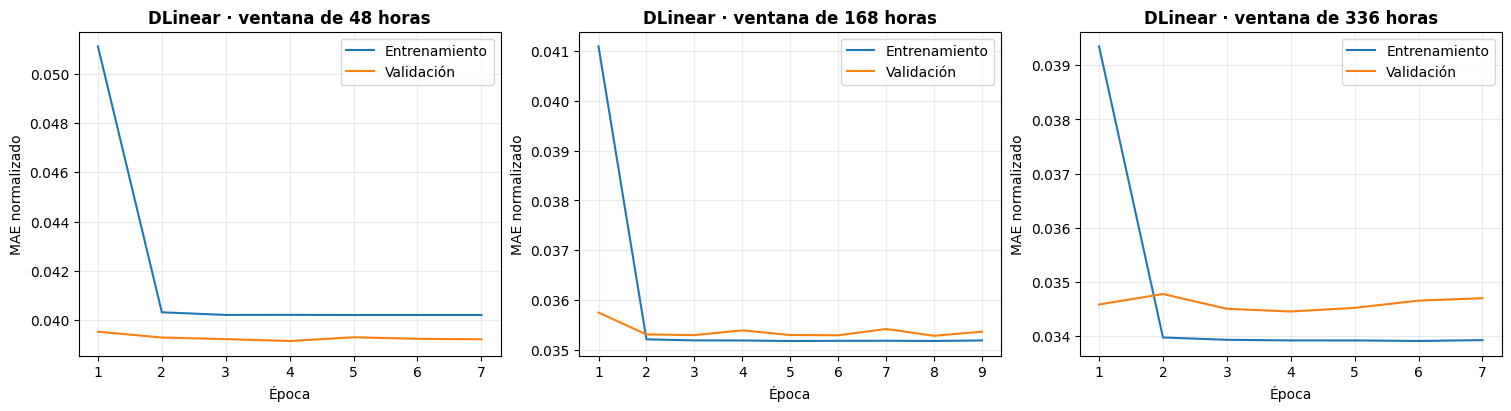

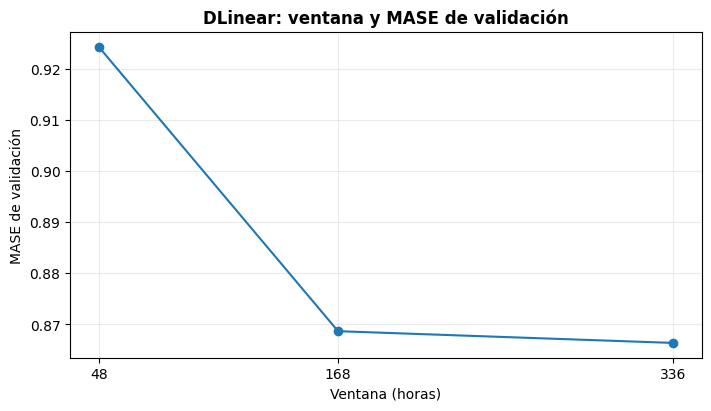

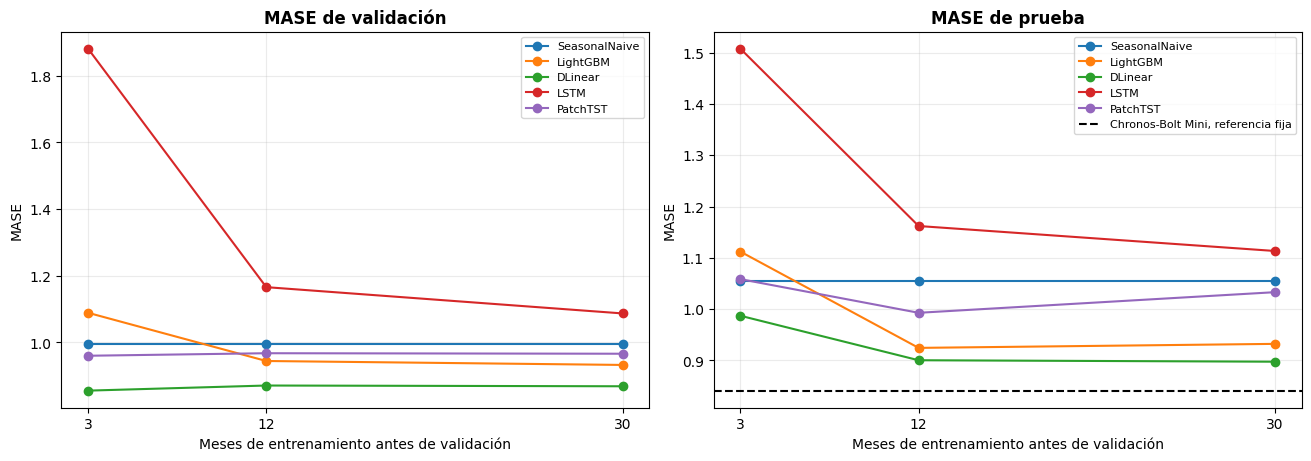

Referencia fija de Chronos-Bolt en prueba: MASE=0.84113.
Los 3, 12 y 30 meses pertenecen al bloque previo a validación. El ajuste final incluye también julio–septiembre: 6, 15 y 33 meses.
La interpretación de las curvas queda pendiente de discutir antes de redactar la respuesta.


In [15]:
experiment_final_table = run_experiment_final_evaluation(experiment_selection_table)
plot_experiment_results(experiment_selection_table, experiment_final_table)

In [1]:
import pandas as pd
from IPython.display import display

experiment_resource_table = pd.read_csv("data/processed/experiments_5_2/final_results.csv")
display(experiment_resource_table[[
    "case", "hardware", "parameter_count", "trainable_parameters",
    "selection_seconds", "final_fit_seconds", "fit_seconds_total",
    "inference_seconds", "peak_gpu_mib", "final_training_reused",
]].round(3))

,case,hardware,parameter_count,trainable_parameters,selection_seconds,final_fit_seconds,fit_seconds_total,inference_seconds,peak_gpu_mib,final_training_reused
0,DLinear_L48_M30,mps,2352,2352,28.453,17.117,45.571,0.111,55.703,False
1,DLinear_L168_M30,mps,8112,8112,64.267,44.835,109.102,0.124,1041.703,False
2,DLinear_L336_M30,mps,16176,16176,77.145,46.216,123.361,0.128,1041.703,False
3,SeasonalNaive_L168_M3,cpu,0,0,0.231,0.000,0.231,0.094,0.000,False
4,SeasonalNaive_L168_M12,cpu,0,0,0.225,0.000,0.225,0.093,0.000,False
5,SeasonalNaive_L168_M30,cpu,0,0,0.226,0.000,0.226,0.092,0.000,False
6,LightGBM_L168_M3,"cpu, 1 thread",6200,6200,21.825,9.364,31.189,1.948,0.000,False
7,LightGBM_L168_M12,"cpu, 1 thread",6200,6200,34.611,23.220,57.831,1.959,0.000,False
8,LightGBM_L168_M30,"cpu, 1 thread",6200,6200,65.590,53.363,118.953,1.708,0.000,False
9,DLinear_L168_M3,mps,8112,8112,13.306,14.629,27.935,0.118,1041.703,False


## **5.3 Modelo local contra global**

Se utilizará DLinear, que fue el modelo propio seleccionado con el menor MASE de validación. Se conserva la configuración de ventana de 168 horas, horizonte de 24, media móvil de 25 y 3 meses de historia previa a validación. La comparación se hará sobre diez clientes elegidos de los cien originales con semilla 123, manteniendo las mismas fechas y la misma referencia MASE para ambas alternativas.

- **Modelo global:** Se reutilizan los pronósticos y pesos del DLinear entrenado con los cien clientes. Sus resultados se restringen a los diez seleccionados para esta comparación, sin volver a entrenarlo ni elegir otra configuración con prueba.
- **Modelos locales:** Se entrena un DLinear independiente por cliente, utilizando únicamente su consumo. Cada uno tiene 8112 parámetros y se mantiene la misma arquitectura, AdamW, learning rate y weight decay del global. DLinear utiliza el consumo y no las covariables del Dataset.
- **Normalización:** Cada escalador local se ajusta únicamente con abril–junio de 2014. Se comprueba que sus parámetros coincidan con los que el global utilizó para ese cliente. La referencia MASE común se mantiene a partir del entrenamiento original y se utiliza únicamente para evaluar.
- **Batch y actualizaciones:** El global usa un batch de 2048 para cien clientes. Para un cliente se utiliza un batch de 20, proporcional a ese volumen, de tal forma que cada época tenga aproximadamente la misma cantidad de actualizaciones. Se conserva el máximo de doce épocas y paciencia de tres. Es una adaptación explícita del batch; no representa una búsqueda de hiperparámetros.
- **Selección y ajuste final:** Cada modelo local elige su época con MASE de validación en julio–septiembre. Primero se completa esa selección para los diez clientes y después se ajustan los modelos finales incorporando esos tres meses, por lo que la historia final abarca abril–septiembre. Prueba no participa en estas decisiones.
- **Evaluación:** Se mantiene el backtest de 92 orígenes diarios, con pesos fijos y pronósticos de las siguientes 24 horas. Se reporta MASE por cliente y el promedio de esos diez MASE, junto con las métricas generales. Los tiempos distinguen el global entrenado con cien clientes del conjunto de diez modelos locales.
- **Alcance:** Esta comparación utiliza una selección de diez clientes y una semilla. Sus resultados describen esta configuración y este presupuesto de entrenamiento, sin garantizar que el resultado se repita en todos los clientes o con otras configuraciones.

MT_004: época elegida 10; MASE de validación 0.6770.


MT_014: época elegida 11; MASE de validación 0.4028.


MT_066: época elegida 1; MASE de validación 3.0884.


MT_067: época elegida 12; MASE de validación 1.0518.


MT_071: época elegida 5; MASE de validación 0.7401.


...

Métricas sobre los mismos 10 clientes y los mismos 92 orígenes.


,MAE_kWh,RMSE_kWh,WAPE_pct,MAPE_pct,zero_actual_count,MASE
Global,14.58670,29.78500,10.41452,NaN,1184.0,0.99112
Local,12.98354,24.83593,9.26990,NaN,1184.0,1.01436


,models,parameters_per_model,total_parameters,selection_and_final_seconds,training_reused
model,,,,,
"Global, entrenado con 100 clientes",1,8112,8112,27.935,True
"Local, 10 modelos independientes",10,8112,81120,52.202,False


Épocas locales elegidas únicamente con validación.


,client,selected_epochs,validation_MASE,optimizer_steps_per_epoch
0,MT_004,10,0.67699,100
1,MT_014,11,0.40276,100
2,MT_066,1,3.08842,100
3,MT_067,12,1.05176,100
4,MT_071,5,0.74014,100
5,MT_080,12,0.89772,100
6,MT_130,12,0.32927,100
7,MT_219,11,1.21663,100
8,MT_245,9,0.88170,100
9,MT_318,7,1.13079,100


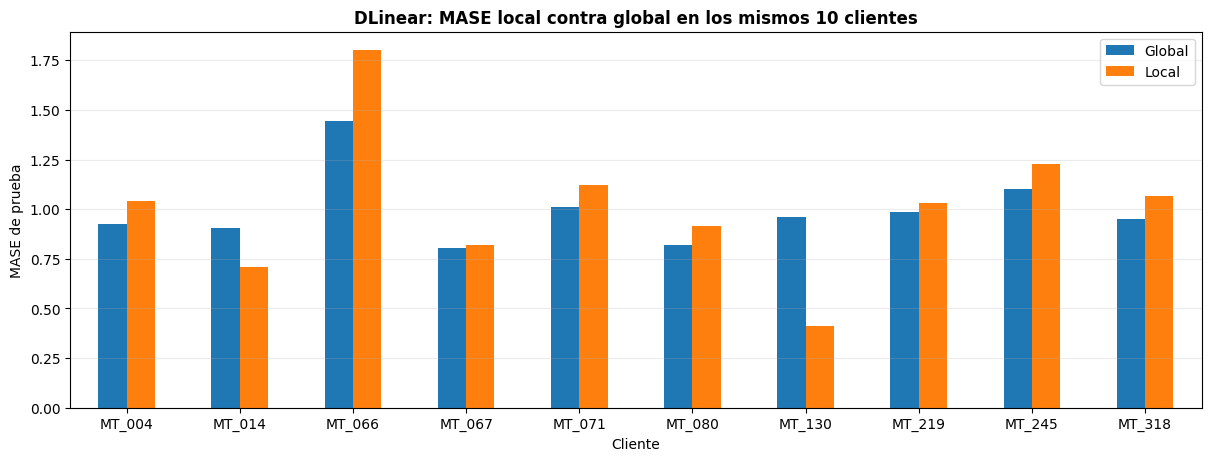

Menor MASE local: 2 clientes; menor MASE global: 8 clientes.
La interpretación queda pendiente de discutir; no se utilizan estos errores para volver a ajustar los modelos.


In [8]:
from contextlib import contextmanager
from pathlib import Path
from time import perf_counter
import gc
import hashlib
import json
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from sklearn.preprocessing import MinMaxScaler


local_global_directory = Path("data/processed/local_global_5_3")
local_global_directory.mkdir(parents=True, exist_ok=True)
experiment_results_directory = Path("data/processed/experiments_5_2")
selected_configurations = pd.read_csv(experiment_results_directory / "selected_configurations.csv")
selected_dlinear = selected_configurations.loc[selected_configurations["model"] == "DLinear"].iloc[0]
global_case_directory = experiment_results_directory / selected_dlinear["case"]
global_selection = json.loads((global_case_directory / "selection_result.json").read_text())
global_test_record = json.loads((global_case_directory / "test_result.json").read_text())
assert global_selection["case"] == selected_dlinear["case"]
assert global_selection["client_columns"] == selected_clients.tolist()
assert global_selection["validation_MASE"] == selected_dlinear["validation_MASE"]
assert global_selection["model"] == "DLinear"

client_positions = np.sort(np.random.default_rng(123).choice(len(selected_clients), size=10, replace=False))
local_global_clients = selected_clients[client_positions]
local_training_original = electricity_train_original.loc[
    global_selection["selection_train_start"]:global_selection["selection_train_end"], local_global_clients
].copy()
local_validation_original = electricity_val_original.loc[:, local_global_clients].copy()
local_test_original = electricity_test_original.loc[:, local_global_clients].copy()
local_calendar_training = calendar_train.loc[local_training_original.index].copy()
local_calendar_validation = calendar_val.copy()
local_calendar_test = calendar_test.copy()
local_global_reference = electricity_train_original.loc[:, local_global_clients].diff(24).abs().mean()
assert (local_global_reference > 0).all() and np.isfinite(local_global_reference).all()
local_batch_size = max(1, round(global_selection["batch_size"] / len(selected_clients)))
local_global_manifest = {
    "schema": "5.3-local-global-v1", "model": "DLinear", "global_case": global_selection["case"],
    "selection_criterion": "validation_MASE", "test_used_for_selection": False,
    "clients": local_global_clients.tolist(), "seed": 123,
    "window": int(global_selection["window"]), "horizon": 24, "months": int(global_selection["months"]),
    "moving_average_length": 25, "maximum_epochs": int(global_selection["maximum_epochs"]),
    "patience": int(global_selection["patience"]), "learning_rate": global_selection["learning_rate"],
    "weight_decay": global_selection["weight_decay"], "global_batch_size": global_selection["batch_size"],
    "local_batch_size": local_batch_size,
    "selection_train_start": global_selection["selection_train_start"],
    "selection_train_end": global_selection["selection_train_end"],
    "final_fit_end": global_selection["final_fit_end"],
    "global_checkpoint_sha256": hashlib.sha256((global_case_directory / "final_model.pt").read_bytes()).hexdigest(),
}
manifest_path = local_global_directory / "comparison_config.json"
if manifest_path.exists():
    assert json.loads(manifest_path.read_text()) == local_global_manifest, "La configuración cambió; revise los resultados guardados antes de reutilizarlos."
else:
    manifest_path.write_text(json.dumps(local_global_manifest, indent=2, ensure_ascii=False))


def local_client_context(client_name):
    client_training = local_training_original.loc[:, [client_name]]
    client_scaler = MinMaxScaler(clip=False).fit(client_training)
    context = {"client": client_name, "scaler": client_scaler}
    for partition_name, original_partition in [
        ("train", client_training), ("val", local_validation_original.loc[:, [client_name]]),
        ("test", local_test_original.loc[:, [client_name]]),
    ]:
        context[partition_name] = pd.DataFrame(
            client_scaler.transform(original_partition), index=original_partition.index, columns=[client_name]
        )
    client_position = selected_clients.get_loc(client_name)
    global_scaler = np.load(global_case_directory / "scaler.npz")
    np.testing.assert_array_equal(client_scaler.scale_, global_scaler["scale"][[client_position]])
    np.testing.assert_array_equal(client_scaler.min_, global_scaler["minimum"][[client_position]])
    assert client_scaler.n_samples_seen_ == len(client_training)
    assert client_training.index.max() < local_validation_original.index.min()
    return context


def create_local_dlinear(context):
    client_name = context["client"]
    model = DLinearForecaster(
        context["scaler"], electricity_train_original.loc[:, [client_name]], random_seed=123
    )
    model.window_length = local_global_manifest["window"]
    model.batch_size = local_batch_size
    model.maximum_epochs = local_global_manifest["maximum_epochs"]
    model.patience = local_global_manifest["patience"]
    model.learning_rate = local_global_manifest["learning_rate"]
    model.weight_decay = local_global_manifest["weight_decay"]
    model.client_columns = context["train"].columns.copy()
    model.calendar_columns = local_calendar_training.columns.copy()
    return model


def select_local_dlinear(client_name):
    client_directory = local_global_directory / client_name
    client_directory.mkdir(exist_ok=True)
    selection_path = client_directory / "selection_result.json"
    if selection_path.exists():
        print(f"{client_name}: selección recuperada.", flush=True)
        return json.loads(selection_path.read_text())
    context = local_client_context(client_name)
    model = create_local_dlinear(context)
    training_dataset = PanelWindowDataset(
        context["train"], local_calendar_training,
        context["train"].index.min(), context["train"].index.max(),
        window_length=model.window_length, horizon_length=24,
    )
    validation_dataset = PanelWindowDataset(
        pd.concat([context["train"], context["val"]]),
        pd.concat([local_calendar_training, local_calendar_validation]),
        local_validation_original.index.min(), local_validation_original.index.max(),
        window_length=model.window_length, horizon_length=24,
    )
    training_loader = model.create_loader(training_dataset, shuffle=True)
    validation_loader = DataLoader(validation_dataset, batch_size=2048, shuffle=False, num_workers=0, collate_fn=keep_window_batch)
    optimizer = model.initialize_network(feature_count=8)
    selection_start = perf_counter()
    best_mase = np.inf
    checks_without_improvement = 0
    records = []
    for epoch_number in range(1, model.maximum_epochs + 1):
        training_start = perf_counter()
        training_loss = model.train_epoch(training_loader, optimizer)
        training_seconds = perf_counter() - training_start
        validation_start = perf_counter()
        validation_metrics = model.evaluate_validation(validation_loader)
        records.append({
            "epoch": epoch_number, "training_loss": training_loss, **validation_metrics,
            "training_seconds": training_seconds, "validation_seconds": perf_counter() - validation_start,
            "optimizer_steps": len(training_loader),
        })
        pd.DataFrame(records).to_csv(client_directory / "selection_history.csv", index=False)
        if validation_metrics["validation_MASE"] < best_mase - 0.000001:
            best_mase = validation_metrics["validation_MASE"]
            selected_epoch = epoch_number
            checks_without_improvement = 0
            torch.save({parameter_name: parameter.detach().cpu().clone() for parameter_name, parameter in model.network.state_dict().items()}, client_directory / "selection_weights.pt")
        else:
            checks_without_improvement += 1
        if checks_without_improvement >= model.patience:
            break
    best_record = records[selected_epoch - 1]
    result = {
        "client": client_name, "selected_epochs": selected_epoch, "validation_MASE": best_mase,
        "validation_MAE_kWh": best_record["validation_MAE_kWh"],
        "selection_seconds": perf_counter() - selection_start,
        "training_windows": len(training_dataset), "validation_windows": len(validation_dataset),
        "optimizer_steps_per_epoch": len(training_loader),
        "peak_gpu_mib": model.peak_gpu_memory_bytes / 1024**2,
    }
    selection_path.write_text(json.dumps(result, indent=2))
    print(f"{client_name}: época elegida {selected_epoch}; MASE de validación {best_mase:.4f}.", flush=True)
    return result


def fit_final_local_dlinear(selection):
    context = local_client_context(selection["client"])
    client_directory = local_global_directory / selection["client"]
    model = create_local_dlinear(context)
    checkpoint_path = client_directory / "final_model.pt"
    resources_path = client_directory / "final_training_result.json"
    if checkpoint_path.exists() and resources_path.exists():
        model.initialize_network(feature_count=8)
        model.network.load_state_dict(torch.load(checkpoint_path, map_location="cpu", weights_only=True)["state_dict"])
        resources = json.loads(resources_path.read_text())
    else:
        final_consumption = pd.concat([context["train"], context["val"]])
        final_calendar = pd.concat([local_calendar_training, local_calendar_validation])
        final_dataset = PanelWindowDataset(
            final_consumption, final_calendar, final_consumption.index.min(), final_consumption.index.max(),
            window_length=model.window_length, horizon_length=24,
        )
        final_loader = model.create_loader(final_dataset, shuffle=True)
        optimizer = model.initialize_network(feature_count=8)
        final_start = perf_counter()
        records = []
        for epoch_number in range(1, selection["selected_epochs"] + 1):
            epoch_start = perf_counter()
            training_loss = model.train_epoch(final_loader, optimizer)
            records.append({"epoch": epoch_number, "training_loss": training_loss, "training_seconds": perf_counter() - epoch_start, "optimizer_steps": len(final_loader)})
            pd.DataFrame(records).to_csv(client_directory / "final_training_history.csv", index=False)
        resources = {
            "client": selection["client"], "final_fit_seconds": perf_counter() - final_start,
            "final_training_windows": len(final_dataset), "final_optimizer_steps_per_epoch": len(final_loader),
            "parameter_count": sum(parameter.numel() for parameter in model.network.parameters()),
            "peak_gpu_mib": max(selection["peak_gpu_mib"], model.peak_gpu_memory_bytes / 1024**2),
            "hardware": str(model.device),
        }
        torch.save({
            "state_dict": {parameter_name: parameter.detach().cpu().clone() for parameter_name, parameter in model.network.state_dict().items()},
            "client": selection["client"], "configuration": local_global_manifest,
            "selected_epochs": selection["selected_epochs"],
            "scaler_scale": torch.from_numpy(context["scaler"].scale_),
            "scaler_min": torch.from_numpy(context["scaler"].min_),
        }, checkpoint_path)
        resources_path.write_text(json.dumps(resources, indent=2))
    model.network.eval()
    model.training_state = {parameter_name: parameter.detach().cpu().clone() for parameter_name, parameter in model.network.state_dict().items()}
    print(f"{selection['client']}: modelo final listo, {selection['selected_epochs']} épocas.", flush=True)
    return model, resources


class LocalDLinearPanel:
    def __init__(self, models):
        self.models = models
        self.fit_calls = 0

    def fit(self, consumption_history, calendar_history):
        assert consumption_history.columns.equals(local_global_clients)
        assert consumption_history.index.min() == local_training_original.index.min()
        assert consumption_history.index.max() == local_validation_original.index.max()
        assert calendar_history.index.equals(consumption_history.index)
        self.fit_calls += 1
        return self

    def predict(self, consumption_window, calendar_window, future_calendar):
        return pd.concat([
            self.models[client_name].predict(consumption_window.loc[:, [client_name]], calendar_window, future_calendar)
            for client_name in local_global_clients
        ], axis=1)


@contextmanager
def local_panel_backtest_context():
    panel_scaler = MinMaxScaler(clip=False).fit(local_training_original)
    replacements = {"electricity_scaler": panel_scaler, "electricity_test_original": local_test_original}
    for partition_name, original_partition in [
        ("train", local_training_original), ("val", local_validation_original), ("test", local_test_original),
    ]:
        replacements[f"electricity_{partition_name}"] = pd.DataFrame(
            panel_scaler.transform(original_partition), index=original_partition.index, columns=local_global_clients
        )
    replacements.update({"calendar_train": local_calendar_training, "calendar_val": local_calendar_validation, "calendar_test": local_calendar_test})
    previous_values = {variable_name: globals()[variable_name] for variable_name in replacements}
    try:
        globals().update(replacements)
        yield
    finally:
        globals().update(previous_values)


def local_global_metrics(forecasts):
    metrics = summarize_forecast_errors(forecasts).to_dict()
    reference = forecasts["unique_id"].map(local_global_reference)
    assert reference.notna().all() and (reference > 0).all()
    metrics["MASE"] = float(((forecasts["y"] - forecasts["y_hat"]).abs() / reference).mean())
    return metrics


def run_local_global_comparison():
    torch.set_num_threads(4)
    selection_records = [select_local_dlinear(client_name) for client_name in local_global_clients]
    selection_table = pd.DataFrame(selection_records)
    selection_table.to_csv(local_global_directory / "local_selection_summary.csv", index=False)
    print("Selección local completada sin usar prueba; comienza el ajuste final.", flush=True)
    local_forecasts_path = local_global_directory / "local_test_forecasts.csv.gz"
    local_resources_path = local_global_directory / "local_final_resources.csv"
    if local_forecasts_path.exists() and local_resources_path.exists():
        local_forecasts = pd.read_csv(local_forecasts_path, parse_dates=["ds", "cutoff", "fit_cutoff"], float_precision="round_trip")
        local_resources = pd.read_csv(local_resources_path)
    else:
        models = {}
        resource_records = []
        for selection in selection_records:
            model, resources = fit_final_local_dlinear(selection)
            models[selection["client"]] = model
            resource_records.append(resources)
        panel_model = LocalDLinearPanel(models)
        original_train_identity = electricity_train
        original_scaler_identity = electricity_scaler
        with local_panel_backtest_context():
            local_results = backtest(panel_model, window_length=local_global_manifest["window"], refit_monthly=False)
        assert electricity_train is original_train_identity and electricity_scaler is original_scaler_identity
        assert panel_model.fit_calls == 1
        for model in models.values():
            for parameter_name, trained_parameter in model.training_state.items():
                torch.testing.assert_close(model.network.state_dict()[parameter_name].detach().cpu(), trained_parameter, rtol=0, atol=0)
        local_forecasts = local_results["forecasts"]
        local_forecasts["modelo"] = "DLinear local"
        local_resources = pd.DataFrame(resource_records)
        local_resources["inference_seconds"] = [models[client_name].inference_seconds for client_name in local_resources["client"]]
        local_forecasts.to_csv(local_forecasts_path, index=False, compression="gzip")
        local_resources.to_csv(local_resources_path, index=False)
        del models, panel_model, local_results
        gc.collect()
        if torch.backends.mps.is_available():
            torch.mps.empty_cache()
    global_forecasts = pd.read_csv(global_case_directory / "test_forecasts.csv.gz", parse_dates=["ds", "cutoff", "fit_cutoff"], float_precision="round_trip")
    global_forecasts = global_forecasts.loc[global_forecasts["unique_id"].isin(local_global_clients)].copy()
    global_forecasts["modelo"] = "DLinear global"
    global_forecasts.to_csv(local_global_directory / "global_test_forecasts.csv.gz", index=False, compression="gzip")
    forecast_keys = ["unique_id", "ds", "cutoff", "fit_cutoff", "horizon_step"]
    assert len(local_forecasts) == len(global_forecasts) == 22080
    assert not local_forecasts.duplicated(["unique_id", "ds"]).any()
    for forecast_frame in [local_forecasts, global_forecasts]:
        assert forecast_frame.groupby("unique_id").size().eq(2208).all()
        assert forecast_frame["cutoff"].nunique() == 92
        assert (forecast_frame["fit_cutoff"] == pd.Timestamp(global_selection["final_fit_end"])).all()
    pd.testing.assert_frame_equal(local_forecasts[forecast_keys].reset_index(drop=True), global_forecasts[forecast_keys].reset_index(drop=True))
    np.testing.assert_array_equal(local_forecasts["y"].to_numpy(), global_forecasts["y"].to_numpy())
    rows = []
    for client_name in local_global_clients:
        global_metrics = local_global_metrics(global_forecasts.loc[global_forecasts["unique_id"] == client_name])
        local_metrics = local_global_metrics(local_forecasts.loc[local_forecasts["unique_id"] == client_name])
        rows.append({
            "client": client_name, "global_MASE": global_metrics["MASE"], "local_MASE": local_metrics["MASE"],
            "global_MAE_kWh": global_metrics["MAE_kWh"], "local_MAE_kWh": local_metrics["MAE_kWh"],
            "local_improvement_pct": 100 * (global_metrics["MASE"] - local_metrics["MASE"]) / global_metrics["MASE"],
            "winner": "Local" if local_metrics["MASE"] < global_metrics["MASE"] else "Global",
        })
    comparison = pd.DataFrame(rows).set_index("client")
    comparison.to_csv(local_global_directory / "comparison_by_client.csv")
    summary = pd.DataFrame({
        "Global": local_global_metrics(global_forecasts), "Local": local_global_metrics(local_forecasts),
    }).T
    summary.to_csv(local_global_directory / "comparison_summary.csv", index_label="model")
    np.testing.assert_allclose(summary.loc["Global", "MASE"], comparison["global_MASE"].mean())
    np.testing.assert_allclose(summary.loc["Local", "MASE"], comparison["local_MASE"].mean())
    parameters_per_model = int(local_resources["parameter_count"].iloc[0])
    resource_summary = pd.DataFrame([
        {"model": "Global, entrenado con 100 clientes", "models": 1, "parameters_per_model": global_selection["parameter_count"], "total_parameters": global_selection["parameter_count"], "selection_and_final_seconds": global_test_record["fit_seconds_total"], "training_reused": True},
        {"model": "Local, 10 modelos independientes", "models": 10, "parameters_per_model": parameters_per_model, "total_parameters": int(local_resources["parameter_count"].sum()), "selection_and_final_seconds": selection_table["selection_seconds"].sum() + local_resources["final_fit_seconds"].sum(), "training_reused": False},
    ]).set_index("model")
    resource_summary.to_csv(local_global_directory / "comparison_resources.csv")
    print("MASE y MAE por cliente; mejora local positiva significa menor error con el modelo individual.")
    display(comparison.round(5))
    print("Métricas sobre los mismos 10 clientes y los mismos 92 orígenes.")
    display(summary.round(5))
    display(resource_summary.round(3))
    print("Épocas locales elegidas únicamente con validación.")
    display(selection_table[["client", "selected_epochs", "validation_MASE", "optimizer_steps_per_epoch"]].round(5))
    figure, axis = plt.subplots(figsize=(12, 4.5), layout="constrained")
    comparison[["global_MASE", "local_MASE"]].rename(columns={"global_MASE": "Global", "local_MASE": "Local"}).plot.bar(ax=axis, rot=0)
    axis.set_title("DLinear: MASE local contra global en los mismos 10 clientes", fontweight="bold")
    axis.set(xlabel="Cliente", ylabel="MASE de prueba")
    axis.grid(axis="y", alpha=0.25)
    figure.savefig(local_global_directory / "local_global_mase_by_client.png", dpi=180)
    plt.show()
    print(f"Menor MASE local: {(comparison['winner'] == 'Local').sum()} clientes; menor MASE global: {(comparison['winner'] == 'Global').sum()} clientes.")
    print("La interpretación queda pendiente de discutir; no se utilizan estos errores para volver a ajustar los modelos.")
    return comparison, summary


local_global_comparison, local_global_summary = run_local_global_comparison()


**¿Conviene entrenar un modelo por cliente o compartir un modelo global?**

Considero que, cuando se cuenta con los recursos necesarios, conviene probar ambas alternativas y contrastar sus resultados, como hicimos en este caso. Trabajamos con diez clientes para la comparación, por lo que fue viable entrenar los modelos individuales y evaluar si alguno se beneficiaba de un aprendizaje especializado.

- **Escalabilidad:** En un escenario con un catálogo tan extenso como el de Amazon, mantener un modelo por producto podría implicar un costo considerable de entrenamiento, almacenamiento, actualización y mantenimiento. La viabilidad dependería de la cantidad de productos y de la complejidad de los modelos, por lo que esta estrategia sería más difícil de sostener conforme aumenta la escala.
- **Resultados:** El modelo global obtuvo menor MASE en ocho de los diez clientes y un MASE promedio de 0.991, frente a 1.014 de los modelos locales. Los modelos individuales mejoraron únicamente para MT_014 y MT_130. Cabe mencionar que el conjunto local sí obtuvo menor MAE, por lo que la ventaja del global corresponde al criterio MASE que estamos priorizando.
- **Decisión:** Me quedaría con el modelo global como referencia, ya que presentó mejor comportamiento según MASE para la mayoría de los clientes y permite mantener un solo modelo compartido. Los resultados locales muestran que existen casos puntuales donde especializar el modelo puede ser útil, pero en esta comparación no representan la mayoría.

## **6. Comparación de resultados**

Se construye la tabla con pandas a partir de los resultados guardados y se ordena por MASE en prueba con horizonte de 24 horas. Para las familias comparadas en el 5.2 se utiliza la configuración elegida con validación, aunque otra variante haya obtenido un error de prueba menor. Los otros modelos conservan la configuración evaluada en la sección 5. También se incluye la LSTM autorregresiva del 5.1.

- **Condiciones:** Los resultados corresponden a los mismos cien clientes y 92 orígenes diarios. MASE utiliza la misma referencia estacional de 24 horas calculada con el entrenamiento original. Los meses indicados corresponden a la historia anterior a validación; el ajuste final incorpora también julio–septiembre.
- **Recuperación:** Se reutilizan los CSV disponibles. Si faltan los pronósticos de MLP o NLinear, se recuperan con los pesos originales congelados y se comprueba que las métricas coincidan con la evaluación guardada. Naive y seasonal naive se recuperan aplicando su regla original. No se realizan nuevos entrenamientos.
- **AutoETS y horizonte semanal:** Sus pronósticos completos se recuperan y verifican para incorporar su MASE general y de Navidad. La evaluación H=168 utiliza los nueve modelos que permiten extender el pronóstico con sus pesos actuales, sobre 86 orígenes completos. Las ocho configuraciones de salida fija H=24 se identifican como no aplicables a H=168 sin cambiar su salida o estrategia. Las métricas H=24 conservan los 92 orígenes originales.
- **Parámetros y recursos:** En LightGBM se cuentan los valores de las hojas; AutoETS reporta parámetros estimados. Esos conteos no equivalen directamente a pesos neuronales. Los tiempos recuperados de las salidas originales conservan la precisión mostrada, mientras que los registros del 5.2 conservan sus valores completos. Para Chronos se reporta únicamente inferencia, ya que se utilizó zero-shot.
- **Resultados probabilísticos:** Se incluyen pinball loss promedio y cobertura P10–P90 para DeepAR y Chronos. En los modelos deterministas se identifican como no aplicables. Las tres gráficas de comparación se presentan después de la tabla.

### **Recuperación de AutoETS para completar la comparación**

Se recuperan los pronósticos completos de AutoETS para calcular su MASE general y el de la semana del 22 al 28 de diciembre. Si los archivos ya existen se reutilizan. Como la ejecución inicial no conservó sus pesos ni sus pronósticos, la primera recuperación reproduce el ajuste original: los mismos cien clientes, fechas, escalador, estacionalidad de 24 horas, componentes automáticos ZZZ y parámetros fijos durante prueba.

- **Recuperación del ajuste:** Los clientes se procesan con cuatro procesos de CPU, de forma independiente, y cada modelo queda guardado. Esta organización permite completar el trabajo y recuperarlo si se interrumpe; no cambia los datos ni la configuración del modelo.
- **Verificación:** Se comprueba que MAE, RMSE y WAPE reproduzcan las métricas originales, que los parámetros permanezcan fijos durante prueba y que los 220800 pronósticos estén alineados con los valores reales. No se modifica la configuración a partir del error de prueba.
- **Comparación:** MASE mantiene la referencia común calculada con el entrenamiento original. Se conserva el tiempo de la ejecución inicial en la tabla comparativa; el costo de esta recuperación queda registrado por separado.

In [9]:
from pathlib import Path
from time import perf_counter
import hashlib
import json

import joblib
import numpy as np
import pandas as pd
import statsforecast
from IPython.display import display
from joblib import Parallel, delayed, parallel_config
from statsforecast.models import AutoETS


autoets_recovery_directory = Path("data/processed/autoets_recovery")
autoets_recovery_directory.mkdir(parents=True, exist_ok=True)
autoets_client_cache = autoets_recovery_directory / "client_models"
autoets_client_cache.mkdir(exist_ok=True)
autoets_forecasts_path = Path("data/processed/autoets_test_forecasts.csv.gz")
autoets_metadata_path = autoets_recovery_directory / "evaluation_metadata.json"
autoets_training_history = pd.concat([electricity_train, electricity_val])
autoets_signature = {
    "model": "AutoETS", "season_length": 24, "components": "ZZZ", "forecast_horizon": 24,
    "statsforecast_version": statsforecast.__version__, "clients": selected_clients.tolist(), "seed": 123,
    "training_start": str(autoets_training_history.index.min()),
    "training_end": str(autoets_training_history.index.max()),
    "training_sha256": hashlib.sha256(np.ascontiguousarray(autoets_training_history.to_numpy()).tobytes()).hexdigest(),
    "scaler_sha256": hashlib.sha256(np.concatenate([electricity_scaler.scale_, electricity_scaler.min_]).tobytes()).hexdigest(),
}
assert autoets_signature["training_end"] == "2014-09-30 23:00:00"
assert len(selected_clients) == 100 and client_selection_seed == 123
signature_path = autoets_recovery_directory / "configuration.json"
if signature_path.exists():
    assert json.loads(signature_path.read_text()) == autoets_signature, "Los datos o la configuración de AutoETS cambiaron."
else:
    signature_path.write_text(json.dumps(autoets_signature, indent=2, ensure_ascii=False))


def fit_cached_autoets_client(client_name, client_consumption, cache_directory):
    checkpoint_path = Path(cache_directory) / f"{client_name}.joblib"
    if checkpoint_path.exists():
        model = joblib.load(checkpoint_path)
        reused = True
    else:
        model = AutoETS(season_length=24, model="ZZZ")
        model.fit(y=client_consumption)
        temporary_path = checkpoint_path.with_suffix(".tmp.joblib")
        joblib.dump(model, temporary_path, compress=3)
        temporary_path.replace(checkpoint_path)
        reused = False
    return client_name, model, reused


class RecoverableAutoETSBaseline(AutoETSBaseline):
    def fit(self, consumption_history, calendar_history):
        fit_start = perf_counter()
        pd.testing.assert_frame_equal(consumption_history, autoets_training_history)
        self.observed_history = consumption_history.copy()
        self.client_models = {}
        completed_clients = 0
        self.reused_clients = 0
        with parallel_config(backend="loky", inner_max_num_threads=1):
            fitted_clients = Parallel(n_jobs=4, return_as="generator_unordered")(
                delayed(fit_cached_autoets_client)(
                    client_name, client_consumption.to_numpy(dtype=float), str(autoets_client_cache)
                )
                for client_name, client_consumption in consumption_history.items()
            )
            for client_name, model, reused in fitted_clients:
                self.client_models[client_name] = model
                completed_clients += 1
                self.reused_clients += int(reused)
                if completed_clients % 20 == 0:
                    print(f"AutoETS recuperado: {completed_clients}/100 clientes; {self.reused_clients} desde checkpoint.", flush=True)
        self.client_models = {client_name: self.client_models[client_name] for client_name in consumption_history.columns}
        component_records = []
        for client_name, model in self.client_models.items():
            parameters = model.model_["par"]
            component_records.append({
                "unique_id": client_name, "Método": str(model.model_.get("method", model.model_["components"])),
                "Parámetros estimados": int(model.model_["n_params"]),
                "alpha": parameters[0], "beta": parameters[1], "gamma": parameters[2], "phi": parameters[3],
            })
        self.selected_components = pd.DataFrame(component_records).set_index("unique_id")
        self.fit_seconds += perf_counter() - fit_start
        return self


if autoets_forecasts_path.exists() and autoets_metadata_path.exists():
    autoets_recovered_forecasts = pd.read_csv(
        autoets_forecasts_path, parse_dates=["ds", "cutoff", "fit_cutoff"], float_precision="round_trip"
    )
    autoets_recovery_metadata = json.loads(autoets_metadata_path.read_text())
    print("AutoETS: pronósticos completos recuperados del archivo, sin repetir el ajuste.", flush=True)
else:
    autoets_recovery_start = perf_counter()
    autoets_recovery_model = RecoverableAutoETSBaseline(season_length=24)
    autoets_recovery_results = backtest(autoets_recovery_model, window_length=168, refit_monthly=False)
    autoets_recovered_forecasts = autoets_recovery_results["forecasts"].copy()
    autoets_recovered_forecasts["modelo"] = "AutoETS"
    assert len(autoets_recovery_results["fit_schedule"]) == 1
    assert autoets_recovery_results["fit_schedule"].iloc[0]["fit_cutoff"] == pd.Timestamp("2014-09-30 23:00")
    expected_history = pd.concat([electricity_train, electricity_val, electricity_test]).loc[:"2014-12-30 23:00"]
    pd.testing.assert_frame_equal(autoets_recovery_model.observed_history, expected_history)
    for client_name, model in autoets_recovery_model.client_models.items():
        cached_model = joblib.load(autoets_client_cache / f"{client_name}.joblib")
        np.testing.assert_array_equal(cached_model.model_["par"], model.model_["par"])
    parameter_count = int(autoets_recovery_model.selected_components["Parámetros estimados"].sum())
    assert parameter_count == 2455
    autoets_recovered_forecasts.to_csv(autoets_forecasts_path, index=False, compression="gzip")
    autoets_recovery_model.selected_components.to_csv(autoets_recovery_directory / "selected_components.csv")
    autoets_recovery_metadata = {
        "configuration": autoets_signature, "recovery_seconds": perf_counter() - autoets_recovery_start,
        "recovery_fit_seconds": autoets_recovery_model.fit_seconds,
        "recovery_inference_seconds": autoets_recovery_model.inference_seconds,
        "recovery_cpu_processes": 4, "parameter_count": parameter_count,
        "test_used_to_change_configuration": False,
    }

assert len(autoets_recovered_forecasts) == 220800
assert autoets_recovered_forecasts["unique_id"].nunique() == 100
assert not autoets_recovered_forecasts.duplicated(["unique_id", "ds"]).any()
assert autoets_recovered_forecasts["cutoff"].nunique() == 92
assert (autoets_recovered_forecasts["fit_cutoff"] == pd.Timestamp("2014-09-30 23:00")).all()
np.testing.assert_array_equal(autoets_recovered_forecasts["y"].to_numpy(), electricity_test_original.to_numpy().reshape(-1))
recovered_metrics = calculate_forecast_metrics(autoets_recovered_forecasts["y"], autoets_recovered_forecasts["y_hat"])
for metric_name, expected_value in {"MAE_kWh": 43.9595, "RMSE_kWh": 222.9669, "WAPE_pct": 8.2885}.items():
    np.testing.assert_allclose(recovered_metrics[metric_name], expected_value, atol=0.00011, rtol=0)
autoets_original_notebook = json.loads(Path("Laboratorio_9_Series_de_Tiempo.ipynb").read_text())
autoets_original_cell = next(cell for cell in autoets_original_notebook["cells"] if cell["id"] == "codigo-autoets")
autoets_reference = electricity_train_original.diff(24).abs().mean()
scaled_errors = (autoets_recovered_forecasts["y"] - autoets_recovered_forecasts["y_hat"]).abs() / autoets_recovered_forecasts["unique_id"].map(autoets_reference)
assert np.isfinite(scaled_errors).all()
christmas_mask = (autoets_recovered_forecasts["ds"] >= "2014-12-22") & (autoets_recovered_forecasts["ds"] < "2014-12-29")
recovered_metrics["MASE_H24"] = float(scaled_errors.mean())
recovered_metrics["MASE_Navidad"] = float(scaled_errors.loc[christmas_mask].mean())
autoets_recovery_metadata["metrics"] = {key: float(value) if np.isfinite(value) else None for key, value in recovered_metrics.items()}
autoets_recovery_metadata["original_metrics_reproduced"] = True
autoets_metadata_path.write_text(json.dumps(autoets_recovery_metadata, indent=2, ensure_ascii=False, allow_nan=False))
pd.Series(recovered_metrics, name="AutoETS recuperado").to_csv(autoets_recovery_directory / "metrics.csv")
display(pd.Series(recovered_metrics, name="AutoETS recuperado").to_frame().round(5))
print("Métricas originales reproducidas; MASE general y de Navidad calculados con la referencia común de entrenamiento.")
print("Los tiempos de recuperación se guardan por separado; la comparación mantiene los tiempos medidos en la ejecución original.")


AutoETS recuperado: 20/100 clientes; 0 desde checkpoint.


AutoETS recuperado: 40/100 clientes; 0 desde checkpoint.


AutoETS recuperado: 60/100 clientes; 0 desde checkpoint.


AutoETS recuperado: 80/100 clientes; 0 desde checkpoint.


AutoETS recuperado: 100/100 clientes; 0 desde checkpoint.


,AutoETS recuperado
MAE_kWh,43.95946
RMSE_kWh,222.96693
WAPE_pct,8.28845
MAPE_pct,NaN
zero_actual_count,1898.00000
MASE_H24,1.05904
MASE_Navidad,2.40336


Métricas originales reproducidas; MASE general y de Navidad calculados con la referencia común de entrenamiento.
Los tiempos de recuperación se guardan por separado; la comparación mantiene los tiempos medidos en la ejecución original.


### **Evaluación adicional con horizonte de 168 horas**

Se utiliza el mismo backtest con horizonte configurable, manteniendo 24 horas como valor predeterminado. Para la evaluación semanal se conservan los pesos, los escaladores y las configuraciones ya fijadas. No se entrenan modelos nuevos ni se seleccionan configuraciones a partir de estos resultados.

- **Modelos evaluables:** Naive, seasonal naive de 24 y 168 horas, AutoETS, LightGBM, LSTM autorregresiva, Seq2seq, DeepAR y Chronos permiten continuar el pronóstico sin cambiar sus pesos. Se mantiene la ventana inicial de 168 horas.
- **Salidas fijas:** MLP, DLinear, NLinear, LSTM multi-salida, N-HiTS, TCN, PatchTST y TFT tienen una salida aprendida de 24 pasos en las configuraciones utilizadas. Se identifican como no aplicables a H=168 en esas configuraciones. Llevarlos a una semana exigiría otra salida o una estrategia adicional de realimentación por bloques, que no forma parte de esta comparación.
- **Orígenes completos:** Se evalúan 86 orígenes diarios, del 1 de octubre al 25 de diciembre de 2014. Cada uno contiene siete días completos dentro de prueba, sin utilizar datos de enero de 2015. Esto genera 1444800 predicciones por modelo. Los 92 orígenes del resultado original H=24 se conservan sin cambios.
- **Información disponible:** Dentro de cada pronóstico semanal se realimentan únicamente predicciones propias y, cuando corresponda, calendario futuro conocido. Los consumos reales nuevos se incorporan como historia solo al avanzar al siguiente origen diario. AutoETS conserva sus coeficientes y actualiza sus estados con la historia observada.
- **Referencia MASE:** Se mantiene el error estacional de 24 horas calculado por cliente con el entrenamiento original. Cambiar el horizonte a 168 horas no cambia esa referencia. El resultado semanal pondera por igual todos los clientes, pasos y orígenes, incluyendo los objetivos solapados entre orígenes distintos.
- **Modelos probabilísticos:** DeepAR conserva cien trayectorias y su mediana como pronóstico central. Se generan los ruidos en bloques de 24 para conservar el primer día del pronóstico original. Chronos conserva sus pesos zero-shot y utiliza la extensión recursiva nativa de la biblioteca más allá de sus 64 pasos de salida; esa extensión incorpora pronósticos propios y no observaciones futuras reales.
- **Auditoría:** Se comprueba que los pesos permanezcan idénticos antes y después y que el primer día de cada pronóstico semanal coincida con el resultado H=24 ya guardado. Se registra también MASE de esas primeras 24 horas sobre los mismos 86 orígenes, para distinguir el cambio de horizonte del cambio en los orígenes evaluados.
- **Archivos:** Los pronósticos y las métricas semanales se guardan por separado. La tabla conserva sus métricas originales H=24 y agrega el MASE H=168 y la cantidad de orígenes donde corresponde.

In [11]:
from contextlib import contextmanager
from pathlib import Path
from time import perf_counter
import gc
import hashlib
import json
import warnings

import joblib
import lightgbm as lgb
import numpy as np
import pandas as pd
import torch
from torch import nn
from IPython.display import display
from neuralforecast.models import DeepAR
from neuralforecast.losses.pytorch import DistributionLoss, MAE
from sklearn.preprocessing import MinMaxScaler
from statsforecast.models import Naive, SeasonalNaive


weekly_directory = Path("data/processed/horizon_168")
weekly_directory.mkdir(parents=True, exist_ok=True)
weekly_reference = electricity_train_original.diff(24).abs().mean()
weekly_device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
torch.set_num_threads(4)
weekly_models = ["Naive", "Seasonal Naive 24", "Seasonal Naive 168", "AutoETS", "LightGBM", "LSTM autorregresiva", "Seq2seq", "DeepAR", "Chronos-Bolt Mini"]
weekly_fixed_output_models = ["MLP", "DLinear", "NLinear", "LSTM multi-salida", "N-HiTS", "TCN", "PatchTST", "TFT"]
weekly_selected_cases = pd.read_csv("data/processed/experiments_5_2/selected_configurations.csv")
weekly_lightgbm_case = weekly_selected_cases.loc[weekly_selected_cases["model"] == "LightGBM", "case"].item()
weekly_seasonal_case = weekly_selected_cases.loc[weekly_selected_cases["model"] == "SeasonalNaive", "case"].item()
weekly_checkpoint_paths = {
    "LightGBM": Path("data/processed/experiments_5_2") / weekly_lightgbm_case / "final_lightgbm.txt",
    "LSTM autorregresiva": Path("data/processed/lstm_autoregressive.pt"),
    "Seq2seq": Path("data/processed/seq2seq_calendar.pt"),
    "DeepAR": Path("data/processed/deepar_panel_metadata.pt"),
    "Chronos-Bolt Mini": Path("data/processed/chronos_bolt_mini/model.safetensors"),
}
weekly_h24_paths = {
    "Naive": Path("data/processed/comparison_6/recovered_forecasts/naive_test_forecasts.csv.gz"),
    "Seasonal Naive 24": Path("data/processed/experiments_5_2") / weekly_seasonal_case / "test_forecasts.csv.gz",
    "Seasonal Naive 168": Path("data/processed/comparison_6/recovered_forecasts/seasonal naive 168_test_forecasts.csv.gz"),
    "AutoETS": Path("data/processed/autoets_test_forecasts.csv.gz"),
    "LightGBM": Path("data/processed/experiments_5_2") / weekly_lightgbm_case / "test_forecasts.csv.gz",
    "LSTM autorregresiva": Path("data/processed/lstm_autoregressive_test_forecasts.csv"),
    "Seq2seq": Path("data/processed/seq2seq_test_forecasts.csv"),
    "DeepAR": Path("data/processed/deepar_test_forecasts.csv"),
    "Chronos-Bolt Mini": Path("data/processed/chronos_bolt_test_forecasts.csv"),
}
autoets_checkpoint_files = sorted(Path("data/processed/autoets_recovery/client_models").glob("*.joblib"))
assert len(autoets_checkpoint_files) == 100
weekly_manifest = {
    "schema": "h168-frozen-v1", "L": 168, "H": 168, "seed": 123,
    "clients": selected_clients.tolist(), "origins": 86, "first_origin": "2014-10-01", "last_origin": "2014-12-25",
    "fit_cutoff": "2014-09-30 23:00:00", "mase_reference_period": 24,
    "training_reference_sha256": hashlib.sha256(electricity_train_original.to_numpy().tobytes()).hexdigest(),
    "observations_sha256": hashlib.sha256(pd.concat([electricity_train_original, electricity_val_original, electricity_test_original]).to_numpy().tobytes()).hexdigest(),
    "calendar_sha256": hashlib.sha256(pd.concat([calendar_train, calendar_val, calendar_test]).to_numpy().tobytes()).hexdigest(),
    "checkpoint_sha256": {model_name: hashlib.sha256(path.read_bytes()).hexdigest() for model_name, path in weekly_checkpoint_paths.items()},
    "autoets_sha256": hashlib.sha256(b"".join(hashlib.sha256(path.read_bytes()).digest() for path in autoets_checkpoint_files)).hexdigest(),
    "selected_lightgbm": weekly_lightgbm_case, "selected_seasonal": weekly_seasonal_case,
    "test_used_for_selection": False,
}
weekly_manifest_path = weekly_directory / "configuration.json"
if weekly_manifest_path.exists():
    assert json.loads(weekly_manifest_path.read_text()) == weekly_manifest, "La configuración o los pesos cambiaron."
else:
    weekly_manifest_path.write_text(json.dumps(weekly_manifest, indent=2, ensure_ascii=False))


def weekly_model_fingerprint(model):
    digest = hashlib.sha256()
    if hasattr(model, "network"):
        network = model.network
    elif hasattr(model, "pipeline"):
        network = model.pipeline.model
    else:
        network = None
    if network is not None:
        for parameter_name, parameter in network.state_dict().items():
            digest.update(parameter_name.encode())
            digest.update(parameter.detach().cpu().contiguous().numpy().tobytes())
    elif hasattr(model, "booster"):
        digest.update(model.booster.model_to_string().encode())
    elif hasattr(model, "client_models") and model.client_models:
        for client_name in sorted(model.client_models):
            digest.update(client_name.encode())
            digest.update(model.client_models[client_name].model_["par"].tobytes())
    else:
        digest.update(str(model.seasonal_period).encode())
    return digest.hexdigest()


class FrozenWeeklyBase:
    def fit(self, consumption_history, calendar_history):
        assert consumption_history.columns.equals(selected_clients)
        assert consumption_history.index.max() == pd.Timestamp("2014-09-30 23:00")
        assert consumption_history.index.equals(calendar_history.index)
        self.fit_calls += 1
        return self


class WeeklyStatisticalBaseline(FrozenWeeklyBase):
    def __init__(self, seasonal_period=None):
        self.seasonal_period = seasonal_period
        self.fit_calls = 0

    def predict(self, consumption_window, calendar_window, future_calendar):
        baseline = Naive() if self.seasonal_period is None else SeasonalNaive(season_length=self.seasonal_period)
        return pd.DataFrame({
            client_name: baseline.forecast(y=consumption_window[client_name].to_numpy(dtype=float), h=len(future_calendar))["mean"]
            for client_name in selected_clients
        }, index=future_calendar.index)


class WeeklyAutoETS(AutoETSBaseline):
    def __init__(self):
        super().__init__(season_length=24)
        self.client_models = {
            client_name: joblib.load(Path("data/processed/autoets_recovery/client_models") / f"{client_name}.joblib")
            for client_name in selected_clients
        }
        self.fit_calls = 0

    def fit(self, consumption_history, calendar_history):
        assert consumption_history.index.max() == pd.Timestamp("2014-09-30 23:00")
        assert consumption_history.columns.equals(selected_clients)
        self.observed_history = consumption_history.copy()
        self.fit_calls += 1
        return self


class WeeklyLightGBM(FrozenWeeklyBase):
    def __init__(self):
        self.booster = lgb.Booster(model_file=str(weekly_checkpoint_paths["LightGBM"]))
        self.lag_hours = list(range(1, 25)) + [168]
        self.fit_calls = 0
        expected_features = [f"lag_{lag_hour}" for lag_hour in self.lag_hours] + calendar_train.columns.tolist() + ["client_id"]
        assert self.booster.feature_name() == expected_features

    def predict(self, consumption_window, calendar_window, future_calendar):
        client_count = len(selected_clients)
        history_length = len(consumption_window)
        buffer = np.empty((history_length + len(future_calendar), client_count))
        buffer[:history_length] = consumption_window.to_numpy()
        features = np.empty((client_count, self.booster.num_feature()), dtype=np.float32)
        features[:, -1] = np.arange(client_count)
        for horizon_position in range(len(future_calendar)):
            target_position = history_length + horizon_position
            for feature_position, lag_hour in enumerate(self.lag_hours):
                features[:, feature_position] = buffer[target_position - lag_hour]
            features[:, len(self.lag_hours):-1] = future_calendar.iloc[horizon_position].to_numpy()
            buffer[target_position] = self.booster.predict(features, num_threads=1)
        return pd.DataFrame(buffer[history_length:], index=future_calendar.index, columns=selected_clients)


class WeeklyRecurrent(FrozenWeeklyBase):
    def __init__(self, model_name):
        checkpoint = torch.load(weekly_checkpoint_paths[model_name], map_location="cpu", weights_only=True)
        assert checkpoint["client_columns"] == selected_clients.tolist()
        np.testing.assert_array_equal(checkpoint["minmax_scale"].numpy(), electricity_scaler.scale_)
        np.testing.assert_array_equal(checkpoint["minmax_min"].numpy(), electricity_scaler.min_)
        if model_name == "Seq2seq":
            self.network = CalendarSeq2SeqNetwork(horizon_length=168)
        else:
            self.network = AutoregressiveLSTMNetwork(horizon_length=168)
        self.network.load_state_dict(checkpoint["state_dict"])
        self.network.to(weekly_device).eval().requires_grad_(False)
        self.fit_calls = 0

    def predict(self, consumption_window, calendar_window, future_calendar):
        consumption_inputs = torch.from_numpy(consumption_window.to_numpy(dtype=np.float32).T.copy()).unsqueeze(-1)
        historical_calendar = torch.from_numpy(calendar_window.to_numpy(dtype=np.float32)).unsqueeze(0).expand(len(selected_clients), -1, -1)
        inputs = torch.cat([consumption_inputs, historical_calendar], dim=-1).to(weekly_device)
        future_inputs = torch.from_numpy(future_calendar.to_numpy(dtype=np.float32)).unsqueeze(0).expand(len(selected_clients), -1, -1).to(weekly_device)
        with torch.inference_mode():
            predictions = self.network(inputs, future_inputs).cpu().numpy().T
        return pd.DataFrame(predictions, index=future_calendar.index, columns=selected_clients)


def sample_weekly_deepar_paths(network, history_windows, future_calendar_windows, trajectory_count, random_seed):
    device = next(network.parameters()).device
    context_count = len(history_windows)
    horizon_length = future_calendar_windows.shape[1]
    history_windows = history_windows.to(device)
    future_calendar_windows = future_calendar_windows.to(device)
    next_hour_calendar = torch.cat([history_windows[:, 1:, 1:], future_calendar_windows[:, :1]], dim=1)
    recurrent_inputs = torch.cat([history_windows[:, :, :1], next_hour_calendar], dim=-1)
    noise_generator = torch.Generator(device="cpu").manual_seed(random_seed)
    # Los bloques conservan exactamente el ruido del pronóstico original de 24 horas al inicio.
    noise_blocks = [torch.randn(context_count, trajectory_count, min(24, horizon_length - block_start), generator=noise_generator) for block_start in range(0, horizon_length, 24)]
    trajectory_noise = torch.cat(noise_blocks, dim=-1).to(device)
    with torch.inference_mode():
        historical_states, recurrent_state = network.hist_encoder(recurrent_inputs)
        mapped_parameters = network.loss.domain_map(network.decoder(historical_states[:, -1:]))
        location, dispersion = network.loss.scale_decouple(mapped_parameters, loc=torch.zeros_like(mapped_parameters[0]), scale=torch.ones_like(mapped_parameters[0]))
        current_samples = location.reshape(context_count, 1) + dispersion.reshape(context_count, 1) * trajectory_noise[:, :, 0]
        trajectories = [current_samples]
        recurrent_state = tuple(state.repeat_interleave(trajectory_count, dim=1) for state in recurrent_state)
        for horizon_position in range(1, horizon_length):
            previous_consumption = current_samples.reshape(-1, 1, 1)
            next_calendar = future_calendar_windows[:, horizon_position:horizon_position + 1].repeat_interleave(trajectory_count, dim=0)
            recurrent_input = torch.cat([previous_consumption, next_calendar], dim=-1)
            recurrent_output, recurrent_state = network.hist_encoder(recurrent_input, recurrent_state)
            mapped_parameters = network.loss.domain_map(network.decoder(recurrent_output))
            location, dispersion = network.loss.scale_decouple(mapped_parameters, loc=torch.zeros_like(mapped_parameters[0]), scale=torch.ones_like(mapped_parameters[0]))
            current_samples = location.reshape(context_count, trajectory_count) + dispersion.reshape(context_count, trajectory_count) * trajectory_noise[:, :, horizon_position]
            trajectories.append(current_samples)
        paths = torch.stack(trajectories, dim=-1).cpu()
    assert torch.isfinite(paths).all()
    return paths


class WeeklyDeepAR(FrozenWeeklyBase):
    def __init__(self):
        checkpoint = torch.load(weekly_checkpoint_paths["DeepAR"], map_location="cpu", weights_only=True)
        assert checkpoint["client_columns"] == selected_clients.tolist()
        np.testing.assert_array_equal(checkpoint["minmax_scale"].numpy(), electricity_scaler.scale_)
        self.network = DeepAR(
            h=24, input_size=167, h_train=24, lstm_n_layers=1, lstm_hidden_size=32, lstm_dropout=0.0,
            decoder_hidden_layers=0, trajectory_samples=100, futr_exog_list=calendar_train.columns.tolist(),
            loss=DistributionLoss(distribution="Normal", quantiles=[0.1, 0.5, 0.9], return_params=True),
            valid_loss=MAE(), scaler_type="identity", random_seed=123,
        )
        self.network.load_state_dict(checkpoint["state_dict"])
        self.network.to(weekly_device).eval().requires_grad_(False)
        self.fit_calls = 0

    def predict(self, consumption_window, calendar_window, future_calendar):
        client_count = len(selected_clients)
        consumption_inputs = torch.from_numpy(consumption_window.to_numpy(dtype=np.float32).T.copy()).unsqueeze(-1)
        historical_calendar = torch.from_numpy(calendar_window.to_numpy(dtype=np.float32)).unsqueeze(0).expand(client_count, -1, -1)
        history_inputs = torch.cat([consumption_inputs, historical_calendar], dim=-1)
        future_inputs = torch.from_numpy(future_calendar.to_numpy(dtype=np.float32)).unsqueeze(0).expand(client_count, -1, -1)
        origin_seed = 123 + int(future_calendar.index[0].value // pd.Timedelta(hours=1).value)
        paths = sample_weekly_deepar_paths(self.network, history_inputs, future_inputs, 100, origin_seed)
        median_predictions = paths.quantile(0.5, dim=1).numpy().T
        return pd.DataFrame(median_predictions, index=future_calendar.index, columns=selected_clients)


class WeeklyChronos(ChronosBoltForecaster):
    def __init__(self):
        super().__init__(electricity_scaler, "251268337516a88e253628c43e1d26ec577b376b", random_seed=123)
        self.horizon_length = 168

    def predict(self, consumption_window, calendar_window, future_calendar):
        original_consumption = self.scaler.inverse_transform(consumption_window)
        inputs = torch.from_numpy(original_consumption.astype(np.float32).T.copy())
        with torch.inference_mode(), warnings.catch_warnings():
            warnings.filterwarnings("once", message="We recommend keeping prediction length <=.*")
            quantiles, central = self.pipeline.predict_quantiles(
                inputs=inputs, prediction_length=len(future_calendar), quantile_levels=[0.1, 0.5, 0.9], limit_prediction_length=False,
            )
        assert quantiles.shape == (len(selected_clients), len(future_calendar), 3)
        medians = quantiles.sort(dim=-1).values[:, :, 1].numpy().T
        normalized = self.scaler.transform(pd.DataFrame(medians, columns=selected_clients))
        return pd.DataFrame(normalized, index=future_calendar.index, columns=selected_clients)


@contextmanager
def weekly_scaling_context(model_name):
    if model_name != "Seasonal Naive 24":
        yield
        return
    original_values = {name: globals()[name] for name in ["electricity_scaler", "electricity_train", "electricity_val", "electricity_test", "calendar_train"]}
    selection_record = json.loads((Path("data/processed/experiments_5_2") / weekly_seasonal_case / "selection_result.json").read_text())
    training_original = electricity_train_original.loc[selection_record["selection_train_start"]:]
    scaler = MinMaxScaler(clip=False).fit(training_original)
    saved_scaler = np.load(Path("data/processed/experiments_5_2") / weekly_seasonal_case / "scaler.npz")
    np.testing.assert_array_equal(scaler.scale_, saved_scaler["scale"])
    replacements = {"electricity_scaler": scaler, "calendar_train": calendar_train.loc[training_original.index]}
    for partition_name, original_partition in [("train", training_original), ("val", electricity_val_original), ("test", electricity_test_original)]:
        replacements[f"electricity_{partition_name}"] = pd.DataFrame(scaler.transform(original_partition), index=original_partition.index, columns=selected_clients)
    try:
        globals().update(replacements)
        yield
    finally:
        globals().update(original_values)


def create_weekly_model(model_name):
    if model_name == "Naive":
        return WeeklyStatisticalBaseline()
    if model_name.startswith("Seasonal Naive"):
        return WeeklyStatisticalBaseline(24 if model_name.endswith("24") else 168)
    if model_name == "AutoETS":
        return WeeklyAutoETS()
    if model_name == "LightGBM":
        return WeeklyLightGBM()
    if model_name in ("LSTM autorregresiva", "Seq2seq"):
        return WeeklyRecurrent(model_name)
    if model_name == "DeepAR":
        return WeeklyDeepAR()
    return WeeklyChronos()


def weekly_mase(forecasts):
    reference = forecasts["unique_id"].map(weekly_reference)
    assert (reference > 0).all() and reference.notna().all()
    return float(((forecasts["y"] - forecasts["y_hat"]).abs() / reference).mean())


def run_weekly_evaluation():
    default_protocol_check = backtest(WeeklyStatisticalBaseline(), window_length=168, refit_monthly=False)
    assert default_protocol_check["forecast_origin_count"] == 92
    assert len(default_protocol_check["forecasts"]) == 220800
    original_naive = pd.read_csv(weekly_h24_paths["Naive"], usecols=["y_hat"], float_precision="round_trip")
    np.testing.assert_array_equal(default_protocol_check["forecasts"]["y_hat"].to_numpy(), original_naive["y_hat"].to_numpy())
    del default_protocol_check, original_naive
    print("Regresión verificada: el backtest predeterminado conserva los 92 orígenes y pronósticos originales de 24 horas.", flush=True)
    records = []
    for model_name in weekly_models:
        case_slug = model_name.lower().replace(" ", "_")
        result_path = weekly_directory / f"{case_slug}_metrics.json"
        if result_path.exists():
            records.append(json.loads(result_path.read_text()))
            print(f"{model_name}: H=168 recuperado del archivo.", flush=True)
            continue
        print(f"Evaluando {model_name}: 86 orígenes, H=168, pesos fijos.", flush=True)
        with weekly_scaling_context(model_name):
            model = create_weekly_model(model_name)
            before_fingerprint = weekly_model_fingerprint(model)
            inference_start = perf_counter()
            results = backtest(model, window_length=168, refit_monthly=False, horizon_length=168)
            inference_seconds = perf_counter() - inference_start
            assert model.fit_calls == 1
            assert weekly_model_fingerprint(model) == before_fingerprint
        forecasts = results["forecasts"]
        assert len(forecasts) == 1444800
        assert results["forecast_origin_count"] == 86
        assert forecasts["cutoff"].max() == pd.Timestamp("2014-12-24 23:00")
        assert forecasts["ds"].max() == pd.Timestamp("2014-12-31 23:00")
        assert forecasts.groupby("horizon_step").size().eq(8600).all()
        first_day = forecasts.loc[forecasts["horizon_step"] <= 24]
        original_h24 = pd.read_csv(weekly_h24_paths[model_name], usecols=["unique_id", "ds", "cutoff", "y", "y_hat"], parse_dates=["ds", "cutoff"], float_precision="round_trip")
        audit = first_day.merge(original_h24, on=["unique_id", "ds", "cutoff"], suffixes=("_weekly", "_original"), validate="one_to_one")
        assert len(audit) == 206400
        np.testing.assert_array_equal(audit["y_weekly"], audit["y_original"])
        np.testing.assert_allclose(audit["y_hat_weekly"], audit["y_hat_original"], rtol=0.000001, atol=0.00001)
        record = {
            "Modelo": model_name, "MASE_H168": weekly_mase(forecasts),
            "MASE_H24_common_origins": weekly_mase(first_day), "origins": 86, "predictions": len(forecasts),
            "inference_and_reporting_seconds": inference_seconds, "weights_fingerprint": before_fingerprint,
            "h24_prefix_max_absolute_difference": float((audit["y_hat_weekly"] - audit["y_hat_original"]).abs().max()),
            "fixed_weights": True, "test_used_for_selection": False,
        }
        forecasts["modelo"] = model_name
        forecasts.to_csv(weekly_directory / f"{case_slug}_forecasts.csv.gz", index=False, compression={"method": "gzip", "compresslevel": 3})
        pd.Series(record).to_json(result_path, force_ascii=False, indent=2, double_precision=15)
        records.append(record)
        print(f"{model_name}: MASE H=168 = {record['MASE_H168']:.5f}; prefijo de 24 h verificado.", flush=True)
        del model, results, forecasts, first_day, original_h24, audit
        gc.collect()
        if weekly_device.type == "mps":
            torch.mps.empty_cache()
    summary = pd.DataFrame(records)
    summary.to_csv(weekly_directory / "metrics_summary.csv", index=False)
    applicability = pd.DataFrame(
        [{"Modelo": model_name, "Estado_H168": "Evaluado con pesos fijos"} for model_name in weekly_models]
        + [{"Modelo": model_name, "Estado_H168": "No aplica: salida fija H=24 en esta configuración"} for model_name in weekly_fixed_output_models]
    )
    applicability.to_csv(weekly_directory / "applicability.csv", index=False)
    display(summary[["Modelo", "MASE_H168", "MASE_H24_common_origins", "origins", "predictions"]].sort_values("MASE_H168").round(5))
    print("Se conservan los pesos y configuraciones originales. Los ocho modelos de salida fija H=24 se identifican como no aplicables en esa configuración.")
    return summary


weekly_evaluation_summary = run_weekly_evaluation()


Regresión verificada: el backtest predeterminado conserva los 92 orígenes y pronósticos originales de 24 horas.


Evaluando Naive: 86 orígenes, H=168, pesos fijos.


Naive: MASE H=168 = 4.00827; prefijo de 24 h verificado.


Evaluando Seasonal Naive 24: 86 orígenes, H=168, pesos fijos.


Seasonal Naive 24: MASE H=168 = 1.21061; prefijo de 24 h verificado.


...

/Users/bryan/VirtualEnv/venv/lib/python3.13/site-packages/chronos/chronos_bolt.py:550: UserWarning: We recommend keeping prediction length <= 64. The quality of longer predictions may degrade since the model is not optimized for it. 
  warnings.warn(msg)


/Users/bryan/VirtualEnv/venv/lib/python3.13/site-packages/chronos/chronos_bolt.py:550: UserWarning: We recommend keeping prediction length <= 64. The quality of longer predictions may degrade since the model is not optimized for it. 
  warnings.warn(msg)


Chronos-Bolt Mini: MASE H=168 = 1.00645; prefijo de 24 h verificado.


,Modelo,MASE_H168,MASE_H24_common_origins,origins,predictions
8,Chronos-Bolt Mini,1.00645,0.81442,86,1444800
4,LightGBM,1.09928,0.89599,86,1444800
2,Seasonal Naive 168,1.10729,1.10717,86,1444800
1,Seasonal Naive 24,1.21061,0.99177,86,1444800
3,AutoETS,1.21782,0.98210,86,1444800
5,LSTM autorregresiva,1.87147,1.16473,86,1444800
6,Seq2seq,2.03477,1.14238,86,1444800
7,DeepAR,3.74152,3.14086,86,1444800
0,Naive,4.00827,3.92378,86,1444800


Se conservan los pesos y configuraciones originales. Los ocho modelos de salida fija H=24 se identifican como no aplicables en esa configuración.


In [12]:
from html.parser import HTMLParser
from pathlib import Path
import hashlib
import json

import numpy as np
import pandas as pd
import torch
from IPython.display import display
from statsforecast.models import Naive, SeasonalNaive


class NotebookTableParser(HTMLParser):
    def __init__(self):
        super().__init__()
        self.rows = []
        self.current_row = None
        self.current_text = None

    def handle_starttag(self, tag, attributes):
        if tag == "tr":
            self.current_row = []
        elif tag in ("td", "th"):
            self.current_text = ""

    def handle_data(self, data):
        if self.current_text is not None:
            self.current_text += data

    def handle_endtag(self, tag):
        if tag in ("td", "th") and self.current_row is not None and self.current_text is not None:
            self.current_row.append(self.current_text.strip())
            self.current_text = None
        elif tag == "tr" and self.current_row:
            self.rows.append(self.current_row)
            self.current_row = None


comparison_directory = Path("data/processed/comparison_6")
comparison_directory.mkdir(parents=True, exist_ok=True)
comparison_reference = electricity_train_original.diff(24).abs().mean()
comparison_notebook = json.loads(Path("Laboratorio_9_Series_de_Tiempo.ipynb").read_text())
comparison_selection = pd.read_csv("data/processed/experiments_5_2/selected_configurations.csv", float_precision="round_trip")


def original_model_metadata(cell_id):
    cell = next(cell for cell in comparison_notebook["cells"] if cell["id"] == cell_id)
    metadata = {}
    for output in cell.get("outputs", []):
        html = output.get("data", {}).get("text/html")
        if not html:
            continue
        parser = NotebookTableParser()
        parser.feed("".join(html) if isinstance(html, list) else html)
        rows = parser.rows
        if rows and len(rows[0]) == 2 and rows[0][-1] in ("Configuración", "Recursos", "Tiempo"):
            metadata.update({row[0]: row[1] for row in rows[1:] if len(row) == 2})
        elif rows and "MAE_kWh" in rows[0] and len(rows) == 2 and "original_metrics" not in metadata:
            metadata["original_metrics"] = {name: float(value) for name, value in zip(rows[0][1:], rows[1][1:])}
    return metadata


class FrozenTableForecaster:
    def __init__(self, model_name):
        self.model_name = model_name
        self.fit_calls = 0
        self.network_model = None
        self.checkpoint_path = None
        if model_name in ("MLP", "NLinear"):
            checkpoint_name = "mlp_multi_output.pt" if model_name == "MLP" else "nlinear.pt"
            self.checkpoint_path = Path("data/processed") / checkpoint_name
            checkpoint = torch.load(self.checkpoint_path, map_location="cpu", weights_only=True)
            assert checkpoint["client_columns"] == selected_clients.tolist()
            np.testing.assert_array_equal(checkpoint["minmax_scale"].numpy(), electricity_scaler.scale_)
            np.testing.assert_array_equal(checkpoint["minmax_min"].numpy(), electricity_scaler.min_)
            self.network_model = MLPForecaster(electricity_scaler, electricity_train_original, random_seed=123)
            self.network_model.client_columns = selected_clients.copy()
            self.network_model.calendar_columns = calendar_train.columns.copy()
            network = MultiOutputMLP() if model_name == "MLP" else NLinearNetwork()
            network.load_state_dict(checkpoint["state_dict"])
            network.requires_grad_(False)
            self.network_model.network = network.to(self.network_model.device).eval()
            self.checkpoint_hash = hashlib.sha256(self.checkpoint_path.read_bytes()).hexdigest()

    def fit(self, consumption_history, calendar_history):
        assert consumption_history.columns.equals(selected_clients)
        assert consumption_history.index.max() == pd.Timestamp("2014-09-30 23:00")
        self.fit_calls += 1
        return self

    def predict(self, consumption_window, calendar_window, future_calendar):
        if self.network_model is not None:
            return self.network_model.predict(consumption_window, calendar_window, future_calendar)
        baseline = Naive() if self.model_name == "Naive" else SeasonalNaive(season_length=168)
        return pd.DataFrame({
            client_name: baseline.forecast(y=consumption_window[client_name].to_numpy(dtype=float), h=24)["mean"]
            for client_name in selected_clients
        }, index=future_calendar.index)


def recover_original_forecasts(model_name, result_variable, cell_id):
    existing_results = globals().get(result_variable)
    if isinstance(existing_results, dict) and isinstance(existing_results.get("forecasts"), pd.DataFrame):
        return existing_results["forecasts"].copy(), "Pronósticos originales en memoria"
    if model_name == "AutoETS":
        autoets_saved_forecasts = Path("data/processed/autoets_test_forecasts.csv.gz")
        if autoets_saved_forecasts.exists():
            return pd.read_csv(autoets_saved_forecasts, parse_dates=["ds", "cutoff", "fit_cutoff"], float_precision="round_trip"), "AutoETS original recuperado y verificado"
        return None, "Salida original; faltan los pronósticos completos para calcular MASE"
    recovered_directory = comparison_directory / "recovered_forecasts"
    recovered_directory.mkdir(exist_ok=True)
    forecast_path = recovered_directory / f"{model_name.lower()}_test_forecasts.csv.gz"
    if forecast_path.exists():
        return pd.read_csv(forecast_path, parse_dates=["ds", "cutoff", "fit_cutoff"], float_precision="round_trip"), "Pronósticos recuperados con pesos o regla originales"
    print(f"Recuperando {model_name} con pesos o regla originales, sin entrenamiento.", flush=True)
    adapter = FrozenTableForecaster(model_name)
    results = backtest(adapter, window_length=168, refit_monthly=False)
    assert adapter.fit_calls == 1
    original_metrics = original_model_metadata(cell_id)["original_metrics"]
    for metric in ("MAE_kWh", "RMSE_kWh", "WAPE_pct"):
        np.testing.assert_allclose(results["overall_metrics"][metric], original_metrics[metric], atol=0.00011, rtol=0)
    if adapter.checkpoint_path is not None:
        assert hashlib.sha256(adapter.checkpoint_path.read_bytes()).hexdigest() == adapter.checkpoint_hash
    forecasts = results["forecasts"].copy()
    forecasts["modelo"] = model_name
    forecasts.to_csv(forecast_path, index=False, compression="gzip")
    return forecasts, "Pronósticos recuperados con pesos o regla originales"


def comparison_forecast_metrics(forecasts):
    assert len(forecasts) == 220800
    assert set(forecasts["unique_id"]) == set(selected_clients)
    assert not forecasts.duplicated(["unique_id", "ds"]).any()
    assert forecasts["ds"].min() == pd.Timestamp("2014-10-01")
    assert forecasts["ds"].max() == pd.Timestamp("2014-12-31 23:00")
    assert forecasts["cutoff"].nunique() == 92
    reference = forecasts["unique_id"].map(comparison_reference)
    assert reference.notna().all() and (reference > 0).all()
    scaled_errors = (forecasts["y"] - forecasts["y_hat"]).abs() / reference
    christmas_mask = (forecasts["ds"] >= "2014-12-22") & (forecasts["ds"] < "2014-12-29")
    metrics = calculate_forecast_metrics(forecasts["y"], forecasts["y_hat"])
    metrics.update({"MASE_H24": float(scaled_errors.mean()), "MASE_Navidad": float(scaled_errors.loc[christmas_mask].mean())})
    return metrics


comparison_models = [
    ("Naive", "Estadístico", "Persistencia", "No", "codigo-naive", "naive_results", None, None),
    ("Seasonal Naive 24", "Estadístico", "Repetición diaria", "No", "codigo-seasonal-naive-24", "seasonal_naive_results", None, "SeasonalNaive"),
    ("Seasonal Naive 168", "Estadístico", "Repetición semanal", "No", "codigo-seasonal-naive-168", "seasonal_naive_168_results", None, None),
    ("AutoETS", "Estadístico", "Proyección de estados ETS", "No", "codigo-autoets", "autoets_results", None, None),
    ("LightGBM", "Árboles", "Autorregresiva", "Calendario e identificador", "codigo-lightgbm", None, None, "LightGBM"),
    ("MLP", "Red densa", "Multi-salida", "Calendario histórico", "codigo-mlp", "mlp_results", None, None),
    ("DLinear", "Lineal con descomposición", "Multi-salida", "No", "codigo-dlinear", None, None, "DLinear"),
    ("NLinear", "Lineal", "Multi-salida", "No", "codigo-nlinear", "nlinear_results", None, None),
    ("LSTM multi-salida", "Recurrente", "Multi-salida", "Calendario histórico", "codigo-lstm", None, None, "LSTM"),
    ("LSTM autorregresiva", "Recurrente", "Autorregresiva", "Calendario", "codigo-multistep", None, "lstm_autoregressive_test_forecasts.csv", None),
    ("Seq2seq", "Recurrente encoder–decoder", "Autorregresiva en el decoder", "Calendario histórico y futuro", "codigo-seq2seq", None, "seq2seq_test_forecasts.csv", None),
    ("N-HiTS", "Red densa multirresolución", "Multi-salida", "Calendario histórico y futuro", "codigo-nhits", None, "nhits_test_forecasts.csv", None),
    ("TCN", "Convolucional", "Multi-salida", "Calendario histórico y futuro", "codigo-tcn", None, "tcn_test_forecasts.csv", None),
    ("PatchTST", "Transformer por parches", "Multi-salida", "No", "codigo-patchtst", None, None, "PatchTST"),
    ("TFT", "Atención y recurrencia", "Multi-salida con decoder temporal", "Calendario histórico y futuro", "codigo-tft", None, "tft_test_forecasts.csv", None),
    ("DeepAR", "Recurrente probabilístico", "Autorregresiva; P50 de trayectorias", "Calendario histórico y futuro", "codigo-deepar", None, "deepar_test_forecasts.csv", None),
    ("Chronos-Bolt Mini", "Fundacional", "Multi-salida zero-shot; P50", "No", "codigo-chronos", None, "chronos_bolt_test_forecasts.csv", None),
]
comparison_rows = []
for model_name, family, strategy, covariates, cell_id, result_variable, forecast_filename, experiment_model in comparison_models:
    metadata = original_model_metadata(cell_id)
    if model_name == "LSTM autorregresiva":
        metadata = original_model_metadata("codigo-lstm")
        autoregressive_checkpoint = torch.load("data/processed/lstm_autoregressive.pt", map_location="cpu", weights_only=True)
        metadata["Parámetros totales"] = str(sum(parameter.numel() for parameter in autoregressive_checkpoint["state_dict"].values()))
        metadata["Parámetros entrenables"] = metadata["Parámetros totales"]
        strategy_tables = original_model_metadata(cell_id)
        metadata.update({key: value for key, value in strategy_tables.items() if key != "original_metrics"})
    row = {
        "Modelo": model_name, "Familia": family, "L": 168, "H": 24, "Meses_previos_val": 30,
        "Estrategia": strategy, "Covariables": covariates,
        "Parámetros_totales": int(metadata.get("Parámetros totales", metadata.get("Parámetros totales estimados", 0))),
        "Parámetros_entrenables": int(metadata.get("Parámetros entrenables", metadata.get("Parámetros ajustados inicialmente", 0))),
        "Entrenamiento_s": float(metadata.get("Selección y ajuste final (s)", metadata.get("Ajuste total (s)", np.nan))),
        "Inferencia_92_s": float(metadata.get("Inferencia de los 92 orígenes (s)", np.nan)),
        "Hardware": metadata.get("Hardware", "Pendiente"), "MASE_H168": "Sin evaluar",
        "Pinball_kWh": "No aplica", "Cobertura_P10_P90_pct": "No aplica",
    }
    if experiment_model is not None:
        selected_case = comparison_selection.loc[comparison_selection["model"] == experiment_model].iloc[0]
        case_directory = Path("data/processed/experiments_5_2") / selected_case["case"]
        case_record = json.loads((case_directory / "test_result.json").read_text())
        if experiment_model == "SeasonalNaive":
            assert case_record["seasonal_period"] == 24
        row.update({
            "L": int(case_record["window"]), "Meses_previos_val": int(case_record["months"]),
            "Parámetros_totales": case_record["parameter_count"], "Parámetros_entrenables": case_record["trainable_parameters"],
            "Entrenamiento_s": case_record["fit_seconds_total"], "Inferencia_92_s": case_record["inference_seconds"],
            "Hardware": case_record["hardware"], "Configuración": case_record["case"],
        })
        forecasts = pd.read_csv(case_directory / "test_forecasts.csv.gz", parse_dates=["ds", "cutoff", "fit_cutoff"], float_precision="round_trip")
        source = f"5.2, elegida con validación: {case_record['case']}"
    elif forecast_filename:
        forecasts = pd.read_csv(Path("data/processed") / forecast_filename, parse_dates=["ds", "cutoff", "fit_cutoff"], float_precision="round_trip")
        source = "Pronósticos de prueba guardados"
        row["Configuración"] = "Configuración original"
    else:
        forecasts, source = recover_original_forecasts(model_name, result_variable, cell_id)
        row["Configuración"] = "Configuración original"
    if forecasts is not None:
        row.update(comparison_forecast_metrics(forecasts))
    else:
        row.update(metadata["original_metrics"])
        row.update({"MASE_H24": np.nan, "MASE_Navidad": np.nan})
    row["Fuente"] = source
    if model_name == "Chronos-Bolt Mini":
        row["Entrenamiento_s"] = "No aplica: zero-shot"
        row["Meses_previos_val"] = "No aplica"
        probability_metrics = pd.read_csv("data/processed/chronos_bolt_probabilistic_metrics.csv", index_col=0).iloc[:, 0]
        row["Pinball_kWh"] = probability_metrics["Pinball_promedio_kWh"]
        row["Cobertura_P10_P90_pct"] = probability_metrics["Cobertura_P10_P90_pct"]
    elif model_name == "DeepAR":
        probability_metrics = pd.read_csv("data/processed/deepar_probabilistic_metrics.csv", index_col=0).iloc[:, 0]
        row["Pinball_kWh"] = probability_metrics["Pinball_promedio_kWh"]
        row["Cobertura_P10_P90_pct"] = probability_metrics["Cobertura_P10_P90_pct"]
    if model_name == "AutoETS":
        row["L"] = "168; estado con historia expandible"
    comparison_rows.append(row)

model_comparison_table = pd.DataFrame(comparison_rows).sort_values("MASE_H24", na_position="last", kind="stable").reset_index(drop=True)
model_comparison_table.insert(0, "Posición_MASE", model_comparison_table["MASE_H24"].rank(method="min").astype("Int64"))
assert len(model_comparison_table) == 17 and model_comparison_table["Modelo"].is_unique
assert model_comparison_table["MASE_H24"].dropna().is_monotonic_increasing
assert (model_comparison_table["H"] == 24).all()
weekly_summary_path = Path("data/processed/horizon_168/metrics_summary.csv")
if weekly_summary_path.exists():
    weekly_table_results = pd.read_csv(weekly_summary_path).set_index("Modelo")
    assert len(weekly_table_results) == 9
    applicable_weekly = model_comparison_table["Modelo"].isin(weekly_table_results.index)
    model_comparison_table["MASE_H168"] = model_comparison_table["Modelo"].map(weekly_table_results["MASE_H168"]).astype(object)
    model_comparison_table.loc[~applicable_weekly, "MASE_H168"] = "No aplica: salida fija H=24"
    model_comparison_table["Orígenes_H168"] = model_comparison_table["Modelo"].map(weekly_table_results["origins"]).astype("Int64")
else:
    model_comparison_table["Orígenes_H168"] = pd.Series(pd.NA, index=model_comparison_table.index, dtype="Int64")
model_comparison_table.to_csv(comparison_directory / "model_comparison_table.csv", index=False)
display_columns = [
    "Posición_MASE", "Modelo", "Familia", "L", "H", "Meses_previos_val", "Estrategia", "Covariables",
    "Parámetros_totales", "Parámetros_entrenables", "Entrenamiento_s", "Inferencia_92_s", "Hardware",
    "MAE_kWh", "RMSE_kWh", "WAPE_pct", "MASE_H24", "MASE_H168", "Orígenes_H168", "MASE_Navidad", "Pinball_kWh", "Cobertura_P10_P90_pct",
]
with pd.option_context("display.max_columns", None, "display.max_rows", None, "display.max_colwidth", 50):
    display(model_comparison_table[display_columns].style.format(precision=4, na_rep="Pendiente"))
pending_models = model_comparison_table.loc[model_comparison_table["MASE_H24"].isna(), "Modelo"].tolist()
print("Tabla ordenada por MASE H=24. Las filas sin MASE quedan sin posición, al final.")
if pending_models:
    print("MASE H=24 y de Navidad pendientes por falta de pronósticos completos:", ", ".join(pending_models))
if weekly_summary_path.exists():
    print("MASE H=168: nueve modelos evaluados con 86 orígenes; ocho salidas fijas H=24 identificadas como no aplicables en esa configuración.")
else:
    print("MASE H=168: sin evaluar.")
print("Pinball y cobertura: no aplica a los modelos deterministas.")
print("Los tiempos originales recuperados de las salidas conservan la precisión mostrada; las filas 5.2 utilizan sus registros completos.")
print("LightGBM cuenta valores de hoja; AutoETS cuenta parámetros estimados. Sus conteos no equivalen a pesos neuronales.")
print(f"Tabla guardada en {comparison_directory / 'model_comparison_table.csv'}.")


,Posición_MASE,Modelo,Familia,L,H,Meses_previos_val,Estrategia,Covariables,Parámetros_totales,Parámetros_entrenables,Entrenamiento_s,Inferencia_92_s,Hardware,MAE_kWh,RMSE_kWh,WAPE_pct,MASE_H24,MASE_H168,Orígenes_H168,MASE_Navidad,Pinball_kWh,Cobertura_P10_P90_pct
0,1,Chronos-Bolt Mini,Fundacional,168,24,No aplica,Multi-salida zero-shot; P50,No,21236096,0,No aplica: zero-shot,2.2046,mps | Darwin | arm64,35.0368,191.6987,6.6061,0.8411,1.0065,86,1.6398,11.8561,81.1286
1,2,NLinear,Lineal,168,24,30,Multi-salida,No,4056,4056,37.7701,0.0752,mps | Darwin | arm64,36.4220,182.3158,6.8673,0.8987,No aplica: salida fija H=24,Pendiente,1.9214,No aplica,No aplica
2,3,LightGBM,Árboles,168,24,30,Autorregresiva,Calendario e identificador,6200,6200,118.9531,1.7082,"cpu, 1 thread",36.7769,171.7067,6.9342,0.9323,1.0993,86,1.9423,No aplica,No aplica
3,4,DLinear,Lineal con descomposición,168,24,3,Multi-salida,No,8112,8112,27.9348,0.1184,mps,41.0716,204.2816,7.7440,0.9871,No aplica: salida fija H=24,Pendiente,2.1786,No aplica,No aplica
4,5,Seasonal Naive 24,Estadístico,168,24,3,Repetición diaria,No,0,0,0.2311,0.0941,cpu,43.4506,225.3375,8.1925,1.0550,1.2106,86,2.3396,No aplica,No aplica
5,6,PatchTST,Transformer por parches,168,24,3,Multi-salida,No,90970,90968,148.0745,0.2719,mps,44.0780,199.4904,8.3108,1.0585,No aplica: salida fija H=24,Pendiente,2.0891,No aplica,No aplica
6,7,MLP,Red densa,168,24,30,Multi-salida,Calendario histórico,181976,181976,140.7438,0.0929,mps | Darwin | arm64,42.8213,185.3334,8.0739,1.0589,No aplica: salida fija H=24,Pendiente,1.8474,No aplica,No aplica
7,8,AutoETS,Estadístico,168; estado con historia expandible,24,30,Proyección de estados ETS,No,2455,2455,337.9367,6.0319,CPU | Darwin | arm64,43.9595,222.9669,8.2885,1.0590,1.2178,86,2.4034,No aplica,No aplica
8,9,Seasonal Naive 168,Estadístico,168,24,30,Repetición semanal,No,0,0,0.0098,0.0925,CPU | Darwin | arm64,39.5971,178.1544,7.4659,1.1025,1.1073,86,1.6563,No aplica,No aplica
9,10,LSTM multi-salida,Recurrente,168,24,30,Multi-salida,Calendario histórico,6168,6168,972.7164,0.5001,mps,45.8975,203.9037,8.6539,1.1134,No aplica: salida fija H=24,Pendiente,2.1097,No aplica,No aplica


Tabla ordenada por MASE H=24. Las filas sin MASE quedan sin posición, al final.
MASE H=168: nueve modelos evaluados con 86 orígenes; ocho salidas fijas H=24 identificadas como no aplicables en esa configuración.
Pinball y cobertura: no aplica a los modelos deterministas.
Los tiempos originales recuperados de las salidas conservan la precisión mostrada; las filas 5.2 utilizan sus registros completos.
LightGBM cuenta valores de hoja; AutoETS cuenta parámetros estimados. Sus conteos no equivalen a pesos neuronales.
Tabla guardada en data/processed/comparison_6/model_comparison_table.csv.


### **MASE de prueba contra tiempo de entrenamiento**

Cada punto representa una configuración ya evaluada. En el eje horizontal se coloca el tiempo medido de selección y ajuste local, en escala logarítmica, y en el vertical su MASE de prueba. Un menor valor en ambos ejes representa menor tiempo y menor error.

- **Chronos:** Se muestra en un panel separado con cero segundos de entrenamiento local, ya que el cero no se puede representar en una escala logarítmica. No se sustituye por un número positivo. Su preentrenamiento externo y su tiempo de inferencia no forman parte de este eje.
- **Frontera de Pareto:** Se identifica qué puntos no tienen otro modelo con menor o igual costo y menor o igual error, con al menos una mejora estricta. La línea naranja muestra esa frontera entre los modelos con tiempo positivo. También se calcula por separado la frontera al incluir el punto zero-shot de Chronos.
- **Alcance:** AutoETS se incorpora con su MASE recuperado y verificado y con el tiempo de su ejecución original. Los tiempos corresponden al hardware y las mediciones de la tabla. El gráfico describe las configuraciones fijadas y no se utiliza para volver a ajustarlas con prueba.

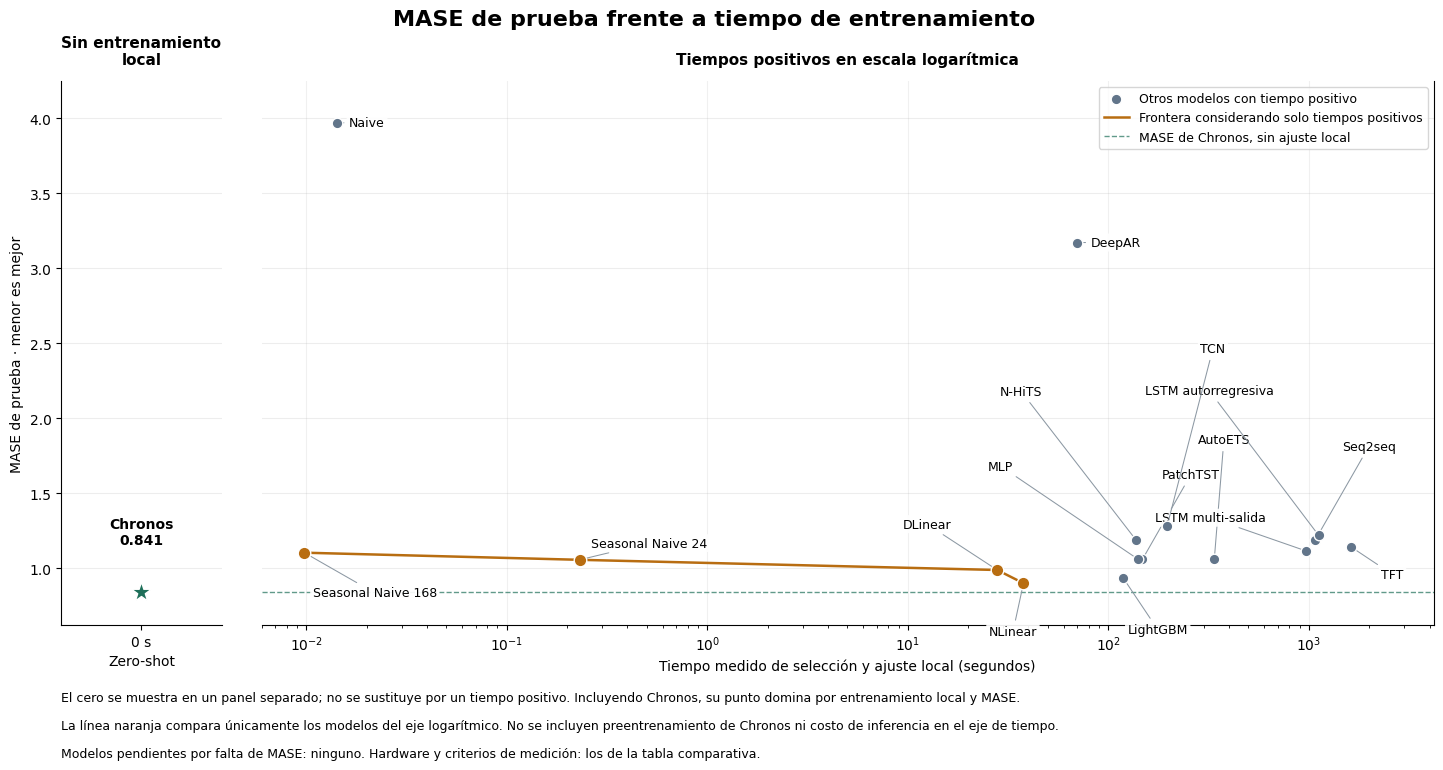

Frontera entre los modelos con tiempo positivo, sin elegir nuevas configuraciones:


,Modelo,training_seconds,MASE_H24
8,Seasonal Naive 168,0.00980,1.10246
4,Seasonal Naive 24,0.23106,1.05499
3,DLinear,27.93484,0.98706
1,NLinear,37.77010,0.89873


Incluyendo el entrenamiento local cero de Chronos:


,Modelo,training_seconds,MASE_H24
0,Chronos-Bolt Mini,0.0,0.84113


Esta comparación describe las configuraciones ya fijadas; no se utilizan los errores de prueba para ajustarlas.


In [11]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display


pareto_directory = Path("data/processed/comparison_6")
pareto_data = pd.read_csv(pareto_directory / "model_comparison_table.csv")
pareto_data["training_seconds"] = pd.to_numeric(pareto_data["Entrenamiento_s"], errors="coerce")
zero_shot_mask = pareto_data["Modelo"].eq("Chronos-Bolt Mini")
pareto_data.loc[zero_shot_mask, "training_seconds"] = 0.0
pending_pareto_models = pareto_data.loc[pareto_data["MASE_H24"].isna(), "Modelo"].tolist()
pareto_data = pareto_data.dropna(subset=["training_seconds", "MASE_H24"]).copy()
assert np.isfinite(pareto_data[["training_seconds", "MASE_H24"]]).all().all()
assert (pareto_data["training_seconds"] >= 0).all()


def pareto_frontier_flags(comparison_data):
    frontier_flags = []
    for row in comparison_data.itertuples():
        no_more_cost = comparison_data["training_seconds"] <= row.training_seconds
        no_more_error = comparison_data["MASE_H24"] <= row.MASE_H24
        strictly_better = (
            (comparison_data["training_seconds"] < row.training_seconds)
            | (comparison_data["MASE_H24"] < row.MASE_H24)
        )
        frontier_flags.append(not (no_more_cost & no_more_error & strictly_better).any())
    return pd.Series(frontier_flags, index=comparison_data.index, dtype=bool)


pareto_data["frontier_including_zero_shot"] = pareto_frontier_flags(pareto_data)
positive_training_data = pareto_data.loc[pareto_data["training_seconds"] > 0].copy()
positive_training_data["frontier_positive_cost"] = pareto_frontier_flags(positive_training_data)
positive_frontier = positive_training_data.loc[positive_training_data["frontier_positive_cost"]].sort_values("training_seconds")
zero_training_data = pareto_data.loc[pareto_data["training_seconds"] == 0].copy()

figure, (zero_axis, cost_axis) = plt.subplots(
    1, 2, figsize=(15, 8), sharey=True,
    gridspec_kw={"width_ratios": [1.3, 9.5], "wspace": 0.06},
)
figure.subplots_adjust(left=0.065, right=0.98, top=0.88, bottom=0.20)
figure.suptitle("MASE de prueba frente a tiempo de entrenamiento", fontsize=16, fontweight="bold", y=0.97)
zero_axis.set_title("Sin entrenamiento\nlocal", fontsize=11, fontweight="bold", pad=12)
cost_axis.set_title("Tiempos positivos en escala logarítmica", fontsize=11, fontweight="bold", pad=12)
cost_axis.set_xscale("log")
cost_axis.set_xlim(0.006, 4200)
cost_axis.set_ylim(0.62, 4.25)
cost_axis.set_xlabel("Tiempo medido de selección y ajuste local (segundos)")
zero_axis.set_ylabel("MASE de prueba · menor es mejor")
zero_axis.set_xlim(-0.7, 0.7)
zero_axis.set_xticks([0], ["0 s"])
zero_axis.set_xlabel("Zero-shot")
for plot_axis in [zero_axis, cost_axis]:
    plot_axis.grid(axis="y", alpha=0.22)
    plot_axis.spines["top"].set_visible(False)
cost_axis.grid(axis="x", which="major", alpha=0.18)
cost_axis.tick_params(axis="y", left=False)
cost_axis.spines["left"].set_visible(False)
zero_axis.spines["right"].set_visible(False)

dominated_models = positive_training_data.loc[~positive_training_data["frontier_positive_cost"]]
cost_axis.scatter(dominated_models["training_seconds"], dominated_models["MASE_H24"], s=58, color="#62758A", edgecolors="white", zorder=4, label="Otros modelos con tiempo positivo")
cost_axis.plot(positive_frontier["training_seconds"], positive_frontier["MASE_H24"], color="#B86D11", linewidth=1.8, zorder=3, label="Frontera considerando solo tiempos positivos")
cost_axis.scatter(positive_frontier["training_seconds"], positive_frontier["MASE_H24"], s=82, color="#B86D11", edgecolors="white", zorder=5)

label_offsets = {
    "Seasonal Naive 168": (6, -29), "Naive": (9, 0), "Seasonal Naive 24": (8, 12),
    "DLinear": (-68, 33), "NLinear": (-25, -35), "LightGBM": (3, -37),
    "MLP": (-108, 67), "PatchTST": (14, 61), "N-HiTS": (-98, 107), "TCN": (24, 128),
    "DeepAR": (10, 0), "LSTM multi-salida": (-109, 24), "TFT": (22, -20),
    "Seq2seq": (19, 67), "LSTM autorregresiva": (-125, 104), "AutoETS": (-12, 86),
}
for model in positive_training_data.itertuples():
    offset = label_offsets[model.Modelo]
    cost_axis.annotate(
        model.Modelo, xy=(model.training_seconds, model.MASE_H24), xytext=offset,
        textcoords="offset points", fontsize=9, va="center", ha="left",
        arrowprops={"arrowstyle": "-", "color": "#8C98A3", "linewidth": 0.75},
        bbox={"boxstyle": "round,pad=0.2", "facecolor": "white", "edgecolor": "none", "alpha": 0.92},
    )
for model in zero_training_data.itertuples():
    zero_axis.scatter([0], [model.MASE_H24], marker="*", s=230, color="#1E6F59", edgecolors="white", zorder=6)
    zero_axis.annotate("Chronos\n0.841", xy=(0, model.MASE_H24), xytext=(0, 32), textcoords="offset points", ha="center", va="bottom", fontsize=10, fontweight="bold")
    cost_axis.axhline(model.MASE_H24, color="#1E6F59", linewidth=1, linestyle="--", alpha=0.7, label="MASE de Chronos, sin ajuste local")

cost_axis.legend(loc="upper right", fontsize=9, frameon=True)
missing_text = ", ".join(pending_pareto_models) if pending_pareto_models else "ninguno"
figure.text(
    0.065, 0.105,
    "El cero se muestra en un panel separado; no se sustituye por un tiempo positivo. "
    "Incluyendo Chronos, su punto domina por entrenamiento local y MASE.", fontsize=9,
)
figure.text(
    0.065, 0.070,
    "La línea naranja compara únicamente los modelos del eje logarítmico. "
    "No se incluyen preentrenamiento de Chronos ni costo de inferencia en el eje de tiempo.", fontsize=9,
)
figure.text(0.065, 0.035, f"Modelos pendientes por falta de MASE: {missing_text}. Hardware y criterios de medición: los de la tabla comparativa.", fontsize=9)
figure.savefig(pareto_directory / "mase_vs_training_time_pareto.png", dpi=180, bbox_inches="tight")
figure.savefig(pareto_directory / "mase_vs_training_time_pareto.svg", bbox_inches="tight")
plt.show()

pareto_data["frontier_positive_cost"] = pd.Series(pd.NA, index=pareto_data.index, dtype="boolean")
pareto_data.loc[positive_training_data.index, "frontier_positive_cost"] = positive_training_data["frontier_positive_cost"]
pareto_data[["Modelo", "training_seconds", "MASE_H24", "frontier_including_zero_shot", "frontier_positive_cost"]].to_csv(pareto_directory / "pareto_training_time_data.csv", index=False)
print("Frontera entre los modelos con tiempo positivo, sin elegir nuevas configuraciones:")
display(positive_frontier[["Modelo", "training_seconds", "MASE_H24"]].round(5))
print("Incluyendo el entrenamiento local cero de Chronos:")
display(pareto_data.loc[pareto_data["frontier_including_zero_shot"], ["Modelo", "training_seconds", "MASE_H24"]].round(5))
print("Esta comparación describe las configuraciones ya fijadas; no se utilizan los errores de prueba para ajustarlas.")


### **MAE por paso del horizonte**

Se compara el error absoluto medio de cada modelo para los pasos del 1 al 24. Cada paso reúne las predicciones de los mismos cien clientes y 92 días de prueba, y se expresa en kWh. Las curvas corresponden a las configuraciones ya fijadas en la tabla comparativa.

- **Datos:** Se reutilizan los pronósticos guardados. Para AutoETS se recupera la tabla original de MAE por horizonte del notebook, con cuatro decimales, ya que estos valores sí están disponibles aunque falte su MASE. No se vuelve a entrenar ningún modelo.
- **Visualización:** La vista superior incluye los diecisiete modelos. La inferior amplía los otros quince para distinguir mejor sus curvas, ya que los errores de Naive y DeepAR son más grandes. Ambas vistas pertenecen a la misma comparación por horizonte.
- **Interpretación:** Todos los pronósticos se emiten a las 00:00, por lo que cada paso también corresponde a una hora específica del día. Los cambios en las curvas pueden reflejar tanto la dificultad de predecir más lejos como el patrón de consumo de esa hora. Una subida por sí sola no demuestra acumulación de error autorregresivo.

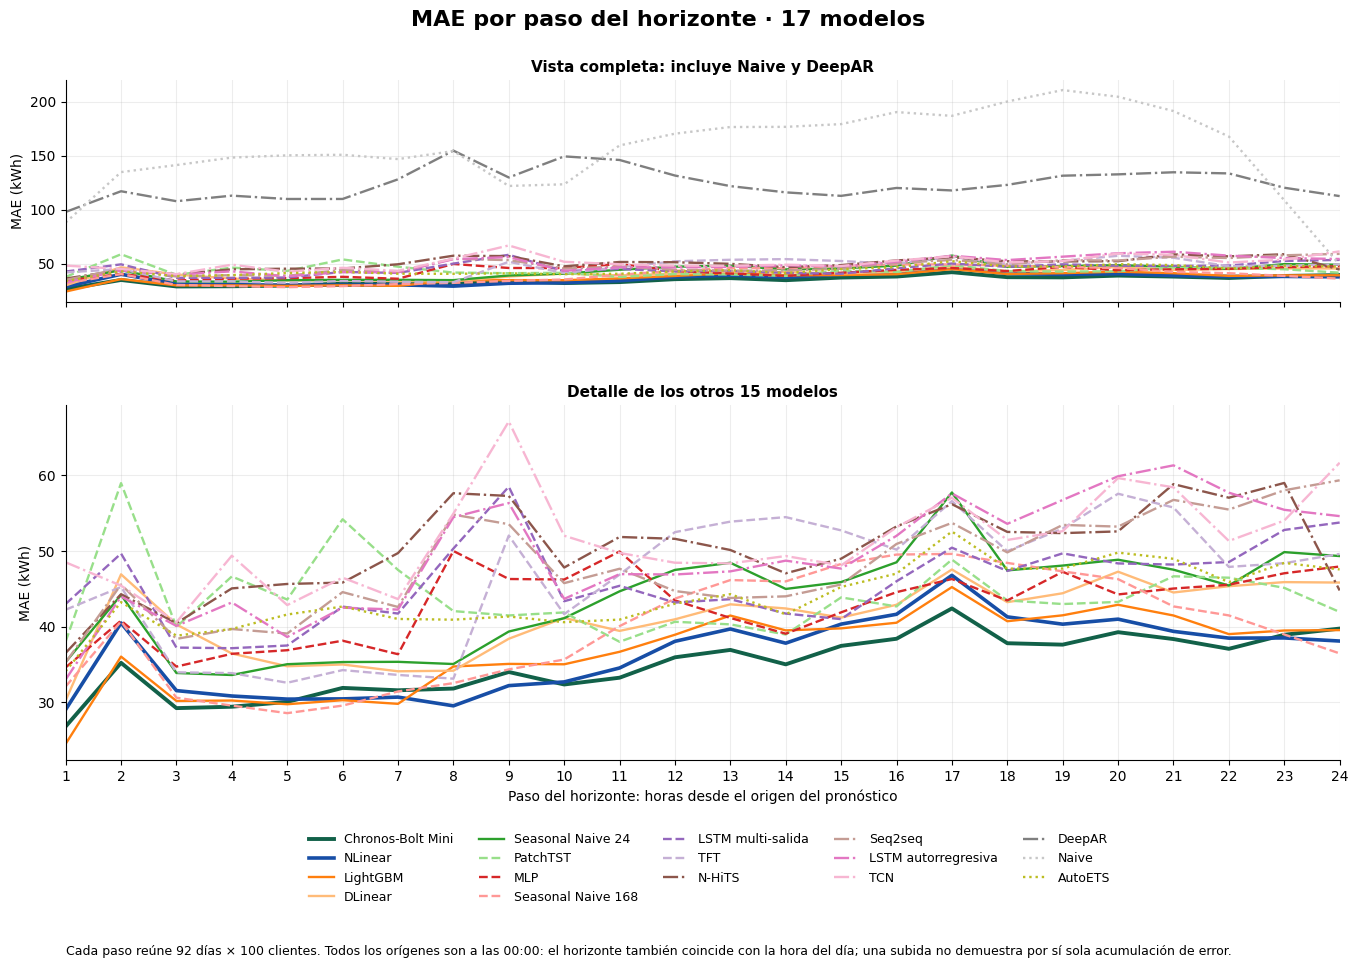

,MAE_hora_1,MAE_hora_24,Cambio_hora_1_a_24,MAE_promedio,Paso_con_mayor_MAE,Mayor_MAE
Modelo,,,,,,
Chronos-Bolt Mini,26.8151,39.7557,12.9407,35.0368,17,42.4209
NLinear,29.0500,38.1114,9.0614,36.4220,17,46.8008
LightGBM,24.5134,39.5563,15.0429,36.7769,17,45.2452
DLinear,30.2507,45.8425,15.5918,41.0716,17,47.5687
Seasonal Naive 24,35.3302,49.3470,14.0168,43.4506,17,57.7529
PatchTST,38.0473,41.9568,3.9095,44.0780,2,58.9881
MLP,34.6209,47.9646,13.3437,42.8213,8,50.0192
Seasonal Naive 168,32.0959,36.4749,4.3790,39.5971,17,49.6345
LSTM multi-salida,43.0123,53.7777,10.7654,45.8975,9,58.5142


AutoETS se recuperó de su tabla original, con cuatro decimales. Los otros modelos utilizan sus pronósticos guardados.
La vista inferior amplía los otros quince modelos; Naive y DeepAR siguen incluidos en la vista completa.
Se mantienen las configuraciones ya fijadas, sin nuevos entrenamientos ni ajustes con prueba.


In [1]:
from pathlib import Path
import json
import xml.etree.ElementTree as ElementTree

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display


horizon_plot_directory = Path("data/processed/comparison_6")
horizon_model_table = pd.read_csv(horizon_plot_directory / "model_comparison_table.csv")
horizon_selected_cases = pd.read_csv("data/processed/experiments_5_2/selected_configurations.csv")
horizon_file_registry = {
    "Naive": horizon_plot_directory / "recovered_forecasts/naive_test_forecasts.csv.gz",
    "Seasonal Naive 168": horizon_plot_directory / "recovered_forecasts/seasonal naive 168_test_forecasts.csv.gz",
    "MLP": horizon_plot_directory / "recovered_forecasts/mlp_test_forecasts.csv.gz",
    "NLinear": horizon_plot_directory / "recovered_forecasts/nlinear_test_forecasts.csv.gz",
    "LSTM autorregresiva": Path("data/processed/lstm_autoregressive_test_forecasts.csv"),
    "Seq2seq": Path("data/processed/seq2seq_test_forecasts.csv"),
    "N-HiTS": Path("data/processed/nhits_test_forecasts.csv"),
    "TCN": Path("data/processed/tcn_test_forecasts.csv"),
    "TFT": Path("data/processed/tft_test_forecasts.csv"),
    "DeepAR": Path("data/processed/deepar_test_forecasts.csv"),
    "Chronos-Bolt Mini": Path("data/processed/chronos_bolt_test_forecasts.csv"),
}
for display_name, experiment_name in [
    ("Seasonal Naive 24", "SeasonalNaive"), ("DLinear", "DLinear"),
    ("LightGBM", "LightGBM"), ("LSTM multi-salida", "LSTM"), ("PatchTST", "PatchTST"),
]:
    case_name = horizon_selected_cases.loc[horizon_selected_cases["model"] == experiment_name, "case"].item()
    horizon_file_registry[display_name] = Path("data/processed/experiments_5_2") / case_name / "test_forecasts.csv.gz"


def recover_autoets_horizon_mae():
    notebook_snapshot = json.loads(Path("Laboratorio_9_Series_de_Tiempo.ipynb").read_text())
    source_cell = next(cell for cell in notebook_snapshot["cells"] if cell["id"] == "codigo-autoets")
    for output in source_cell.get("outputs", []):
        html = output.get("data", {}).get("text/html", "")
        html = "".join(html) if isinstance(html, list) else html
        if "horizon_step" not in html or "MAE_kWh" not in html:
            continue
        table_html = html[html.index("<table"):html.index("</table>") + len("</table>")]
        table_root = ElementTree.fromstring(table_html)
        header_cells = table_root.find("thead/tr")
        column_names = ["".join(header.itertext()).strip() for header in header_cells]
        mae_position = column_names.index("MAE_kWh")
        horizon_values = {}
        for table_row in table_root.findall("tbody/tr"):
            values = ["".join(table_cell.itertext()).strip() for table_cell in table_row]
            horizon_values[int(values[0])] = float(values[mae_position])
        result = pd.Series(horizon_values, name="AutoETS").sort_index()
        assert result.index.tolist() == list(range(1, 25))
        return result
    raise ValueError("No se encontró la tabla de MAE por horizonte de AutoETS.")


horizon_mae_curves = {}
horizon_source_rows = []
for model_name in horizon_model_table["Modelo"]:
    if model_name == "AutoETS":
        horizon_mae_curves[model_name] = recover_autoets_horizon_mae()
        horizon_source_rows.append({"model": model_name, "source": "Tabla original por horizonte del notebook", "precision": "4 decimales"})
        continue
    forecasts_path = horizon_file_registry[model_name]
    forecasts = pd.read_csv(
        forecasts_path, usecols=["unique_id", "horizon_step", "y", "y_hat"], float_precision="round_trip"
    )
    assert len(forecasts) == 220800 and forecasts["unique_id"].nunique() == 100
    assert forecasts.groupby("horizon_step").size().eq(9200).all()
    absolute_error = (forecasts["y"] - forecasts["y_hat"]).abs()
    model_curve = absolute_error.groupby(forecasts["horizon_step"]).mean().sort_index()
    assert model_curve.index.tolist() == list(range(1, 25))
    original_mae = horizon_model_table.loc[horizon_model_table["Modelo"] == model_name, "MAE_kWh"].item()
    np.testing.assert_allclose(model_curve.mean(), original_mae, atol=0.00011, rtol=0)
    horizon_mae_curves[model_name] = model_curve
    horizon_source_rows.append({"model": model_name, "source": str(forecasts_path), "precision": "Pronósticos guardados"})

horizon_mae_table = pd.DataFrame(horizon_mae_curves).rename_axis("horizon_step")
assert horizon_mae_table.shape == (24, 17)
assert set(horizon_mae_table.columns) == set(horizon_model_table["Modelo"])
assert np.isfinite(horizon_mae_table).all().all()
horizon_mae_table.to_csv(horizon_plot_directory / "all_models_mae_by_horizon.csv")
pd.DataFrame(horizon_source_rows).to_csv(horizon_plot_directory / "horizon_mae_sources.csv", index=False)
horizon_endpoint_summary = pd.DataFrame({
    "MAE_hora_1": horizon_mae_table.loc[1],
    "MAE_hora_24": horizon_mae_table.loc[24],
    "Cambio_hora_1_a_24": horizon_mae_table.loc[24] - horizon_mae_table.loc[1],
    "MAE_promedio": horizon_mae_table.mean(),
    "Paso_con_mayor_MAE": horizon_mae_table.idxmax(),
    "Mayor_MAE": horizon_mae_table.max(),
}).rename_axis("Modelo")
horizon_endpoint_summary.to_csv(horizon_plot_directory / "all_models_horizon_summary.csv")

figure, (full_axis, detail_axis) = plt.subplots(
    2, 1, figsize=(14, 10), sharex=True, gridspec_kw={"height_ratios": [1, 1.6]},
)
figure.subplots_adjust(left=0.07, right=0.98, top=0.90, bottom=0.22, hspace=0.36)
figure.suptitle("MAE por paso del horizonte · 17 modelos", fontsize=16, fontweight="bold", y=0.97)
detail_models = horizon_mae_table.columns.difference(["Naive", "DeepAR"], sort=False)
color_palette = plt.get_cmap("tab20")
line_styles = ["-", "--", "-.", ":"]
for model_position, model_name in enumerate(horizon_mae_table.columns):
    color = color_palette(model_position % 20)
    width = 1.7
    if model_name == "Chronos-Bolt Mini":
        color, width = "#126149", 2.8
    elif model_name == "NLinear":
        color, width = "#174EA6", 2.6
    style = line_styles[(model_position // 5) % len(line_styles)]
    full_axis.plot(horizon_mae_table.index, horizon_mae_table[model_name], color=color, linewidth=width, linestyle=style, label=model_name)
    if model_name in detail_models:
        detail_axis.plot(horizon_mae_table.index, horizon_mae_table[model_name], color=color, linewidth=width, linestyle=style, label=model_name)
full_axis.set_title("Vista completa: incluye Naive y DeepAR", fontsize=11, fontweight="bold")
detail_axis.set_title("Detalle de los otros 15 modelos", fontsize=11, fontweight="bold")
for plot_axis in [full_axis, detail_axis]:
    plot_axis.set_ylabel("MAE (kWh)")
    plot_axis.set_xlim(1, 24)
    plot_axis.set_xticks(range(1, 25))
    plot_axis.grid(alpha=0.22)
    plot_axis.spines["top"].set_visible(False)
    plot_axis.spines["right"].set_visible(False)
detail_axis.set_xlabel("Paso del horizonte: horas desde el origen del pronóstico")
legend_handles, legend_labels = full_axis.get_legend_handles_labels()
figure.legend(legend_handles, legend_labels, ncol=5, loc="lower center", bbox_to_anchor=(0.53, 0.065), frameon=False, fontsize=9)
figure.text(
    0.07, 0.025,
    "Cada paso reúne 92 días × 100 clientes. Todos los orígenes son a las 00:00: "
    "el horizonte también coincide con la hora del día; una subida no demuestra por sí sola acumulación de error.", fontsize=9,
)
figure.savefig(horizon_plot_directory / "all_models_mae_by_horizon.png", dpi=180, bbox_inches="tight")
figure.savefig(horizon_plot_directory / "all_models_mae_by_horizon.svg", bbox_inches="tight")
plt.show()
display(horizon_endpoint_summary.round(4))
print("AutoETS se recuperó de su tabla original, con cuatro decimales. Los otros modelos utilizan sus pronósticos guardados.")
print("La vista inferior amplía los otros quince modelos; Naive y DeepAR siguen incluidos en la vista completa.")
print("Se mantienen las configuraciones ya fijadas, sin nuevos entrenamientos ni ajustes con prueba.")


### **MASE contra meses de historia de entrenamiento**

Se reutilizan los resultados del 5.2 para comparar seasonal naive, LightGBM, DLinear, LSTM multi-salida y PatchTST con 3, 12 y 30 meses de historia anterior a validación. Se mantiene la ventana de 168 horas, horizonte de 24, cien clientes, semilla 123 y las mismas fechas de validación y prueba. Chronos aparece como una línea de referencia fija, ya que no se entrena con esas cantidades de historia.

- **Períodos:** Los meses del eje horizontal terminan en junio de 2014. Después de incorporar julio–septiembre al ajuste final, las historias finales abarcan 6, 15 y 33 meses, respectivamente.
- **Comparación:** El eje vertical muestra MASE de prueba, manteniendo la referencia estacional común del entrenamiento original. Las tres cantidades de historia utilizan los escaladores y configuraciones ya evaluados en el 5.2.
- **Alcance:** Se visualizan los resultados guardados de las quince iteraciones, sin nuevos entrenamientos, nuevas evaluaciones ni selección de configuraciones a partir de prueba.

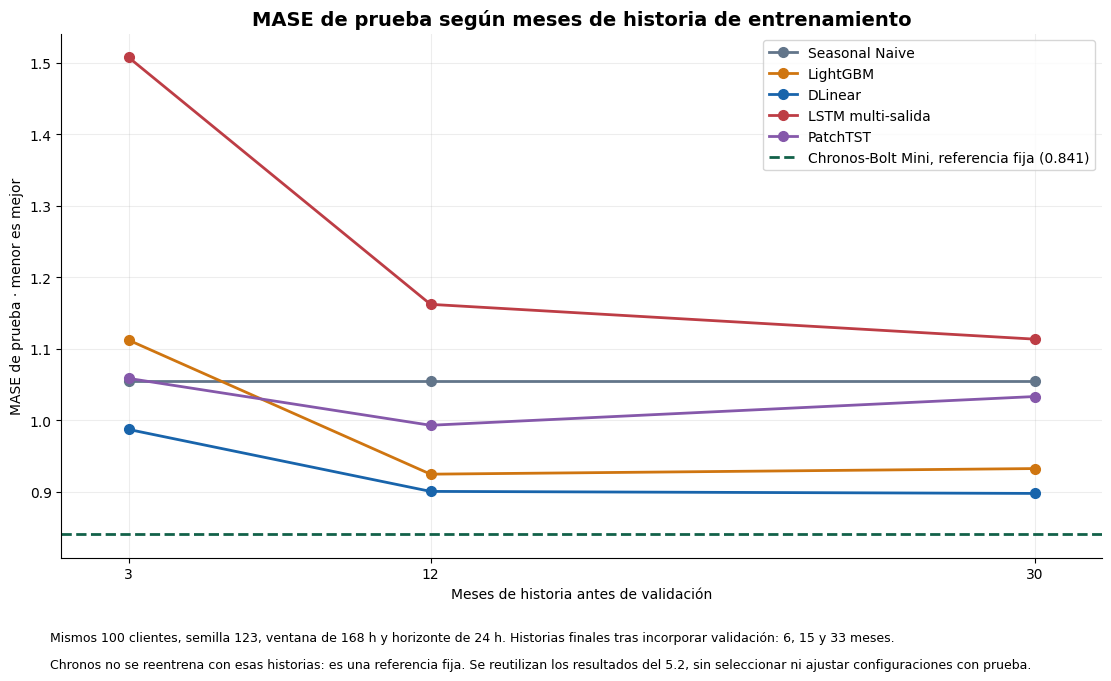

Meses previos a validación,3,12,30
Modelo,,,
Seasonal Naive,1.05499,1.05499,1.05499
LightGBM,1.11205,0.92446,0.93229
DLinear,0.98706,0.90036,0.89752
LSTM multi-salida,1.50761,1.16205,1.11337
PatchTST,1.05847,0.99287,1.03306


Chronos-Bolt Mini: MASE fijo de referencia = 0.84113.
Gráfico construido con las evaluaciones guardadas del 5.2, sin nuevos entrenamientos ni pronósticos.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display


history_plot_directory = Path("data/processed/comparison_6")
history_experiments = pd.read_csv("data/processed/experiments_5_2/final_results.csv")
history_plot_models = ["SeasonalNaive", "LightGBM", "DLinear", "LSTM", "PatchTST"]
history_plot_data = history_experiments.loc[
    history_experiments["model"].isin(history_plot_models) & history_experiments["window"].eq(168)
].copy()
assert len(history_plot_data) == 15
assert not history_plot_data.duplicated(["model", "months"]).any()
for model_name in history_plot_models:
    assert set(history_plot_data.loc[history_plot_data["model"] == model_name, "months"]) == {3, 12, 30}
assert (history_plot_data["final_fit_months"] == history_plot_data["months"] + 3).all()
assert history_plot_data["test_forecast_count"].eq(220800).all()
assert np.isfinite(history_plot_data["test_MASE"]).all()

history_comparison_table = pd.read_csv(history_plot_directory / "model_comparison_table.csv")
chronos_history_reference = history_comparison_table.loc[
    history_comparison_table["Modelo"] == "Chronos-Bolt Mini", "MASE_H24"
].item()
assert np.isfinite(chronos_history_reference)
history_mase_summary = history_plot_data.pivot(index="model", columns="months", values="test_MASE").reindex(history_plot_models)
history_mase_summary = history_mase_summary.rename(index={"SeasonalNaive": "Seasonal Naive", "LSTM": "LSTM multi-salida"})
history_mase_summary.index.name = "Modelo"
history_mase_summary.columns.name = "Meses previos a validación"
history_mase_summary.to_csv(history_plot_directory / "mase_by_training_months.csv")
history_plot_data[["model", "window", "months", "final_fit_months", "test_MASE", "validation_MASE", "case"]].to_csv(
    history_plot_directory / "history_months_plot_data.csv", index=False
)

figure, axis = plt.subplots(figsize=(11, 6), layout="constrained")
model_colors = {"SeasonalNaive": "#62758A", "LightGBM": "#CF7510", "DLinear": "#1864AB", "LSTM": "#BD3D45", "PatchTST": "#8558AA"}
model_labels = {"SeasonalNaive": "Seasonal Naive", "LSTM": "LSTM multi-salida"}
for model_name in history_plot_models:
    model_data = history_plot_data.loc[history_plot_data["model"] == model_name].sort_values("months")
    axis.plot(
        model_data["months"], model_data["test_MASE"], marker="o", markersize=7,
        linewidth=2, color=model_colors[model_name], label=model_labels.get(model_name, model_name),
    )
axis.axhline(
    chronos_history_reference, color="#126149", linestyle="--", linewidth=2,
    label=f"Chronos-Bolt Mini, referencia fija ({chronos_history_reference:.3f})",
)
axis.set_title("MASE de prueba según meses de historia de entrenamiento", fontsize=14, fontweight="bold")
axis.set_xlabel("Meses de historia antes de validación")
axis.set_ylabel("MASE de prueba · menor es mejor")
axis.set_xticks([3, 12, 30])
axis.set_xlim(1, 32)
axis.grid(alpha=0.22)
axis.spines["top"].set_visible(False)
axis.spines["right"].set_visible(False)
axis.legend(loc="upper right", fontsize=10)
figure.get_layout_engine().set(rect=(0, 0.14, 1, 1))
figure.text(
    0.04, 0.08,
    "Mismos 100 clientes, semilla 123, ventana de 168 h y horizonte de 24 h. "
    "Historias finales tras incorporar validación: 6, 15 y 33 meses.", fontsize=9,
)
figure.text(
    0.04, 0.035,
    "Chronos no se reentrena con esas historias: es una referencia fija. "
    "Se reutilizan los resultados del 5.2, sin seleccionar ni ajustar configuraciones con prueba.", fontsize=9,
)
figure.savefig(history_plot_directory / "mase_vs_training_months.png", dpi=180, bbox_inches="tight")
figure.savefig(history_plot_directory / "mase_vs_training_months.svg", bbox_inches="tight")
plt.show()
display(history_mase_summary.round(5))
print(f"Chronos-Bolt Mini: MASE fijo de referencia = {chronos_history_reference:.5f}.")
print("Gráfico construido con las evaluaciones guardadas del 5.2, sin nuevos entrenamientos ni pronósticos.")
